# LABELLED DATA EXPERIMENT
How much labelled data is required to adapt SAM2 to a new agricultural domain?

In [9]:
import os
import sys
import json
import random
import math
import copy
import time
import csv
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    ConcatDataset,
    WeightedRandomSampler,
)

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0


In [10]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

device = DEVICE

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [11]:
# ============================================================
# LABELLED DATA EXPERIMENT CONFIGURATION
# ============================================================

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

NUM_EPOCHS = 10

BATCH_SIZE = 1

NUM_WORKERS = 0

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-4

MASK_THRESHOLD = 0.5

BOX_JITTER_FRACTION = 0.05

EARLY_STOPPING_PATIENCE = 3

# Requested labelled-data amounts
LABEL_COUNTS = [5, 10, 25, 50, 100]

# Dataset domains
TARGET_DATASETS = [
    "ReLeaf",
    "WeedsGalore",
    "EWI1S"
]

print("Labelled image counts:", LABEL_COUNTS)
print("Target datasets:", TARGET_DATASETS)
print("Epochs:", NUM_EPOCHS)

Labelled image counts: [5, 10, 25, 50, 100]
Target datasets: ['ReLeaf', 'WeedsGalore', 'EWI1S']
Epochs: 10


In [12]:
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

DOMAIN_FT_ROOT = (
    PROJECT_ROOT
    / "sam2_domain_finetuning"
)

VEGANN_SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

print("Project root:", PROJECT_ROOT)
print("VegAnn checkpoint:", VEGANN_SAM2_CHECKPOINT)

print(
    "Checkpoint exists:",
    VEGANN_SAM2_CHECKPOINT.exists()
)

Project root: /home/zahranadeem/thesis
VegAnn checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Checkpoint exists: True


In [13]:
# ============================================================
# Existing VegAnn SAM2 checkpoint
# ============================================================

VEGANN_SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)


# ============================================================
# ReLeaf
# ============================================================

RELEAF_ROOT = (
    PROJECT_ROOT / "CropAndWeedAndLeaf"
)

RELEAF_REPO = (
    PROJECT_ROOT / "releaf"
)

RELEAF_IMAGES_DIR = (
    RELEAF_ROOT / "images"
)

RELEAF_LABELS_DIR = (
    RELEAF_ROOT / "labels"
)

RELEAF_TEST_DIR = (
    RELEAF_REPO
    / "data"
    / "CWL"
    / "test"
)


# ============================================================
# WeedsGalore
# ============================================================

WEEDSGALORE_ROOT = (
    PROJECT_ROOT / "WeedsGalore_dataset"
)

WEEDS_IMAGE_DIR = (
    WEEDSGALORE_ROOT / "data"
)

WEEDS_MASK_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)


# ============================================================
# EWI1S
# ============================================================

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)


# Search recursively because your extracted archive has
# nested "images/images" and "masks/masks" directories.

def find_nested_dataset_dir(
    root,
    dirname,
    extension=".png"
):
    candidates = []

    for p in root.rglob(dirname):
        if not p.is_dir():
            continue

        files = [
            x for x in p.iterdir()
            if x.is_file()
            and x.suffix.lower() == extension.lower()
        ]

        if len(files) > 0:
            candidates.append(
                (len(files), p)
            )

    if not candidates:
        return None

    candidates.sort(
        reverse=True,
        key=lambda x: x[0]
    )

    return candidates[0][1]


EWIS1_IMAGE_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "images",
    ".png"
)

EWIS1_MASK_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "masks",
    ".png"
)


# ============================================================
# Print paths
# ============================================================

print("VegAnn SAM2 checkpoint:")
print(VEGANN_SAM2_CHECKPOINT)

print("\nReLeaf images:")
print(RELEAF_IMAGES_DIR)

print("ReLeaf labels:")
print(RELEAF_LABELS_DIR)

print("ReLeaf test:")
print(RELEAF_TEST_DIR)

print("\nWeedsGalore images:")
print(WEEDS_IMAGE_DIR)

print("WeedsGalore masks:")
print(WEEDS_MASK_DIR)

print("\nEWI1S images:")
print(EWIS1_IMAGE_DIR)

print("EWI1S masks:")
print(EWIS1_MASK_DIR)

VegAnn SAM2 checkpoint:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt

ReLeaf images:
/home/zahranadeem/thesis/CropAndWeedAndLeaf/images
ReLeaf labels:
/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels
ReLeaf test:
/home/zahranadeem/thesis/releaf/data/CWL/test

WeedsGalore images:
/home/zahranadeem/thesis/WeedsGalore_dataset/data
WeedsGalore masks:
/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic

EWI1S images:
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWI1S masks:
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks


In [14]:
paths_to_check = {
    "VegAnn SAM2 checkpoint": VEGANN_SAM2_CHECKPOINT,
    "ReLeaf images": RELEAF_IMAGES_DIR,
    "ReLeaf labels": RELEAF_LABELS_DIR,
    "WeedsGalore images": WEEDS_IMAGE_DIR,
    "WeedsGalore masks": WEEDS_MASK_DIR,
    "EWI1S images": EWIS1_IMAGE_DIR,
    "EWI1S masks": EWIS1_MASK_DIR,
}

for name, path in paths_to_check.items():
    print(
        f"{name:30s}: "
        f"{'OK' if path is not None and path.exists() else 'MISSING'}"
    )

if not VEGANN_SAM2_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Existing VegAnn SAM2 checkpoint not found:\n"
        f"{VEGANN_SAM2_CHECKPOINT}"
    )

VegAnn SAM2 checkpoint        : OK
ReLeaf images                 : OK
ReLeaf labels                 : OK
WeedsGalore images            : OK
WeedsGalore masks             : OK
EWI1S images                  : OK
EWI1S masks                   : OK


In [15]:
#inspecting external datasets 
def count_files(directory, extensions):
    if directory is None or not directory.exists():
        return 0

    return sum(
        1
        for p in directory.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
    )


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp"
}

MASK_EXTENSIONS = IMAGE_EXTENSIONS


print(
    "ReLeaf images:",
    count_files(RELEAF_IMAGES_DIR, IMAGE_EXTENSIONS)
)

print(
    "ReLeaf labels:",
    count_files(RELEAF_LABELS_DIR, {".txt"})
)

print(
    "WeedsGalore images:",
    count_files(WEEDS_IMAGE_DIR, IMAGE_EXTENSIONS)
)

print(
    "WeedsGalore masks:",
    count_files(WEEDS_MASK_DIR, MASK_EXTENSIONS)
)

print(
    "EWI1S images:",
    count_files(EWIS1_IMAGE_DIR, IMAGE_EXTENSIONS)
)

print(
    "EWI1S masks:",
    count_files(EWIS1_MASK_DIR, MASK_EXTENSIONS)
)

ReLeaf images: 345
ReLeaf labels: 345
WeedsGalore images: 156
WeedsGalore masks: 156
EWI1S images: 88
EWI1S masks: 88


In [16]:
#load vegann and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Total images:", len(vegann["train"]))

vegann_split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=SEED
)

vegann_train_hf = vegann_split["train"]
vegann_val_hf = vegann_split["test"]

print(
    "VegAnn training:",
    len(vegann_train_hf)
)

print(
    "VegAnn validation:",
    len(vegann_val_hf)
)

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Total images: 3775
VegAnn training: 3020
VegAnn validation: 755


In [17]:
def binary_mask_from_array(mask):
    """
    Convert any mask-like object into uint8 binary mask.
    Any non-zero pixel is foreground.
    """
    
    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    mask = np.asarray(mask)

    # Remove unnecessary channel dimensions
    while mask.ndim > 2:
        mask = mask[..., 0]

    binary = (
        mask > 0
    ).astype(np.uint8)

    return binary


def mask_to_box(mask):
    """
    Compute [x1, y1, x2, y2] from a binary mask.
    Returns None for empty masks.
    """

    mask = binary_mask_from_array(mask)

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    x1 = int(xs.min())
    y1 = int(ys.min())

    x2 = int(xs.max())
    y2 = int(ys.max())

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.int32
    )

In [18]:
#BOX PERTURBATION 
def jitter_box(
    box,
    image_width,
    image_height,
    fraction=BOX_JITTER_FRACTION
):
    """
    Randomly shift/expand/shrink a GT box slightly.
    Used only during training.
    """

    x1, y1, x2, y2 = [
        int(v) for v in box
    ]

    box_width = max(
        1,
        x2 - x1
    )

    box_height = max(
        1,
        y2 - y1
    )

    max_dx = int(
        box_width * fraction
    )

    max_dy = int(
        box_height * fraction
    )

    dx1 = random.randint(
        -max_dx,
        max_dx
    )

    dy1 = random.randint(
        -max_dy,
        max_dy
    )

    dx2 = random.randint(
        -max_dx,
        max_dx
    )

    dy2 = random.randint(
        -max_dy,
        max_dy
    )

    x1 = x1 + dx1
    y1 = y1 + dy1
    x2 = x2 + dx2
    y2 = y2 + dy2

    x1 = max(
        0,
        min(x1, image_width - 1)
    )

    y1 = max(
        0,
        min(y1, image_height - 1)
    )

    x2 = max(
        x1 + 1,
        min(x2, image_width - 1)
    )

    y2 = max(
        y1 + 1,
        min(y2, image_height - 1)
    )

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.int32
    )

In [19]:
#ReLeaf Laoder 
def find_matching_mask_or_label(
    directory,
    image_path
):
    """
    Find a file with the same stem.
    """

    candidates = []

    for suffix in [
        ".txt",
        ".png",
        ".jpg",
        ".jpeg",
        ".tif",
        ".tiff"
    ]:
        candidate = (
            directory
            / f"{image_path.stem}{suffix}"
        )

        if candidate.exists():
            candidates.append(candidate)

    return candidates[0] if candidates else None


def load_releaf_image_mask(
    image_path
):
    """
    ReLeaf:
    YOLO segmentation polygons -> binary vegetation mask.
    """

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        return image, mask

    with open(
        label_path,
        "r"
    ) as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) < 7:
            continue

        # Ignore first value = class id
        coords = [
            float(v)
            for v in values[1:]
        ]

        if len(coords) < 6:
            continue

        points = []

        for i in range(
            0,
            len(coords),
            2
        ):
            x = int(
                coords[i] * width
            )

            y = int(
                coords[i + 1] * height
            )

            points.append(
                [x, y]
            )

        points = np.asarray(
            points,
            dtype=np.int32
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    return image, mask

In [20]:
releaf_pairs = []

releaf_image_files = sorted(
    [
        p
        for p in RELEAF_IMAGES_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in releaf_image_files:

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():

        releaf_pairs.append(
            {
                "image_path": image_path,
                "label_path": label_path,
                "dataset": "ReLeaf"
            }
        )

print(
    "ReLeaf image-label pairs:",
    len(releaf_pairs)
)

print(
    releaf_pairs[:3]
)

ReLeaf image-label pairs: 345
[{'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0041-0002-002.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0041-0002-002.txt'), 'dataset': 'ReLeaf'}, {'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0045-0011-012.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0045-0011-012.txt'), 'dataset': 'ReLeaf'}, {'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0048-0002-026.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0048-0002-026.txt'), 'dataset': 'ReLeaf'}]


In [21]:
releaf_official_test_names = set()

if RELEAF_TEST_DIR.exists():

    for p in RELEAF_TEST_DIR.iterdir():

        if (
            p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            releaf_official_test_names.add(
                p.name
            )

print(
    "Existing ReLeaf test images:",
    len(releaf_official_test_names)
)

if len(releaf_official_test_names) > 0:
    print(
        list(releaf_official_test_names)[:10]
    )

Existing ReLeaf test images: 345
['vwg-0807-0007-001.jpg', 'vwg-0929-0009-004.jpg', 'ave-0540-0089-006.jpg', 'vwg-1308-0007-015.jpg', 'vwg-0804-0003-018.jpg', 'ave-0104-0013-030.jpg', 'ave-0131-0008-003.jpg', 'ave-0586-0010-009.jpg', 'ave-0068-0001-034.jpg', 'ave-0586-0019-004.jpg']


In [22]:

releaf_official_test_names = {
    "image1.jpg", 
    "image2.jpg"
} 

from pathlib import Path

releaf_official_test_names = {
    Path(name).name for name in releaf_official_test_names
}



In [23]:
#split Releadf 
def split_releaf_pairs(
    pairs,
    seed=42
):
    """  deterministic 80/10/10 split.
    """

    rng = random.Random(seed)

    pairs = list(pairs)

    official_test = []
    remaining = []

    for item in pairs:

        if (
            item["image_path"].name
            in releaf_official_test_names
        ):
            official_test.append(item)
        else:
            remaining.append(item)

    rng.shuffle(remaining)

    if len(official_test) > 0:

        split_point = int(
            0.90 * len(remaining)
        )

        train_pairs = (
            remaining[:split_point]
        )

        val_pairs = (
            remaining[split_point:]
        )

        test_pairs = official_test

        split_mode = (
            "Existing ReLeaf test preserved"
        )

    else:

        n = len(pairs)

        n_train = int(
            0.80 * n
        )

        n_val = int(
            0.10 * n
        )

        train_pairs = pairs[
            :n_train
        ]

        val_pairs = pairs[
            n_train:n_train + n_val
        ]

        test_pairs = pairs[
            n_train + n_val:
        ]

        split_mode = (
            "New deterministic 80/10/10 split"
        )

    return (
        train_pairs,
        val_pairs,
        test_pairs,
        split_mode
    )


releaf_train_pairs, releaf_val_pairs, releaf_test_pairs, releaf_split_mode = (
    split_releaf_pairs(
        releaf_pairs,
        seed=SEED
    )
)

print("ReLeaf split mode:")
print(releaf_split_mode)

print("\nTrain:", len(releaf_train_pairs))
print("Val  :", len(releaf_val_pairs))
print("Test :", len(releaf_test_pairs))

ReLeaf split mode:
New deterministic 80/10/10 split

Train: 276
Val  : 34
Test : 35


In [24]:
# ============================================================
# LABELLED-DATA EXPERIMENT
# Create fixed-size subsets from the ReLeaf TRAINING pool
# ============================================================

LABELLED_SIZES = [5, 10, 25, 50, 100]

def create_labelled_subsets(
    train_pairs,
    sizes=LABELLED_SIZES,
    seed=42
):
    """
    Create deterministic labelled-data subsets.

    All subsets are sampled from the SAME training pool.
    Validation and test sets remain completely unchanged.
    """

    rng = random.Random(seed)

    train_pairs = list(train_pairs)

    # Shuffle once so that subsets are nested:
    # 5 ⊂ 10 ⊂ 25 ⊂ 50 ⊂ 100
    shuffled_pairs = train_pairs.copy()
    rng.shuffle(shuffled_pairs)

    subsets = {}

    for size in sizes:

        if size > len(shuffled_pairs):
            print(
                f"WARNING: Requested {size} images, "
                f"but only {len(shuffled_pairs)} training images available."
            )
            continue

        subsets[size] = shuffled_pairs[:size]

    return subsets


releaf_labelled_subsets = create_labelled_subsets(
    releaf_train_pairs,
    sizes=LABELLED_SIZES,
    seed=SEED
)


print("=" * 60)
print("ReLeaf Labelled-Data Subsets")
print("=" * 60)

for size, subset in releaf_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

print()
print("Validation images:", len(releaf_val_pairs))
print("Test images:", len(releaf_test_pairs))

ReLeaf Labelled-Data Subsets
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images
100 labelled images -> 100 training images

Validation images: 34
Test images: 35


In [25]:
#WeedsGalore pair builder 
def find_mask_for_stem(
    mask_dir,
    stem
):
    """
    Search for a matching mask regardless of extension.
    """

    matches = list(
        mask_dir.glob(
            f"{stem}.*"
        )
    )

    matches = [
        p for p in matches
        if p.suffix.lower()
        in MASK_EXTENSIONS
    ]

    if matches:
        return matches[0]

    return None


weedsgalore_pairs = []

weed_image_files = sorted(
    [
        p
        for p in WEEDS_IMAGE_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in weed_image_files:

    mask_path = find_mask_for_stem(
        WEEDS_MASK_DIR,
        image_path.stem
    )

    if mask_path is not None:

        weedsgalore_pairs.append(
            {
                "image_path": image_path,
                "mask_path": mask_path,
                "dataset": "WeedsGalore"
            }
        )

print(
    "WeedsGalore matched pairs:",
    len(weedsgalore_pairs)
)

print(
    weedsgalore_pairs[:3]
)

WeedsGalore matched pairs: 156
[{'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0109.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0109.png'), 'dataset': 'WeedsGalore'}, {'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0114.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0114.png'), 'dataset': 'WeedsGalore'}, {'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0119.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0119.png'), 'dataset': 'WeedsGalore'}]


In [26]:
#WeedsGalore loader + check mask values 
def load_weedsgalore_image_mask(
    item
):
    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask = Image.open(
        item["mask_path"]
    )

    mask = binary_mask_from_array(
        mask
    )

    return image, mask


# Inspect a sample
image, mask = load_weedsgalore_image_mask(
    weedsgalore_pairs[0]
)

print("Image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))
print("Foreground pixels:", int(mask.sum()))

Image size: (600, 600)
Mask shape: (600, 600)
Mask values: [0 1]
Foreground pixels: 975


In [27]:
#EWIS1 pairs 
ewis1_pairs = []

ewis1_image_files = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

for image_path in ewis1_image_files:

    mask_path = (
        EWIS1_MASK_DIR
        / image_path.name
    )

    if mask_path.exists():

        ewis1_pairs.append(
            {
                "image_path": image_path,
                "mask_path": mask_path,
                "dataset": "EWI1S"
            }
        )

print(
    "EWI1S matched pairs:",
    len(ewis1_pairs)
)

EWI1S matched pairs: 88


In [28]:
#EWIS1 loader 

def load_ewis1_image_mask(
    item
):
    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask_rgba = np.array(
        Image.open(
            item["mask_path"]
        ).convert("RGBA")
    )

    rgb = mask_rgba[:, :, :3]
    alpha = mask_rgba[:, :, 3]

    # Official EWI1S weed color
    weed_pixels = (
        (rgb[:, :, 0] == 255)
        & (rgb[:, :, 1] == 127)
        & (rgb[:, :, 2] == 14)
        & (alpha > 0)
    )

    weed_mask = (
        weed_pixels
        .astype(np.uint8)
    )

    return image, weed_mask


# Verify sample
image, mask = load_ewis1_image_mask(
    ewis1_pairs[0]
)

print("Image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))
print("Weed pixels:", int(mask.sum()))

Image size: (5464, 3640)
Mask shape: (3640, 5464)
Mask values: [0 1]
Weed pixels: 48261


In [29]:
#Split weedsgalore and EWIS1 
def split_pairs(
    pairs,
    seed=42,
    train_fraction=0.80,
    val_fraction=0.10
):
    """
    Deterministic 80/10/10 split.
    """

    pairs = list(pairs)

    rng = random.Random(seed)

    rng.shuffle(pairs)

    n = len(pairs)

    n_train = int(
        train_fraction * n
    )

    n_val = int(
        val_fraction * n
    )

    train = pairs[
        :n_train
    ]

    val = pairs[
        n_train:n_train + n_val
    ]

    test = pairs[
        n_train + n_val:
    ]

    return train, val, test


weedsgalore_train_pairs, weedsgalore_val_pairs, weedsgalore_test_pairs = (
    split_pairs(
        weedsgalore_pairs,
        seed=SEED
    )
)

ewis1_train_pairs, ewis1_val_pairs, ewis1_test_pairs = (
    split_pairs(
        ewis1_pairs,
        seed=SEED
    )
)


print("WeedsGalore")
print("Train:", len(weedsgalore_train_pairs))
print("Val  :", len(weedsgalore_val_pairs))
print("Test :", len(weedsgalore_test_pairs))

print("\nEWI1S")
print("Train:", len(ewis1_train_pairs))
print("Val  :", len(ewis1_val_pairs))
print("Test :", len(ewis1_test_pairs))

WeedsGalore
Train: 124
Val  : 15
Test : 17

EWI1S
Train: 70
Val  : 8
Test : 10


In [30]:
# ============================================================
# LABELLED-DATA EXPERIMENT
# Create fixed-size subsets for WeedsGalore and EWI1S
# ============================================================

LABELLED_SIZES = [5, 10, 25, 50, 100]


def create_labelled_subsets(
    train_pairs,
    sizes=LABELLED_SIZES,
    seed=42
):
    """
    Create deterministic, nested labelled-data subsets.

    The subsets are created from the SAME training pool.
    Validation and test sets remain fixed.

    Example:
        5  ⊂ 10 ⊂ 25 ⊂ 50 ⊂ 100
    """

    train_pairs = list(train_pairs)

    rng = random.Random(seed)

    # Shuffle only once
    shuffled_pairs = train_pairs.copy()
    rng.shuffle(shuffled_pairs)

    subsets = {}

    for size in sizes:

        if size > len(shuffled_pairs):
            print(
                f"Skipping {size} images: "
                f"only {len(shuffled_pairs)} training images available."
            )
            continue

        subsets[size] = shuffled_pairs[:size]

    return subsets


# ============================================================
# WEEDSGALORE
# ============================================================

weedsgalore_labelled_subsets = create_labelled_subsets(
    weedsgalore_train_pairs,
    sizes=LABELLED_SIZES,
    seed=SEED
)


# ============================================================
# EWI1S
# ============================================================

ewis1_labelled_subsets = create_labelled_subsets(
    ewis1_train_pairs,
    sizes=LABELLED_SIZES,
    seed=SEED
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("=" * 70)
print("LABELLED-DATA SUBSETS")
print("=" * 70)

print("\nWEEDSGALORE")
for size, subset in weedsgalore_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

print("\nEWI1S")
for size, subset in ewis1_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

print("\nFixed validation/test sets:")
print(
    "WeedsGalore | Val:",
    len(weedsgalore_val_pairs),
    "| Test:",
    len(weedsgalore_test_pairs)
)

print(
    "EWI1S       | Val:",
    len(ewis1_val_pairs),
    "| Test:",
    len(ewis1_test_pairs)
)

Skipping 100 images: only 70 training images available.
LABELLED-DATA SUBSETS

WEEDSGALORE
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images
100 labelled images -> 100 training images

EWI1S
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images

Fixed validation/test sets:
WeedsGalore | Val: 15 | Test: 17
EWI1S       | Val: 8 | Test: 10


In [31]:
# Remove empty masks from training/validation 
def filter_nonempty_pairs(
    pairs,
    loader_function
):
    valid = []
    empty = []

    for item in tqdm(
        pairs,
        desc=f"Checking {pairs[0]['dataset'] if pairs else 'dataset'}"
    ):
        _, mask = loader_function(
            item
        )

        if mask.sum() > 0:
            valid.append(item)
        else:
            empty.append(item)

    return valid, empty

In [32]:
#Filter external datasets 
releaf_train_pairs, releaf_train_empty = (
    filter_nonempty_pairs(
        releaf_train_pairs,
        lambda item: load_releaf_image_mask(
            item["image_path"]
        )
    )
)

releaf_val_pairs, releaf_val_empty = (
    filter_nonempty_pairs(
        releaf_val_pairs,
        lambda item: load_releaf_image_mask(
            item["image_path"]
        )
    )
)


weedsgalore_train_pairs, weedsgalore_train_empty = (
    filter_nonempty_pairs(
        weedsgalore_train_pairs,
        load_weedsgalore_image_mask
    )
)

weedsgalore_val_pairs, weedsgalore_val_empty = (
    filter_nonempty_pairs(
        weedsgalore_val_pairs,
        load_weedsgalore_image_mask
    )
)


ewis1_train_pairs, ewis1_train_empty = (
    filter_nonempty_pairs(
        ewis1_train_pairs,
        load_ewis1_image_mask
    )
)

ewis1_val_pairs, ewis1_val_empty = (
    filter_nonempty_pairs(
        ewis1_val_pairs,
        load_ewis1_image_mask
    )
)


print("\nEmpty training/validation masks")

print(
    "ReLeaf:",
    len(releaf_train_empty),
    "train,",
    len(releaf_val_empty),
    "val"
)

print(
    "WeedsGalore:",
    len(weedsgalore_train_empty),
    "train,",
    len(weedsgalore_val_empty),
    "val"
)

print(
    "EWI1S:",
    len(ewis1_train_empty),
    "train,",
    len(ewis1_val_empty),
    "val"
)

Checking ReLeaf:   0%|          | 0/276 [00:00<?, ?it/s]

Checking ReLeaf:   0%|          | 0/34 [00:00<?, ?it/s]

Checking WeedsGalore:   0%|          | 0/124 [00:00<?, ?it/s]

Checking WeedsGalore:   0%|          | 0/15 [00:00<?, ?it/s]

Checking EWI1S:   0%|          | 0/70 [00:00<?, ?it/s]

Checking EWI1S:   0%|          | 0/8 [00:00<?, ?it/s]


Empty training/validation masks
ReLeaf: 0 train, 0 val
WeedsGalore: 0 train, 0 val
EWI1S: 0 train, 0 val


In [33]:
# ============================================================
# POINT 6 — INDEPENDENT LABELLED SUBSET SAMPLING
# ============================================================
# Generate five independently sampled subsets for each budget.
# The training, validation and test partitions remain unchanged.
#
# The same subset is used for all training-seed repetitions
# in the next stage.
# ============================================================

import random
import json
from pathlib import Path

SUBSET_SEEDS = [42, 123, 2026, 77, 314]

LABEL_BUDGETS_POINT6 = [5, 10, 25, 50, 100]

def create_independent_subsets(
    train_pairs,
    budgets=LABEL_BUDGETS_POINT6,
    seeds=SUBSET_SEEDS
):
    train_pairs = list(train_pairs)

    results = {}

    for subset_seed in seeds:

        rng = random.Random(subset_seed)

        shuffled = train_pairs.copy()
        rng.shuffle(shuffled)

        results[subset_seed] = {}

        for budget in budgets:

            if budget > len(shuffled):
                print(
                    f"Skipping {budget}: "
                    f"only {len(shuffled)} training images available."
                )
                continue

            results[subset_seed][budget] = shuffled[:budget]

    return results


# Generate independent subsets for all three datasets

point6_subsets = {

    "ReLeaf": create_independent_subsets(
        releaf_train_pairs
    ),

    "WeedsGalore": create_independent_subsets(
        weedsgalore_train_pairs
    ),

    "EWI1S": create_independent_subsets(
        ewis1_train_pairs
    )
}


# ------------------------------------------------------------
# Verify subset sizes and independence
# ------------------------------------------------------------

for dataset_name, seed_dict in point6_subsets.items():

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    for seed, budget_dict in seed_dict.items():

        print(
            f"Subset seed {seed}: "
            + ", ".join(
                f"{budget} labels = {len(records)} images"
                for budget, records in budget_dict.items()
            )
        )


# ------------------------------------------------------------
# Save selected image identifiers for reproducibility
# ------------------------------------------------------------

def get_record_identifier(record):

    if isinstance(record, dict):

        for key in [
            "image_path",
            "image",
            "filename",
            "file_name",
            "id"
        ]:
            if key in record:
                return str(record[key])

    return str(record)


subset_manifest = {}

for dataset_name, seed_dict in point6_subsets.items():

    subset_manifest[dataset_name] = {}

    for seed, budget_dict in seed_dict.items():

        subset_manifest[dataset_name][str(seed)] = {}

        for budget, records in budget_dict.items():

            subset_manifest[dataset_name][str(seed)][str(budget)] = [
                get_record_identifier(record)
                for record in records
            ]


manifest_path = Path("point6_subset_manifest.json")

with open(manifest_path, "w") as f:
    json.dump(subset_manifest, f, indent=2)

print("\nSubset manifest saved:", manifest_path.resolve())
print("\nIndependent subset generation complete.")

Skipping 100: only 70 training images available.
Skipping 100: only 70 training images available.
Skipping 100: only 70 training images available.
Skipping 100: only 70 training images available.
Skipping 100: only 70 training images available.

ReLeaf
Subset seed 42: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 images, 50 labels = 50 images, 100 labels = 100 images
Subset seed 123: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 images, 50 labels = 50 images, 100 labels = 100 images
Subset seed 2026: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 images, 50 labels = 50 images, 100 labels = 100 images
Subset seed 77: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 images, 50 labels = 50 images, 100 labels = 100 images
Subset seed 314: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 images, 50 labels = 50 images, 100 labels = 100 images

WeedsGalore
Subset seed 42: 5 labels = 5 images, 10 labels = 10 images, 25 labels = 25 image

In [34]:
# POINT 6 — Verify independent subset sampling

for dataset_name, seed_dict in point6_subsets.items():

    print(f"\n{dataset_name}")

    seeds = list(seed_dict.keys())

    for budget in LABEL_BUDGETS_POINT6:

        available = [
            seed for seed in seeds
            if budget in seed_dict[seed]
        ]

        if len(available) < 2:
            continue

        reference = {
            get_record_identifier(x)
            for x in seed_dict[available[0]][budget]
        }

        print(f"\nBudget: {budget}")

        for seed in available[1:]:

            current = {
                get_record_identifier(x)
                for x in seed_dict[seed][budget]
            }

            overlap = len(reference & current)

            print(
                f"Seed {available[0]} vs {seed}: "
                f"{overlap}/{budget} shared images"
            )


ReLeaf

Budget: 5
Seed 42 vs 123: 0/5 shared images
Seed 42 vs 2026: 0/5 shared images
Seed 42 vs 77: 0/5 shared images
Seed 42 vs 314: 0/5 shared images

Budget: 10
Seed 42 vs 123: 1/10 shared images
Seed 42 vs 2026: 0/10 shared images
Seed 42 vs 77: 0/10 shared images
Seed 42 vs 314: 0/10 shared images

Budget: 25
Seed 42 vs 123: 4/25 shared images
Seed 42 vs 2026: 1/25 shared images
Seed 42 vs 77: 3/25 shared images
Seed 42 vs 314: 2/25 shared images

Budget: 50
Seed 42 vs 123: 6/50 shared images
Seed 42 vs 2026: 4/50 shared images
Seed 42 vs 77: 8/50 shared images
Seed 42 vs 314: 11/50 shared images

Budget: 100
Seed 42 vs 123: 30/100 shared images
Seed 42 vs 2026: 40/100 shared images
Seed 42 vs 77: 34/100 shared images
Seed 42 vs 314: 36/100 shared images

WeedsGalore

Budget: 5
Seed 42 vs 123: 0/5 shared images
Seed 42 vs 2026: 0/5 shared images
Seed 42 vs 77: 0/5 shared images
Seed 42 vs 314: 0/5 shared images

Budget: 10
Seed 42 vs 123: 0/10 shared images
Seed 42 vs 2026: 1/1

In [35]:
#UNIFIED DATASET CLASS 

class UnifiedSegmentationDataset(Dataset):

    def __init__(
        self,
        records,
        dataset_name,
        jitter=False
    ):
        self.records = records
        self.dataset_name = dataset_name
        self.jitter = jitter

    def __len__(self):
        return len(self.records)

    def _load_item(
        self,
        record
    ):

        # ----------------------------
        # VegAnn
        # ----------------------------
        if self.dataset_name == "VegAnn":

            hf_dataset = record["hf_dataset"]
            index = record["index"]

            sample = hf_dataset[index]

            image = sample["image"]
            mask = sample["mask"]

            if not isinstance(
                image,
                Image.Image
            ):
                image = Image.fromarray(
                    np.array(image)
                )

            mask = binary_mask_from_array(
                mask
            )

            return (
                image.convert("RGB"),
                mask
            )

        # ----------------------------
        # ReLeaf
        # ----------------------------
        elif self.dataset_name == "ReLeaf":

            return load_releaf_image_mask(
                record["image_path"]
            )

        # ----------------------------
        # WeedsGalore
        # ----------------------------
        elif self.dataset_name == "WeedsGalore":

            return load_weedsgalore_image_mask(
                record
            )

        # ----------------------------
        # EWI1S
        # ----------------------------
        elif self.dataset_name == "EWI1S":

            return load_ewis1_image_mask(
                record
            )

        else:
            raise ValueError(
                f"Unknown dataset: {self.dataset_name}"
            )

    def __getitem__(
        self,
        index
    ):

        record = self.records[index]

        image, mask = self._load_item(
            record
        )

        box = mask_to_box(
            mask
        )

        if box is None:
            raise RuntimeError(
                f"Empty mask encountered in "
                f"{self.dataset_name}"
            )

        width, height = image.size

        # Training:
        # slightly perturb GT box.
        # Validation:
        # exact GT box.
        if self.jitter:

            box_for_model = jitter_box(
                box,
                width,
                height
            )

        else:
            box_for_model = box.copy()

        return {
            "image": image,
            "mask": mask,
            "box": box_for_model,
            "gt_box": box,
            "index": index,
            "dataset": self.dataset_name
        }

In [36]:
# Create VegAnn records for UnifiedSegmentationDataset

vegann_train_records = [
    {
        "hf_dataset": vegann_train_hf,
        "index": i
    }
    for i in range(len(vegann_train_hf))
]

vegann_val_records = [
    {
        "hf_dataset": vegann_val_hf,
        "index": i
    }
    for i in range(len(vegann_val_hf))
]

print("VegAnn records created")
print("Training:", len(vegann_train_records))
print("Validation:", len(vegann_val_records))

VegAnn records created
Training: 3020
Validation: 755


In [37]:
#Create all individual datasets 
datasets_train = {}

datasets_val = {}

# VegAnn
datasets_train["VegAnn"] = UnifiedSegmentationDataset(
    vegann_train_records,
    "VegAnn",
    jitter=True
)

datasets_val["VegAnn"] = UnifiedSegmentationDataset(
    vegann_val_records,
    "VegAnn",
    jitter=False
)


# ReLeaf
datasets_train["ReLeaf"] = UnifiedSegmentationDataset(
    releaf_train_pairs,
    "ReLeaf",
    jitter=True
)

datasets_val["ReLeaf"] = UnifiedSegmentationDataset(
    releaf_val_pairs,
    "ReLeaf",
    jitter=False
)


# WeedsGalore
datasets_train["WeedsGalore"] = UnifiedSegmentationDataset(
    weedsgalore_train_pairs,
    "WeedsGalore",
    jitter=True
)

datasets_val["WeedsGalore"] = UnifiedSegmentationDataset(
    weedsgalore_val_pairs,
    "WeedsGalore",
    jitter=False
)


# EWI1S
datasets_train["EWI1S"] = UnifiedSegmentationDataset(
    ewis1_train_pairs,
    "EWI1S",
    jitter=True
)

datasets_val["EWI1S"] = UnifiedSegmentationDataset(
    ewis1_val_pairs,
    "EWI1S",
    jitter=False
)


for name in datasets_train:

    print(
        f"{name:15s} | "
        f"train={len(datasets_train[name]):5d} | "
        f"val={len(datasets_val[name]):5d}"
    )

VegAnn          | train= 3020 | val=  755
ReLeaf          | train=  276 | val=   34
WeedsGalore     | train=  124 | val=   15
EWI1S           | train=   70 | val=    8


In [38]:
#Test every dataset item before loading SAM2 
for name, dataset in datasets_train.items():

    item = dataset[0]

    print("\n", "=" * 60)
    print(name)

    print(
        "Image:",
        item["image"].size
    )

    print(
        "Mask:",
        item["mask"].shape,
        np.unique(item["mask"])
    )

    print(
        "GT box:",
        item["gt_box"]
    )

    print(
        "Training box:",
        item["box"]
    )


VegAnn
Image: (512, 512)
Mask: (512, 512) [0 1]
GT box: [ 45   0 454 386]
Training box: [ 65   0 435 384]

ReLeaf
Image: (231, 184)
Mask: (184, 231) [0 1]
GT box: [  0   0 230 181]
Training box: [  0   0 223 175]

WeedsGalore
Image: (600, 600)
Mask: (600, 600) [0 1]
GT box: [  0   0 599 599]
Training box: [ 14  18 599 599]

EWI1S
Image: (5464, 3640)
Mask: (3640, 5464) [0 1]
GT box: [   0    0 5463 3639]
Training box: [   0  121 5463 3474]


In [39]:
#SAM2 collate and PIL cant be stacked by default PyTorch collate 
def sam2_collate_fn(batch):

    return {
        "images": [
            item["image"]
            for item in batch
        ],

        "masks": [
            item["mask"]
            for item in batch
        ],

        "boxes": [
            item["box"]
            for item in batch
        ],

        "gt_boxes": [
            item["gt_box"]
            for item in batch
        ],

        "indices": [
            item["index"]
            for item in batch
        ],

        "datasets": [
            item["dataset"]
            for item in batch
        ]
    }


In [40]:
processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

print(
    "SAM2 processor loaded."
)

def prepare_sam2_batch(
    batch
):

    images = batch["images"]
    masks = batch["masks"]
    boxes = batch["boxes"]

    input_boxes = [
        [box.tolist()]
        for box in boxes
    ]

    inputs = processor(
        images=images,
        segmentation_maps=masks,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        key: (
            value.to(device)
            if torch.is_tensor(value)
            else value
        )
        for key, value in inputs.items()
    }

    return inputs

SAM2 processor loaded.


In [41]:
#Loss functions 
bce_loss_fn = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    probabilities = probabilities.flatten(1)

    targets = targets.flatten(1)

    intersection = (
        probabilities * targets
    ).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()


def combined_segmentation_loss(
    logits,
    targets
):

    bce = bce_loss_fn(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    total = (
        0.5 * bce
        + 0.5 * dice
    )

    return total, bce, dice

In [42]:
#extract SAM2 mask logits 
def extract_single_mask_logits(
    pred_masks
):
    """
    Convert SAM2 mask output to [B, H, W].
    """

    logits = pred_masks

    while logits.ndim > 3:
        logits = logits[:, 0]

    return logits

In [43]:
#Mtrics 
def compute_batch_metrics(
    logits,
    targets,
    threshold=0.5,
    epsilon=1e-7
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        predictions * targets
    ).sum(dim=1)

    prediction_sum = (
        predictions.sum(dim=1)
    )

    target_sum = (
        targets.sum(dim=1)
    )

    union = (
        prediction_sum
        + target_sum
        - intersection
    )

    per_image_iou = (
        intersection + epsilon
    ) / (
        union + epsilon
    )

    per_image_dice = (
        2 * intersection + epsilon
    ) / (
        prediction_sum
        + target_sum
        + epsilon
    )

    return {
        "per_image_iou_sum":
            per_image_iou.sum().item(),

        "per_image_dice_sum":
            per_image_dice.sum().item(),

        "intersection":
            intersection.sum().item(),

        "union":
            union.sum().item(),

        "prediction_sum":
            prediction_sum.sum().item(),

        "target_sum":
            target_sum.sum().item(),

        "num_images":
            targets.shape[0]
    }

In [44]:
#USING SAM2 FINE TUNED ON VEGANN 
#Every experiment starts from existing checkpoint best_sam2_vegann_mask_decoder.pt 

def create_domain_adapted_sam2():

    model = Sam2Model.from_pretrained(
        MODEL_NAME
    )

    checkpoint = torch.load(
        VEGANN_SAM2_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    if (
        isinstance(checkpoint, dict)
        and "mask_decoder_state_dict"
        in checkpoint
    ):
        decoder_state = (
            checkpoint[
                "mask_decoder_state_dict"
            ]
        )

    elif isinstance(checkpoint, dict):

        decoder_state = checkpoint

    else:

        raise TypeError(
            "Unsupported checkpoint structure."
        )

    load_result = (
        model.mask_decoder.load_state_dict(
            decoder_state,
            strict=True
        )
    )

    print(
        "Loaded VegAnn decoder checkpoint."
    )

    print(
        "Original checkpoint epoch:",
        checkpoint.get(
            "epoch",
            "N/A"
        )
    )

    print(
        "Original best IoU:",
        checkpoint.get(
            "best_mean_iou",
            "N/A"
        )
    )

    # Freeze EVERYTHING
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Unfreeze ONLY mask decoder
    for parameter in (
        model.mask_decoder.parameters()
    ):
        parameter.requires_grad = True

    model = model.to(device)

    return model


In [45]:
#Verify parameters 
model_check = create_domain_adapted_sam2()

total_parameters = sum(
    p.numel()
    for p in model_check.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_check.parameters()
    if p.requires_grad
)

print(
    f"Total parameters: "
    f"{total_parameters:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_parameters:,}"
)

print(
    f"Trainable percentage: "
    f"{100 * trainable_parameters / total_parameters:.4f}%"
)

del model_check

if torch.cuda.is_available():
    torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916
Total parameters: 31,440,721
Trainable parameters: 4,215,109
Trainable percentage: 13.4065%


In [46]:
#Training function 
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice = 0.0

    for batch_index, batch in enumerate(
        loader
    ):

        inputs = prepare_sam2_batch(
            batch
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Frozen image encoder
        with torch.no_grad():

            image_embeddings = (
                model.get_image_embeddings(
                    inputs["pixel_values"]
                )
            )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(
                image_embeddings=image_embeddings,
                input_boxes=inputs["input_boxes"],
                multimask_output=False
            )

            logits = (
                extract_single_mask_logits(
                    outputs.pred_masks
                )
            )

            targets = (
                inputs["labels"]
                .float()
            )

            while targets.ndim > 3:

                targets = targets[:, 0]

            targets = F.interpolate(
                targets.unsqueeze(1),
                size=logits.shape[-2:],
                mode="nearest"
            ).squeeze(1)

            targets = (
                targets > 0
            ).float()

            loss, bce, dice = (
                combined_segmentation_loss(
                    logits,
                    targets
                )
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.mask_decoder.parameters(),
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += loss.item()
        running_bce += bce.item()
        running_dice += dice.item()

        if (
            (batch_index + 1) % 100
            == 0
        ):

            print(
                f"Batch "
                f"{batch_index + 1}/"
                f"{len(loader)} | "
                f"Loss: "
                f"{running_loss / (batch_index + 1):.4f}"
            )

    n_batches = len(loader)

    return {
        "loss":
            running_loss / n_batches,

        "bce":
            running_bce / n_batches,

        "dice_loss":
            running_dice / n_batches
    }

In [47]:
#Validation function 
@torch.no_grad()
def validate(
    model,
    loader,
    threshold=0.5
):

    model.eval()

    running_loss = 0.0

    metric_totals = {
        "per_image_iou_sum": 0.0,
        "per_image_dice_sum": 0.0,
        "intersection": 0.0,
        "union": 0.0,
        "prediction_sum": 0.0,
        "target_sum": 0.0,
        "num_images": 0
    }

    for batch in loader:

        inputs = prepare_sam2_batch(
            batch
        )

        image_embeddings = (
            model.get_image_embeddings(
                inputs["pixel_values"]
            )
        )

        outputs = model(
            image_embeddings=image_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=False
        )

        logits = (
            extract_single_mask_logits(
                outputs.pred_masks
            )
        )

        targets = (
            inputs["labels"]
            .float()
        )

        while targets.ndim > 3:
            targets = targets[:, 0]

        targets = F.interpolate(
            targets.unsqueeze(1),
            size=logits.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        targets = (
            targets > 0
        ).float()

        loss, _, _ = (
            combined_segmentation_loss(
                logits,
                targets
            )
        )

        running_loss += loss.item()

        batch_metrics = (
            compute_batch_metrics(
                logits,
                targets,
                threshold=threshold
            )
        )

        for key in metric_totals:
            if key in batch_metrics:
                metric_totals[key] += (
                    batch_metrics[key]
                )

    mean_iou = (
        metric_totals[
            "per_image_iou_sum"
        ]
        /
        metric_totals[
            "num_images"
        ]
    )

    mean_dice = (
        metric_totals[
            "per_image_dice_sum"
        ]
        /
        metric_totals[
            "num_images"
        ]
    )

    global_iou = (
        metric_totals[
            "intersection"
        ]
        /
        (
            metric_totals[
                "union"
            ]
            + 1e-7
        )
    )

    global_dice = (
        2
        * metric_totals[
            "intersection"
        ]
        /
        (
            metric_totals[
                "prediction_sum"
            ]
            +
            metric_totals[
                "target_sum"
            ]
            + 1e-7
        )
    )

    return {
        "loss":
            running_loss / len(loader),

        "mean_iou":
            mean_iou,

        "mean_dice":
            mean_dice,

        "global_iou":
            global_iou,

        "global_dice":
            global_dice
    }

In [48]:
#DeBug one batch 

debug_dataset = datasets_train["ReLeaf"]

debug_loader = DataLoader(
    debug_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=sam2_collate_fn
)

debug_batch = next(
    iter(debug_loader)
)

debug_inputs = prepare_sam2_batch(
    debug_batch
)

print(
    "Processor keys:",
    debug_inputs.keys()
)

for key, value in debug_inputs.items():

    if torch.is_tensor(value):

        print(
            key,
            "| shape:",
            value.shape,
            "| dtype:",
            value.dtype
        )

Processor keys: dict_keys(['pixel_values', 'original_sizes', 'labels', 'input_boxes'])
pixel_values | shape: torch.Size([1, 3, 1024, 1024]) | dtype: torch.float32
original_sizes | shape: torch.Size([1, 2]) | dtype: torch.int64
labels | shape: torch.Size([1, 256, 256]) | dtype: torch.int64
input_boxes | shape: torch.Size([1, 1, 4]) | dtype: torch.float32


In [49]:
#Debug SAM2 forward pass 
debug_model = create_domain_adapted_sam2()

debug_model.eval()

with torch.no_grad():

    image_embeddings = (
        debug_model.get_image_embeddings(
            debug_inputs["pixel_values"]
        )
    )

    outputs = debug_model(
        image_embeddings=image_embeddings,
        input_boxes=debug_inputs["input_boxes"],
        multimask_output=False
    )

logits = (
    extract_single_mask_logits(
        outputs.pred_masks
    )
)

targets = (
    debug_inputs["labels"]
    .float()
)

while targets.ndim > 3:
    targets = targets[:, 0]

targets = F.interpolate(
    targets.unsqueeze(1),
    size=logits.shape[-2:],
    mode="nearest"
).squeeze(1)

targets = (
    targets > 0
).float()

loss, bce, dice = (
    combined_segmentation_loss(
        logits,
        targets
    )
)

print(
    "Predicted logits:",
    logits.shape
)

print(
    "Targets:",
    targets.shape
)

print(
    "Total loss:",
    loss.item()
)

print(
    "BCE:",
    bce.item()
)

print(
    "Dice loss:",
    dice.item()
)

del debug_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916
Predicted logits: torch.Size([1, 256, 256])
Targets: torch.Size([1, 256, 256])
Total loss: 0.07845883071422577
BCE: 0.11823568493127823
Dice loss: 0.038681983947753906


In [50]:
# ============================================================
# POINT 6 — REPRODUCIBLE TRAINING SEEDS
# ============================================================

import random
import numpy as np
import torch

def set_training_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    print(f"Training seed set to: {seed}")


def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [51]:

def run_finetuning_experiment(
    experiment_name,
    train_dataset,
    val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE,
    seed=42
):

    # --------------------------------------------------------
    # Set random seeds for reproducibility
    # --------------------------------------------------------

    set_training_seed(seed)

    print("\n" + "=" * 70)
    print(f"STARTING EXPERIMENT: {experiment_name}")
    print(f"Training seed: {seed}")
    print("=" * 70)

    # --------------------------------------------------------
    # Experiment directory
    # --------------------------------------------------------

    experiment_dir = DOMAIN_FT_ROOT / experiment_name
    experiment_dir.mkdir(parents=True, exist_ok=True)

    best_checkpoint_path = (
        experiment_dir / "best_mask_decoder.pt"
    )

    history_csv_path = (
        experiment_dir / "training_history.csv"
    )

    # --------------------------------------------------------
    # Reproducible training DataLoader
    # --------------------------------------------------------

    train_generator = torch.Generator()
    train_generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn,
        worker_init_fn=seed_worker,
        generator=train_generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn
    )

    print("Training samples:", len(train_dataset))
    print("Validation samples:", len(val_dataset))

    # --------------------------------------------------------
    # Initialize model and optimizer
    # --------------------------------------------------------

    model = create_domain_adapted_sam2()

    optimizer = torch.optim.AdamW(
        [
            p for p in model.parameters()
            if p.requires_grad
        ],
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    # --------------------------------------------------------
    # Training history
    # --------------------------------------------------------

    history = {
        "epoch": [],
        "train_loss": [],
        "train_bce": [],
        "train_dice_loss": [],
        "val_loss": [],
        "mean_iou": [],
        "mean_dice": [],
        "global_iou": [],
        "global_dice": []
    }

    best_mean_iou = -1.0
    epochs_without_improvement = 0

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for epoch in range(num_epochs):

        print("\n" + "-" * 70)
        print(f"Epoch {epoch + 1}/{num_epochs}")
        print("-" * 70)

        train_results = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            scaler=scaler
        )

        val_results = validate(
            model=model,
            loader=val_loader,
            threshold=MASK_THRESHOLD
        )

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_results["loss"])
        history["train_bce"].append(train_results["bce"])
        history["train_dice_loss"].append(
            train_results["dice_loss"]
        )
        history["val_loss"].append(val_results["loss"])
        history["mean_iou"].append(val_results["mean_iou"])
        history["mean_dice"].append(val_results["mean_dice"])
        history["global_iou"].append(val_results["global_iou"])
        history["global_dice"].append(val_results["global_dice"])

        print(f"Train Loss: {train_results['loss']:.4f}")
        print(f"Val Loss: {val_results['loss']:.4f}")
        print(f"Mean IoU: {100 * val_results['mean_iou']:.2f}%")
        print(f"Mean Dice: {100 * val_results['mean_dice']:.2f}%")
        print(f"Global IoU: {100 * val_results['global_iou']:.2f}%")
        print(f"Global Dice: {100 * val_results['global_dice']:.2f}%")

        # ----------------------------------------------------
        # Save best checkpoint
        # ----------------------------------------------------

        if val_results["mean_iou"] > best_mean_iou:

            best_mean_iou = val_results["mean_iou"]
            epochs_without_improvement = 0

            torch.save(
                {
                    "experiment_name": experiment_name,
                    "training_seed": seed,
                    "epoch": epoch + 1,
                    "model_name": MODEL_NAME,

                    "starting_checkpoint": str(
                        VEGANN_SAM2_CHECKPOINT
                    ),

                    "train_samples": len(train_dataset),
                    "val_samples": len(val_dataset),
                    "learning_rate": learning_rate,
                    "box_jitter_fraction": BOX_JITTER_FRACTION,

                    "mask_decoder_state_dict":
                        model.mask_decoder.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "best_mean_iou": best_mean_iou,
                    "history": history
                },
                best_checkpoint_path
            )

            print("\n*** New BEST checkpoint saved ***")
            print(best_checkpoint_path)

        else:

            epochs_without_improvement += 1

            print(
                f"No improvement for "
                f"{epochs_without_improvement} epoch(s)."
            )

        # ----------------------------------------------------
        # Save history after every epoch
        # ----------------------------------------------------

        pd.DataFrame(history).to_csv(
            history_csv_path,
            index=False
        )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if epochs_without_improvement >= patience:

            print("\nEarly stopping triggered.")
            break

    # --------------------------------------------------------
    # Final plots
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{experiment_name} — Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir / "loss_curve.png",
        dpi=200
    )

    plt.show()

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["epoch"],
        history_df["mean_iou"] * 100,
        label="Mean IoU"
    )

    plt.plot(
        history_df["epoch"],
        history_df["mean_dice"] * 100,
        label="Mean Dice"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Score (%)")
    plt.title(f"{experiment_name} — Per-image Metrics")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir / "metrics_curve.png",
        dpi=200
    )

    plt.show()

    # --------------------------------------------------------
    # Final summary
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"FINISHED: {experiment_name}")
    print("=" * 70)

    print(f"Training seed: {seed}")
    print(f"Best Mean IoU: {100 * best_mean_iou:.2f}%")
    print("Best checkpoint:", best_checkpoint_path)

    return {
        "experiment_name": experiment_name,
        "training_seed": seed,
        "best_mean_iou": best_mean_iou,
        "checkpoint": best_checkpoint_path,
        "history": history_df
    }


In [52]:
print("=" * 70)
print("LABELLED-DATA SUBSETS")
print("=" * 70)

print("\nReLeaf:")
for size, subset in releaf_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

print("\nWeedsGalore:")
for size, subset in weedsgalore_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

print("\nEWI1S:")
for size, subset in ewis1_labelled_subsets.items():
    print(f"{size:>3} labelled images -> {len(subset)} training images")

LABELLED-DATA SUBSETS

ReLeaf:
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images
100 labelled images -> 100 training images

WeedsGalore:
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images
100 labelled images -> 100 training images

EWI1S:
  5 labelled images -> 5 training images
 10 labelled images -> 10 training images
 25 labelled images -> 25 training images
 50 labelled images -> 50 training images


In [53]:
# ============================================================
# CREATE VALIDATION DATASET OBJECTS FOR POINT 6
# ============================================================

releaf_val_dataset = UnifiedSegmentationDataset(
    records=releaf_val_pairs,
    dataset_name="ReLeaf",
    jitter=False
)

weedsgalore_val_dataset = UnifiedSegmentationDataset(
    records=weedsgalore_val_pairs,
    dataset_name="WeedsGalore",
    jitter=False
)

ewis1_val_dataset = UnifiedSegmentationDataset(
    records=ewis1_val_pairs,
    dataset_name="EWI1S",
    jitter=False
)

print("Validation datasets created:")
print("ReLeaf:", len(releaf_val_dataset))
print("WeedsGalore:", len(weedsgalore_val_dataset))
print("EWI1S:", len(ewis1_val_dataset))

Validation datasets created:
ReLeaf: 34
WeedsGalore: 15
EWI1S: 8



DATASET: ReLeaf

######################################################################
Point6_ReLeaf_5labels_subset42_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2015
Val Loss: 0.1637
Mean IoU: 81.29%
Mean Dice: 89.24%
Global IoU: 82.46%
Global Dice: 90.39%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1544
Val Loss: 0.1497
Mean IoU: 81.27%
Mean Dice: 89.27%
Global IoU: 82.44%
Global Dice: 90.38%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1350
Val Loss: 0.1465
Mea

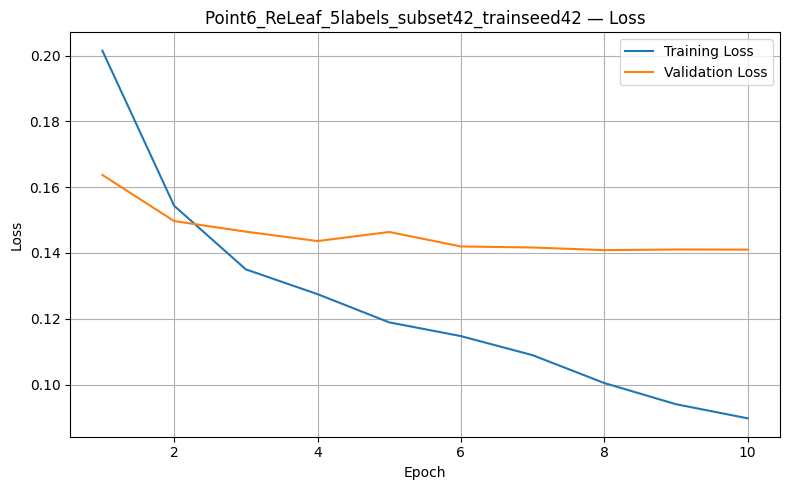

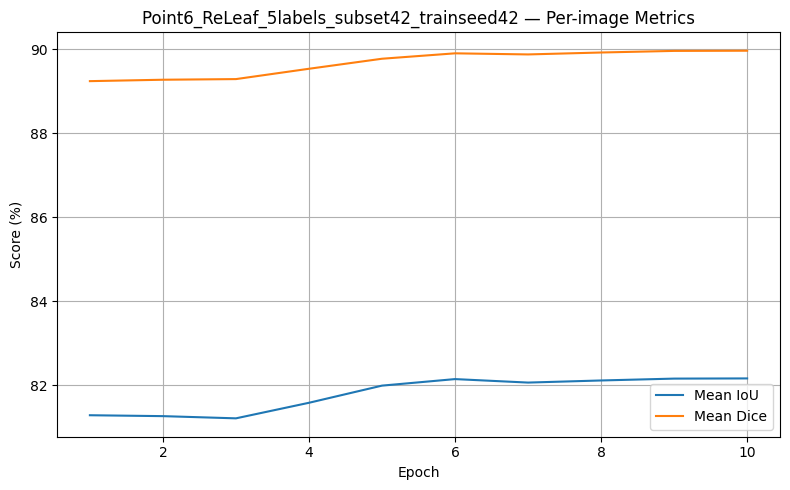

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 82.17%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed42/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset42_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2039
Val Loss: 0.1613
Mean IoU: 81.31%
Mean Dice: 89.24%
Global IoU: 82.53%
Global Dice: 90.43%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1504
Val Loss: 0.1488
Mean IoU: 81.17%
Mean Dice: 89.22%
Global IoU: 82.41%
Global Dice: 90.36%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1387
Val Loss: 0.1467
Me

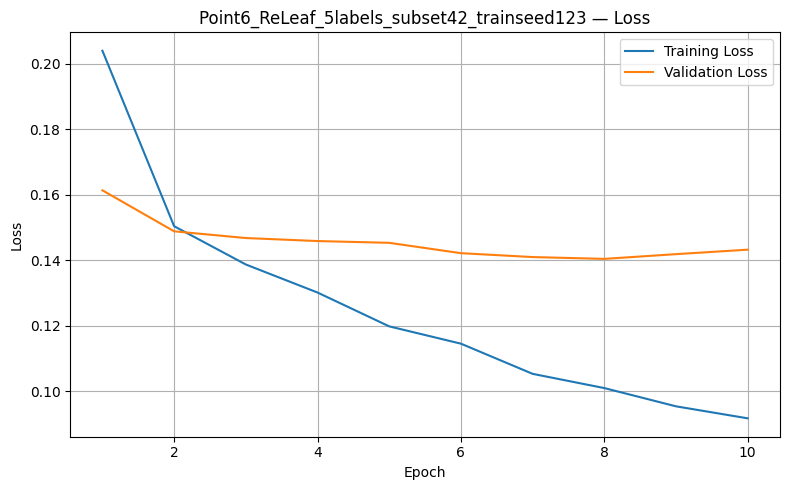

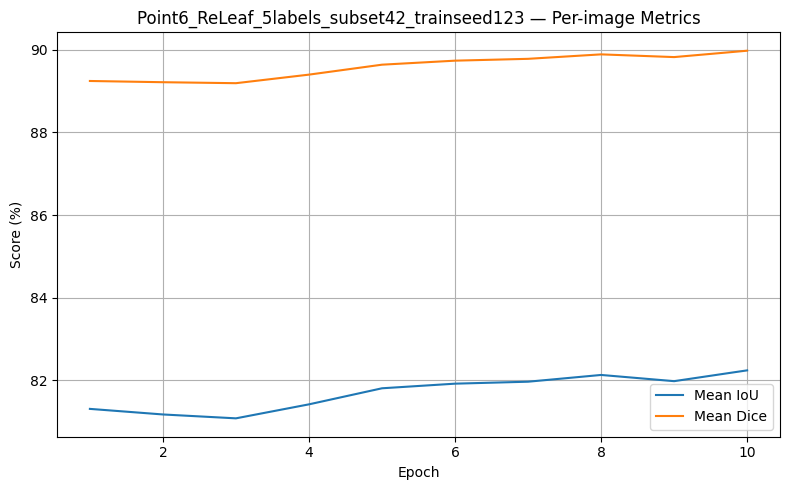

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 82.24%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed123/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset123_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1353
Val Loss: 0.1631
Mean IoU: 80.86%
Mean Dice: 89.00%
Global IoU: 82.06%
Global Dice: 90.15%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1177
Val Loss: 0.1535
Mean IoU: 80.70%
Mean Dice: 88.93%
Global IoU: 81.98%
Global Dice: 90.10%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1022
Val Loss: 0.1498
Me

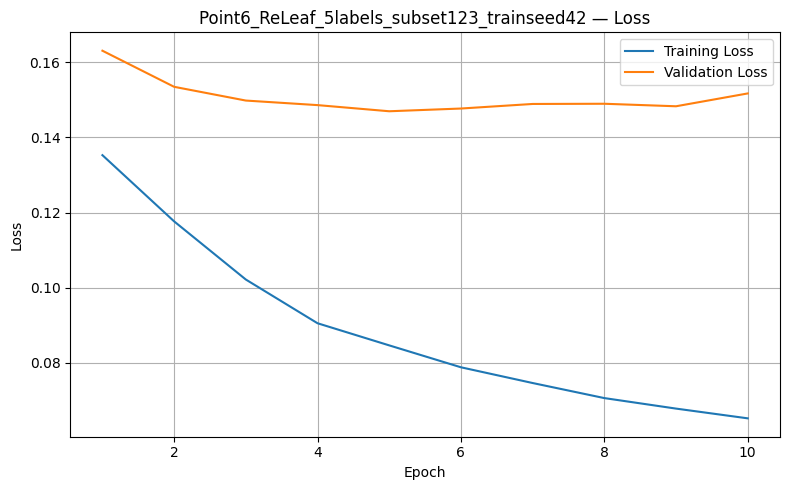

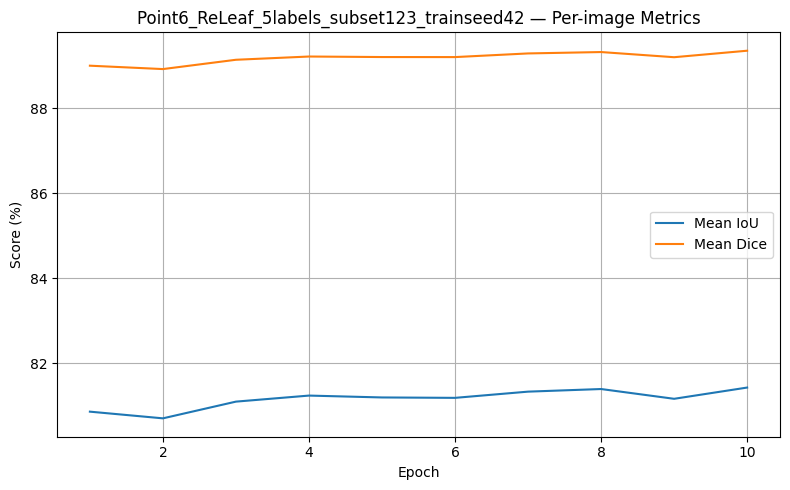

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 81.43%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed42/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset123_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1389
Val Loss: 0.1604
Mean IoU: 81.23%
Mean Dice: 89.21%
Global IoU: 82.44%
Global Dice: 90.38%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1072
Val Loss: 0.1524
Mean IoU: 81.25%
Mean Dice: 89.24%
Global IoU: 82.48%
Global Dice: 90.40%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
E

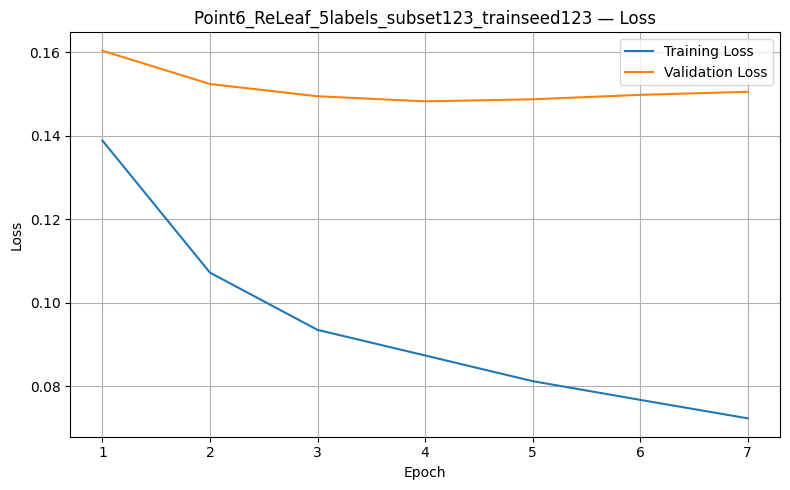

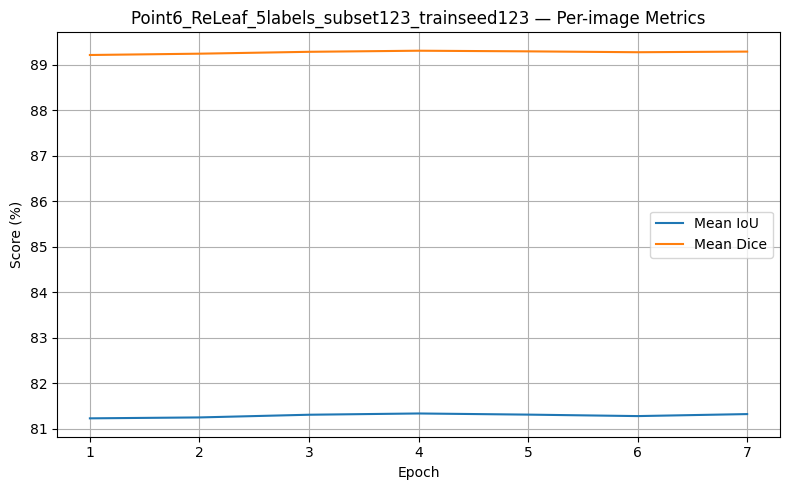

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 81.34%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset2026_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1831
Val Loss: 0.1618
Mean IoU: 81.37%
Mean Dice: 89.28%
Global IoU: 82.59%
Global Dice: 90.47%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1342
Val Loss: 0.1479
Mean IoU: 81.59%
Mean Dice: 89.46%
Global IoU: 82.81%
Global Dice: 90.60%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
E

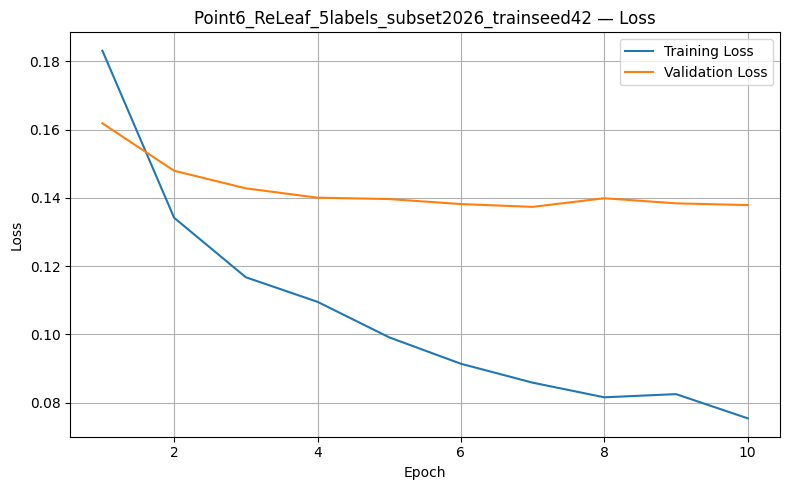

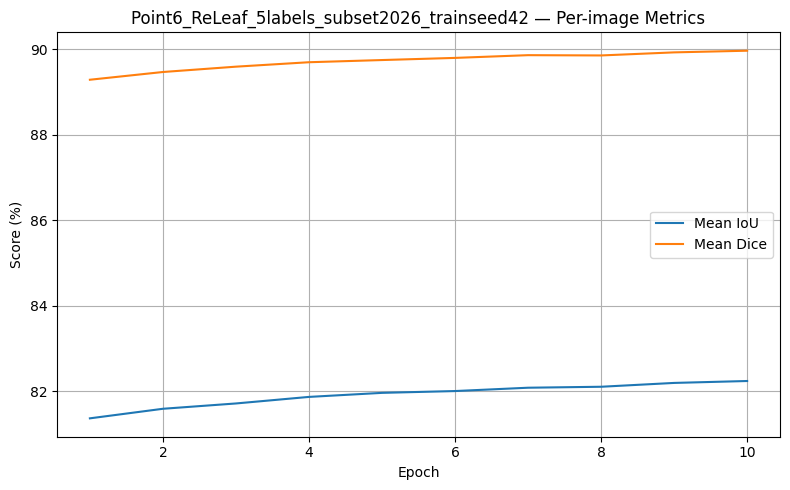

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 82.24%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset2026_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1683
Val Loss: 0.1562
Mean IoU: 81.38%
Mean Dice: 89.32%
Global IoU: 82.59%
Global Dice: 90.46%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1233
Val Loss: 0.1469
Mean IoU: 81.63%
Mean Dice: 89.50%
Global IoU: 82.84%
Global Dice: 90.62%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------

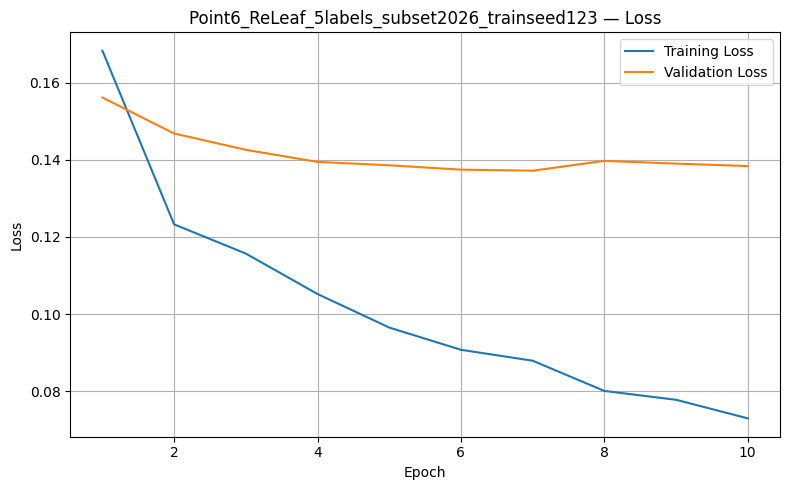

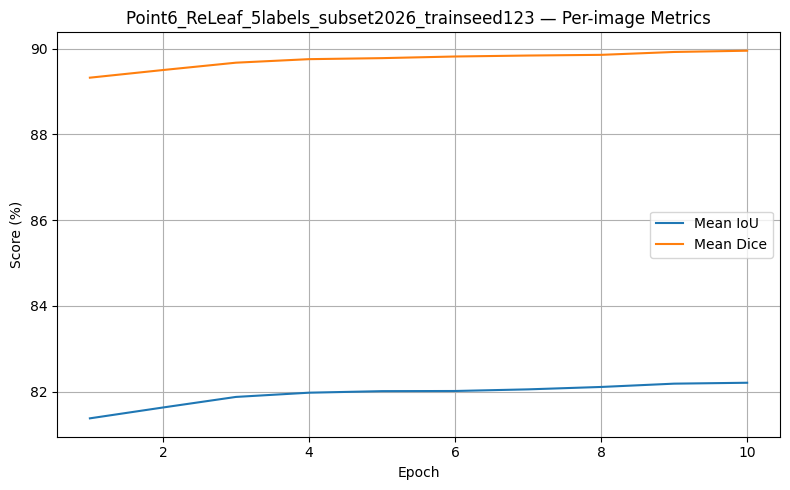

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 82.21%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset77_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1700
Val Loss: 0.1568
Mean IoU: 81.33%
Mean Dice: 89.30%
Global IoU: 82.51%
Global Dice: 90.42%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1259
Val Loss: 0.1481
Mean IoU: 81.44%
Mean Dice: 89.39%
Global IoU: 82.65%
Global Dice: 90.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch

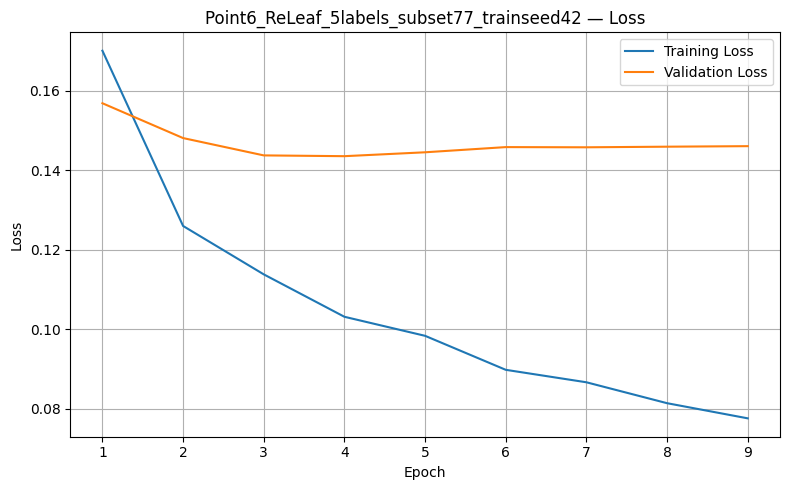

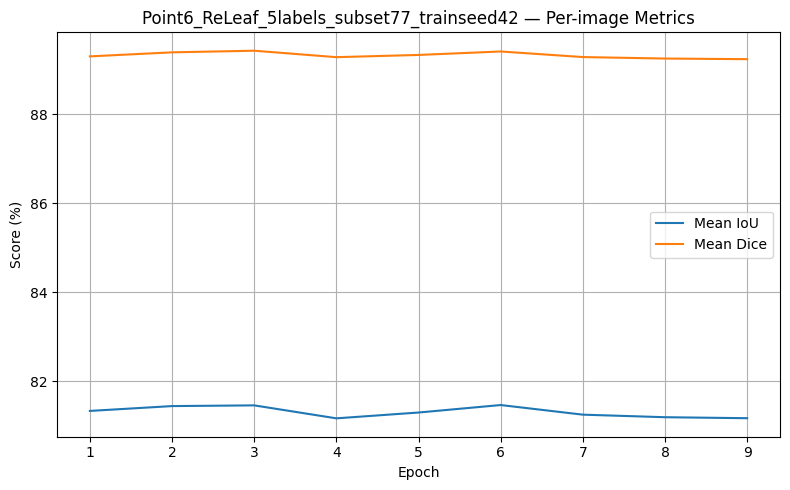

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 81.47%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset77_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1741
Val Loss: 0.1602
Mean IoU: 81.34%
Mean Dice: 89.28%
Global IoU: 82.55%
Global Dice: 90.44%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1283
Val Loss: 0.1486
Mean IoU: 81.29%
Mean Dice: 89.28%
Global IoU: 82.54%
Global Dice: 90.44%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1124
Val Loss: 0.1462
Me

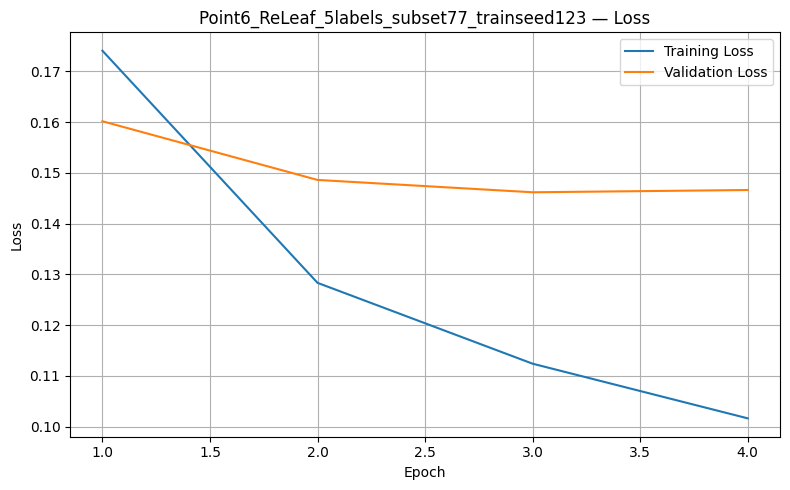

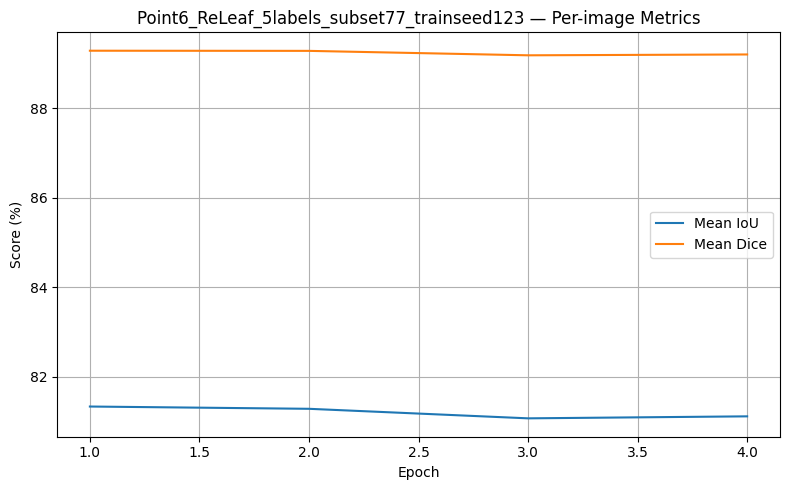

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 81.34%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed123/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset314_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3337
Val Loss: 0.1503
Mean IoU: 81.72%
Mean Dice: 89.63%
Global IoU: 82.79%
Global Dice: 90.59%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.2393
Val Loss: 0.1479
Mean IoU: 80.65%
Mean Dice: 89.00%
Global IoU: 81.77%
Global Dice: 89.97%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1895
Val Loss: 0.1519
Me

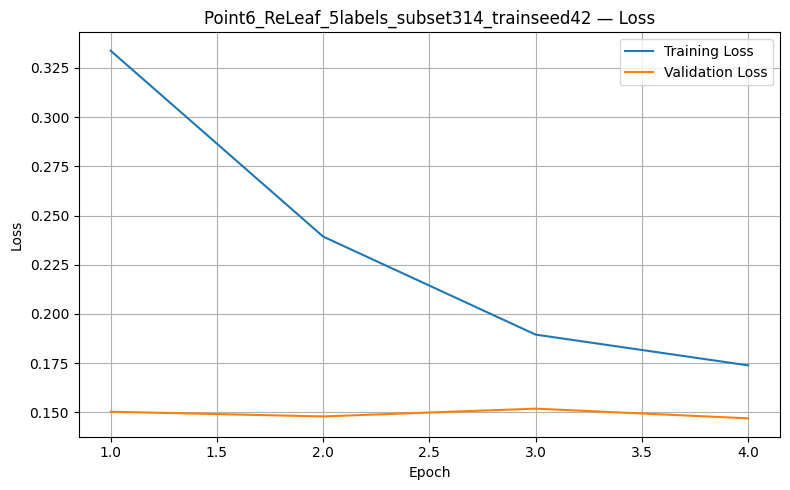

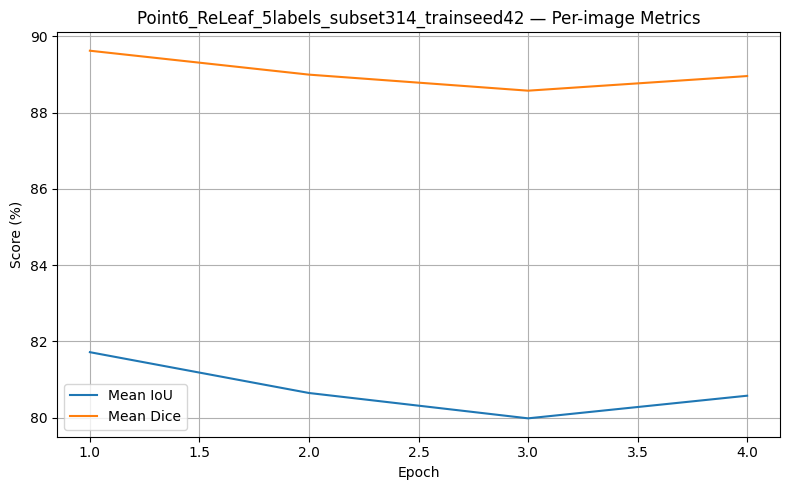

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 81.72%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed42/best_mask_decoder.pt

######################################################################
Point6_ReLeaf_5labels_subset314_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3414
Val Loss: 0.1533
Mean IoU: 81.48%
Mean Dice: 89.44%
Global IoU: 82.64%
Global Dice: 90.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.2142
Val Loss: 0.1470
Mean IoU: 80.89%
Mean Dice: 89.14%
Global IoU: 82.04%
Global Dice: 90.13%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1879
Val Loss: 0.1523
M

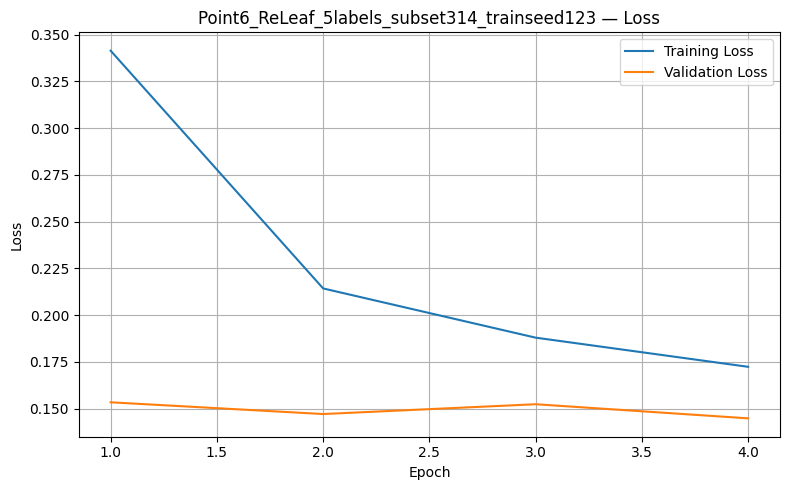

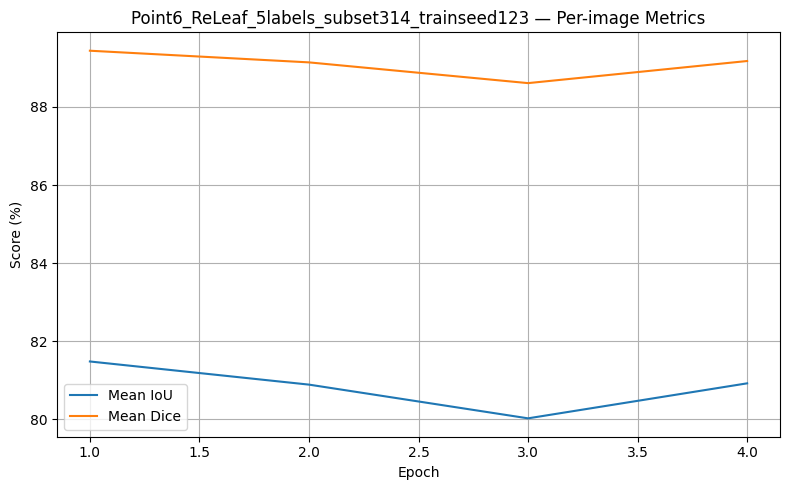

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 81.48%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed123/best_mask_decoder.pt

DATASET: WeedsGalore

######################################################################
Point6_WeedsGalore_5labels_subset42_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1540
Val Loss: 0.1742
Mean IoU: 61.12%
Mean Dice: 75.29%
Global IoU: 69.22%
Global Dice: 81.81%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1474
Val Loss: 0.1733
Mean IoU: 61.32%
Mean Dice: 75.39%
Global IoU: 69.66%
Global Dice: 82.12%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

------------------------------------------------------------------

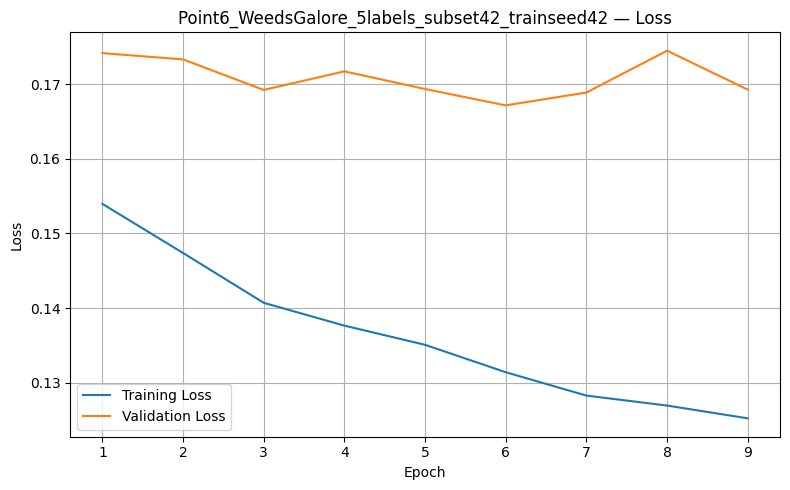

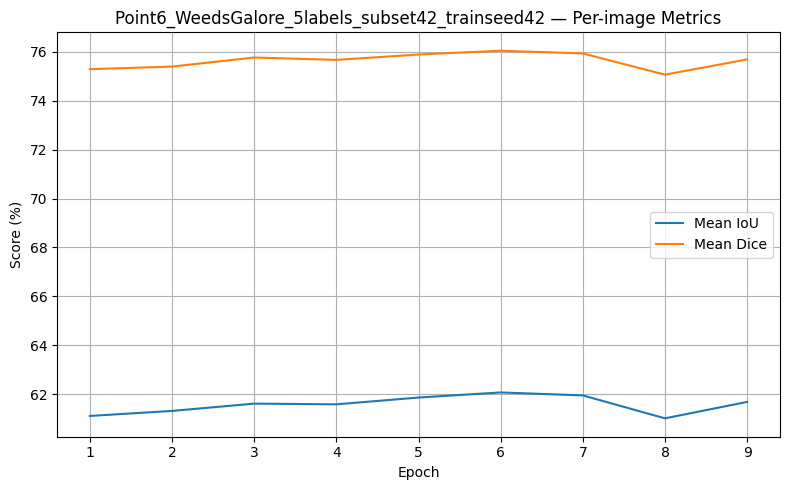

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 62.08%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset42_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1558
Val Loss: 0.1755
Mean IoU: 61.13%
Mean Dice: 75.26%
Global IoU: 69.42%
Global Dice: 81.95%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1455
Val Loss: 0.1685
Mean IoU: 61.81%
Mean Dice: 75.90%
Global IoU: 69.36%
Global Dice: 81.91%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------

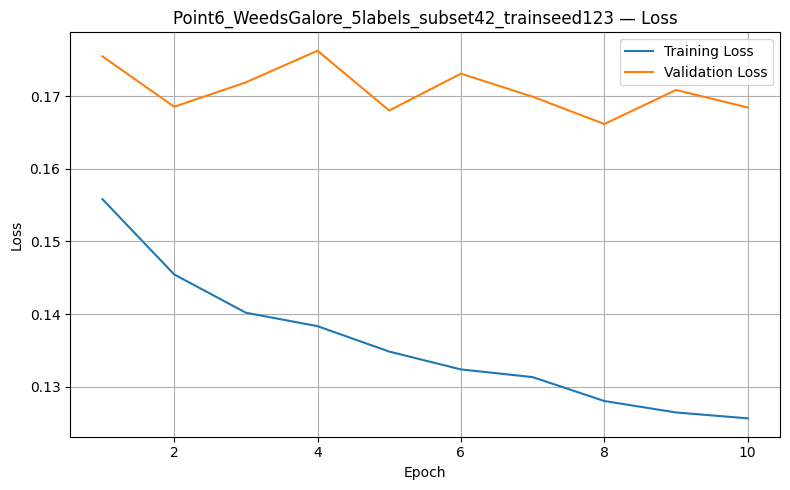

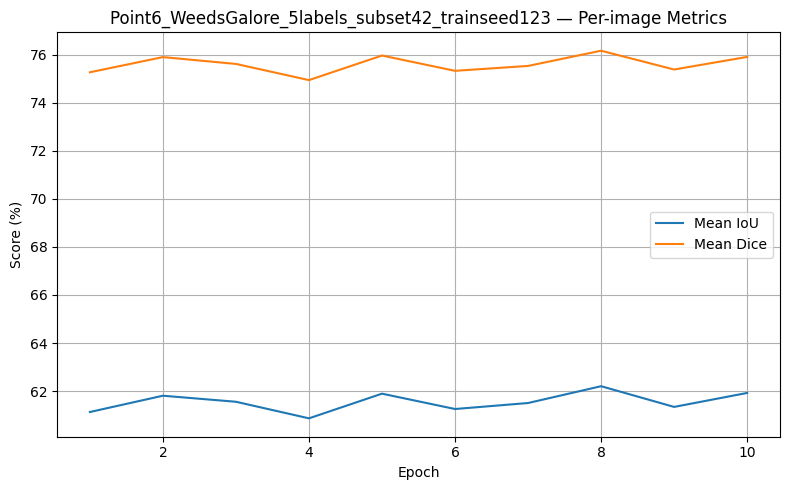

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 62.21%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset123_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1906
Val Loss: 0.1697
Mean IoU: 61.69%
Mean Dice: 75.86%
Global IoU: 68.55%
Global Dice: 81.34%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1798
Val Loss: 0.1713
Mean IoU: 61.44%
Mean Dice: 75.59%
Global IoU: 69.15%
Global Dice: 81.76%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1767
Val Loss: 0.17

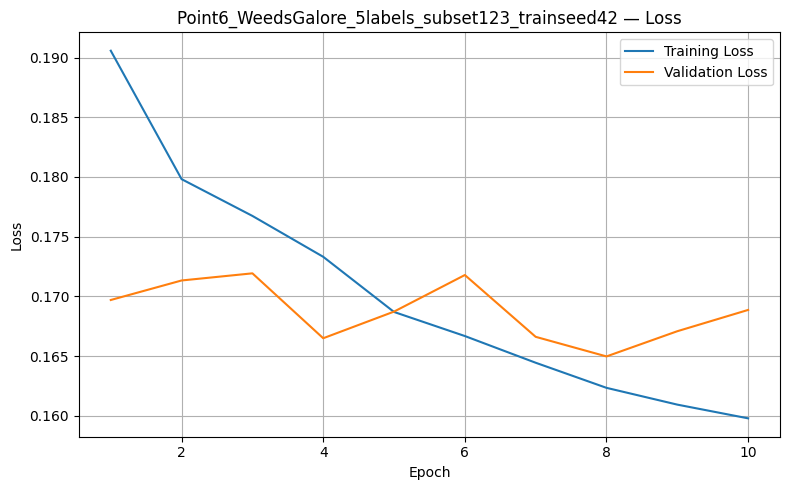

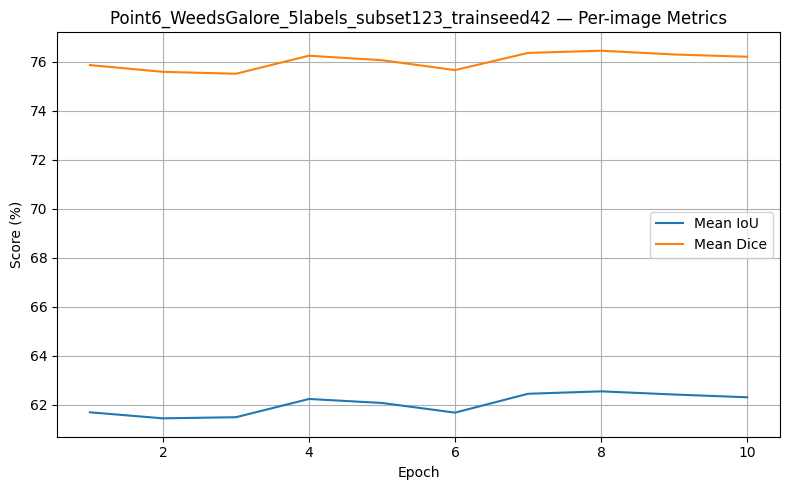


FINISHED: Point6_WeedsGalore_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 62.54%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed42/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset123_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1890
Val Loss: 0.1729
Mean IoU: 61.18%
Mean Dice: 75.39%
Global IoU: 68.68%
Global Dice: 81.43%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1833
Val Loss: 0.1719
Mean IoU: 61.59%
Mean Dice: 75.65%
Global IoU: 69.54%
Global Dice: 82.03%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

--------------------------------------------------------------

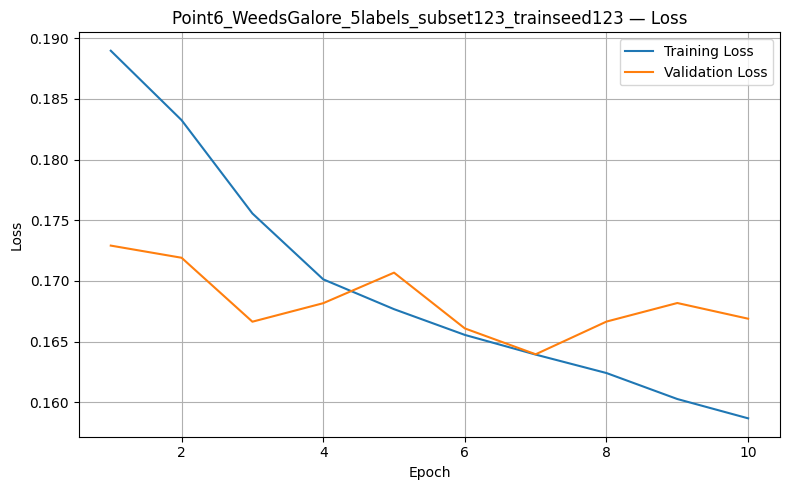

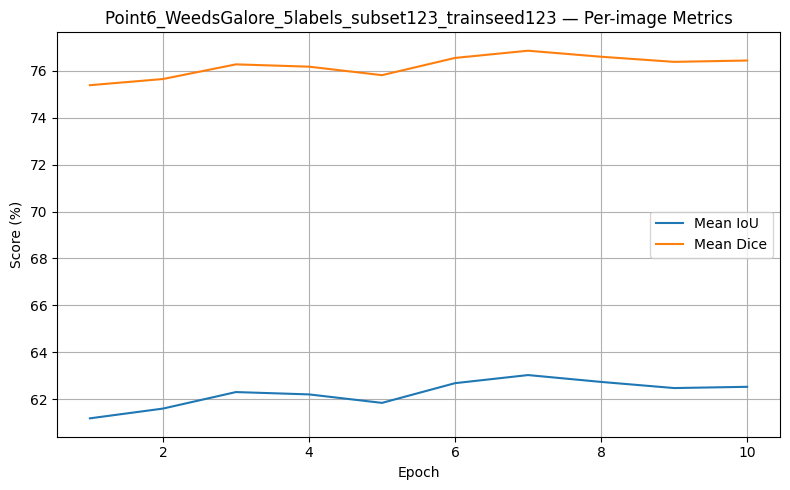


FINISHED: Point6_WeedsGalore_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 63.02%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset2026_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2132
Val Loss: 0.1736
Mean IoU: 61.27%
Mean Dice: 75.41%
Global IoU: 69.02%
Global Dice: 81.67%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1953
Val Loss: 0.1646
Mean IoU: 62.63%
Mean Dice: 76.58%
Global IoU: 69.58%
Global Dice: 82.06%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

--------------------------------------------------------------

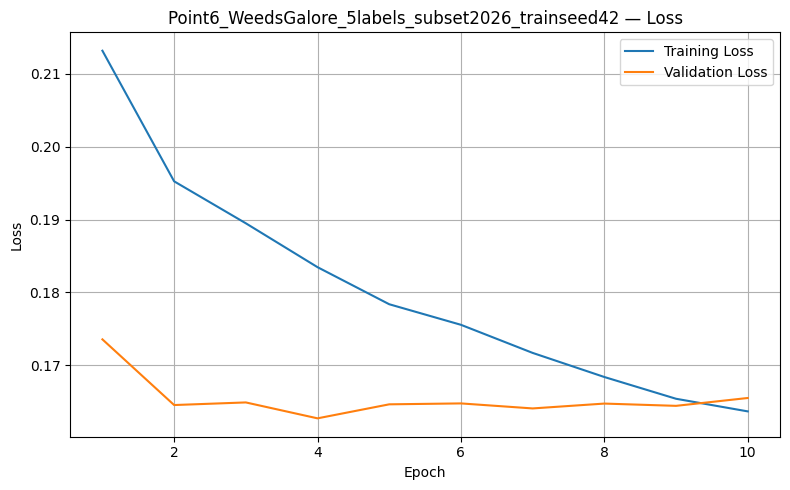

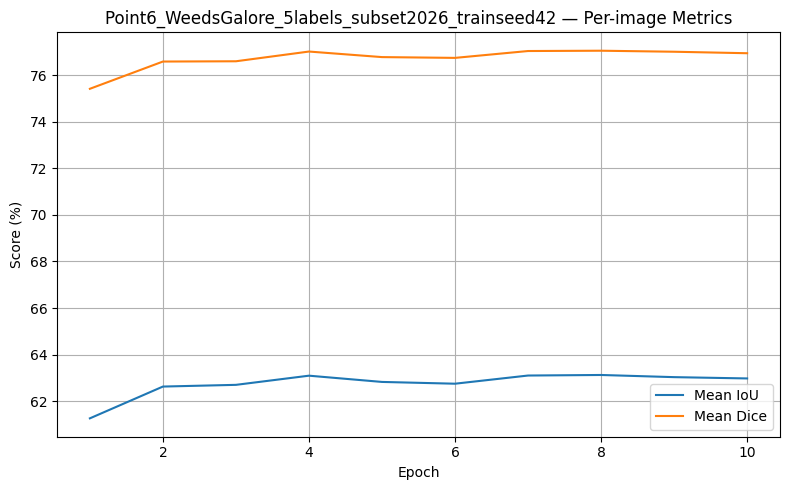


FINISHED: Point6_WeedsGalore_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 63.13%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset2026_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2070
Val Loss: 0.1689
Mean IoU: 62.06%
Mean Dice: 76.09%
Global IoU: 69.44%
Global Dice: 81.96%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1914
Val Loss: 0.1668
Mean IoU: 62.31%
Mean Dice: 76.26%
Global IoU: 69.35%
Global Dice: 81.90%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

------------------------------------------------------------

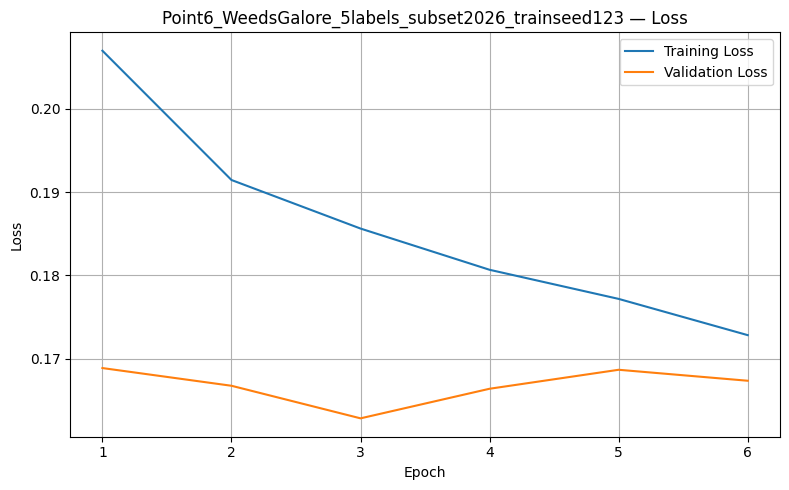

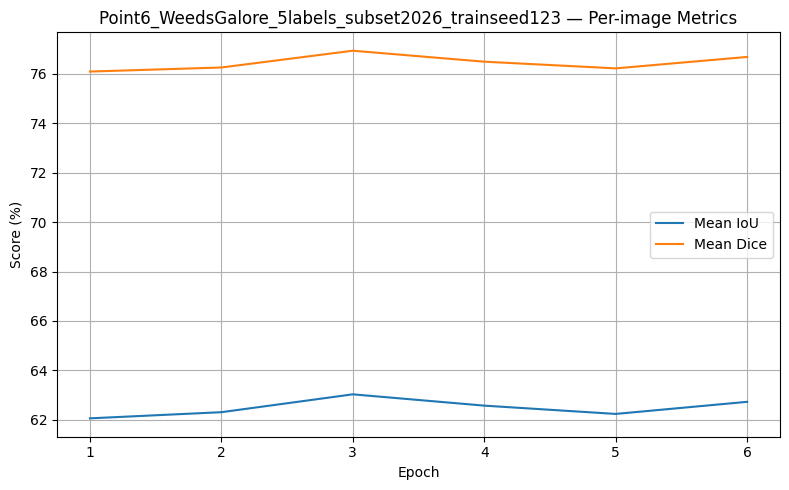

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 63.03%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset77_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1833
Val Loss: 0.1718
Mean IoU: 62.11%
Mean Dice: 76.10%
Global IoU: 69.07%
Global Dice: 81.71%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1668
Val Loss: 0.1676
Mean IoU: 62.43%
Mean Dice: 76.36%
Global IoU: 69.42%
Global Dice: 81.95%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

------------------------------------------------------------------

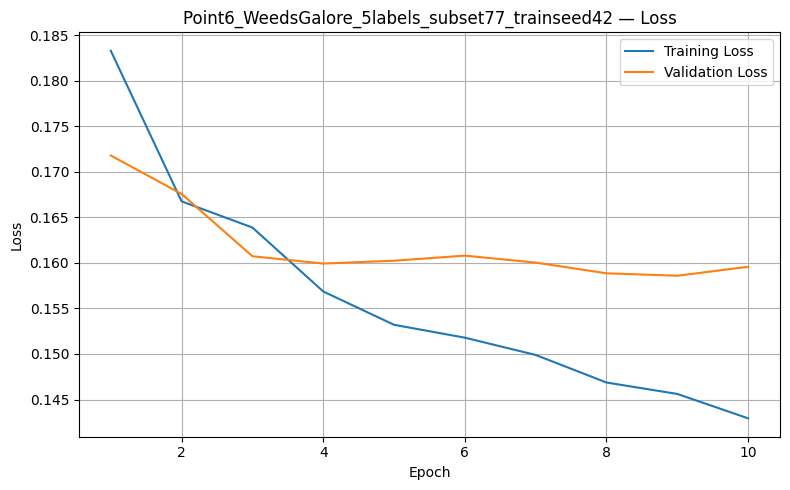

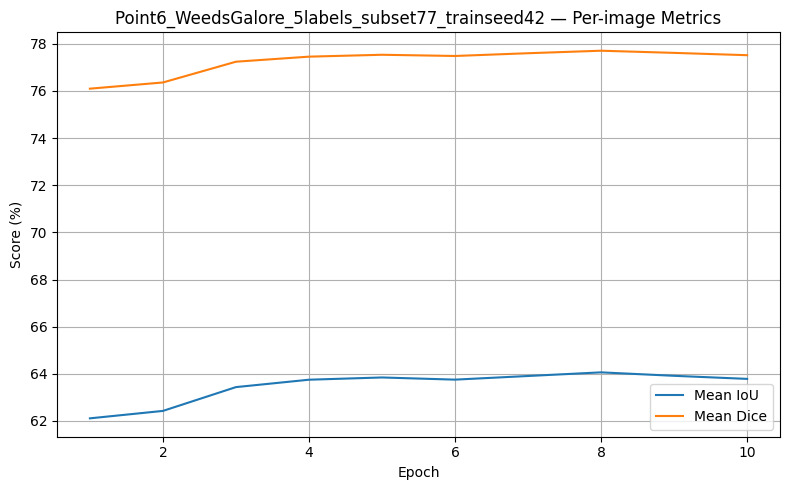

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 64.06%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset77_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1912
Val Loss: 0.1718
Mean IoU: 62.28%
Mean Dice: 76.25%
Global IoU: 69.30%
Global Dice: 81.86%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1687
Val Loss: 0.1656
Mean IoU: 62.66%
Mean Dice: 76.63%
Global IoU: 68.90%
Global Dice: 81.59%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------

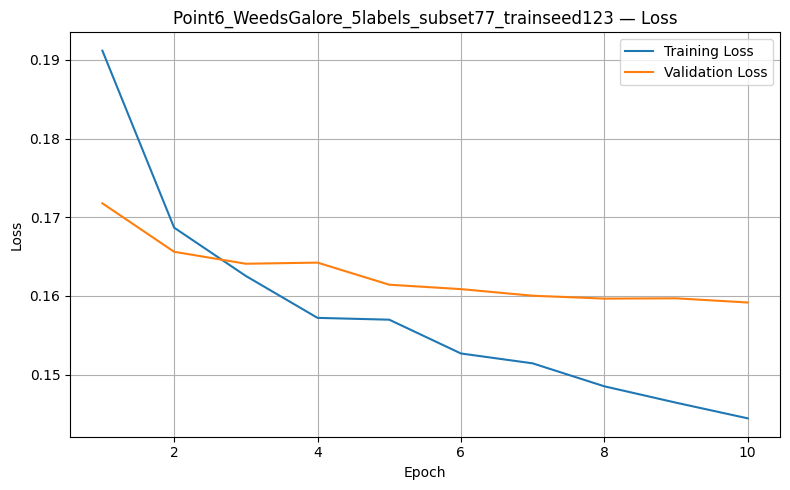

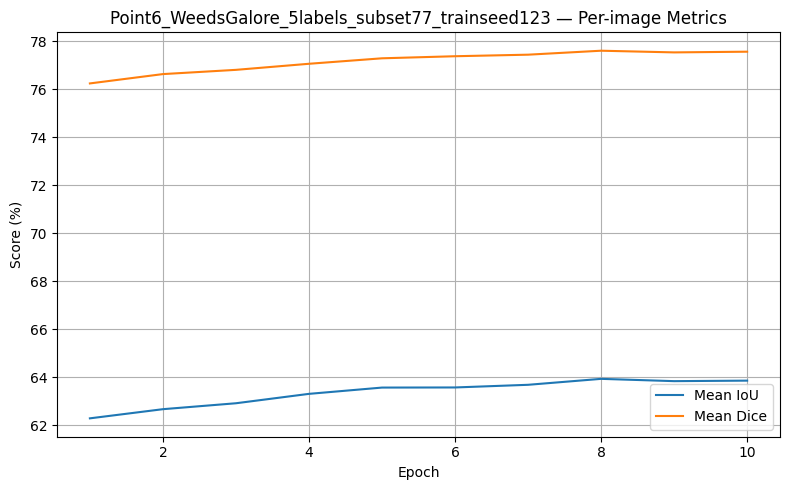

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 63.93%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset314_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1705
Val Loss: 0.1666
Mean IoU: 62.30%
Mean Dice: 76.34%
Global IoU: 68.64%
Global Dice: 81.41%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1611
Val Loss: 0.1756
Mean IoU: 60.81%
Mean Dice: 74.99%
Global IoU: 68.46%
Global Dice: 81.28%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1586
Val Loss: 0.17

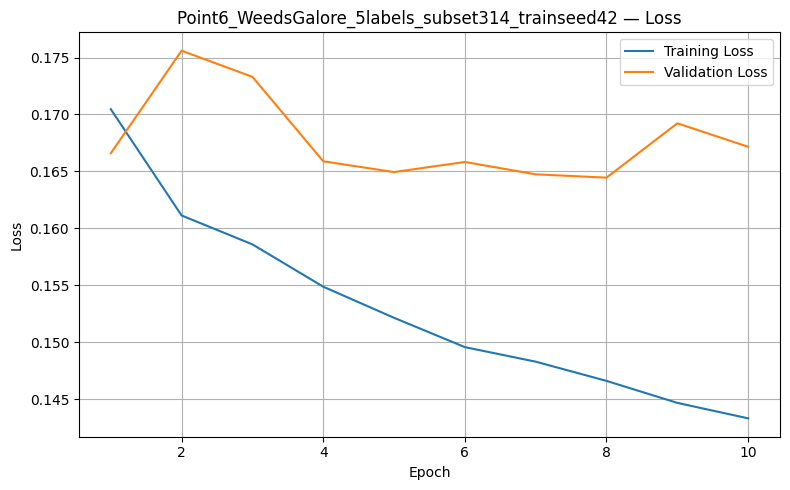

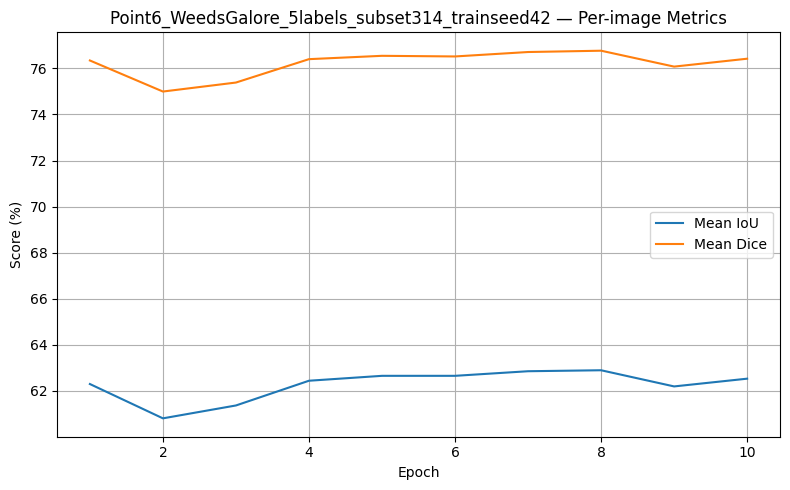

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 62.90%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed42/best_mask_decoder.pt

######################################################################
Point6_WeedsGalore_5labels_subset314_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1703
Val Loss: 0.1678
Mean IoU: 62.22%
Mean Dice: 76.30%
Global IoU: 68.56%
Global Dice: 81.35%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1606
Val Loss: 0.1732
Mean IoU: 61.70%
Mean Dice: 75.71%
Global IoU: 69.45%
Global Dice: 81.97%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1574
Val Loss: 0.1

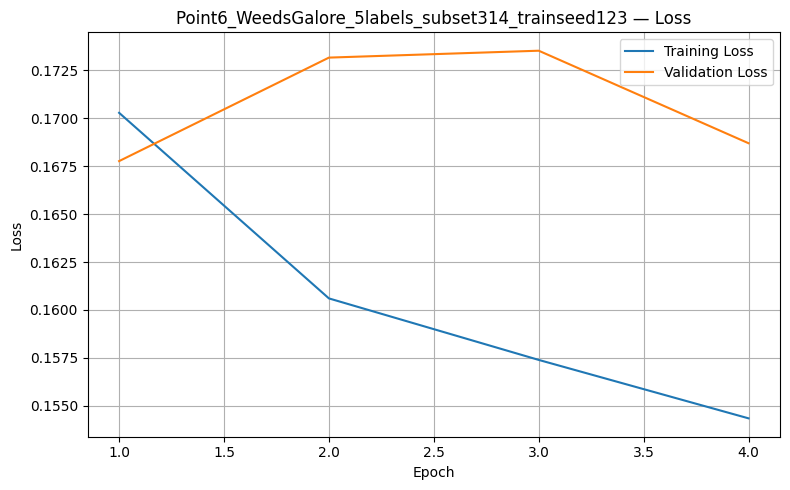

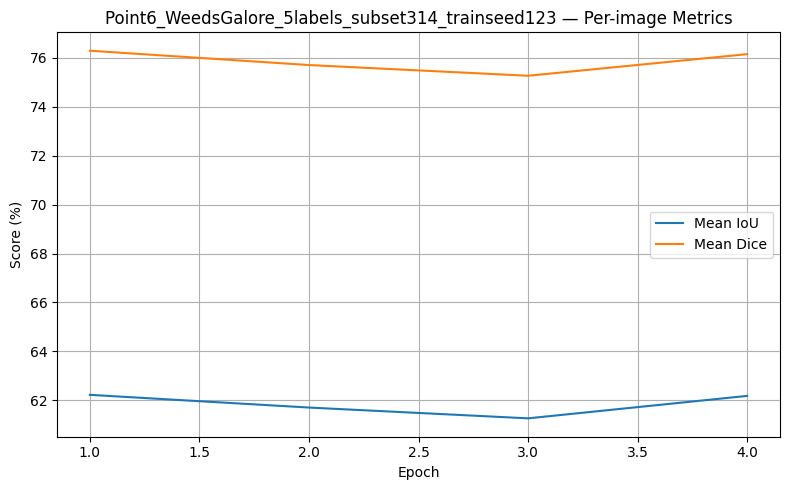

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 62.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed123/best_mask_decoder.pt

DATASET: EWI1S

######################################################################
Point6_EWI1S_5labels_subset42_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6648
Val Loss: 0.6056
Mean IoU: 16.79%
Mean Dice: 23.55%
Global IoU: 3.21%
Global Dice: 6.23%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5899
Val Loss: 0.4438
Mean IoU: 16.77%
Mean Dice: 23.15%
Global IoU: 12.66%
Global Dice: 22.48%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.5415
Val Loss: 0.4598
Mean I

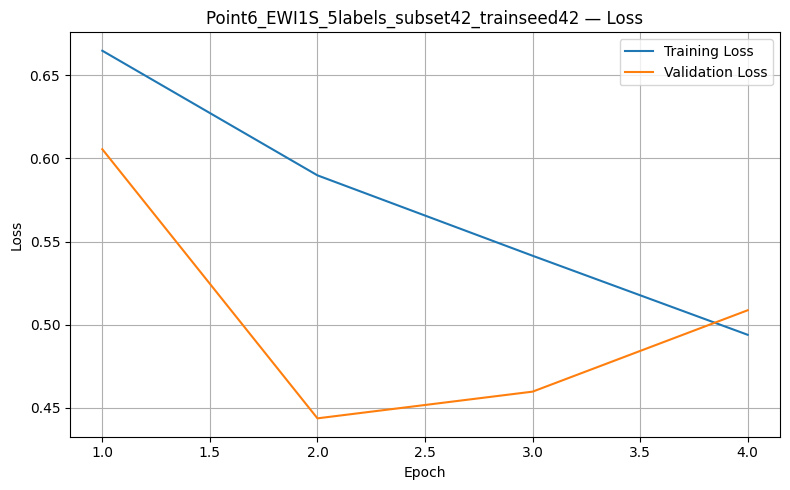

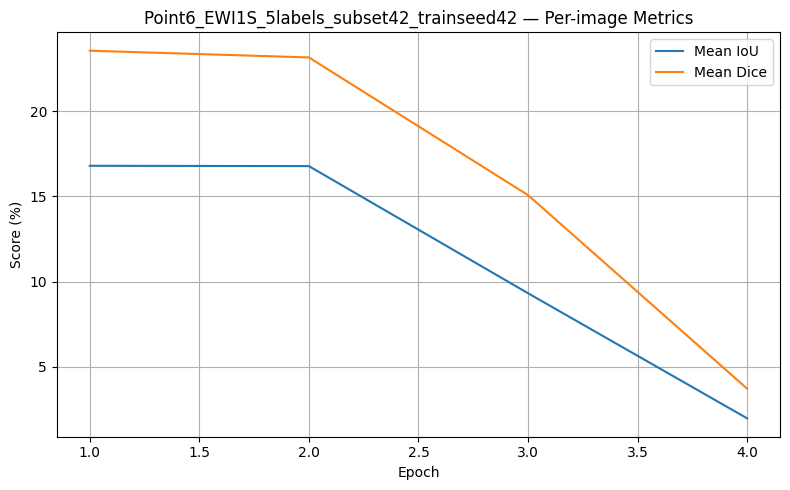

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 16.79%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed42/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset42_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6458
Val Loss: 0.4422
Mean IoU: 17.61%
Mean Dice: 24.49%
Global IoU: 13.84%
Global Dice: 24.31%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5524
Val Loss: 0.4519
Mean IoU: 14.15%
Mean Dice: 20.07%
Global IoU: 13.37%
Global Dice: 23.59%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.5049
Val Loss: 0.4688
Mea

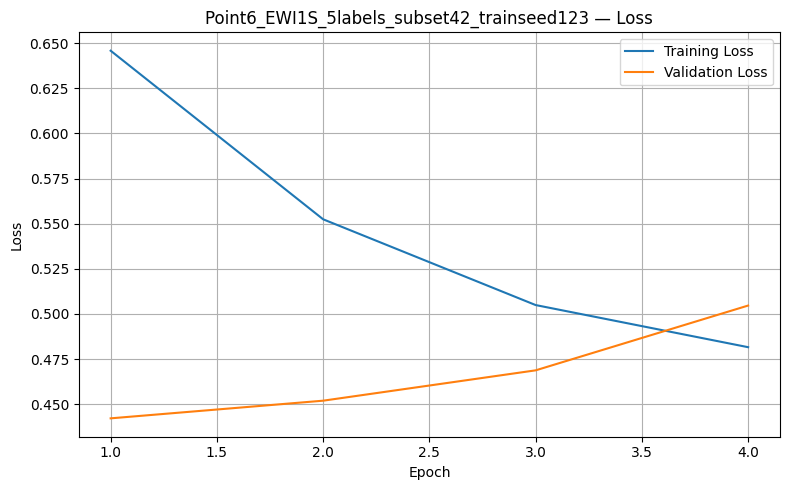

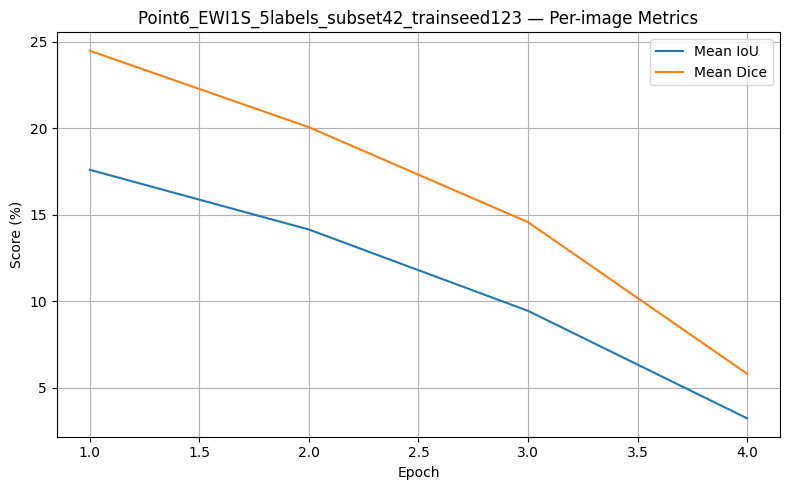

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 17.61%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed123/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset123_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4416
Val Loss: 0.7134
Mean IoU: 13.12%
Mean Dice: 18.13%
Global IoU: 1.99%
Global Dice: 3.90%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4086
Val Loss: 0.6588
Mean IoU: 11.77%
Mean Dice: 16.34%
Global IoU: 1.96%
Global Dice: 3.84%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3795
Val Loss: 0.5986
Mean Io

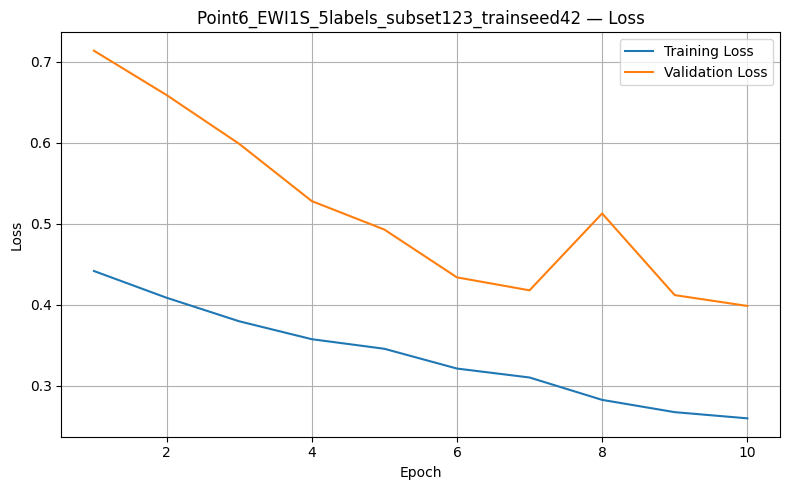

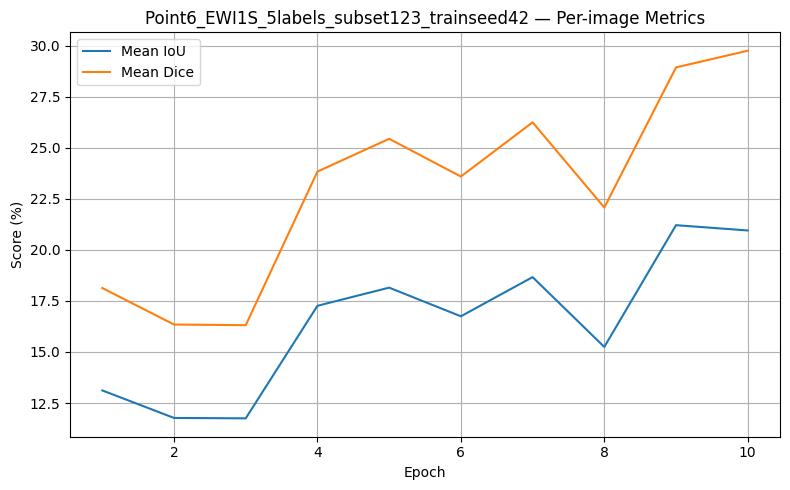

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 21.21%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed42/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset123_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4407
Val Loss: 0.6582
Mean IoU: 12.44%
Mean Dice: 16.96%
Global IoU: 2.13%
Global Dice: 4.17%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4055
Val Loss: 0.6341
Mean IoU: 11.29%
Mean Dice: 15.46%
Global IoU: 1.75%
Global Dice: 3.45%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3840
Val Loss: 0.5761
Mean I

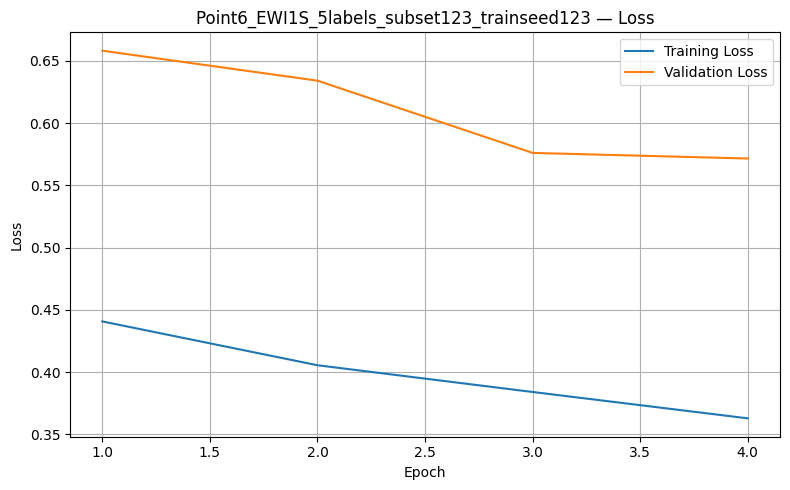

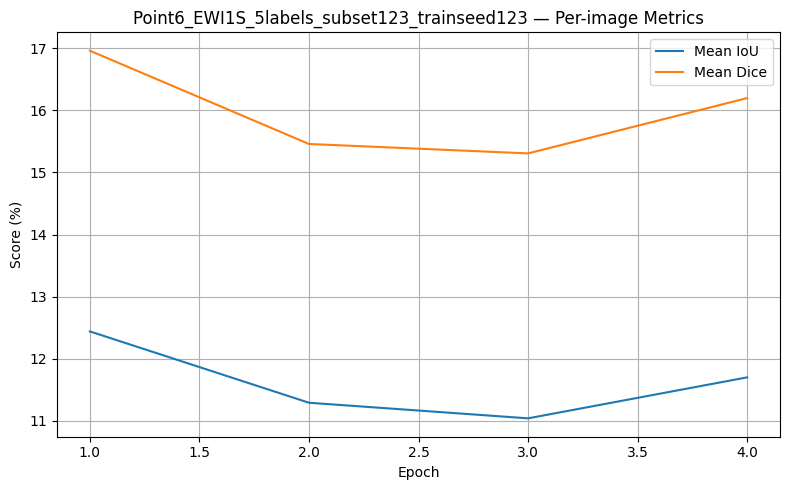

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 12.44%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed123/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset2026_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4973
Val Loss: 0.6986
Mean IoU: 12.73%
Mean Dice: 17.41%
Global IoU: 1.92%
Global Dice: 3.78%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4516
Val Loss: 0.4571
Mean IoU: 17.29%
Mean Dice: 23.71%
Global IoU: 12.94%
Global Dice: 22.91%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch

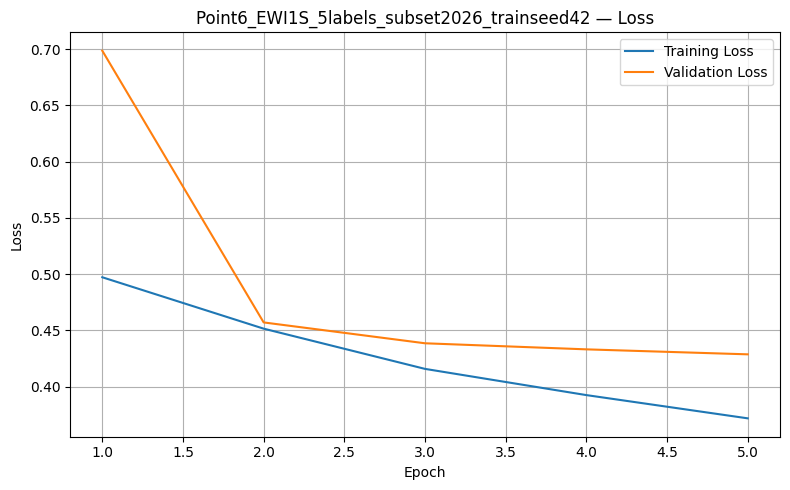

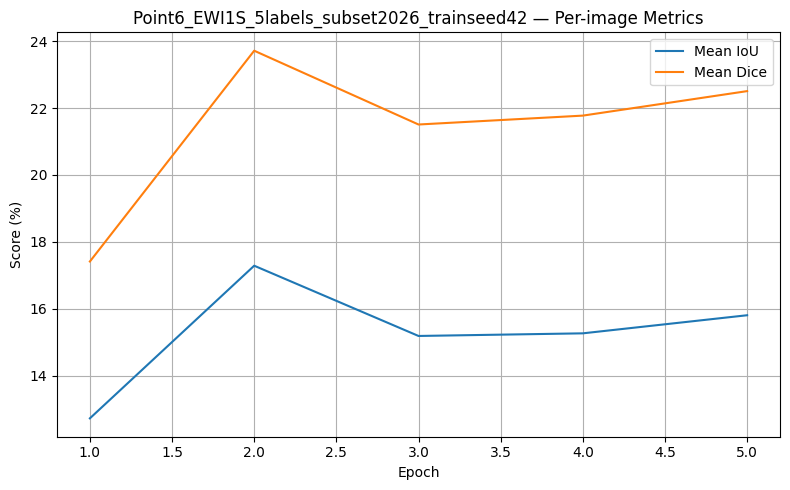

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 17.29%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset2026_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4789
Val Loss: 0.4397
Mean IoU: 18.63%
Mean Dice: 25.82%
Global IoU: 14.04%
Global Dice: 24.62%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4246
Val Loss: 0.4432
Mean IoU: 15.28%
Mean Dice: 21.71%
Global IoU: 13.28%
Global Dice: 23.45%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.4171
Val Loss: 0.4391
M

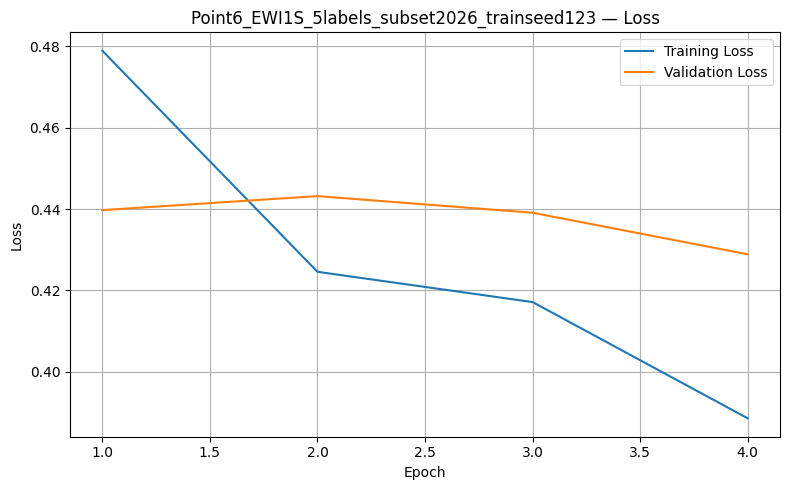

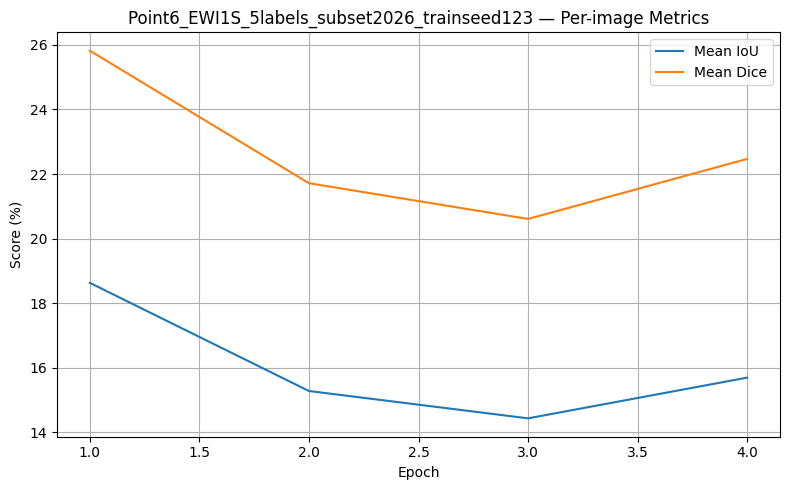

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 18.63%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed123/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset77_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3722
Val Loss: 0.7657
Mean IoU: 14.31%
Mean Dice: 19.45%
Global IoU: 1.90%
Global Dice: 3.72%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3321
Val Loss: 0.7287
Mean IoU: 14.96%
Mean Dice: 20.63%
Global IoU: 1.88%
Global Dice: 3.69%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10


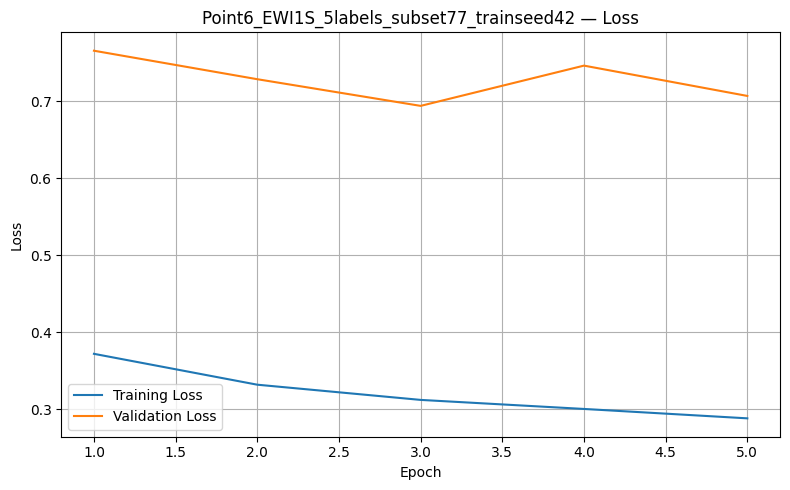

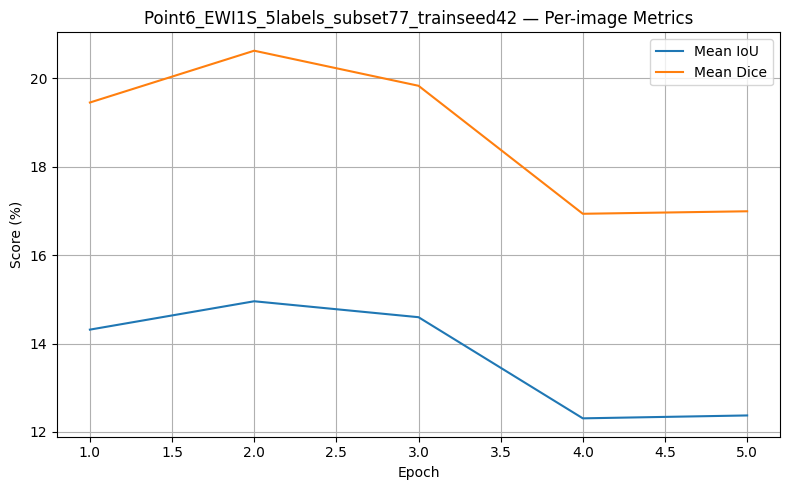

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 14.96%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset77_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3704
Val Loss: 0.6681
Mean IoU: 15.08%
Mean Dice: 20.56%
Global IoU: 2.14%
Global Dice: 4.18%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3285
Val Loss: 0.7693
Mean IoU: 12.09%
Mean Dice: 16.70%
Global IoU: 1.52%
Global Dice: 3.00%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3066
Val Loss: 0.7447
Mean Io

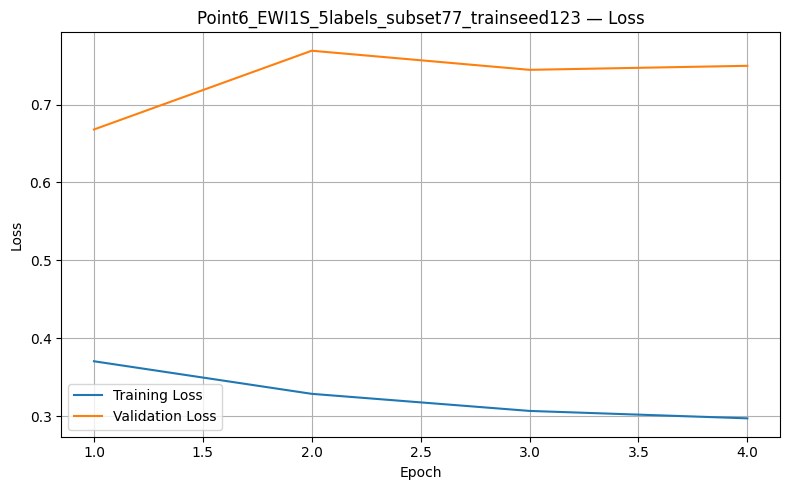

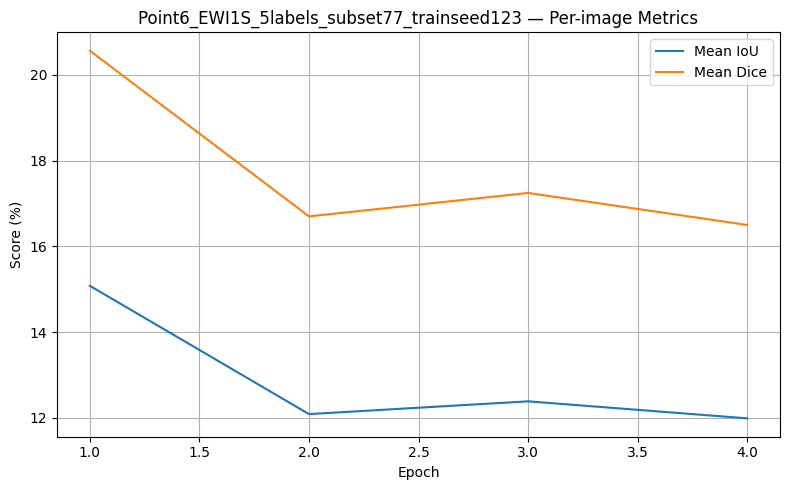

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 15.08%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed123/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset314_trainseed42
######################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.7047
Val Loss: 0.7263
Mean IoU: 14.49%
Mean Dice: 19.81%
Global IoU: 2.41%
Global Dice: 4.70%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5662
Val Loss: 0.4266
Mean IoU: 19.54%
Mean Dice: 26.92%
Global IoU: 15.48%
Global Dice: 26.82%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3

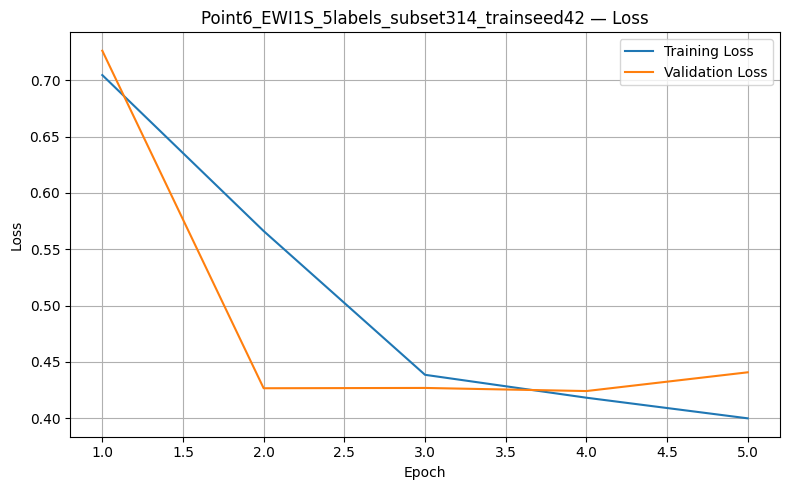

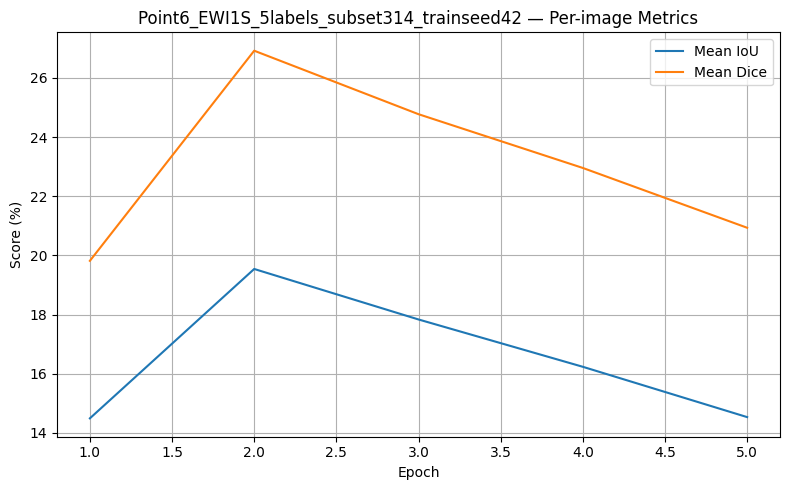

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 19.54%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

######################################################################
Point6_EWI1S_5labels_subset314_trainseed123
######################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.5946
Val Loss: 0.6449
Mean IoU: 15.36%
Mean Dice: 21.20%
Global IoU: 3.77%
Global Dice: 7.26%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5687
Val Loss: 0.5307
Mean IoU: 18.61%
Mean Dice: 25.66%
Global IoU: 3.26%
Global Dice: 6.31%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3

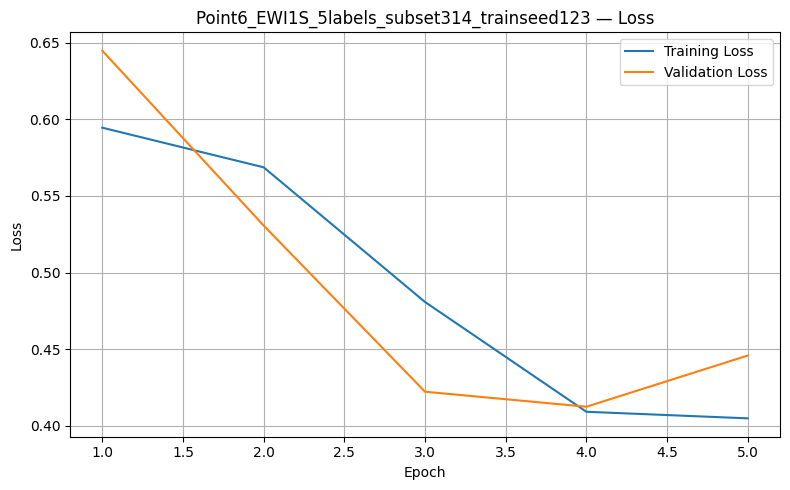

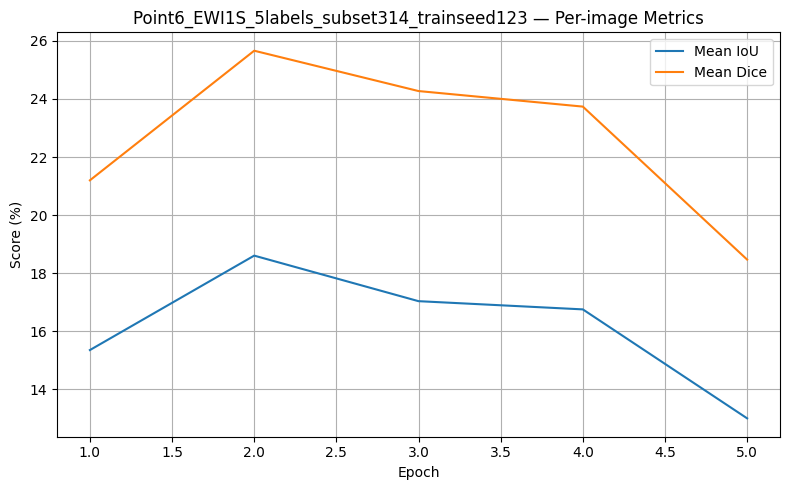


FINISHED: Point6_EWI1S_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 18.61%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

POINT 6 — FIVE-IMAGE EXPERIMENTS COMPLETED
Total runs: 30
Point6_ReLeaf_5labels_subset42_trainseed42                        Val IoU: 82.17%
Point6_ReLeaf_5labels_subset42_trainseed123                       Val IoU: 82.24%
Point6_ReLeaf_5labels_subset123_trainseed42                       Val IoU: 81.43%
Point6_ReLeaf_5labels_subset123_trainseed123                      Val IoU: 81.34%
Point6_ReLeaf_5labels_subset2026_trainseed42                      Val IoU: 82.24%
Point6_ReLeaf_5labels_subset2026_trainseed123                     Val IoU: 82.21%
Point6_ReLeaf_5labels_subset77_trainseed42                        Val IoU: 81.47%
Point6_ReLeaf_5labels_subset77_trainseed123                       Val IoU: 81.34%
Point6_ReLeaf_5labels_subset314_trainseed42                

In [54]:

# ============================================================
# POINT 6 — REPEATED FIVE-IMAGE EXPERIMENTS
# ============================================================

POINT6_TRAINING_SEEDS = [42, 123]
POINT6_SUBSET_BUDGET = 5

point6_results = {}

POINT6_DATASETS = {
    "ReLeaf": {
        "val_dataset": releaf_val_dataset
    },
    "WeedsGalore": {
        "val_dataset": weedsgalore_val_dataset
    },
    "EWI1S": {
        "val_dataset": ewis1_val_dataset
    }
}

for dataset_name, config in POINT6_DATASETS.items():

    print("\n" + "=" * 80)
    print("DATASET:", dataset_name)
    print("=" * 80)

    val_dataset = config["val_dataset"]

    for subset_seed in SUBSET_SEEDS:

        selected_records = point6_subsets[
            dataset_name
        ][subset_seed][POINT6_SUBSET_BUDGET]

        train_dataset = UnifiedSegmentationDataset(
            records=selected_records,
            dataset_name=dataset_name,
            jitter=True
        )

        assert len(train_dataset) == 5

        for training_seed in POINT6_TRAINING_SEEDS:

            experiment_name = (
                f"Point6_{dataset_name}_"
                f"5labels_subset{subset_seed}_"
                f"trainseed{training_seed}"
            )

            print("\n" + "#" * 70)
            print(experiment_name)
            print("#" * 70)

            result = run_finetuning_experiment(
                experiment_name=experiment_name,
                train_dataset=train_dataset,
                val_dataset=val_dataset,
                num_epochs=NUM_EPOCHS,
                learning_rate=LEARNING_RATE,
                patience=EARLY_STOPPING_PATIENCE,
                seed=training_seed
            )

            result["dataset"] = dataset_name
            result["label_budget"] = 5
            result["subset_seed"] = subset_seed
            result["training_seed"] = training_seed

            point6_results[experiment_name] = result


# ============================================================
# RESULTS SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("POINT 6 — FIVE-IMAGE EXPERIMENTS COMPLETED")
print("=" * 80)

print("Total runs:", len(point6_results))

for name, result in point6_results.items():

    print(
        f"{name:65s} "
        f"Val IoU: {result['best_mean_iou'] * 100:.2f}%"
    )


In [55]:
releaf_train_5 = UnifiedSegmentationDataset(
    records=releaf_labelled_subsets[5],
    dataset_name="ReLeaf",
    jitter=True
)

releaf_val_dataset = UnifiedSegmentationDataset(
    records=releaf_val_pairs,
    dataset_name="ReLeaf",
    jitter=False
)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_5_labels
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2015
Val Loss: 0.1637
Mean IoU: 81.29%
Mean Dice: 89.24%
Global IoU: 82.46%
Global Dice: 90.39%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_5_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1543
Val Loss: 0.1497
Mean IoU: 81.27%
Mean Dice: 89.28%
Global IoU: 82.44%
Global Dice: 90.38%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1350
Val Loss: 0.1465
Mean IoU: 81.22%
Mean Dice: 89

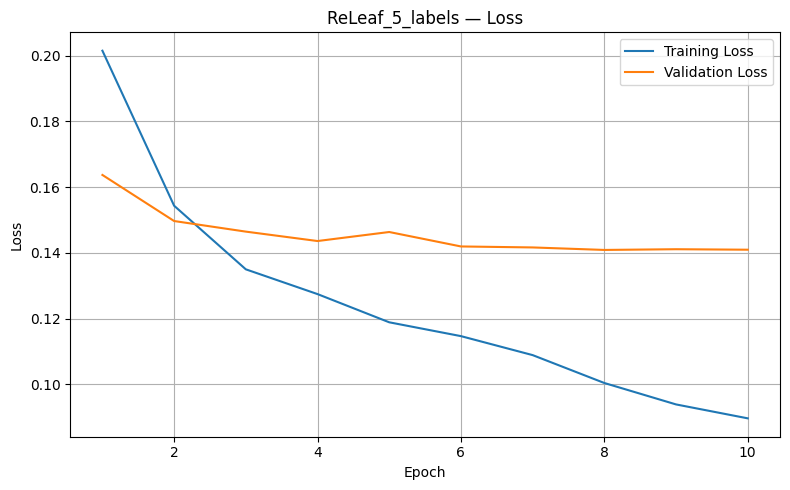

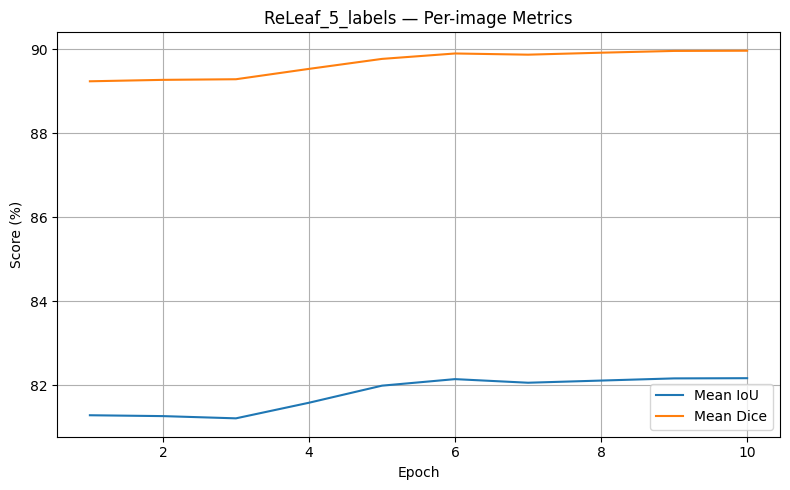


FINISHED: ReLeaf_5_labels
Training seed: 42
Best Mean IoU: 82.17%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_5_labels/best_mask_decoder.pt


In [56]:
releaf_5_result = run_finetuning_experiment(
    experiment_name="ReLeaf_5_labels",
    train_dataset=releaf_train_5,
    val_dataset=releaf_val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE
)

In [57]:
# ============================================================
# CREATE DATASETS FOR LABEL-EFFICIENCY EXPERIMENT
# ============================================================

# -------------------------
# ReLeaf
# -------------------------
releaf_labelled_datasets = {}

for size, records in releaf_labelled_subsets.items():
    releaf_labelled_datasets[size] = UnifiedSegmentationDataset(
        records=records,
        dataset_name="ReLeaf",
        jitter=True
    )

releaf_val_dataset = UnifiedSegmentationDataset(
    records=releaf_val_pairs,
    dataset_name="ReLeaf",
    jitter=False
)

releaf_test_dataset = UnifiedSegmentationDataset(
    records=releaf_test_pairs,
    dataset_name="ReLeaf",
    jitter=False
)


# -------------------------
# WeedsGalore
# -------------------------
weedsgalore_labelled_datasets = {}

for size, records in weedsgalore_labelled_subsets.items():
    weedsgalore_labelled_datasets[size] = UnifiedSegmentationDataset(
        records=records,
        dataset_name="WeedsGalore",
        jitter=True
    )

weedsgalore_val_dataset = UnifiedSegmentationDataset(
    records=weedsgalore_val_pairs,
    dataset_name="WeedsGalore",
    jitter=False
)

weedsgalore_test_dataset = UnifiedSegmentationDataset(
    records=weedsgalore_test_pairs,
    dataset_name="WeedsGalore",
    jitter=False
)


# -------------------------
# EWI1S
# -------------------------
ewis1_labelled_datasets = {}

for size, records in ewis1_labelled_subsets.items():
    ewis1_labelled_datasets[size] = UnifiedSegmentationDataset(
        records=records,
        dataset_name="EWI1S",
        jitter=True
    )

ewis1_val_dataset = UnifiedSegmentationDataset(
    records=ewis1_val_pairs,
    dataset_name="EWI1S",
    jitter=False
)

ewis1_test_dataset = UnifiedSegmentationDataset(
    records=ewis1_test_pairs,
    dataset_name="EWI1S",
    jitter=False
)

print("Datasets created successfully.")

Datasets created successfully.



################################################################################
# RELEAF — 5 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_5_labels
Training seed: 42
Training samples: 5
Validation samples: 34


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2015
Val Loss: 0.1637
Mean IoU: 81.29%
Mean Dice: 89.24%
Global IoU: 82.46%
Global Dice: 90.39%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_5_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1543
Val Loss: 0.1497
Mean IoU: 81.27%
Mean Dice: 89.28%
Global IoU: 82.45%
Global Dice: 90.38%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1350
Val Loss: 0.1465
Mean IoU: 81.23%
Mean Dice: 89

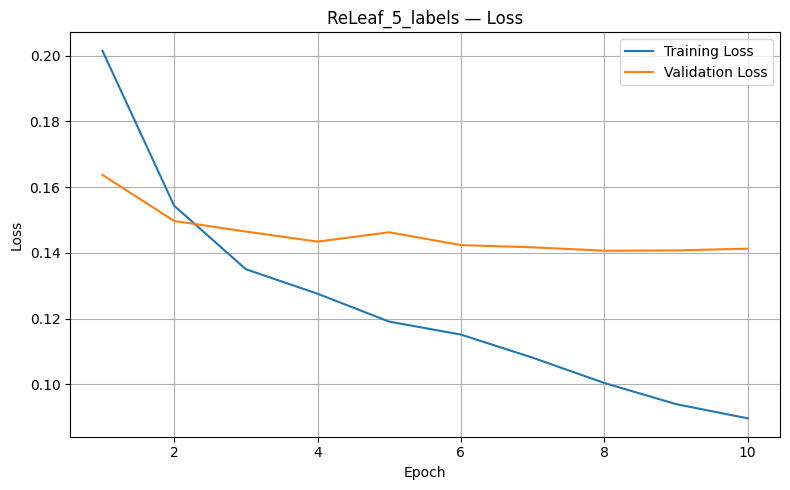

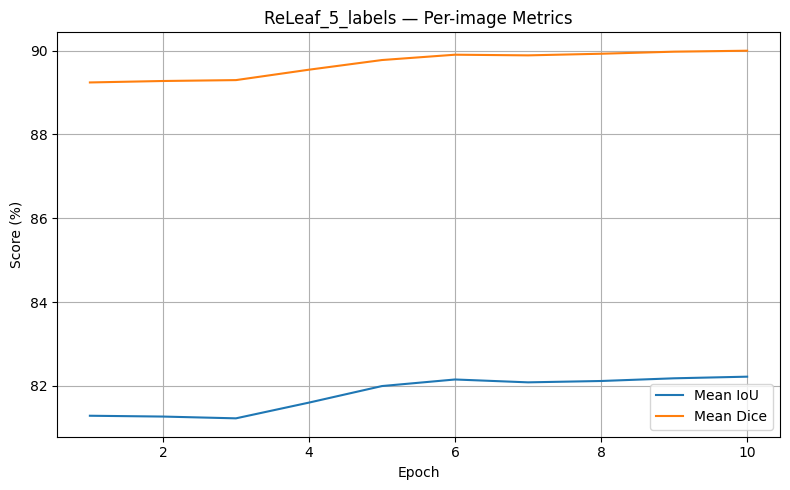

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: ReLeaf_5_labels
Training seed: 42
Best Mean IoU: 82.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_5_labels/best_mask_decoder.pt

################################################################################
# RELEAF — 10 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_10_labels
Training seed: 42
Training samples: 10
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1954
Val Loss: 0.1458
Mean IoU: 81.70%
Mean Dice: 89.57%
Global IoU: 82.86%
Global Dice: 90.63%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1369
Val Loss: 0.1415
Mean IoU: 81.89%
Mean Dice: 89.75%
Global IoU: 82.95%
Global Dice: 90.68%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------

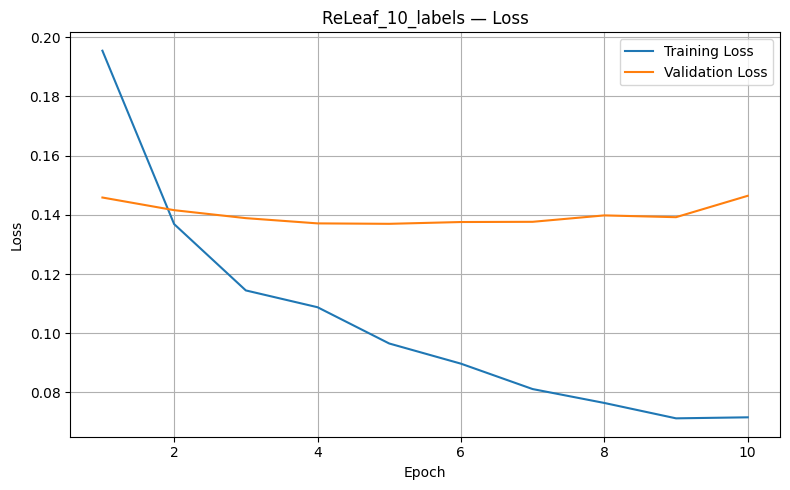

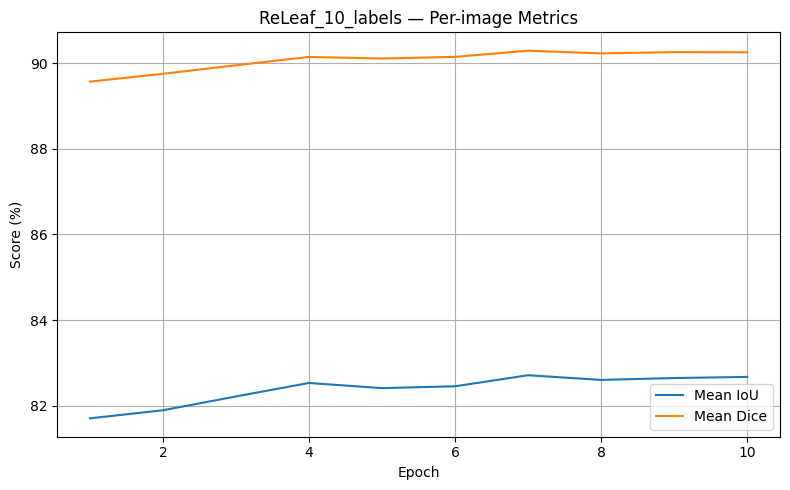

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: ReLeaf_10_labels
Training seed: 42
Best Mean IoU: 82.71%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_10_labels/best_mask_decoder.pt

################################################################################
# RELEAF — 25 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_25_labels
Training seed: 42
Training samples: 25
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1696
Val Loss: 0.1393
Mean IoU: 81.63%
Mean Dice: 89.56%
Global IoU: 82.86%
Global Dice: 90.63%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1221
Val Loss: 0.1338
Mean IoU: 82.56%
Mean Dice: 90.18%
Global IoU: 83.71%
Global Dice: 91.13%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------

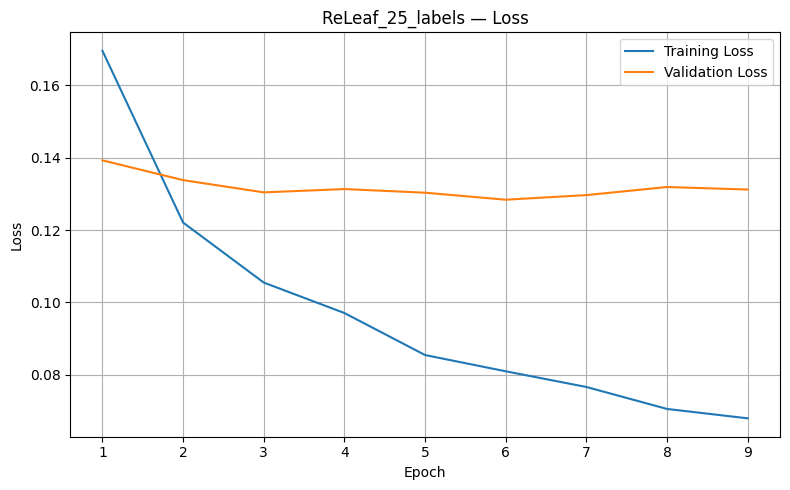

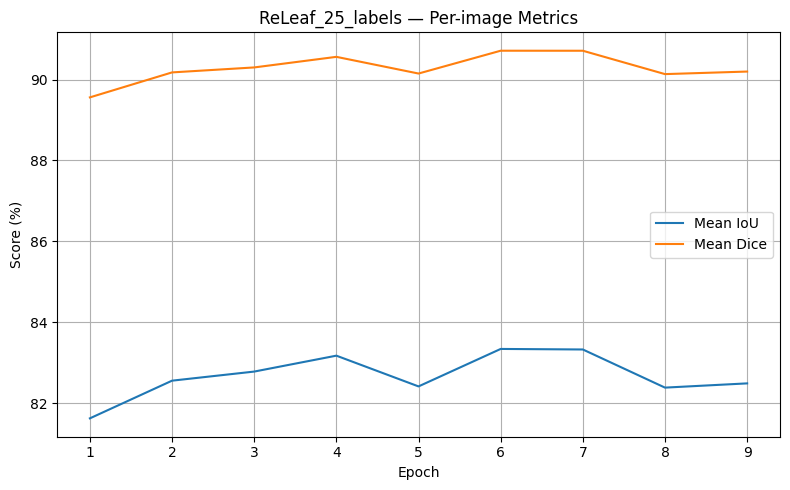


FINISHED: ReLeaf_25_labels
Training seed: 42
Best Mean IoU: 83.34%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_25_labels/best_mask_decoder.pt

################################################################################
# RELEAF — 50 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_50_labels
Training seed: 42
Training samples: 50
Validation samples: 34


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1582
Val Loss: 0.1313
Mean IoU: 82.65%
Mean Dice: 90.25%
Global IoU: 83.79%
Global Dice: 91.18%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1262
Val Loss: 0.1322
Mean IoU: 82.66%
Mean Dice: 90.23%
Global IoU: 83.92%
Global Dice: 91.25%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------

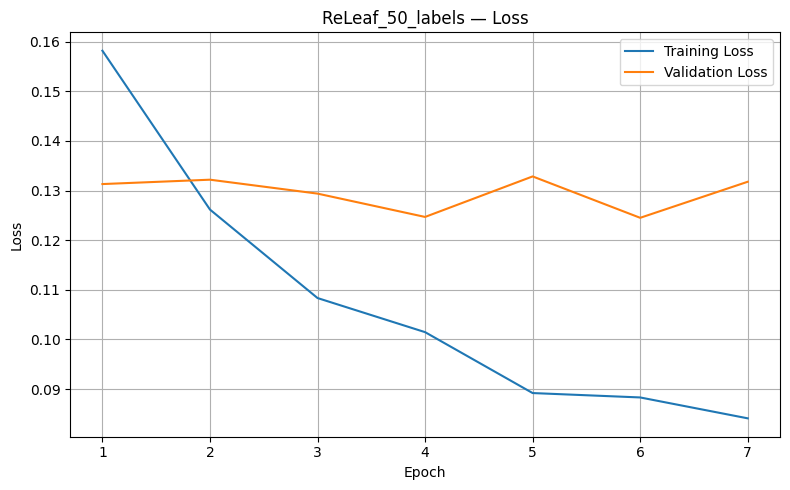

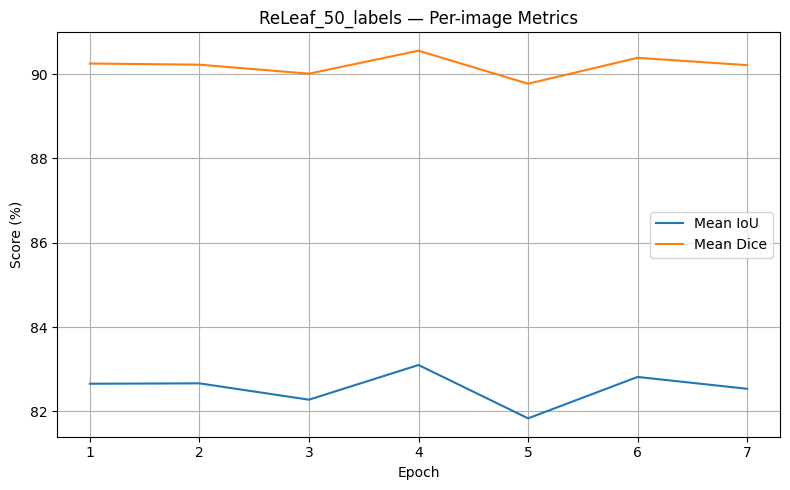

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: ReLeaf_50_labels
Training seed: 42
Best Mean IoU: 83.10%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_50_labels/best_mask_decoder.pt

################################################################################
# RELEAF — 100 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_100_labels
Training seed: 42
Training samples: 100
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/100 | Loss: 0.1405
Train Loss: 0.1405
Val Loss: 0.1239
Mean IoU: 83.62%
Mean Dice: 90.86%
Global IoU: 84.48%
Global Dice: 91.59%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_100_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/100 | Loss: 0.1125
Train Loss: 0.1125
Val Loss: 0.1251
Mean IoU: 83.00%
Mean Dice: 90.48%
Global IoU: 83.99%
Global Dice: 91.30%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Batch 

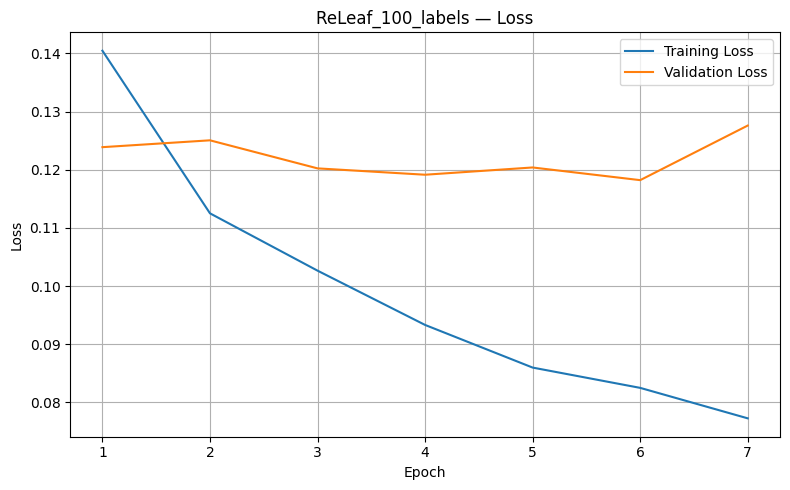

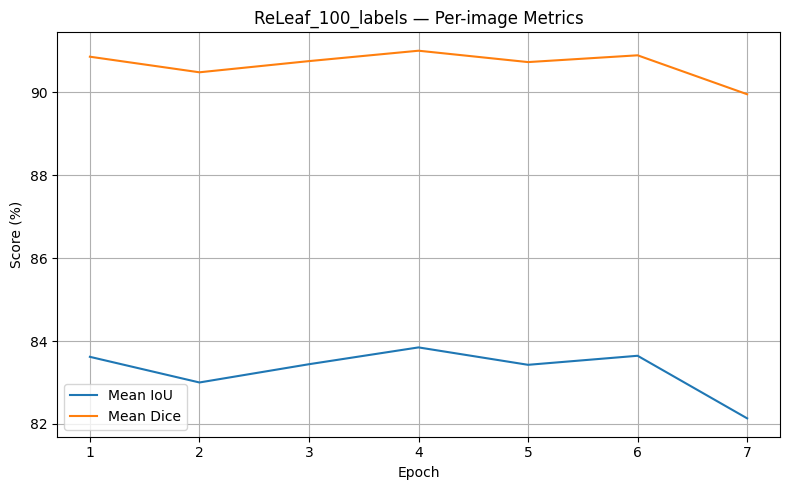

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: ReLeaf_100_labels
Training seed: 42
Best Mean IoU: 83.85%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_100_labels/best_mask_decoder.pt

################################################################################
# WEEDSGALORE — 5 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_5_labels
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1540
Val Loss: 0.1742
Mean IoU: 61.12%
Mean Dice: 75.29%
Global IoU: 69.22%
Global Dice: 81.81%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_5_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1474
Val Loss: 0.1733
Mean IoU: 61.32%
Mean Dice: 75.39%
Global IoU: 69.66%
Global Dice: 82.12%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_5_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
--------------------------------------

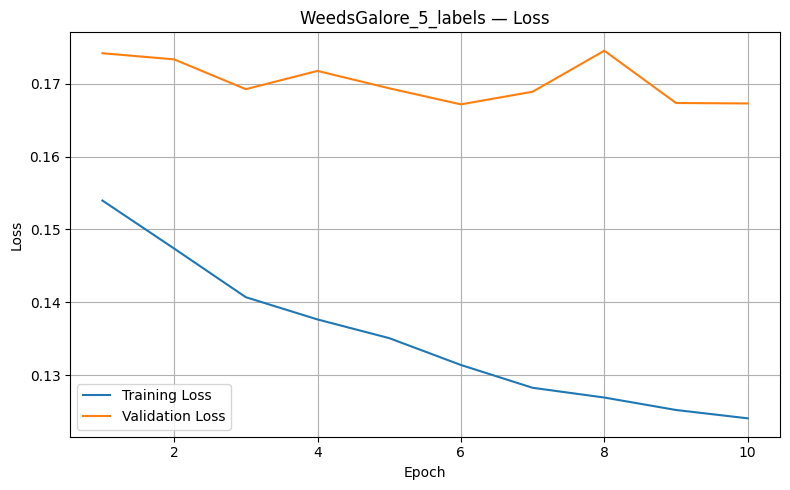

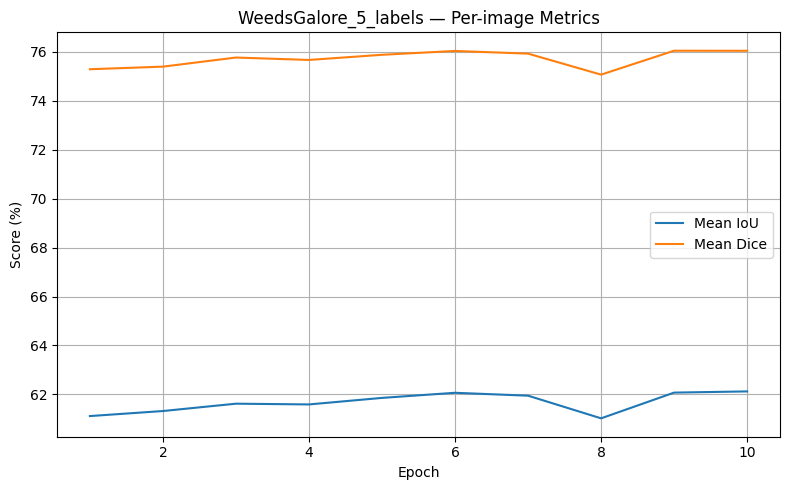

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: WeedsGalore_5_labels
Training seed: 42
Best Mean IoU: 62.12%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_5_labels/best_mask_decoder.pt

################################################################################
# WEEDSGALORE — 10 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_10_labels
Training seed: 42
Training samples: 10
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1701
Val Loss: 0.1697
Mean IoU: 61.45%
Mean Dice: 75.53%
Global IoU: 68.89%
Global Dice: 81.58%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1608
Val Loss: 0.1719
Mean IoU: 61.79%
Mean Dice: 75.64%
Global IoU: 70.05%
Global Dice: 82.39%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------

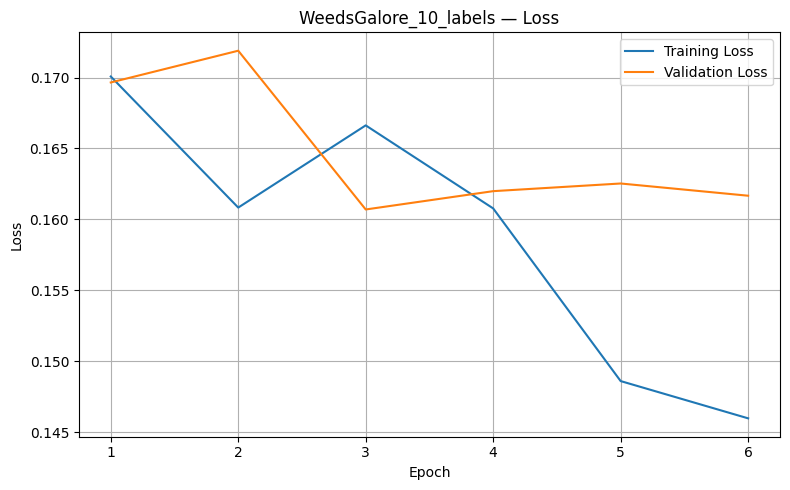

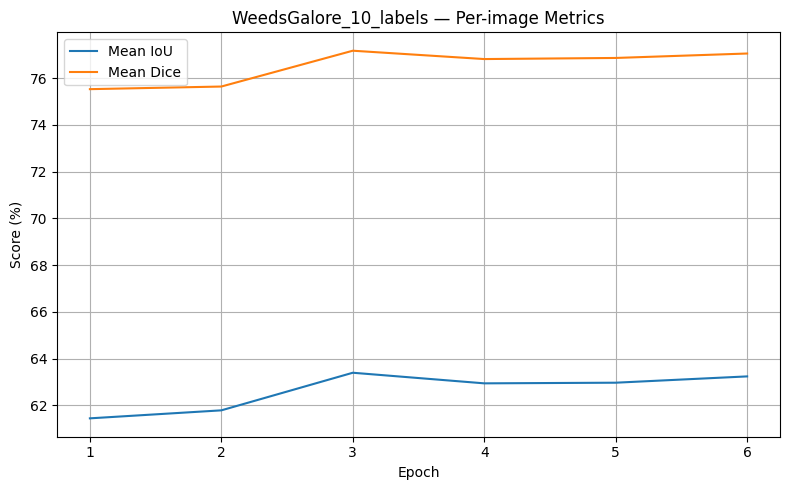

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: WeedsGalore_10_labels
Training seed: 42
Best Mean IoU: 63.40%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_10_labels/best_mask_decoder.pt

################################################################################
# WEEDSGALORE — 25 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_25_labels
Training seed: 42
Training samples: 25
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1692
Val Loss: 0.1673
Mean IoU: 62.72%
Mean Dice: 76.54%
Global IoU: 70.04%
Global Dice: 82.38%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1588
Val Loss: 0.1593
Mean IoU: 63.71%
Mean Dice: 77.44%
Global IoU: 70.19%
Global Dice: 82.49%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------

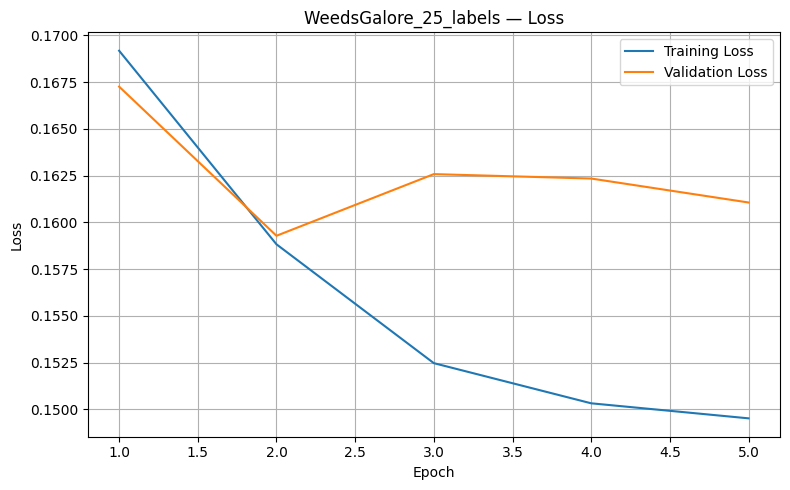

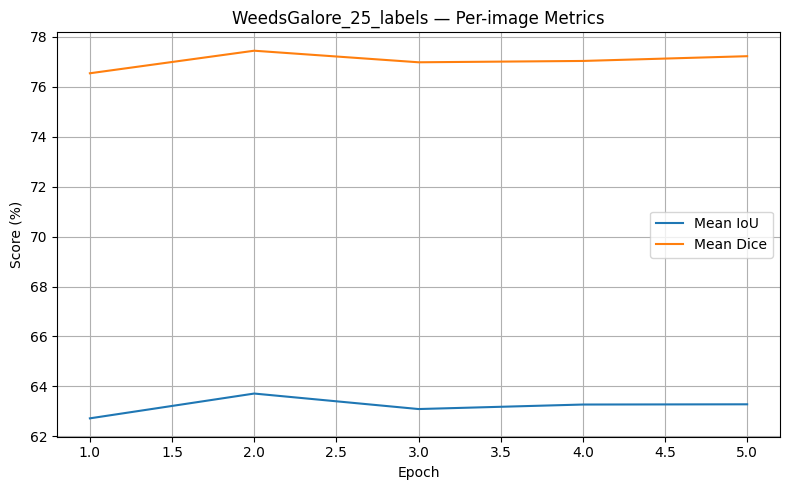

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: WeedsGalore_25_labels
Training seed: 42
Best Mean IoU: 63.71%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_25_labels/best_mask_decoder.pt

################################################################################
# WEEDSGALORE — 50 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_50_labels
Training seed: 42
Training samples: 50
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1759
Val Loss: 0.1622
Mean IoU: 63.60%
Mean Dice: 77.36%
Global IoU: 68.65%
Global Dice: 81.41%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1659
Val Loss: 0.1588
Mean IoU: 64.08%
Mean Dice: 77.76%
Global IoU: 68.57%
Global Dice: 81.35%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------

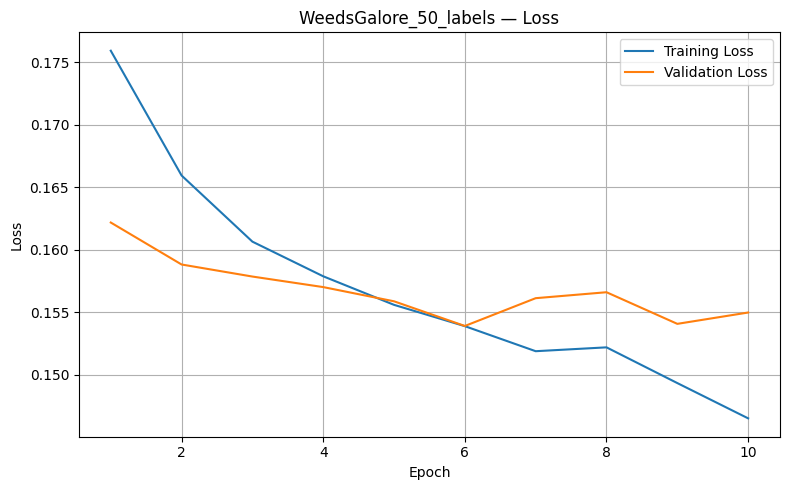

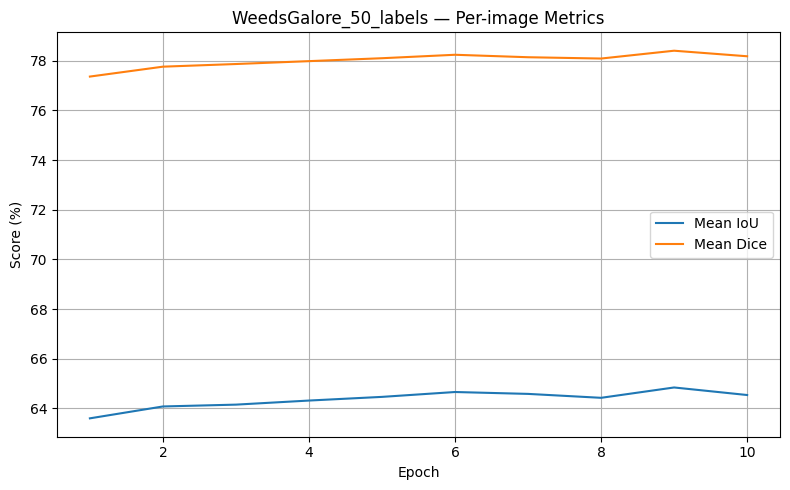

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: WeedsGalore_50_labels
Training seed: 42
Best Mean IoU: 64.85%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_50_labels/best_mask_decoder.pt

################################################################################
# WEEDSGALORE — 100 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_100_labels
Training seed: 42
Training samples: 100
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/100 | Loss: 0.1663
Train Loss: 0.1663
Val Loss: 0.1564
Mean IoU: 64.32%
Mean Dice: 77.94%
Global IoU: 69.94%
Global Dice: 82.31%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_100_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/100 | Loss: 0.1568
Train Loss: 0.1568
Val Loss: 0.1547
Mean IoU: 64.42%
Mean Dice: 78.02%
Global IoU: 69.40%
Global Dice: 81.94%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_100_labels/best_mask_decoder.pt

----------------------------------------------------------

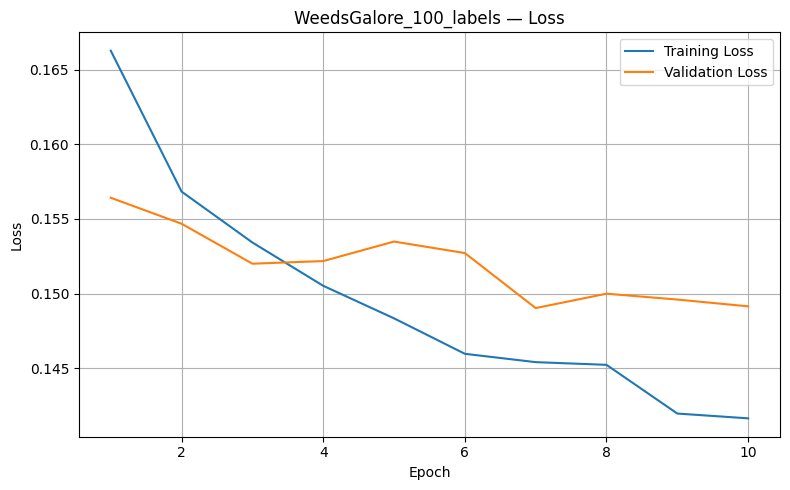

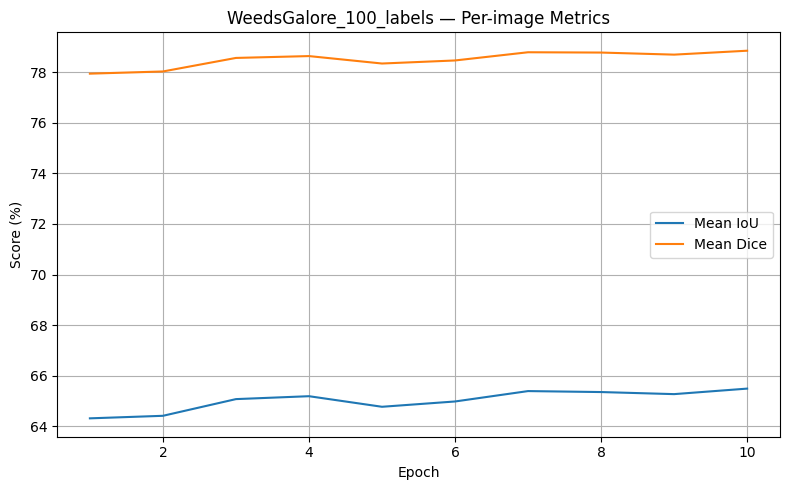

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: WeedsGalore_100_labels
Training seed: 42
Best Mean IoU: 65.49%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_100_labels/best_mask_decoder.pt

################################################################################
# EWI1S — 5 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: EWI1S_5_labels
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6649
Val Loss: 0.6058
Mean IoU: 16.80%
Mean Dice: 23.55%
Global IoU: 3.21%
Global Dice: 6.23%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_5_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5899
Val Loss: 0.4439
Mean IoU: 16.77%
Mean Dice: 23.15%
Global IoU: 12.66%
Global Dice: 22.48%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.5416
Val Loss: 0.4598
Mean IoU: 9.31%
Mean Dice: 15.06%

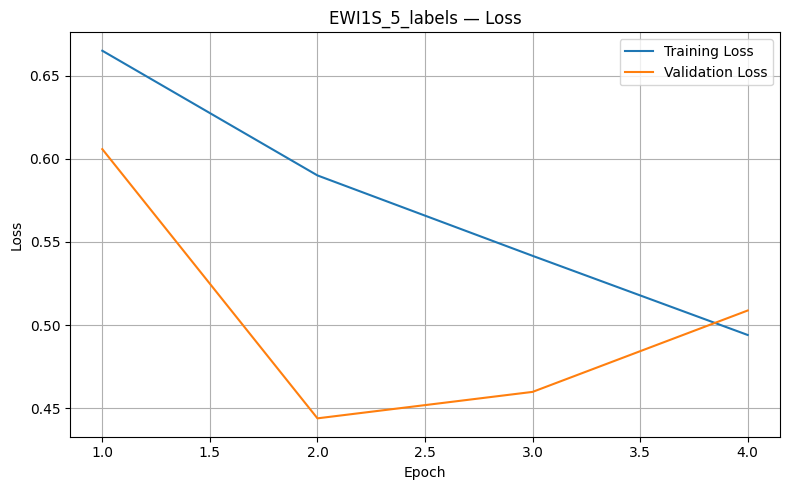

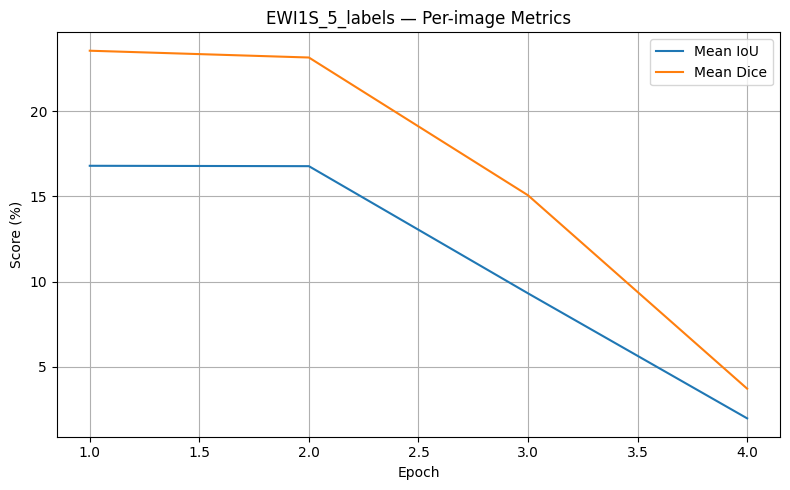

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: EWI1S_5_labels
Training seed: 42
Best Mean IoU: 16.80%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_5_labels/best_mask_decoder.pt

################################################################################
# EWI1S — 10 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: EWI1S_10_labels
Training seed: 42
Training samples: 10
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6146
Val Loss: 0.4456
Mean IoU: 14.42%
Mean Dice: 20.60%
Global IoU: 12.68%
Global Dice: 22.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5089
Val Loss: 0.4285
Mean IoU: 15.06%
Mean Dice: 21.68%
Global IoU: 12.67%
Global Dice: 22.49%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_10_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------------------

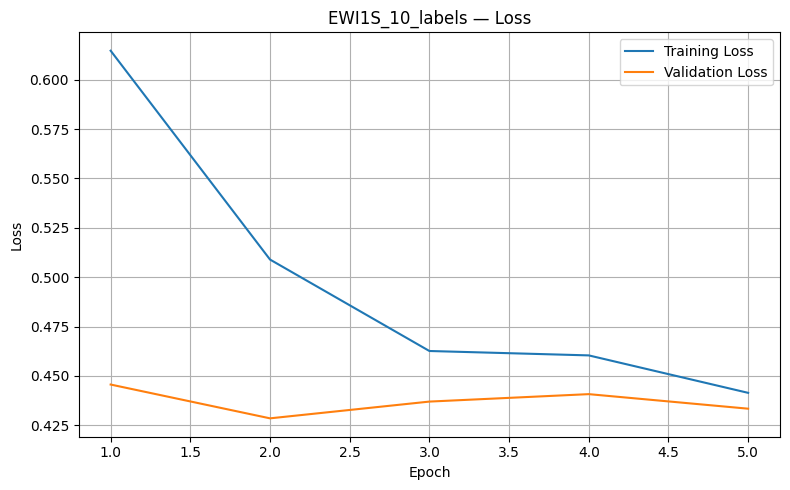

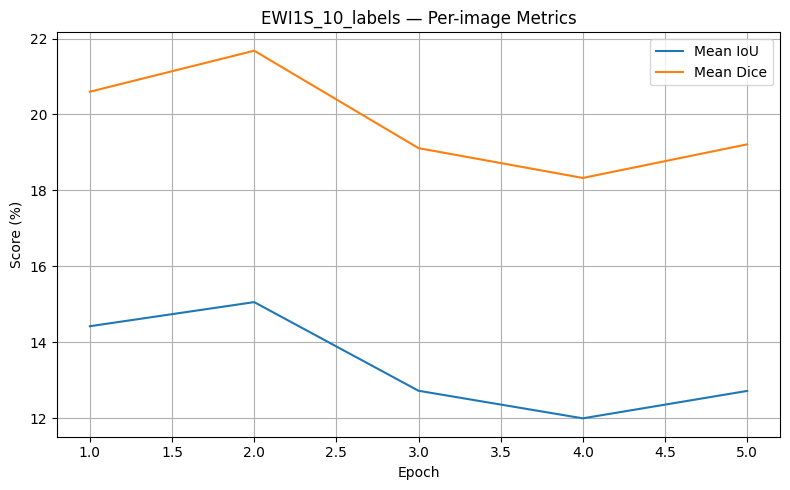

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: EWI1S_10_labels
Training seed: 42
Best Mean IoU: 15.06%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_10_labels/best_mask_decoder.pt

################################################################################
# EWI1S — 25 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: EWI1S_25_labels
Training seed: 42
Training samples: 25
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.5318
Val Loss: 0.4294
Mean IoU: 16.57%
Mean Dice: 23.63%
Global IoU: 14.13%
Global Dice: 24.77%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4192
Val Loss: 0.4134
Mean IoU: 17.56%
Mean Dice: 24.48%
Global IoU: 16.62%
Global Dice: 28.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_25_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------------------

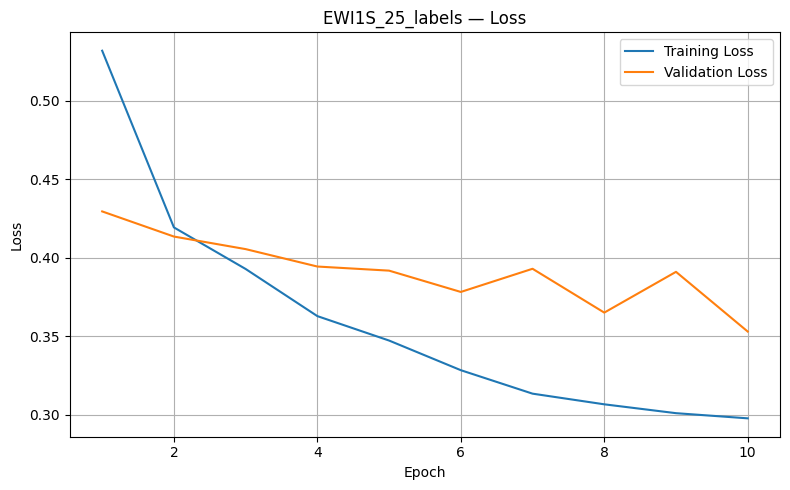

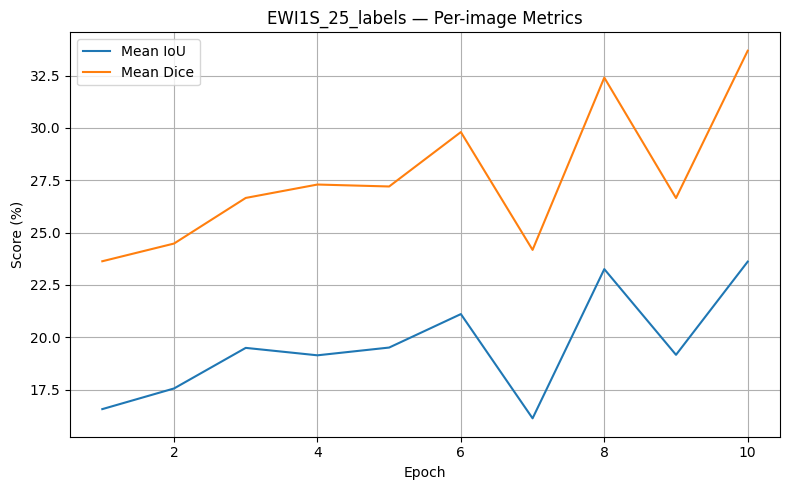

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: EWI1S_25_labels
Training seed: 42
Best Mean IoU: 23.62%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_25_labels/best_mask_decoder.pt

################################################################################
# EWI1S — 50 LABELLED IMAGES
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: EWI1S_50_labels
Training seed: 42
Training samples: 50
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4746
Val Loss: 0.4172
Mean IoU: 16.37%
Mean Dice: 23.16%
Global IoU: 14.87%
Global Dice: 25.88%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4024
Val Loss: 0.4000
Mean IoU: 19.22%
Mean Dice: 26.47%
Global IoU: 18.24%
Global Dice: 30.85%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_50_labels/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------------------

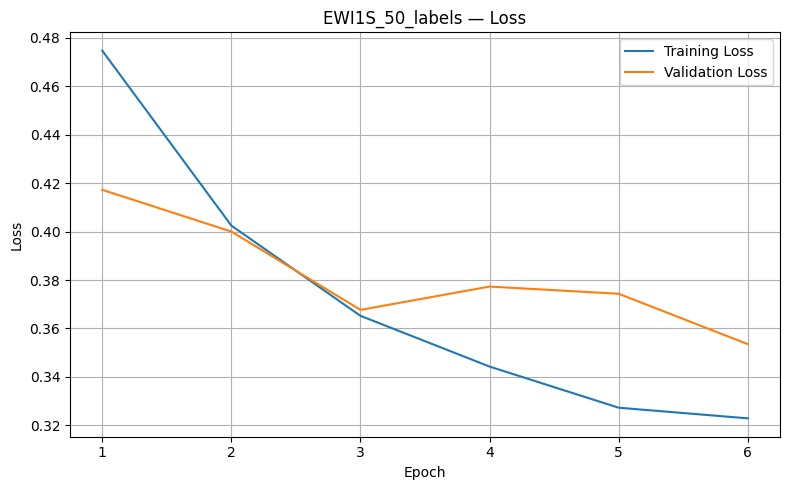

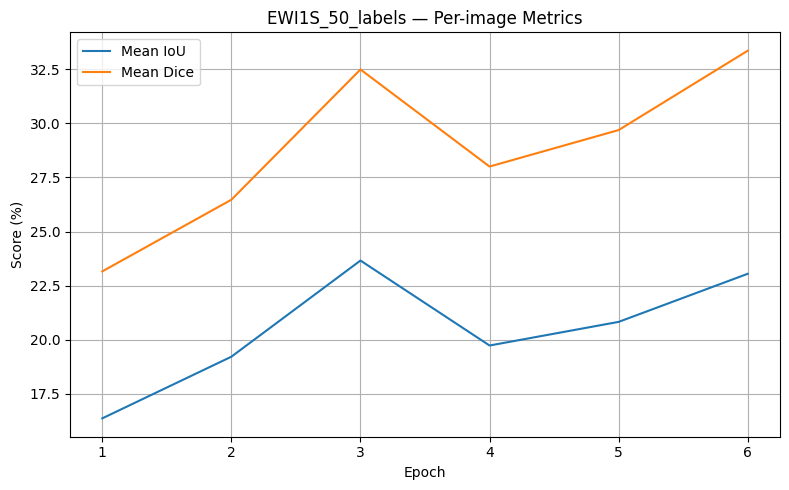


FINISHED: EWI1S_50_labels
Training seed: 42
Best Mean IoU: 23.66%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_50_labels/best_mask_decoder.pt

ALL LABEL-EFFICIENCY EXPERIMENTS COMPLETED
Total experiments: 14


In [58]:
# ============================================================
# RUN ALL TARGET-DOMAIN LABEL-EFFICIENCY EXPERIMENTS
# ============================================================

ALL_LABEL_SIZES = [5, 10, 25, 50, 100]

label_efficiency_results = {}

# ============================================================
# RELEAF
# ============================================================

for size in ALL_LABEL_SIZES:

    print("\n" + "#" * 80)
    print(f"# RELEAF — {size} LABELLED IMAGES")
    print("#" * 80)

    result = run_finetuning_experiment(
        experiment_name=f"ReLeaf_{size}_labels",
        train_dataset=releaf_labelled_datasets[size],
        val_dataset=releaf_val_dataset,
        num_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        patience=EARLY_STOPPING_PATIENCE
    )

    label_efficiency_results[
        f"ReLeaf_{size}"
    ] = result


# ============================================================
# WEEDSGALORE
# ============================================================

for size in ALL_LABEL_SIZES:

    print("\n" + "#" * 80)
    print(f"# WEEDSGALORE — {size} LABELLED IMAGES")
    print("#" * 80)

    result = run_finetuning_experiment(
        experiment_name=f"WeedsGalore_{size}_labels",
        train_dataset=weedsgalore_labelled_datasets[size],
        val_dataset=weedsgalore_val_dataset,
        num_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        patience=EARLY_STOPPING_PATIENCE
    )

    label_efficiency_results[
        f"WeedsGalore_{size}"
    ] = result


# ============================================================
# EWI1S
# ============================================================

for size in [5, 10, 25, 50]:

    print("\n" + "#" * 80)
    print(f"# EWI1S — {size} LABELLED IMAGES")
    print("#" * 80)

    result = run_finetuning_experiment(
        experiment_name=f"EWI1S_{size}_labels",
        train_dataset=ewis1_labelled_datasets[size],
        val_dataset=ewis1_val_dataset,
        num_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        patience=EARLY_STOPPING_PATIENCE
    )

    label_efficiency_results[
        f"EWI1S_{size}"
    ] = result


print("\n" + "=" * 80)
print("ALL LABEL-EFFICIENCY EXPERIMENTS COMPLETED")
print("=" * 80)

print("Total experiments:", len(label_efficiency_results))

In [59]:
# ============================================================
# CHECK POINT 6 EXPERIMENT RESULTS
# ============================================================

print("Total Point 6 runs:", len(point6_results))

for name, result in point6_results.items():

    print(
        f"{name:65s} "
        f"Best Val IoU = {result['best_mean_iou'] * 100:.2f}%"
    )

Total Point 6 runs: 30
Point6_ReLeaf_5labels_subset42_trainseed42                        Best Val IoU = 82.17%
Point6_ReLeaf_5labels_subset42_trainseed123                       Best Val IoU = 82.24%
Point6_ReLeaf_5labels_subset123_trainseed42                       Best Val IoU = 81.43%
Point6_ReLeaf_5labels_subset123_trainseed123                      Best Val IoU = 81.34%
Point6_ReLeaf_5labels_subset2026_trainseed42                      Best Val IoU = 82.24%
Point6_ReLeaf_5labels_subset2026_trainseed123                     Best Val IoU = 82.21%
Point6_ReLeaf_5labels_subset77_trainseed42                        Best Val IoU = 81.47%
Point6_ReLeaf_5labels_subset77_trainseed123                       Best Val IoU = 81.34%
Point6_ReLeaf_5labels_subset314_trainseed42                       Best Val IoU = 81.72%
Point6_ReLeaf_5labels_subset314_trainseed123                      Best Val IoU = 81.48%
Point6_WeedsGalore_5labels_subset42_trainseed42                   Best Val IoU = 62.08%
Point6_We

In [60]:
# ============================================================
# LABEL-EFFICIENCY CHECKPOINTS
# ============================================================

LABEL_EFFICIENCY_CHECKPOINTS = {
    "ReLeaf_5": DOMAIN_FT_ROOT / "ReLeaf_5_labels" / "best_mask_decoder.pt",
    "ReLeaf_10": DOMAIN_FT_ROOT / "ReLeaf_10_labels" / "best_mask_decoder.pt",
    "ReLeaf_25": DOMAIN_FT_ROOT / "ReLeaf_25_labels" / "best_mask_decoder.pt",
    "ReLeaf_50": DOMAIN_FT_ROOT / "ReLeaf_50_labels" / "best_mask_decoder.pt",
    "ReLeaf_100": DOMAIN_FT_ROOT / "ReLeaf_100_labels" / "best_mask_decoder.pt",

    "WeedsGalore_5": DOMAIN_FT_ROOT / "WeedsGalore_5_labels" / "best_mask_decoder.pt",
    "WeedsGalore_10": DOMAIN_FT_ROOT / "WeedsGalore_10_labels" / "best_mask_decoder.pt",
    "WeedsGalore_25": DOMAIN_FT_ROOT / "WeedsGalore_25_labels" / "best_mask_decoder.pt",
    "WeedsGalore_50": DOMAIN_FT_ROOT / "WeedsGalore_50_labels" / "best_mask_decoder.pt",
    "WeedsGalore_100": DOMAIN_FT_ROOT / "WeedsGalore_100_labels" / "best_mask_decoder.pt",

    "EWI1S_5": DOMAIN_FT_ROOT / "EWI1S_5_labels" / "best_mask_decoder.pt",
    "EWI1S_10": DOMAIN_FT_ROOT / "EWI1S_10_labels" / "best_mask_decoder.pt",
    "EWI1S_25": DOMAIN_FT_ROOT / "EWI1S_25_labels" / "best_mask_decoder.pt",
    "EWI1S_50": DOMAIN_FT_ROOT / "EWI1S_50_labels" / "best_mask_decoder.pt",
}

print("=" * 70)
print("LABEL-EFFICIENCY CHECKPOINTS")
print("=" * 70)

for name, path in LABEL_EFFICIENCY_CHECKPOINTS.items():
    print(f"{name:25s} | Exists: {path.exists()} | {path}")

print(f"\nTotal checkpoints: {len(LABEL_EFFICIENCY_CHECKPOINTS)}")

LABEL-EFFICIENCY CHECKPOINTS
ReLeaf_5                  | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_5_labels/best_mask_decoder.pt
ReLeaf_10                 | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_10_labels/best_mask_decoder.pt
ReLeaf_25                 | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_25_labels/best_mask_decoder.pt
ReLeaf_50                 | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_50_labels/best_mask_decoder.pt
ReLeaf_100                | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_100_labels/best_mask_decoder.pt
WeedsGalore_5             | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_5_labels/best_mask_decoder.pt
WeedsGalore_10            | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_10_labels/best_mask_decoder.pt
WeedsGalore_25            | Exists: True | /home/zahranadee

In [61]:
# ============================================================
# FIXED TEST DATASETS
# ============================================================

releaf_test_dataset = UnifiedSegmentationDataset(
    records=releaf_test_pairs,
    dataset_name="ReLeaf",
    jitter=False
)

weedsgalore_test_dataset = UnifiedSegmentationDataset(
    records=weedsgalore_test_pairs,
    dataset_name="WeedsGalore",
    jitter=False
)

ewis1_test_dataset = UnifiedSegmentationDataset(
    records=ewis1_test_pairs,
    dataset_name="EWI1S",
    jitter=False
)

print("=" * 70)
print("FIXED TEST SETS")
print("=" * 70)

print(f"ReLeaf       test images: {len(releaf_test_dataset)}")
print(f"WeedsGalore  test images: {len(weedsgalore_test_dataset)}")
print(f"EWI1S        test images: {len(ewis1_test_dataset)}")

FIXED TEST SETS
ReLeaf       test images: 35
WeedsGalore  test images: 17
EWI1S        test images: 10


In [62]:
# ============================================================
# LOAD A FINE-TUNED DECODER CHECKPOINT
# ============================================================

def load_label_efficiency_model(checkpoint_path):
    """
    Creates a fresh pretrained SAM2 model and loads
    the fine-tuned mask decoder checkpoint.
    """

    model = Sam2Model.from_pretrained(MODEL_NAME)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict) and "mask_decoder_state_dict" in checkpoint:
        decoder_state = checkpoint["mask_decoder_state_dict"]
    elif isinstance(checkpoint, dict):
        decoder_state = checkpoint
    else:
        raise TypeError(
            f"Unsupported checkpoint structure: {type(checkpoint)}"
        )

    model.mask_decoder.load_state_dict(
        decoder_state,
        strict=True
    )

    # Freeze everything
    for parameter in model.parameters():
        parameter.requires_grad = False

    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint

In [63]:
# ============================================================
# SANITY CHECK: TEST ONE CHECKPOINT
# ============================================================

test_model, test_checkpoint = load_label_efficiency_model(
    LABEL_EFFICIENCY_CHECKPOINTS["ReLeaf_100"]
)

print("Checkpoint loaded successfully.")
print("Experiment:", test_checkpoint.get("experiment_name", "N/A"))
print("Training samples:", test_checkpoint.get("train_samples", "N/A"))
print("Best validation IoU:",
      test_checkpoint.get("best_mean_iou", "N/A"))
print("Best epoch:",
      test_checkpoint.get("epoch", "N/A"))

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Checkpoint loaded successfully.
Experiment: ReLeaf_100_labels
Training samples: 100
Best validation IoU: 0.8384556244401371
Best epoch: 4


In [64]:
# ============================================================
# TEST-SET EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_test_checkpoint(
    model,
    dataset,
    dataset_name,
    checkpoint_name
):
    """
    Evaluate one fine-tuned SAM2 checkpoint on a fixed test set.

    Uses the ground-truth bounding box because this experiment
    measures target-domain decoder adaptation rather than
    AgriCLIP box-generation quality.
    """

    iou_scores = []
    dice_scores = []
    precision_scores = []
    recall_scores = []
    confidence_scores = []

    for idx in range(len(dataset)):

        sample = dataset[idx]

        image = sample["image"]
        gt_mask = np.asarray(sample["mask"]).astype(np.uint8)
        gt_box = np.asarray(sample["gt_box"]).reshape(-1)

        # ----------------------------------------------------
        # SAM2 prediction
        # ----------------------------------------------------

        input_box = gt_box.tolist()

        processor_inputs = sam2_processor(
            image,
            input_boxes=[[input_box]],
            return_tensors="pt"
        )

        processor_inputs = {
            k: v.to(model.device) if torch.is_tensor(v) else v
            for k, v in processor_inputs.items()
        }

        outputs = model(
            **processor_inputs,
            multimask_output=False
        )

        # ----------------------------------------------------
        # Extract predicted mask
        # ----------------------------------------------------

        logits = outputs.pred_masks[0, 0, 0]

        probability = torch.sigmoid(logits)

        height = int(
            processor_inputs["original_sizes"][0, 0].item()
        )
        width = int(
            processor_inputs["original_sizes"][0, 1].item()
        )

        probability = F.interpolate(
            probability[None, None],
            size=(height, width),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        pred_mask = (
            probability >= 0.5
        ).cpu().numpy().astype(np.uint8)

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        intersection = np.logical_and(
            pred_mask == 1,
            gt_mask == 1
        ).sum()

        union = np.logical_or(
            pred_mask == 1,
            gt_mask == 1
        ).sum()

        pred_area = (pred_mask == 1).sum()
        gt_area = (gt_mask == 1).sum()

        # IoU
        if union > 0:
            iou = intersection / union
        else:
            iou = 1.0 if gt_area == 0 else 0.0

        # Dice
        denominator = pred_area + gt_area

        if denominator > 0:
            dice = (2 * intersection) / denominator
        else:
            dice = 1.0

        # Precision
        if pred_area > 0:
            precision = intersection / pred_area
        else:
            precision = 0.0

        # Recall
        if gt_area > 0:
            recall = intersection / gt_area
        else:
            recall = 0.0

        # SAM2 confidence
        confidence = float(
            outputs.iou_scores[0, 0, 0]
            .detach()
            .cpu()
            .item()
        )

        iou_scores.append(iou)
        dice_scores.append(dice)
        precision_scores.append(precision)
        recall_scores.append(recall)
        confidence_scores.append(confidence)

    # --------------------------------------------------------
    # Aggregate
    # --------------------------------------------------------

    return {
        "checkpoint": checkpoint_name,
        "dataset": dataset_name,
        "images": len(dataset),

        "mean_iou": np.mean(iou_scores),
        "mean_dice": np.mean(dice_scores),
        "mean_precision": np.mean(precision_scores),
        "mean_recall": np.mean(recall_scores),
        "mean_confidence": np.mean(confidence_scores),

        "std_iou": np.std(iou_scores),
        "std_dice": np.std(dice_scores),

        "min_iou": np.min(iou_scores),
        "max_iou": np.max(iou_scores),
    }

In [65]:
# ============================================================
# SAM2 PROCESSOR ALIAS
# ============================================================

if "sam2_processor" not in globals():

    if "processor" in globals():
        sam2_processor = processor
        print("Using existing `processor` as `sam2_processor`.")

    else:
        from transformers import Sam2Processor

        sam2_processor = Sam2Processor.from_pretrained(
            MODEL_NAME
        )

        print("Created new SAM2 processor.")
        
print("SAM2 processor:", type(sam2_processor))

Using existing `processor` as `sam2_processor`.
SAM2 processor: <class 'transformers.models.sam2.processing_sam2.Sam2Processor'>


In [66]:
# ============================================================
# SANITY CHECK EVALUATION
# ============================================================

releaf_100_test_result = evaluate_test_checkpoint(
    model=test_model,
    dataset=releaf_test_dataset,
    dataset_name="ReLeaf",
    checkpoint_name="ReLeaf_100"
)

print("=" * 70)
print("ReLeaf_100 TEST RESULTS")
print("=" * 70)

print(f"Test images:      {releaf_100_test_result['images']}")
print(f"Mean IoU:         {releaf_100_test_result['mean_iou'] * 100:.2f}%")
print(f"Mean Dice:        {releaf_100_test_result['mean_dice'] * 100:.2f}%")
print(f"Mean Precision:   {releaf_100_test_result['mean_precision'] * 100:.2f}%")
print(f"Mean Recall:      {releaf_100_test_result['mean_recall'] * 100:.2f}%")
print(f"Mean Confidence:  {releaf_100_test_result['mean_confidence']:.4f}")

ReLeaf_100 TEST RESULTS
Test images:      35
Mean IoU:         77.44%
Mean Dice:        86.64%
Mean Precision:   85.51%
Mean Recall:      88.34%
Mean Confidence:  0.9527


In [67]:
# ============================================================
# EVALUATE ALL 14 LABEL-EFFICIENCY CHECKPOINTS
# ============================================================

TEST_DATASETS = {
    "ReLeaf": releaf_test_dataset,
    "WeedsGalore": weedsgalore_test_dataset,
    "EWI1S": ewis1_test_dataset,
}

label_efficiency_test_results = []

for experiment_name, checkpoint_path in LABEL_EFFICIENCY_CHECKPOINTS.items():

    # --------------------------------------------------------
    # Determine domain
    # --------------------------------------------------------

    if experiment_name.startswith("ReLeaf"):
        dataset_name = "ReLeaf"

    elif experiment_name.startswith("WeedsGalore"):
        dataset_name = "WeedsGalore"

    elif experiment_name.startswith("EWI1S"):
        dataset_name = "EWI1S"

    else:
        raise ValueError(
            f"Unknown experiment: {experiment_name}"
        )

    test_dataset = TEST_DATASETS[dataset_name]

    print("\n" + "=" * 70)
    print(f"TESTING: {experiment_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------

    model, checkpoint = load_label_efficiency_model(
        checkpoint_path
    )

    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------

    result = evaluate_test_checkpoint(
        model=model,
        dataset=test_dataset,
        dataset_name=dataset_name,
        checkpoint_name=experiment_name
    )

    # Add number of labelled training images
    label_count = int(
        experiment_name.split("_")[-1]
    )

    result["labelled_images"] = label_count
    result["best_val_iou"] = checkpoint.get(
        "best_mean_iou",
        np.nan
    )
    result["best_epoch"] = checkpoint.get(
        "epoch",
        np.nan
    )

    label_efficiency_test_results.append(result)

    print(
        f"Test Mean IoU: "
        f"{result['mean_iou'] * 100:.2f}%"
    )

    print(
        f"Test Mean Dice: "
        f"{result['mean_dice'] * 100:.2f}%"
    )

    print(
        f"Best Val IoU: "
        f"{result['best_val_iou'] * 100:.2f}%"
    )

    # --------------------------------------------------------
    # Free GPU memory
    # --------------------------------------------------------

    del model
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("ALL 14 TEST EVALUATIONS COMPLETE")
print("=" * 70)

print(
    f"Number of experiments evaluated: "
    f"{len(label_efficiency_test_results)}"
)


TESTING: ReLeaf_5


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test Mean IoU: 75.53%
Test Mean Dice: 85.37%
Best Val IoU: 82.22%

TESTING: ReLeaf_10


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

... (33 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test Mean IoU: 23.23%
Test Mean Dice: 36.42%
Best Val IoU: 23.62%

TESTING: EWI1S_50


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Test Mean IoU: 26.89%
Test Mean Dice: 40.54%
Best Val IoU: 23.66%

ALL 14 TEST EVALUATIONS COMPLETE
Number of experiments evaluated: 14


In [68]:
# ============================================================
# PRINT ALL 14 LABEL-EFFICIENCY RESULTS
# ============================================================

import pandas as pd

results_df = pd.DataFrame(label_efficiency_test_results)

# ------------------------------------------------------------
# Organize columns
# ------------------------------------------------------------

results_df = results_df[
    [
        "checkpoint",
        "dataset",
        "labelled_images",
        "images",
        "best_val_iou",
        "best_epoch",
        "mean_iou",
        "mean_dice",
        "mean_precision",
        "mean_recall",
        "mean_confidence",
        "std_iou",
        "min_iou",
        "max_iou",
    ]
].copy()

# ------------------------------------------------------------
# Convert main metrics to percentages
# ------------------------------------------------------------

for column in [
    "best_val_iou",
    "mean_iou",
    "mean_dice",
    "mean_precision",
    "mean_recall",
    "std_iou",
    "min_iou",
    "max_iou",
]:
    results_df[column] *= 100

# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

domain_order = {
    "ReLeaf": 1,
    "WeedsGalore": 2,
    "EWI1S": 3,
}

results_df["domain_order"] = results_df["dataset"].map(domain_order)

results_df = results_df.sort_values(
    ["domain_order", "labelled_images"]
).drop(columns=["domain_order"])

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(
    results_df.style
    .format({
        "best_val_iou": "{:.2f}%",
        "mean_iou": "{:.2f}%",
        "mean_dice": "{:.2f}%",
        "mean_precision": "{:.2f}%",
        "mean_recall": "{:.2f}%",
        "mean_confidence": "{:.4f}",
        "std_iou": "{:.2f}%",
        "min_iou": "{:.2f}%",
        "max_iou": "{:.2f}%",
    })
)

,checkpoint,dataset,labelled_images,images,best_val_iou,best_epoch,mean_iou,mean_dice,mean_precision,mean_recall,mean_confidence,std_iou,min_iou,max_iou
0,ReLeaf_5,ReLeaf,5,35,82.22%,10,75.53%,85.37%,84.22%,87.31%,0.9444,12.97%,34.16%,94.16%
1,ReLeaf_10,ReLeaf,10,35,82.71%,7,75.26%,85.17%,83.85%,87.43%,0.9430,13.12%,33.86%,94.14%
2,ReLeaf_25,ReLeaf,25,35,83.34%,6,75.93%,85.60%,85.06%,86.73%,0.9568,13.16%,31.94%,94.27%
3,ReLeaf_50,ReLeaf,50,35,83.10%,4,75.84%,85.53%,85.89%,85.89%,0.9588,13.25%,31.24%,94.35%
4,ReLeaf_100,ReLeaf,100,35,83.85%,4,77.44%,86.64%,85.51%,88.34%,0.9527,12.65%,35.88%,94.45%
5,WeedsGalore_5,WeedsGalore,5,17,62.12%,10,57.24%,71.88%,72.35%,72.31%,0.8773,13.62%,41.10%,82.65%
6,WeedsGalore_10,WeedsGalore,10,17,63.40%,3,58.96%,73.38%,75.95%,71.95%,0.8732,12.81%,41.35%,82.38%
7,WeedsGalore_25,WeedsGalore,25,17,63.71%,2,58.73%,73.15%,75.49%,71.80%,0.8822,13.18%,40.09%,82.37%
8,WeedsGalore_50,WeedsGalore,50,17,64.85%,9,59.54%,73.87%,78.46%,70.74%,0.8847,12.57%,42.34%,82.87%
9,WeedsGalore_100,WeedsGalore,100,17,65.49%,10,59.77%,74.02%,77.36%,72.25%,0.9079,12.85%,42.37%,83.30%


In [69]:
# ============================================================
# THESIS-READY LABEL-EFFICIENCY TABLE
# ============================================================

thesis_label_table = results_df[
    [
        "dataset",
        "labelled_images",
        "images",
        "best_val_iou",
        "mean_iou",
        "mean_dice",
        "mean_precision",
        "mean_recall",
    ]
].copy()

thesis_label_table = thesis_label_table.rename(
    columns={
        "dataset": "Target Domain",
        "labelled_images": "Labelled Images",
        "images": "Test Images",
        "best_val_iou": "Best Val IoU (%)",
        "mean_iou": "Test IoU (%)",
        "mean_dice": "Test Dice (%)",
        "mean_precision": "Test Precision (%)",
        "mean_recall": "Test Recall (%)",
    }
)

display(
    thesis_label_table.style.format({
        "Best Val IoU (%)": "{:.2f}",
        "Test IoU (%)": "{:.2f}",
        "Test Dice (%)": "{:.2f}",
        "Test Precision (%)": "{:.2f}",
        "Test Recall (%)": "{:.2f}",
    })
)

,Target Domain,Labelled Images,Test Images,Best Val IoU (%),Test IoU (%),Test Dice (%),Test Precision (%),Test Recall (%)
0,ReLeaf,5,35,82.22,75.53,85.37,84.22,87.31
1,ReLeaf,10,35,82.71,75.26,85.17,83.85,87.43
2,ReLeaf,25,35,83.34,75.93,85.60,85.06,86.73
3,ReLeaf,50,35,83.10,75.84,85.53,85.89,85.89
4,ReLeaf,100,35,83.85,77.44,86.64,85.51,88.34
5,WeedsGalore,5,17,62.12,57.24,71.88,72.35,72.31
6,WeedsGalore,10,17,63.40,58.96,73.38,75.95,71.95
7,WeedsGalore,25,17,63.71,58.73,73.15,75.49,71.80
8,WeedsGalore,50,17,64.85,59.54,73.87,78.46,70.74
9,WeedsGalore,100,17,65.49,59.77,74.02,77.36,72.25


In [70]:
# ============================================================
# FULL-DATA TARGET DOMAIN DATASETS
# ============================================================

# ReLeaf: all 276 training images
releaf_full_train_dataset = UnifiedSegmentationDataset(
    records=releaf_train_pairs,
    dataset_name="ReLeaf",
    jitter=True
)

# WeedsGalore: all 124 training images
weedsgalore_full_train_dataset = UnifiedSegmentationDataset(
    records=weedsgalore_train_pairs,
    dataset_name="WeedsGalore",
    jitter=True
)

# EWI1S: all 70 training images
ewis1_full_train_dataset = UnifiedSegmentationDataset(
    records=ewis1_train_pairs,
    dataset_name="EWI1S",
    jitter=True
)

print("=" * 70)
print("FULL-DATA TRAINING SETS")
print("=" * 70)

print(f"ReLeaf       : {len(releaf_full_train_dataset)} images")
print(f"WeedsGalore  : {len(weedsgalore_full_train_dataset)} images")
print(f"EWI1S        : {len(ewis1_full_train_dataset)} images")

FULL-DATA TRAINING SETS
ReLeaf       : 276 images
WeedsGalore  : 124 images
EWI1S        : 70 images


In [71]:
# ============================================================
# CONFIRM FIXED VALIDATION SETS
# ============================================================

print("=" * 70)
print("VALIDATION SETS")
print("=" * 70)

print(f"ReLeaf       validation: {len(releaf_val_dataset)}")
print(f"WeedsGalore  validation: {len(weedsgalore_val_dataset)}")
print(f"EWI1S        validation: {len(ewis1_val_dataset)}")

VALIDATION SETS
ReLeaf       validation: 34
WeedsGalore  validation: 15
EWI1S        validation: 8


Training seed set to: 42

STARTING EXPERIMENT: ReLeaf_Full
Training seed: 42
Training samples: 276
Validation samples: 34


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1435
Batch 200/276 | Loss: 0.1286
Train Loss: 0.1239
Val Loss: 0.1283
Mean IoU: 83.84%
Mean Dice: 90.92%
Global IoU: 84.92%
Global Dice: 91.84%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_Full/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1000
Batch 200/276 | Loss: 0.1021
Train Loss: 0.1042
Val Loss: 0.1225
Mean IoU: 83.53%
Mean Dice: 90.73%
Global IoU: 84.45%
Global Dice: 91.57%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
-------------------------

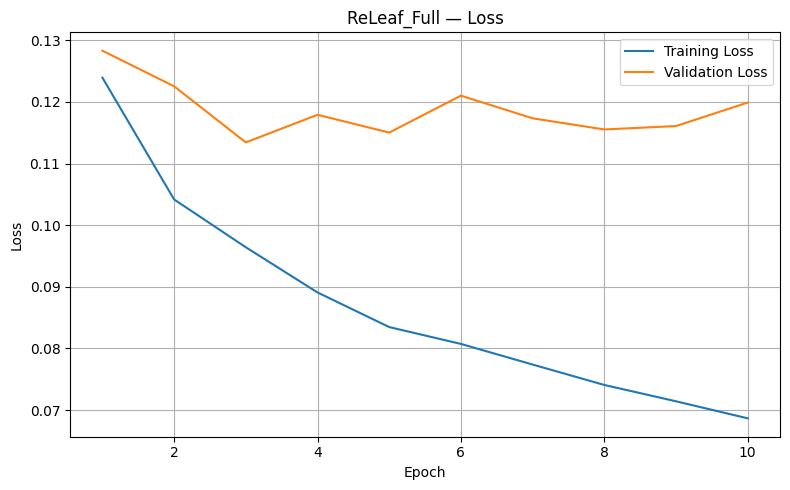

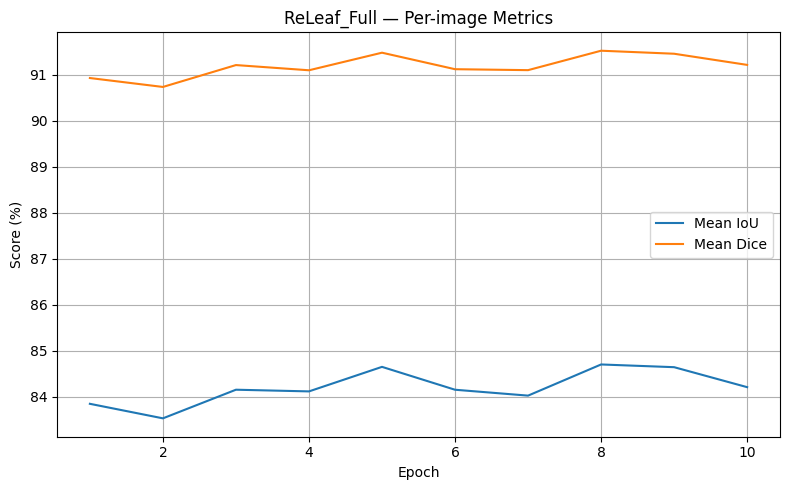


FINISHED: ReLeaf_Full
Training seed: 42
Best Mean IoU: 84.70%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_Full/best_mask_decoder.pt

RELEAF FULL-DATA TRAINING COMPLETE
Best validation IoU: 84.70%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_Full/best_mask_decoder.pt


In [72]:
# ============================================================
# FULL-DATA RELEAF FINE-TUNING
# ============================================================

releaf_full_result = run_finetuning_experiment(
    experiment_name="ReLeaf_Full",
    train_dataset=releaf_full_train_dataset,
    val_dataset=releaf_val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE
)

print("\n" + "=" * 70)
print("RELEAF FULL-DATA TRAINING COMPLETE")
print("=" * 70)

print(f"Best validation IoU: "
      f"{releaf_full_result['best_mean_iou'] * 100:.2f}%")

print(f"Checkpoint: "
      f"{releaf_full_result['checkpoint']}")

Training seed set to: 42

STARTING EXPERIMENT: WeedsGalore_Full
Training seed: 42
Training samples: 124
Validation samples: 15


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1677
Train Loss: 0.1666
Val Loss: 0.1566
Mean IoU: 64.12%
Mean Dice: 77.80%
Global IoU: 68.47%
Global Dice: 81.29%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_Full/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1602
Train Loss: 0.1582
Val Loss: 0.1542
Mean IoU: 64.71%
Mean Dice: 78.27%
Global IoU: 69.28%
Global Dice: 81.85%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_Full/best_mask_decoder.pt

----------------------------------------------------------------------

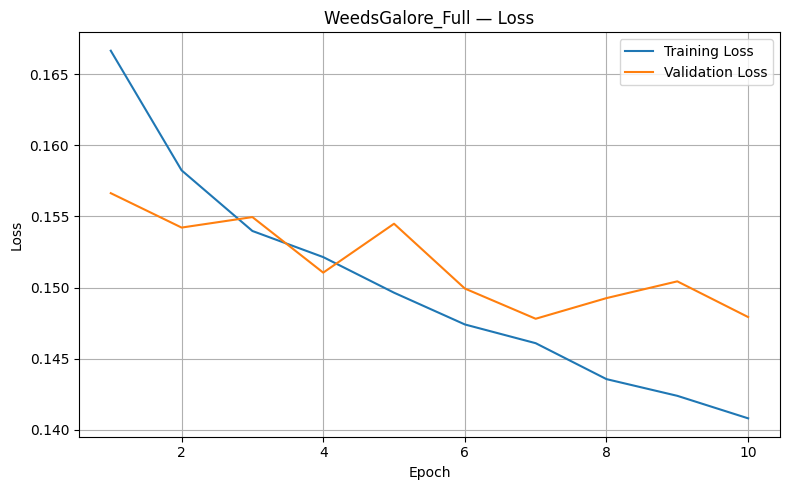

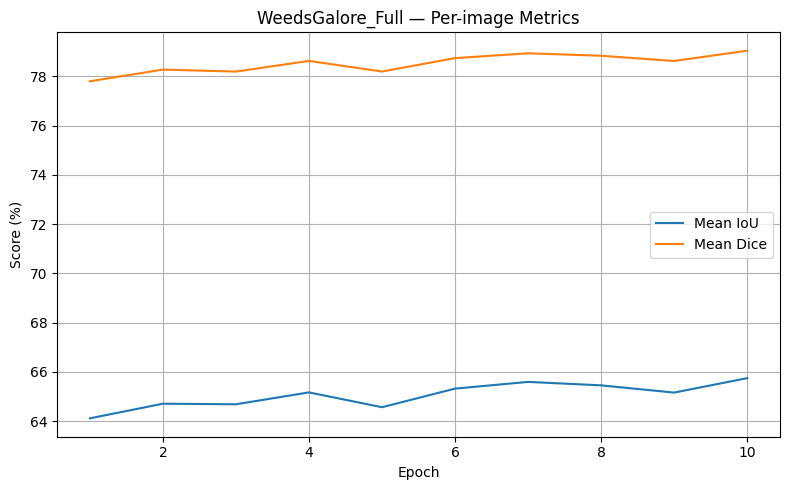


FINISHED: WeedsGalore_Full
Training seed: 42
Best Mean IoU: 65.75%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_Full/best_mask_decoder.pt

WEEDSGALORE FULL-DATA TRAINING COMPLETE
Best validation IoU: 65.75%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_Full/best_mask_decoder.pt


In [73]:
# ============================================================
# FULL-DATA WEEDSGALORE FINE-TUNING
# ============================================================

weedsgalore_full_result = run_finetuning_experiment(
    experiment_name="WeedsGalore_Full",
    train_dataset=weedsgalore_full_train_dataset,
    val_dataset=weedsgalore_val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE
)

print("\n" + "=" * 70)
print("WEEDSGALORE FULL-DATA TRAINING COMPLETE")
print("=" * 70)

print(f"Best validation IoU: "
      f"{weedsgalore_full_result['best_mean_iou'] * 100:.2f}%")

print(f"Checkpoint: "
      f"{weedsgalore_full_result['checkpoint']}")

Training seed set to: 42

STARTING EXPERIMENT: EWI1S_Full
Training seed: 42
Training samples: 70
Validation samples: 8


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4423
Val Loss: 0.4094
Mean IoU: 19.37%
Mean Dice: 27.07%
Global IoU: 16.26%
Global Dice: 27.96%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_Full/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3833
Val Loss: 0.3967
Mean IoU: 16.44%
Mean Dice: 24.77%
Global IoU: 25.95%
Global Dice: 41.21%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3572
Val Loss: 0.3976
Mean IoU: 18.60%
Mean Dice: 26.37%


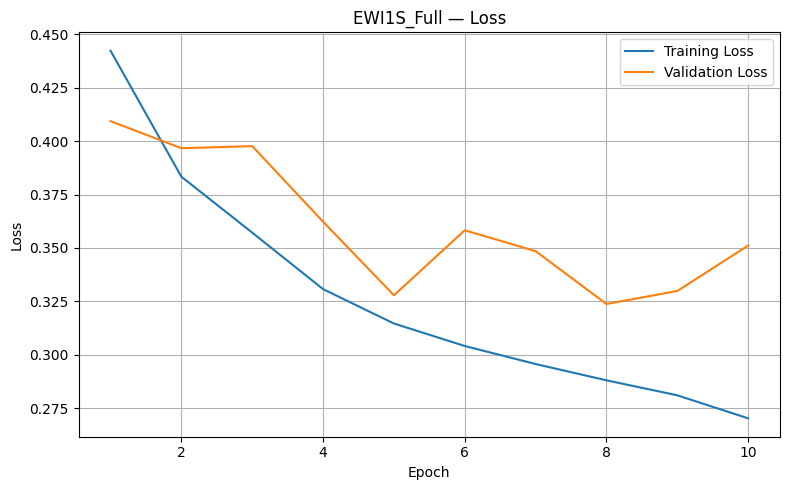

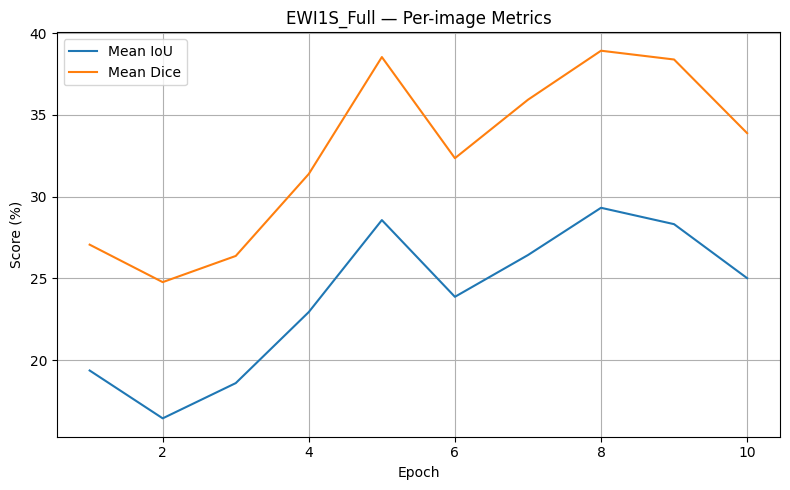


FINISHED: EWI1S_Full
Training seed: 42
Best Mean IoU: 29.32%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_Full/best_mask_decoder.pt

EWI1S FULL-DATA TRAINING COMPLETE
Best validation IoU: 29.32%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_Full/best_mask_decoder.pt


In [74]:
# ============================================================
# FULL-DATA EWI1S FINE-TUNING
# ============================================================

ewis1_full_result = run_finetuning_experiment(
    experiment_name="EWI1S_Full",
    train_dataset=ewis1_full_train_dataset,
    val_dataset=ewis1_val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE
)

print("\n" + "=" * 70)
print("EWI1S FULL-DATA TRAINING COMPLETE")
print("=" * 70)

print(f"Best validation IoU: "
      f"{ewis1_full_result['best_mean_iou'] * 100:.2f}%")

print(f"Checkpoint: "
      f"{ewis1_full_result['checkpoint']}")

In [75]:
# ============================================================
# VERIFY FULL-DATA CHECKPOINTS
# ============================================================

FULL_DATA_CHECKPOINTS = {
    "ReLeaf_Full": DOMAIN_FT_ROOT / "ReLeaf_Full" / "best_mask_decoder.pt",
    "WeedsGalore_Full": DOMAIN_FT_ROOT / "WeedsGalore_Full" / "best_mask_decoder.pt",
    "EWI1S_Full": DOMAIN_FT_ROOT / "EWI1S_Full" / "best_mask_decoder.pt",
}

print("=" * 70)
print("FULL-DATA CHECKPOINTS")
print("=" * 70)

for name, path in FULL_DATA_CHECKPOINTS.items():
    print(f"{name:25s} | Exists: {path.exists()} | {path}")

FULL-DATA CHECKPOINTS
ReLeaf_Full               | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf_Full/best_mask_decoder.pt
WeedsGalore_Full          | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore_Full/best_mask_decoder.pt
EWI1S_Full                | Exists: True | /home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S_Full/best_mask_decoder.pt


In [76]:
# ============================================================
# EVALUATE FULL-DATA CHECKPOINTS ON TEST SETS
# ============================================================

FULL_TEST_DATASETS = {
    "ReLeaf_Full": (
        "ReLeaf",
        releaf_test_dataset
    ),

    "WeedsGalore_Full": (
        "WeedsGalore",
        weedsgalore_test_dataset
    ),

    "EWI1S_Full": (
        "EWI1S",
        ewis1_test_dataset
    ),
}

full_data_test_results = []

for experiment_name, checkpoint_path in FULL_DATA_CHECKPOINTS.items():

    dataset_name, test_dataset = FULL_TEST_DATASETS[
        experiment_name
    ]

    print("\n" + "=" * 70)
    print(f"TESTING: {experiment_name}")
    print("=" * 70)

    # Load model
    model, checkpoint = load_label_efficiency_model(
        checkpoint_path
    )

    # Evaluate
    result = evaluate_test_checkpoint(
        model=model,
        dataset=test_dataset,
        dataset_name=dataset_name,
        checkpoint_name=experiment_name
    )

    # Number of labelled images
    if dataset_name == "ReLeaf":
        label_count = len(releaf_train_pairs)

    elif dataset_name == "WeedsGalore":
        label_count = len(weedsgalore_train_pairs)

    elif dataset_name == "EWI1S":
        label_count = len(ewis1_train_pairs)

    result["labelled_images"] = label_count

    result["best_val_iou"] = checkpoint.get(
        "best_mean_iou",
        np.nan
    )

    result["best_epoch"] = checkpoint.get(
        "epoch",
        np.nan
    )

    full_data_test_results.append(result)

    print(f"Test Mean IoU: "
          f"{result['mean_iou'] * 100:.2f}%")

    print(f"Test Mean Dice: "
          f"{result['mean_dice'] * 100:.2f}%")

    print(f"Best Val IoU: "
          f"{result['best_val_iou'] * 100:.2f}%")

    del model
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("FULL-DATA TEST EVALUATION COMPLETE")
print("=" * 70)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



TESTING: ReLeaf_Full


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test Mean IoU: 77.76%
Test Mean Dice: 86.86%
Best Val IoU: 84.70%

TESTING: WeedsGalore_Full


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test Mean IoU: 60.46%
Test Mean Dice: 74.61%
Best Val IoU: 65.75%

TESTING: EWI1S_Full


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Test Mean IoU: 33.00%
Test Mean Dice: 47.61%
Best Val IoU: 29.32%

FULL-DATA TEST EVALUATION COMPLETE


In [77]:
# ============================================================
# FULL-DATA TEST RESULTS TABLE
# ============================================================

full_df = pd.DataFrame(full_data_test_results)

full_df = full_df[
    [
        "checkpoint",
        "dataset",
        "labelled_images",
        "images",
        "best_val_iou",
        "best_epoch",
        "mean_iou",
        "mean_dice",
        "mean_precision",
        "mean_recall",
        "mean_confidence"
    ]
].copy()

for column in [
    "best_val_iou",
    "mean_iou",
    "mean_dice",
    "mean_precision",
    "mean_recall",
]:
    full_df[column] *= 100

display(
    full_df.style.format({
        "best_val_iou": "{:.2f}%",
        "mean_iou": "{:.2f}%",
        "mean_dice": "{:.2f}%",
        "mean_precision": "{:.2f}%",
        "mean_recall": "{:.2f}%",
        "mean_confidence": "{:.4f}",
    })
)

,checkpoint,dataset,labelled_images,images,best_val_iou,best_epoch,mean_iou,mean_dice,mean_precision,mean_recall,mean_confidence
0,ReLeaf_Full,ReLeaf,276,35,84.70%,8,77.76%,86.86%,87.00%,87.10%,0.9318
1,WeedsGalore_Full,WeedsGalore,124,17,65.75%,10,60.46%,74.61%,78.07%,72.39%,0.9023
2,EWI1S_Full,EWI1S,70,10,29.32%,8,33.00%,47.61%,56.99%,42.12%,0.8245


In [78]:
# ============================================================
# COMBINE LABEL-EFFICIENCY + FULL-DATA RESULTS
# ============================================================

combined_results = pd.concat(
    [
        results_df.copy(),
        full_df.copy()
    ],
    ignore_index=True
)

# Rename if necessary so columns are consistent
combined_results = combined_results.sort_values(
    ["dataset", "labelled_images"]
).reset_index(drop=True)

display(
    combined_results.style.format({
        "best_val_iou": "{:.2f}%",
        "mean_iou": "{:.2f}%",
        "mean_dice": "{:.2f}%",
        "mean_precision": "{:.2f}%",
        "mean_recall": "{:.2f}%",
        "mean_confidence": "{:.4f}",
        "std_iou": "{:.2f}%",
        "min_iou": "{:.2f}%",
        "max_iou": "{:.2f}%",
    })
)

,checkpoint,dataset,labelled_images,images,best_val_iou,best_epoch,mean_iou,mean_dice,mean_precision,mean_recall,mean_confidence,std_iou,min_iou,max_iou
0,EWI1S_5,EWI1S,5,10,16.80%,1,15.87%,25.76%,20.41%,47.34%,0.8472,11.37%,0.96%,37.99%
1,EWI1S_10,EWI1S,10,10,15.06%,2,11.18%,19.34%,20.01%,25.67%,0.8080,7.22%,0.66%,21.32%
2,EWI1S_25,EWI1S,25,10,23.62%,10,23.23%,36.42%,51.41%,30.09%,0.7953,10.66%,0.08%,42.53%
3,EWI1S_50,EWI1S,50,10,23.66%,3,26.89%,40.54%,36.83%,47.86%,0.8521,13.52%,0.18%,54.31%
4,EWI1S_Full,EWI1S,70,10,29.32%,8,33.00%,47.61%,56.99%,42.12%,0.8245,nan%,nan%,nan%
5,ReLeaf_5,ReLeaf,5,35,82.22%,10,75.53%,85.37%,84.22%,87.31%,0.9444,12.97%,34.16%,94.16%
6,ReLeaf_10,ReLeaf,10,35,82.71%,7,75.26%,85.17%,83.85%,87.43%,0.9430,13.12%,33.86%,94.14%
7,ReLeaf_25,ReLeaf,25,35,83.34%,6,75.93%,85.60%,85.06%,86.73%,0.9568,13.16%,31.94%,94.27%
8,ReLeaf_50,ReLeaf,50,35,83.10%,4,75.84%,85.53%,85.89%,85.89%,0.9588,13.25%,31.24%,94.35%
9,ReLeaf_100,ReLeaf,100,35,83.85%,4,77.44%,86.64%,85.51%,88.34%,0.9527,12.65%,35.88%,94.45%


In [79]:
# ============================================================
# PERFORMANCE RECOVERY
# ============================================================

recovery_df = combined_results[
    [
        "dataset",
        "labelled_images",
        "mean_iou",
        "mean_dice"
    ]
].copy()

# ------------------------------------------------------------
# Full-data IoU for each domain
# ------------------------------------------------------------

full_iou_by_domain = {}

for domain in ["ReLeaf", "WeedsGalore", "EWI1S"]:

    full_row = combined_results[
        (combined_results["dataset"] == domain) &
        (combined_results["checkpoint"] == f"{domain}_Full")
    ]

    if len(full_row) != 1:
        raise ValueError(
            f"Could not uniquely find full-data result for {domain}"
        )

    full_iou_by_domain[domain] = float(
        full_row.iloc[0]["mean_iou"]
    )

# ------------------------------------------------------------
# Raw performance recovery
# ------------------------------------------------------------

recovery_df["full_data_iou"] = recovery_df["dataset"].map(
    full_iou_by_domain
)

recovery_df["performance_recovered_%"] = (
    recovery_df["mean_iou"] /
    recovery_df["full_data_iou"] *
    100
)

# ------------------------------------------------------------
# Remove full-data rows from few-shot comparison
# ------------------------------------------------------------

recovery_df = recovery_df[
    recovery_df["labelled_images"] < recovery_df["dataset"].map({
        "ReLeaf": 276,
        "WeedsGalore": 124,
        "EWI1S": 70
    })
].copy()

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(
    recovery_df.style.format({
        "mean_iou": "{:.2f}%",
        "mean_dice": "{:.2f}%",
        "full_data_iou": "{:.2f}%",
        "performance_recovered_%": "{:.2f}%"
    })
)

,dataset,labelled_images,mean_iou,mean_dice,full_data_iou,performance_recovered_%
0,EWI1S,5,15.87%,25.76%,33.00%,48.09%
1,EWI1S,10,11.18%,19.34%,33.00%,33.88%
2,EWI1S,25,23.23%,36.42%,33.00%,70.39%
3,EWI1S,50,26.89%,40.54%,33.00%,81.47%
5,ReLeaf,5,75.53%,85.37%,77.76%,97.14%
6,ReLeaf,10,75.26%,85.17%,77.76%,96.79%
7,ReLeaf,25,75.93%,85.60%,77.76%,97.64%
8,ReLeaf,50,75.84%,85.53%,77.76%,97.53%
9,ReLeaf,100,77.44%,86.64%,77.76%,99.59%
11,WeedsGalore,5,57.24%,71.88%,60.46%,94.68%


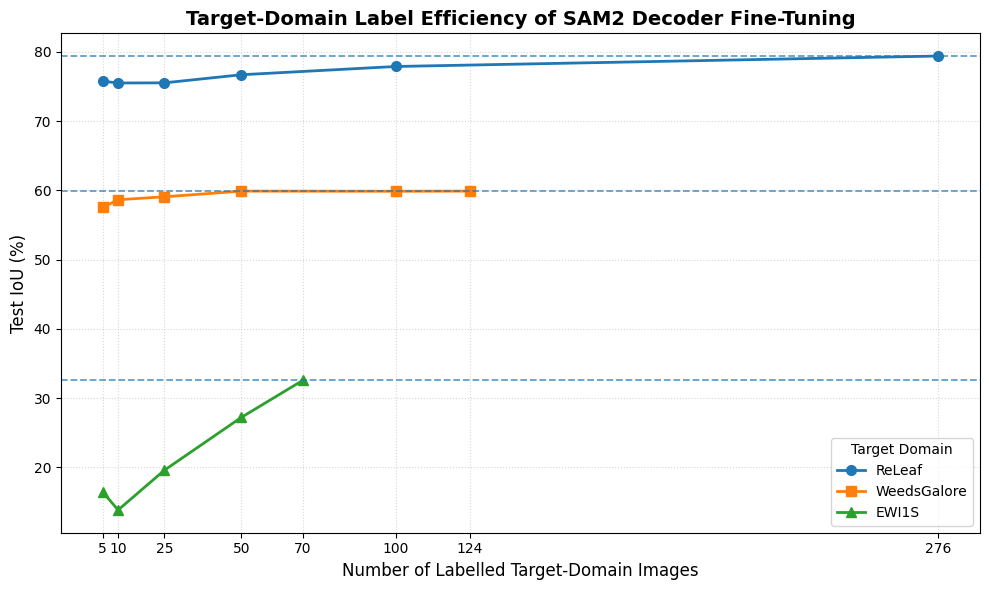

In [80]:
# ============================================================
# LABEL-EFFICIENCY PLOT
# Target labelled images vs Test IoU
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. Enter the TEST IoU results
# ------------------------------------------------------------

label_efficiency_data = {
    "ReLeaf": {
        "labels": [5, 10, 25, 50, 100, 276],
        "test_iou": [75.75, 75.49, 75.51, 76.68, 77.87, 79.38],
        "full_data": 79.38
    },

    "WeedsGalore": {
        "labels": [5, 10, 25, 50, 100, 124],
        "test_iou": [57.52, 58.64, 59.06, 59.88, 59.86, 59.88],
        "full_data": 59.88
    },

    "EWI1S": {
        "labels": [5, 10, 25, 50, 70],
        "test_iou": [16.47, 13.85, 19.59, 27.23, 32.59],
        "full_data": 32.59
    }
}

# ------------------------------------------------------------
# 2. Create plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

markers = {
    "ReLeaf": "o",
    "WeedsGalore": "s",
    "EWI1S": "^"
}

for dataset, values in label_efficiency_data.items():

    labels = values["labels"]
    ious = values["test_iou"]
    full_iou = values["full_data"]

    # Main curve
    plt.plot(
        labels,
        ious,
        marker=markers[dataset],
        linewidth=2,
        markersize=7,
        label=dataset
    )

    # Full-data reference line
    plt.axhline(
        y=full_iou,
        linestyle="--",
        linewidth=1.3,
        alpha=0.7
    )

# ------------------------------------------------------------
# 3. Formatting
# ------------------------------------------------------------

plt.xlabel("Number of Labelled Target-Domain Images", fontsize=12)
plt.ylabel("Test IoU (%)", fontsize=12)

plt.title(
    "Target-Domain Label Efficiency of SAM2 Decoder Fine-Tuning",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(
    [5, 10, 25, 50, 70, 100, 124, 276],
    fontsize=10
)

plt.yticks(fontsize=10)

plt.grid(
    True,
    linestyle=":",
    alpha=0.5
)

plt.legend(
    title="Target Domain",
    fontsize=10
)

plt.tight_layout()

plt.show()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



POINT 6 EXPERIMENTS: ReLeaf

----------------------------------------------------------------------
ReLeaf | Subset seed: 42 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_ReLeaf_5labels_subset42_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2015
Val Loss: 0.1637
Mean IoU: 81.29%
Mean Dice: 89.24%
Global IoU: 82.46%
Global Dice: 90.39%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1544
Val Loss: 0.1497
Mean IoU: 81.27%
Mean Dice: 89.28%
Global IoU: 82.45%
Global Dice: 90.38%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1350
Val Loss: 0.1465
Mea

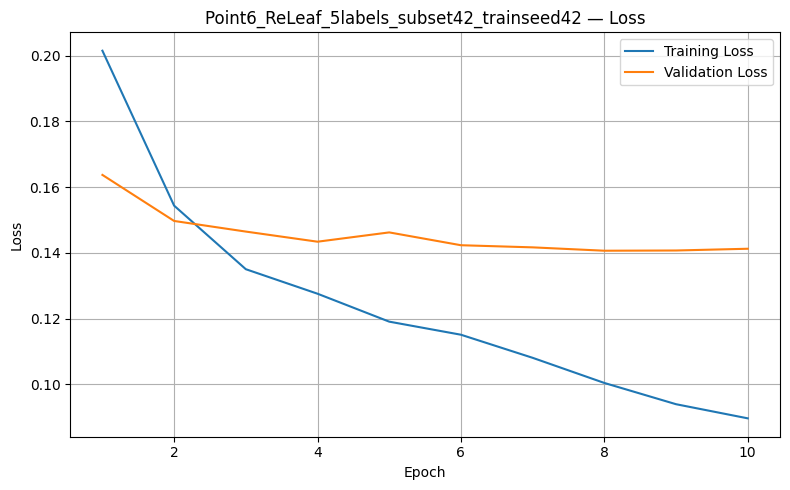

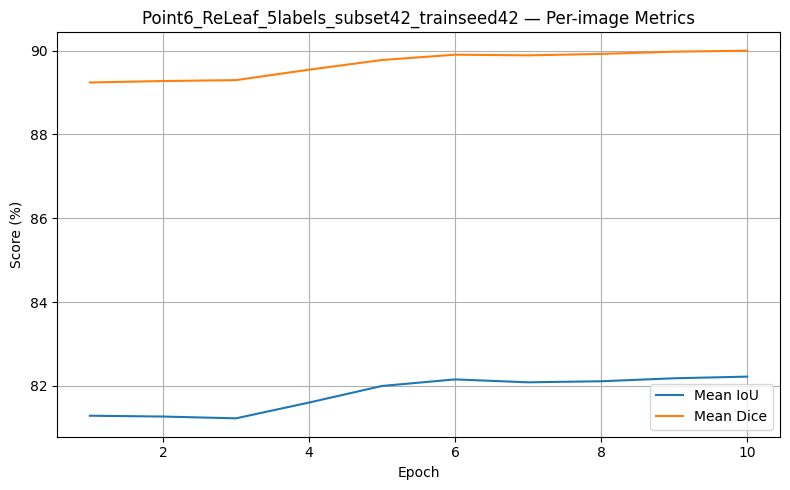

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 82.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed42/best_mask_decoder.pt

################################################################################
Point6_ReLeaf_5labels_subset42_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2040
Val Loss: 0.1613
Mean IoU: 81.31%
Mean Dice: 89.25%
Global IoU: 82.53%
Global Dice: 90.43%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1504
Val Loss: 0.1488
Mean IoU: 81.17%
Mean Dice: 89.22%
Global IoU: 82.42%
Global Dice: 90.36%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1387
Val Loss: 0.1467
Me

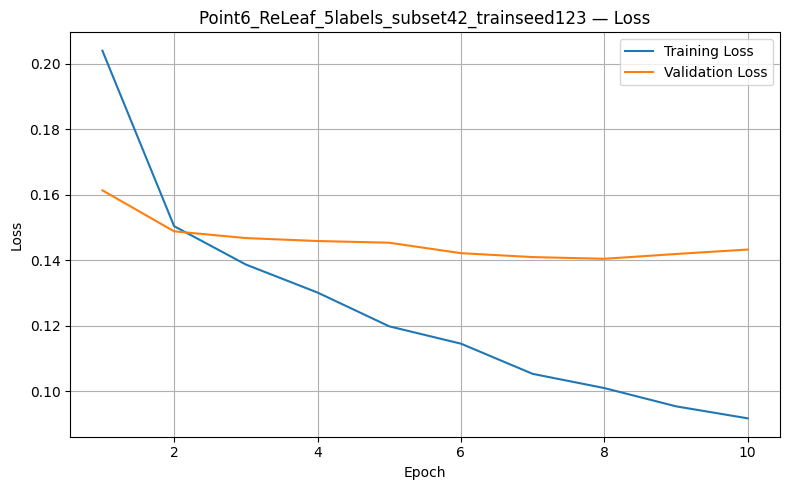

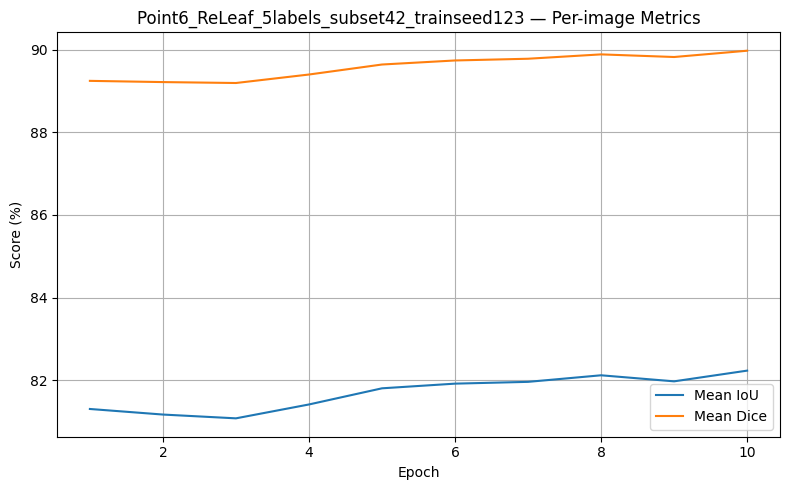

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 82.23%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
ReLeaf | Subset seed: 123 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_ReLeaf_5labels_subset123_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1353
Val Loss: 0.1631
Mean IoU: 80.86%
Mean Dice: 89.01%
Global IoU: 82.06%
Global Dice: 90.15%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1176
Val Loss: 0.1535
Mean IoU: 80.70%
Mean Dice: 88.93%
Global IoU: 81.98%
Global Dice: 90.10%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1022
Val Loss: 0.1498
Me

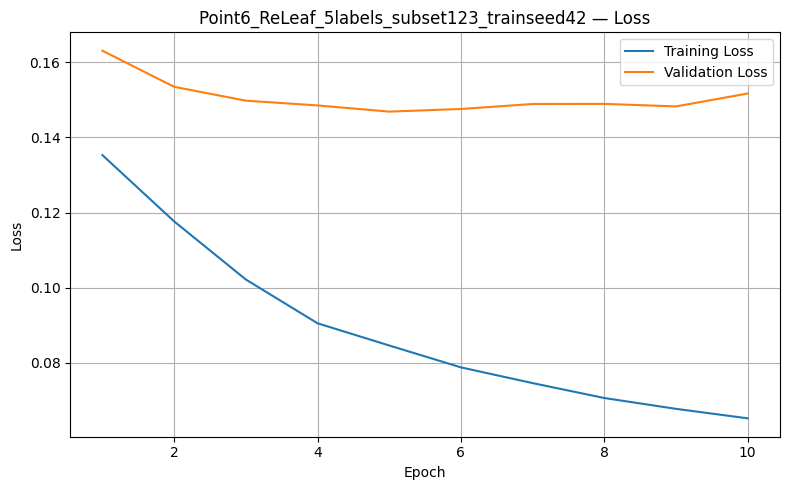

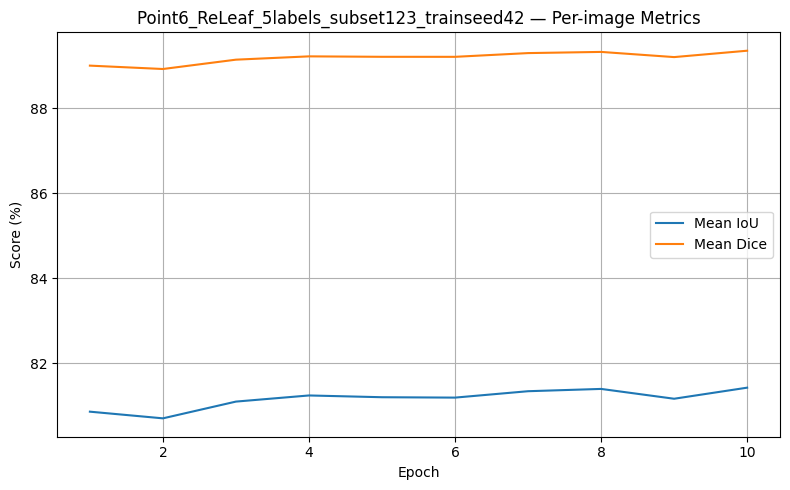

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 81.42%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed42/best_mask_decoder.pt

################################################################################
Point6_ReLeaf_5labels_subset123_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1389
Val Loss: 0.1604
Mean IoU: 81.23%
Mean Dice: 89.21%
Global IoU: 82.44%
Global Dice: 90.38%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1072
Val Loss: 0.1524
Mean IoU: 81.25%
Mean Dice: 89.24%
Global IoU: 82.48%
Global Dice: 90.40%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
E

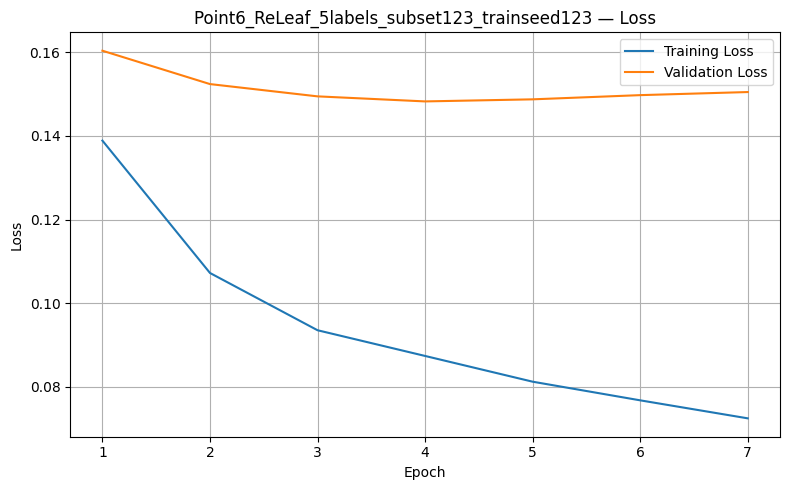

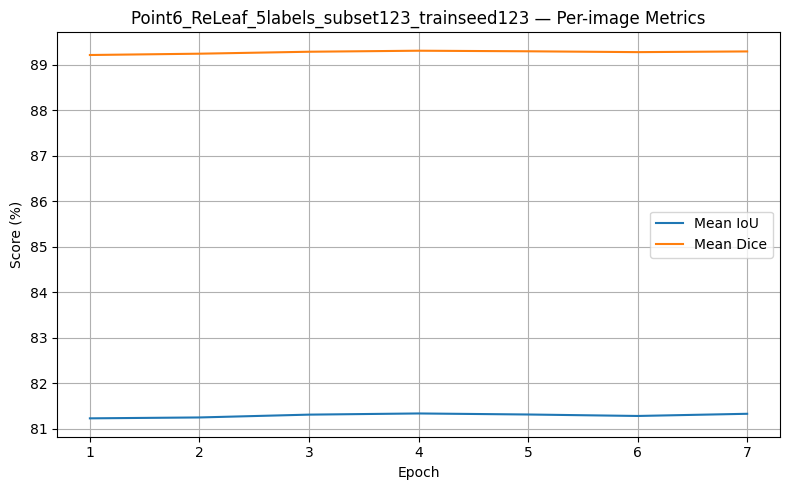

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 81.34%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
ReLeaf | Subset seed: 2026 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_ReLeaf_5labels_subset2026_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1831
Val Loss: 0.1618
Mean IoU: 81.37%
Mean Dice: 89.28%
Global IoU: 82.59%
Global Dice: 90.47%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1342
Val Loss: 0.1479
Mean IoU: 81.59%
Mean Dice: 89.46%
Global IoU: 82.81%
Global Dice: 90.60%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
E

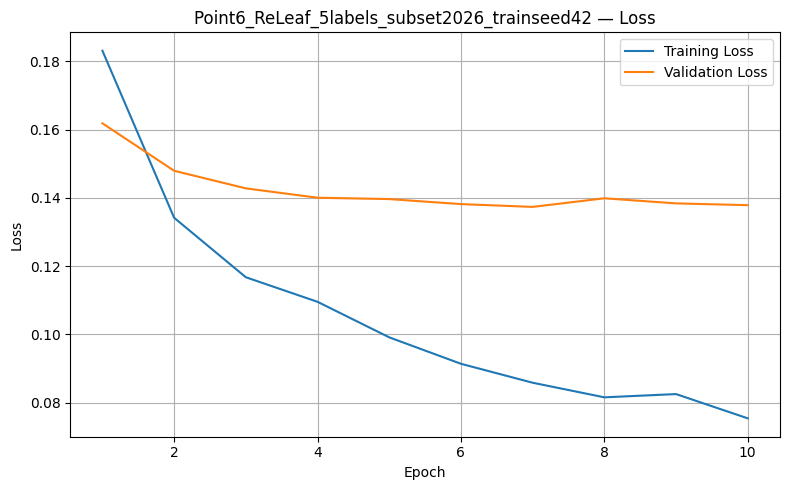

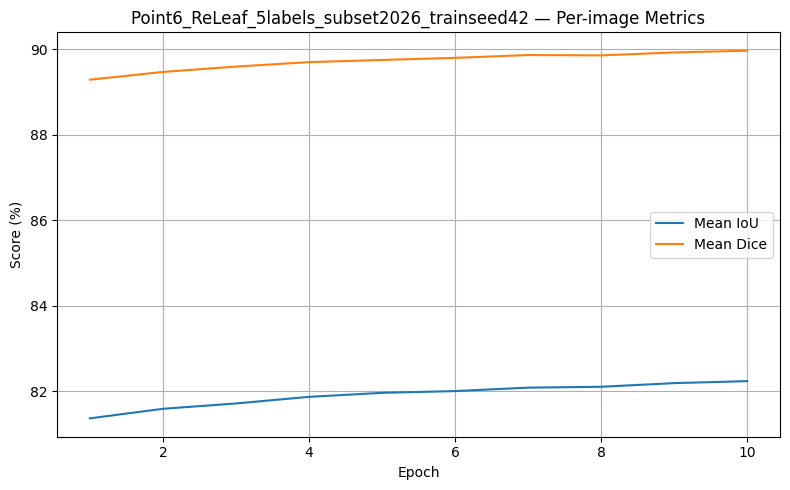

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 82.24%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed42/best_mask_decoder.pt

################################################################################
Point6_ReLeaf_5labels_subset2026_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1683
Val Loss: 0.1562
Mean IoU: 81.38%
Mean Dice: 89.32%
Global IoU: 82.59%
Global Dice: 90.46%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1233
Val Loss: 0.1469
Mean IoU: 81.63%
Mean Dice: 89.50%
Global IoU: 82.84%
Global Dice: 90.61%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------

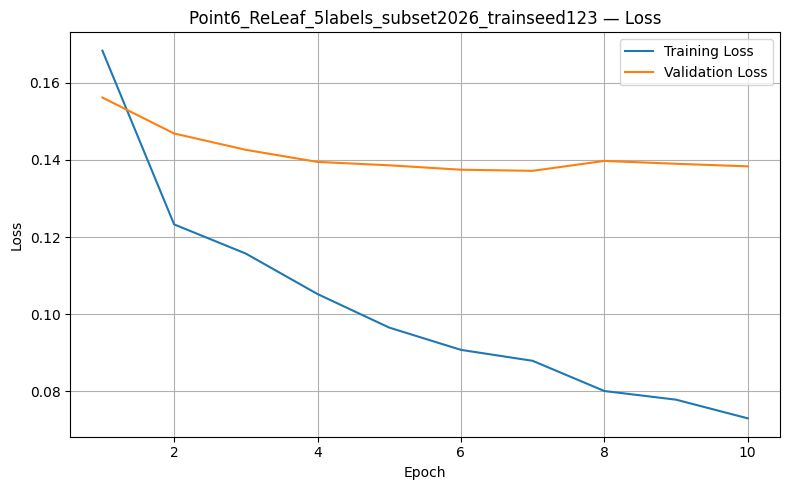

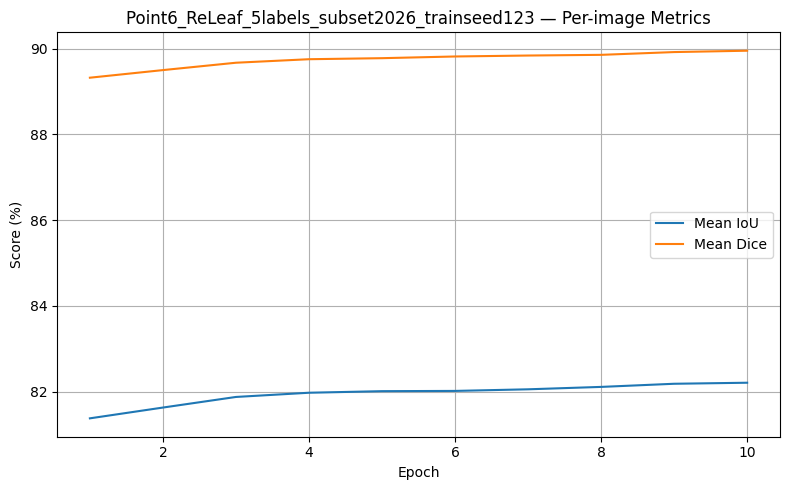

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 82.21%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
ReLeaf | Subset seed: 77 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_ReLeaf_5labels_subset77_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1700
Val Loss: 0.1568
Mean IoU: 81.33%
Mean Dice: 89.30%
Global IoU: 82.51%
Global Dice: 90.42%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1259
Val Loss: 0.1481
Mean IoU: 81.44%
Mean Dice: 89.39%
Global IoU: 82.66%
Global Dice: 90.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch

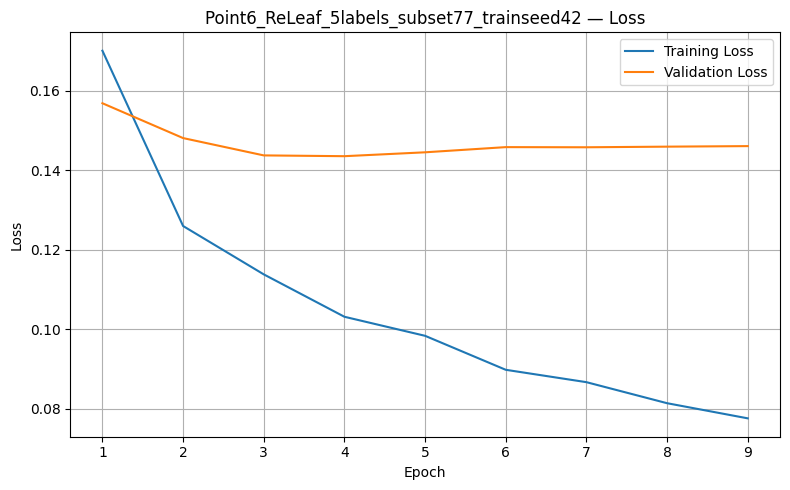

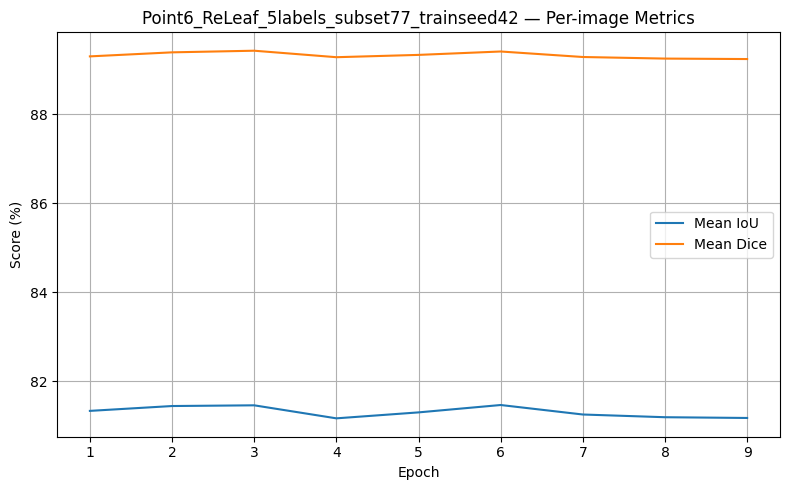

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 81.46%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed42/best_mask_decoder.pt

################################################################################
Point6_ReLeaf_5labels_subset77_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1741
Val Loss: 0.1602
Mean IoU: 81.34%
Mean Dice: 89.28%
Global IoU: 82.55%
Global Dice: 90.44%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1283
Val Loss: 0.1486
Mean IoU: 81.29%
Mean Dice: 89.28%
Global IoU: 82.54%
Global Dice: 90.44%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1124
Val Loss: 0.1462
Me

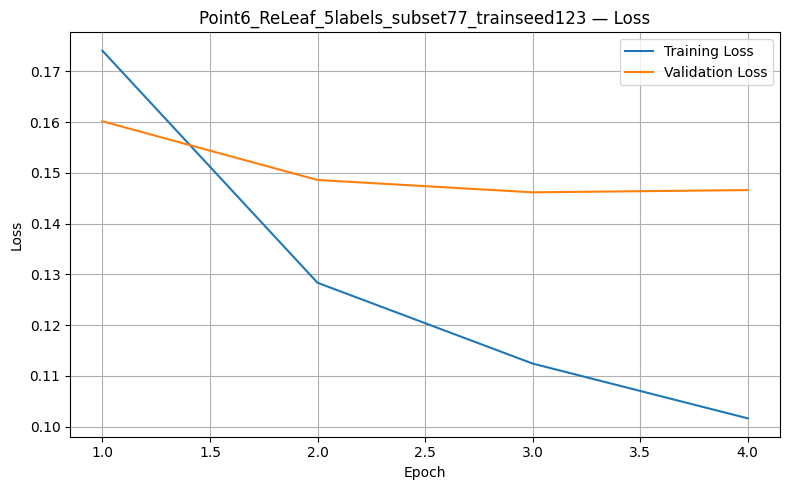

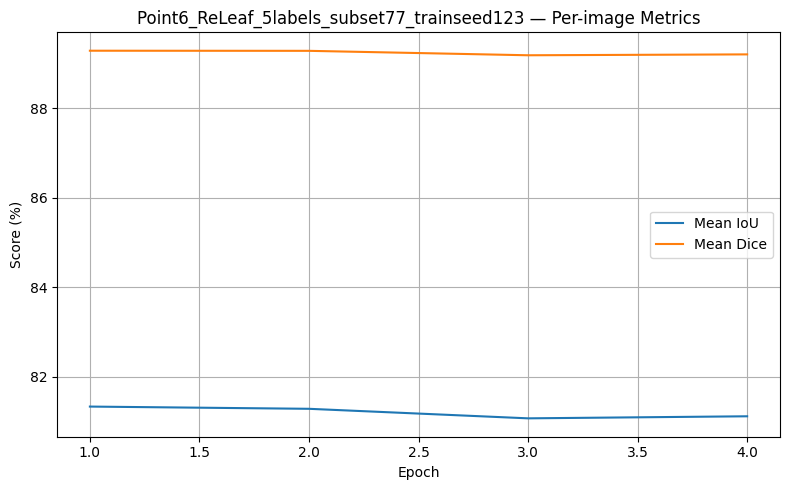

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 81.34%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
ReLeaf | Subset seed: 314 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_ReLeaf_5labels_subset314_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3337
Val Loss: 0.1503
Mean IoU: 81.72%
Mean Dice: 89.63%
Global IoU: 82.79%
Global Dice: 90.59%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.2393
Val Loss: 0.1479
Mean IoU: 80.65%
Mean Dice: 89.00%
Global IoU: 81.77%
Global Dice: 89.97%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1895
Val Loss: 0.1519
Me

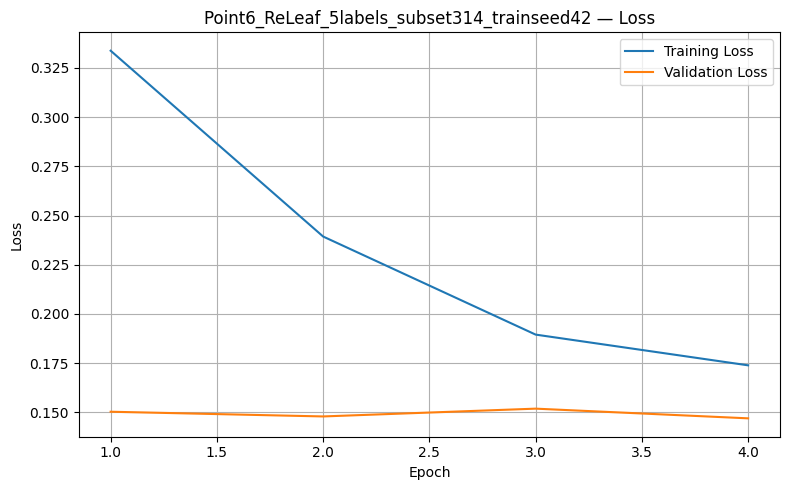

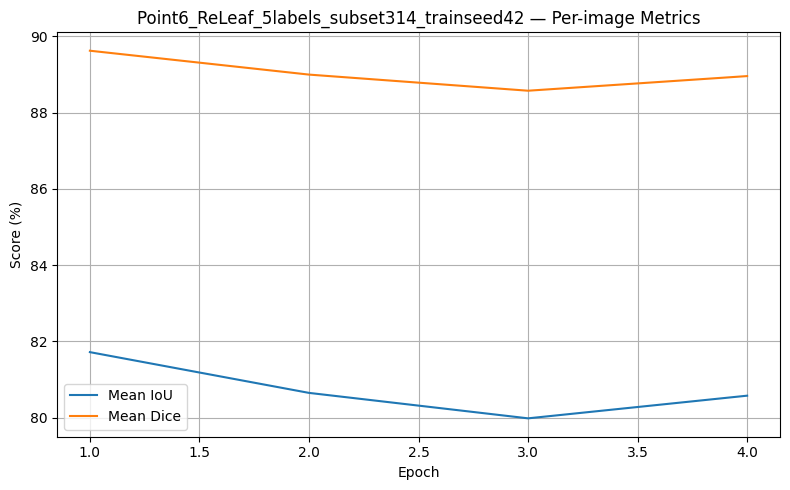

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 81.72%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed42/best_mask_decoder.pt

################################################################################
Point6_ReLeaf_5labels_subset314_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3413
Val Loss: 0.1533
Mean IoU: 81.48%
Mean Dice: 89.44%
Global IoU: 82.64%
Global Dice: 90.50%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.2142
Val Loss: 0.1470
Mean IoU: 80.89%
Mean Dice: 89.14%
Global IoU: 82.04%
Global Dice: 90.13%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1879
Val Loss: 0.1523
M

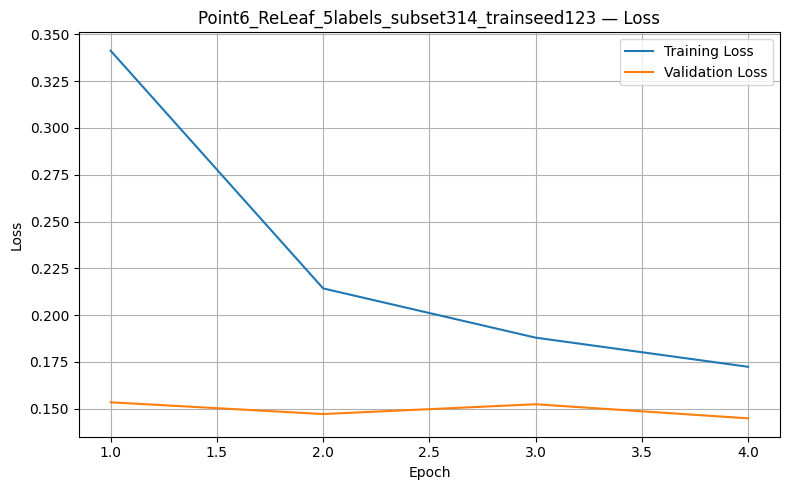

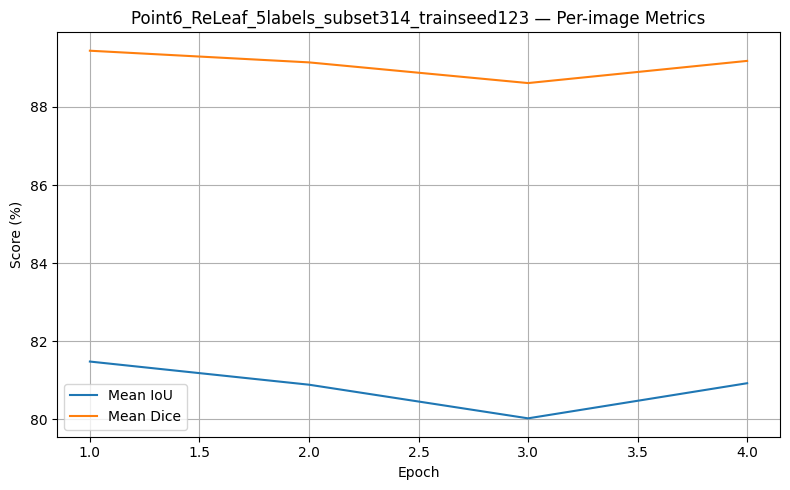

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 81.48%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_5labels_subset314_trainseed123/best_mask_decoder.pt

POINT 6 EXPERIMENTS: WeedsGalore

----------------------------------------------------------------------
WeedsGalore | Subset seed: 42 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_WeedsGalore_5labels_subset42_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1540
Val Loss: 0.1742
Mean IoU: 61.11%
Mean Dice: 75.28%
Global IoU: 69.22%
Global Dice: 81.81%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1474
Val Loss: 0.1733
Mean IoU: 61.32%
Mean Dice: 75.39%
Global IoU: 69.66%
Global Dice: 82.12%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

------------------------------------------------------------------

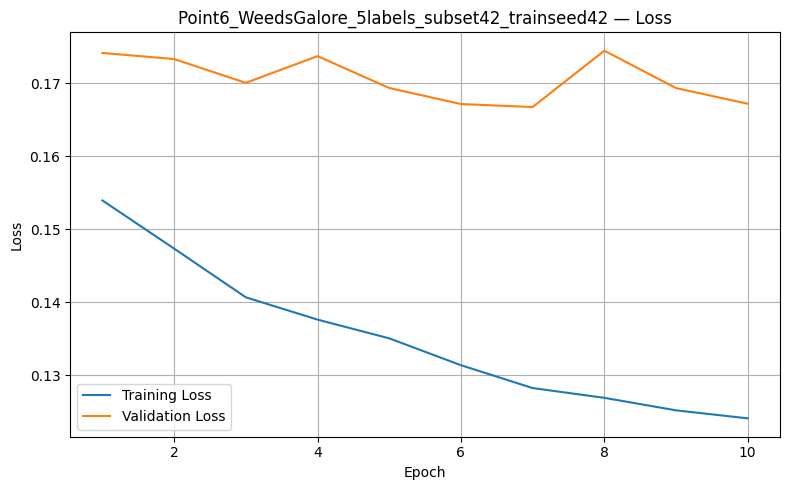

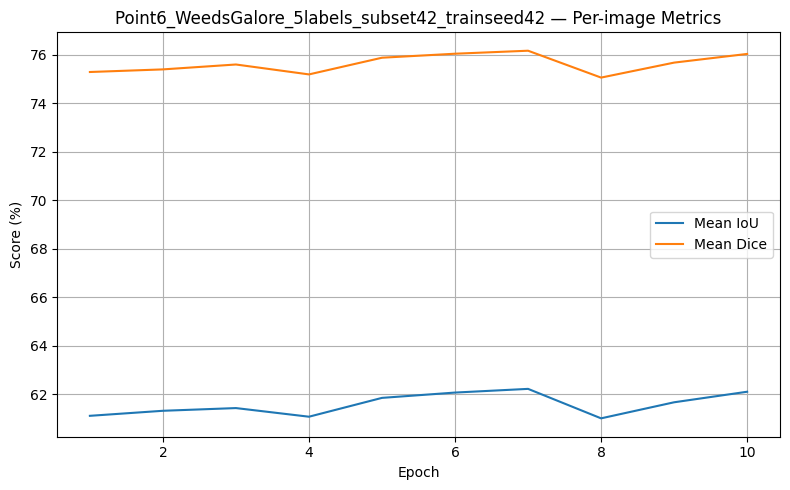

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 62.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed42/best_mask_decoder.pt

################################################################################
Point6_WeedsGalore_5labels_subset42_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1558
Val Loss: 0.1755
Mean IoU: 61.13%
Mean Dice: 75.26%
Global IoU: 69.41%
Global Dice: 81.95%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1455
Val Loss: 0.1685
Mean IoU: 61.81%
Mean Dice: 75.89%
Global IoU: 69.36%
Global Dice: 81.91%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------

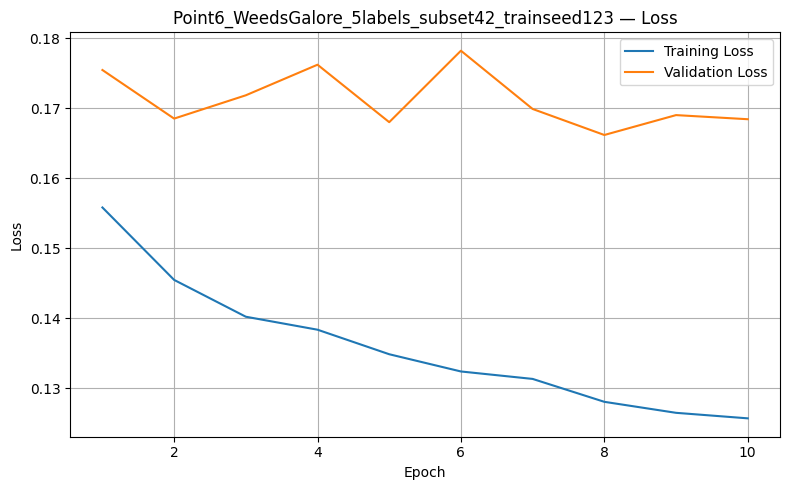

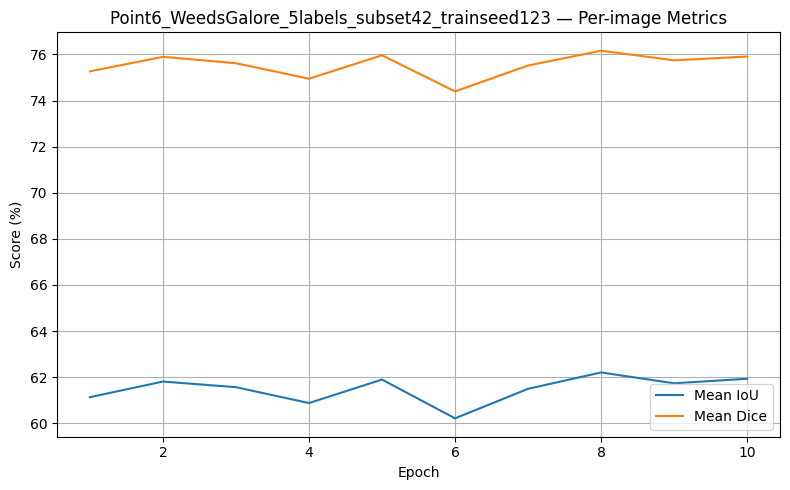

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 62.21%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
WeedsGalore | Subset seed: 123 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_WeedsGalore_5labels_subset123_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1906
Val Loss: 0.1697
Mean IoU: 61.69%
Mean Dice: 75.86%
Global IoU: 68.55%
Global Dice: 81.34%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1798
Val Loss: 0.1713
Mean IoU: 61.44%
Mean Dice: 75.59%
Global IoU: 69.15%
Global Dice: 81.76%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1767
Val Loss: 0.17

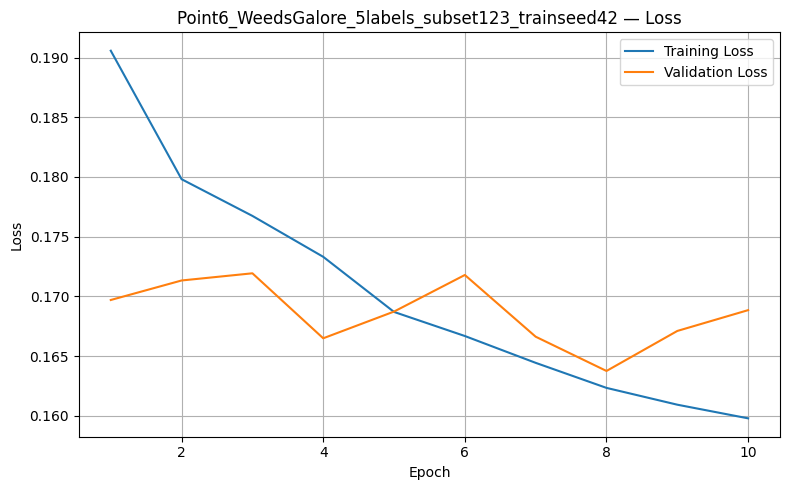

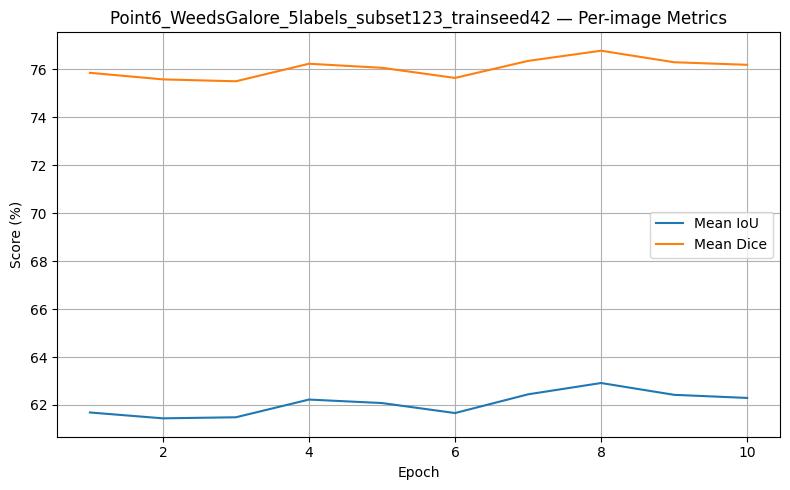

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 62.92%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed42/best_mask_decoder.pt

################################################################################
Point6_WeedsGalore_5labels_subset123_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1890
Val Loss: 0.1729
Mean IoU: 61.17%
Mean Dice: 75.39%
Global IoU: 68.68%
Global Dice: 81.43%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1833
Val Loss: 0.1719
Mean IoU: 61.59%
Mean Dice: 75.65%
Global IoU: 69.54%
Global Dice: 82.03%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

--------------------------------------------------------------

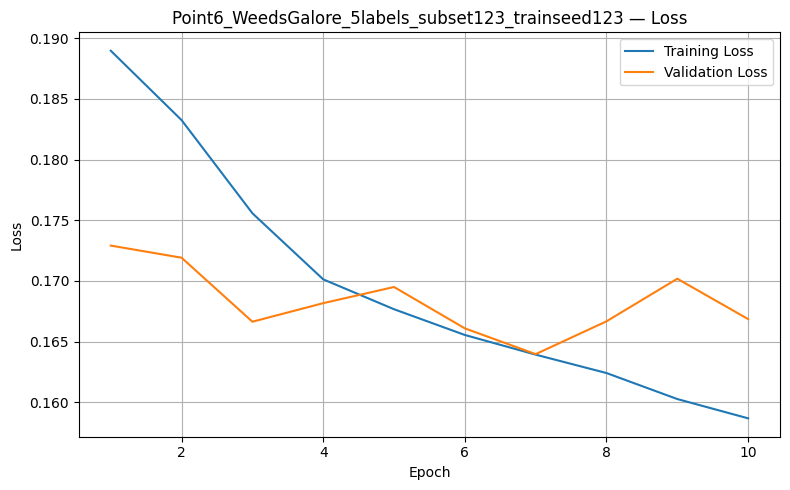

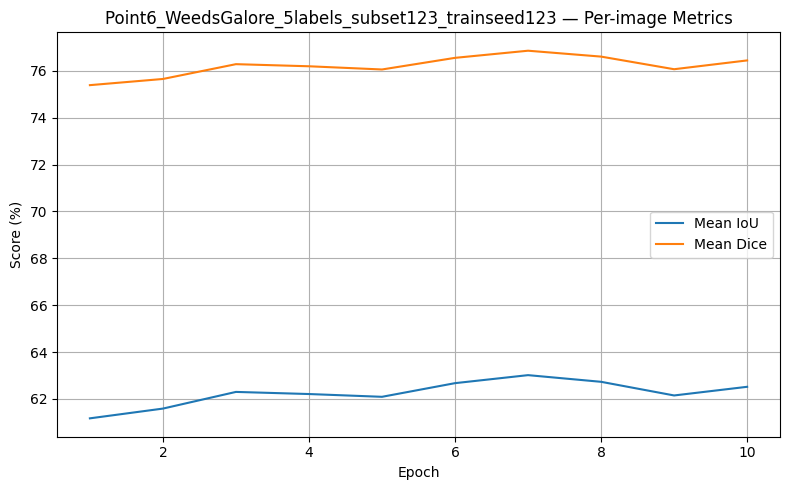

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 63.01%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
WeedsGalore | Subset seed: 2026 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_WeedsGalore_5labels_subset2026_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2132
Val Loss: 0.1736
Mean IoU: 61.27%
Mean Dice: 75.41%
Global IoU: 69.02%
Global Dice: 81.67%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1953
Val Loss: 0.1646
Mean IoU: 62.62%
Mean Dice: 76.57%
Global IoU: 69.58%
Global Dice: 82.06%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

--------------------------------------------------------------

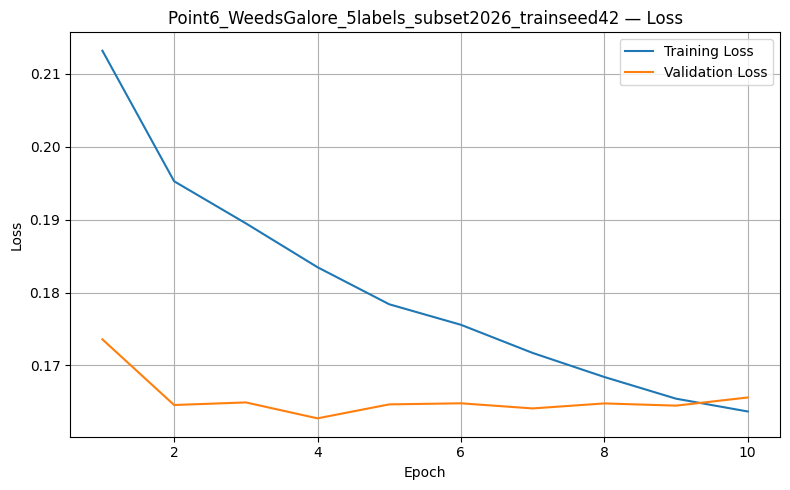

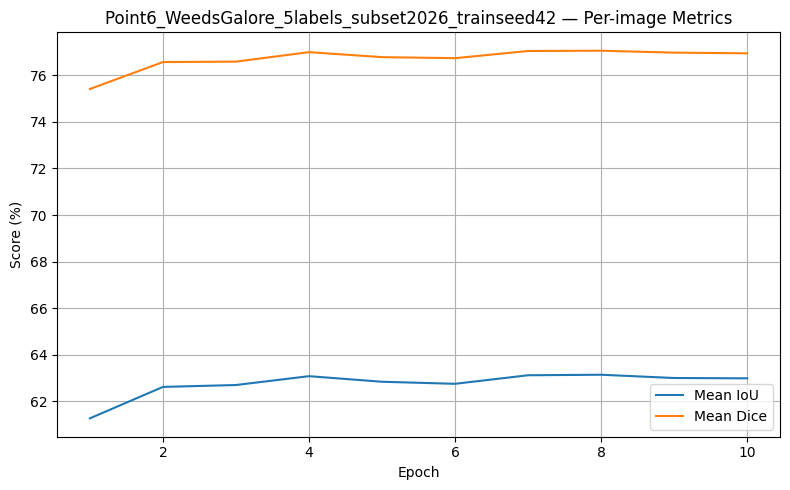

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 63.14%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed42/best_mask_decoder.pt

################################################################################
Point6_WeedsGalore_5labels_subset2026_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.2069
Val Loss: 0.1689
Mean IoU: 62.06%
Mean Dice: 76.10%
Global IoU: 69.44%
Global Dice: 81.97%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1914
Val Loss: 0.1668
Mean IoU: 62.31%
Mean Dice: 76.26%
Global IoU: 69.35%
Global Dice: 81.90%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

------------------------------------------------------------

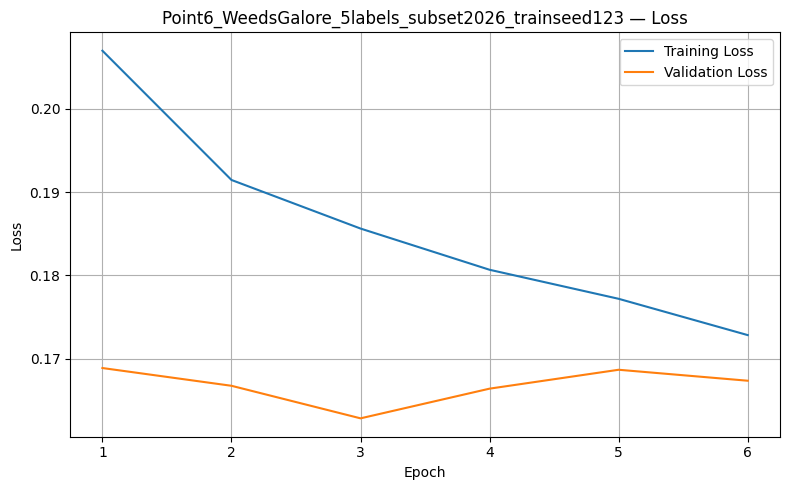

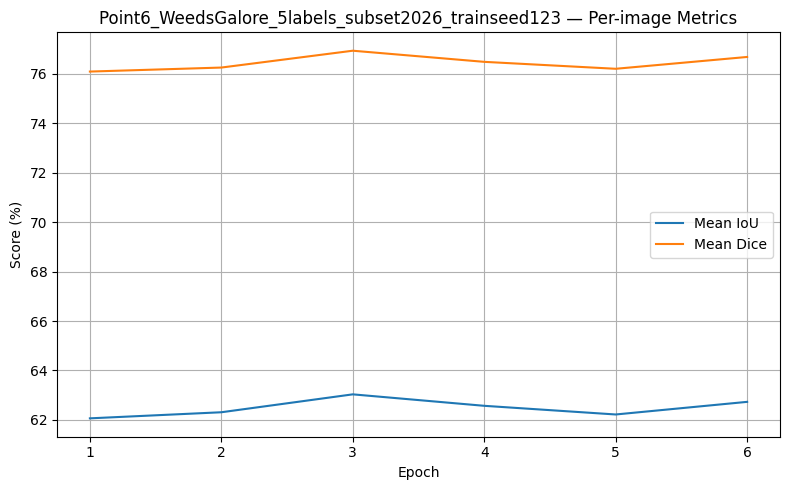

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 63.03%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
WeedsGalore | Subset seed: 77 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_WeedsGalore_5labels_subset77_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1833
Val Loss: 0.1718
Mean IoU: 62.11%
Mean Dice: 76.10%
Global IoU: 69.07%
Global Dice: 81.71%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1668
Val Loss: 0.1676
Mean IoU: 62.43%
Mean Dice: 76.37%
Global IoU: 69.42%
Global Dice: 81.95%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

------------------------------------------------------------------

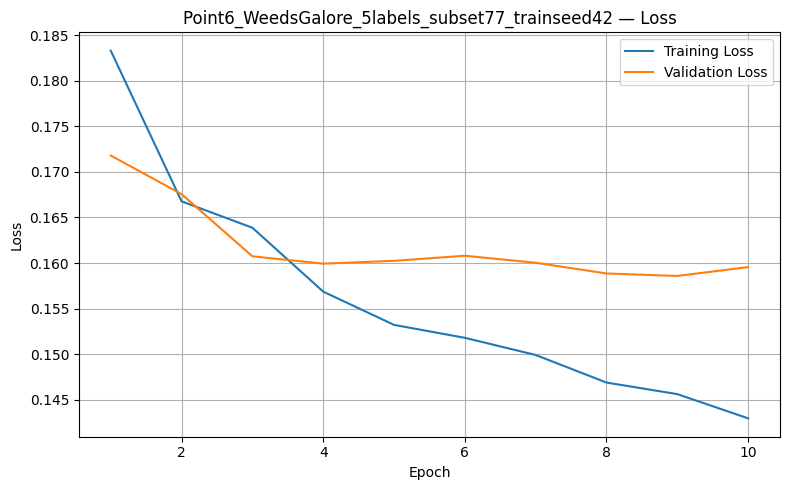

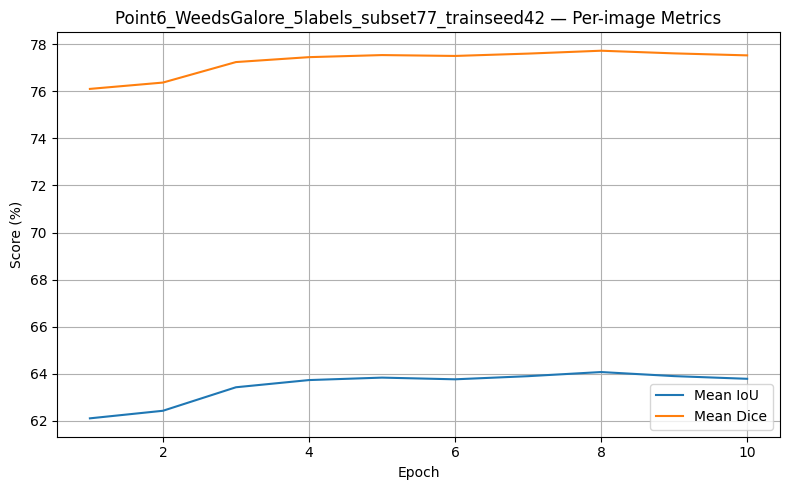

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 64.08%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed42/best_mask_decoder.pt

################################################################################
Point6_WeedsGalore_5labels_subset77_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1912
Val Loss: 0.1718
Mean IoU: 62.28%
Mean Dice: 76.25%
Global IoU: 69.30%
Global Dice: 81.86%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1687
Val Loss: 0.1656
Mean IoU: 62.66%
Mean Dice: 76.63%
Global IoU: 68.90%
Global Dice: 81.58%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------

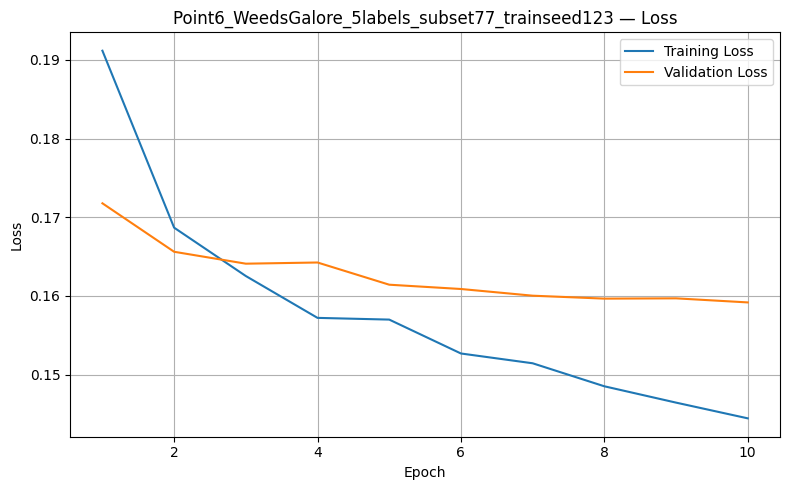

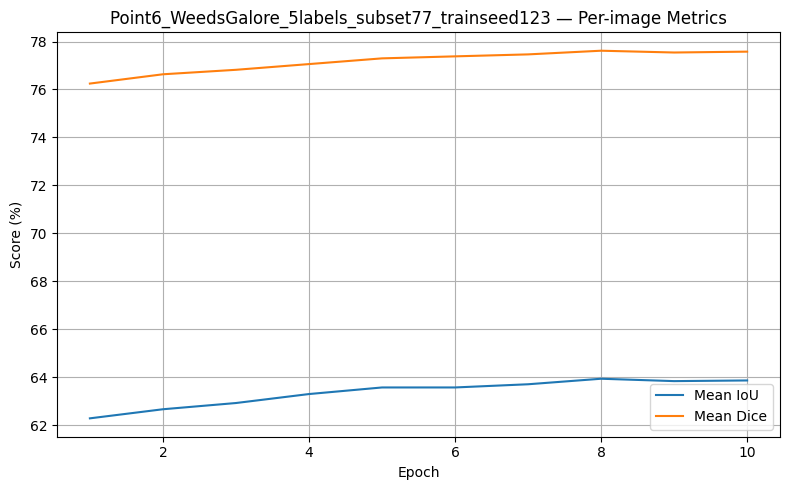

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 63.93%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
WeedsGalore | Subset seed: 314 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_WeedsGalore_5labels_subset314_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1705
Val Loss: 0.1666
Mean IoU: 62.30%
Mean Dice: 76.34%
Global IoU: 68.65%
Global Dice: 81.41%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1611
Val Loss: 0.1756
Mean IoU: 60.81%
Mean Dice: 74.99%
Global IoU: 68.46%
Global Dice: 81.28%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1586
Val Loss: 0.17

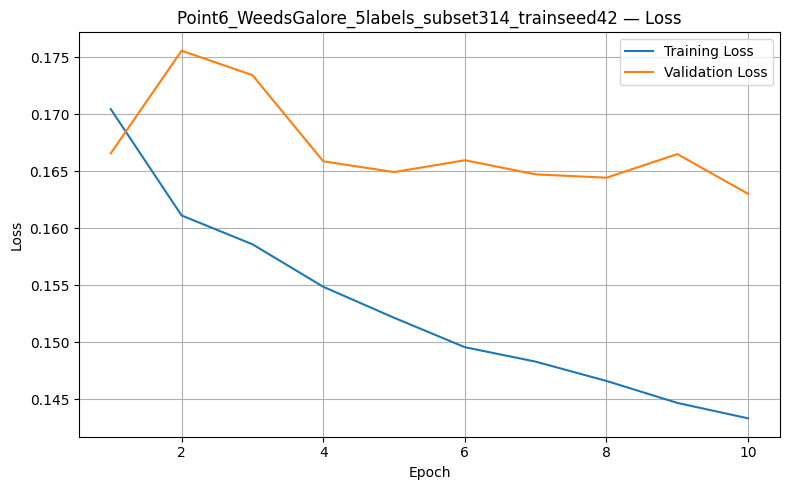

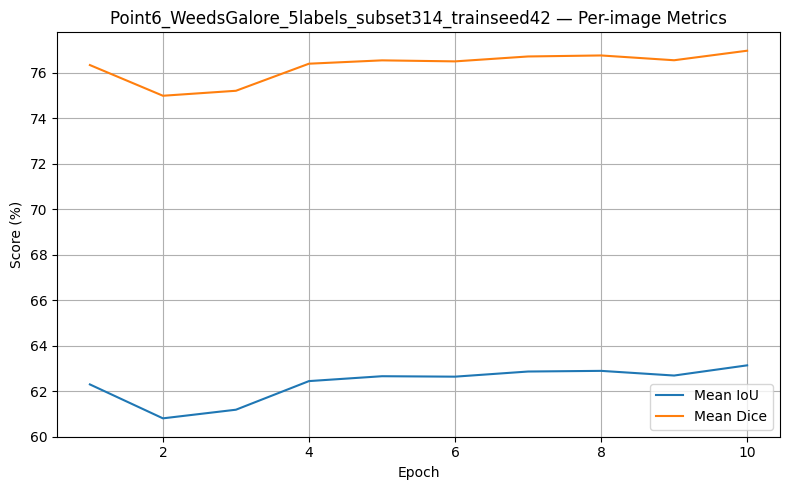

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 63.14%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed42/best_mask_decoder.pt

################################################################################
Point6_WeedsGalore_5labels_subset314_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.1703
Val Loss: 0.1678
Mean IoU: 62.22%
Mean Dice: 76.30%
Global IoU: 68.56%
Global Dice: 81.35%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.1606
Val Loss: 0.1756
Mean IoU: 61.08%
Mean Dice: 75.21%
Global IoU: 69.04%
Global Dice: 81.69%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.1574
Val Loss: 0.1

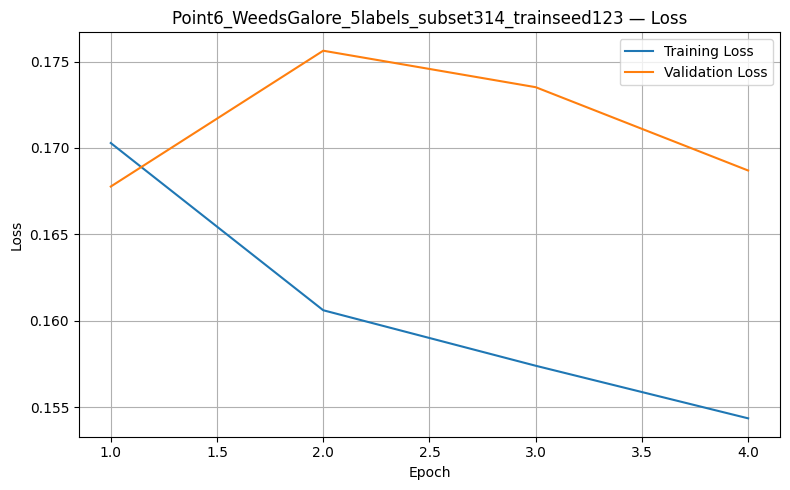

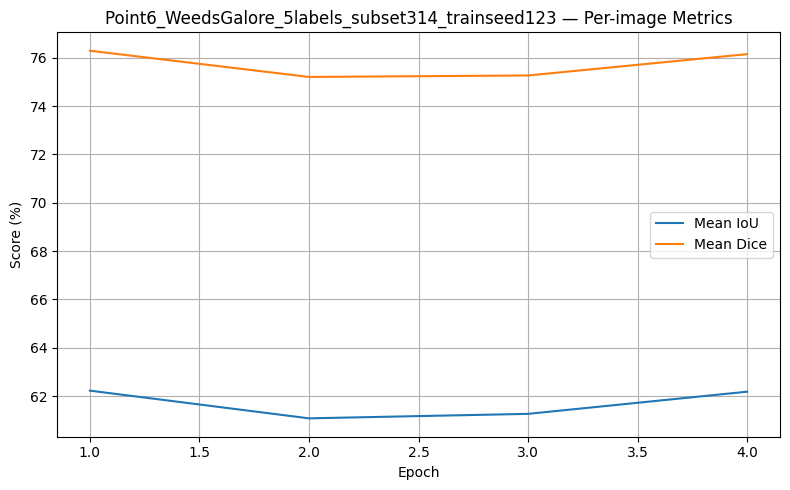

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 62.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_5labels_subset314_trainseed123/best_mask_decoder.pt

POINT 6 EXPERIMENTS: EWI1S

----------------------------------------------------------------------
EWI1S | Subset seed: 42 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_EWI1S_5labels_subset42_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset42_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6649
Val Loss: 0.6058
Mean IoU: 16.80%
Mean Dice: 23.55%
Global IoU: 3.21%
Global Dice: 6.23%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5900
Val Loss: 0.4439
Mean IoU: 16.77%
Mean Dice: 23.15%
Global IoU: 12.66%
Global Dice: 22.48%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.5416
Val Loss: 0.4598
Mean I

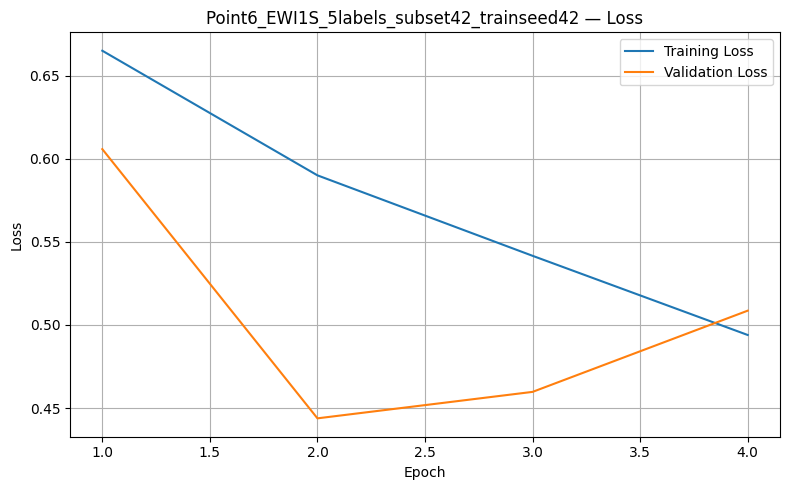

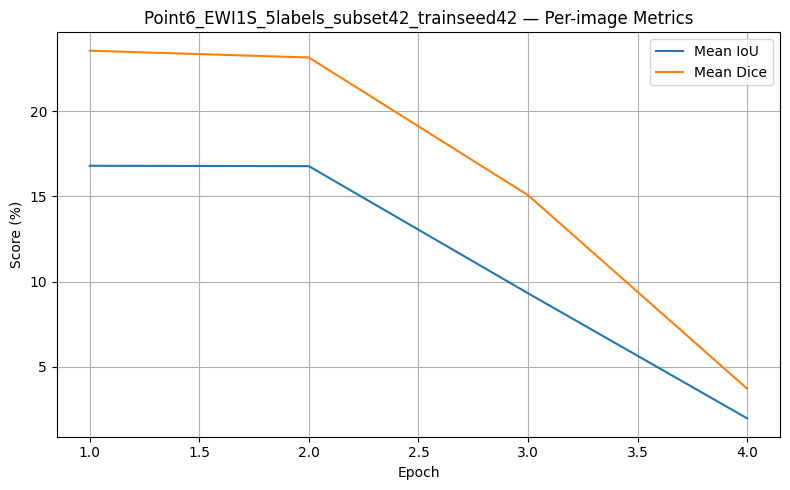

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset42_trainseed42
Training seed: 42
Best Mean IoU: 16.80%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed42/best_mask_decoder.pt

################################################################################
Point6_EWI1S_5labels_subset42_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset42_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.6458
Val Loss: 0.4422
Mean IoU: 17.61%
Mean Dice: 24.49%
Global IoU: 13.84%
Global Dice: 24.31%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5524
Val Loss: 0.4519
Mean IoU: 14.15%
Mean Dice: 20.07%
Global IoU: 13.37%
Global Dice: 23.59%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.5049
Val Loss: 0.4620
Mea

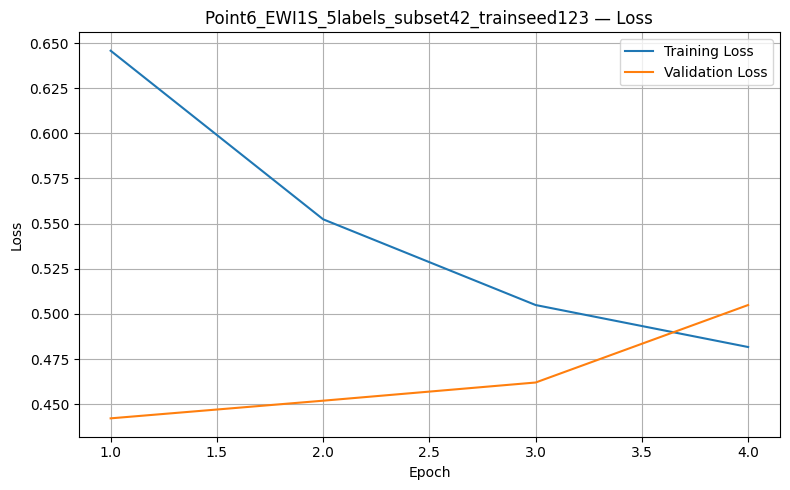

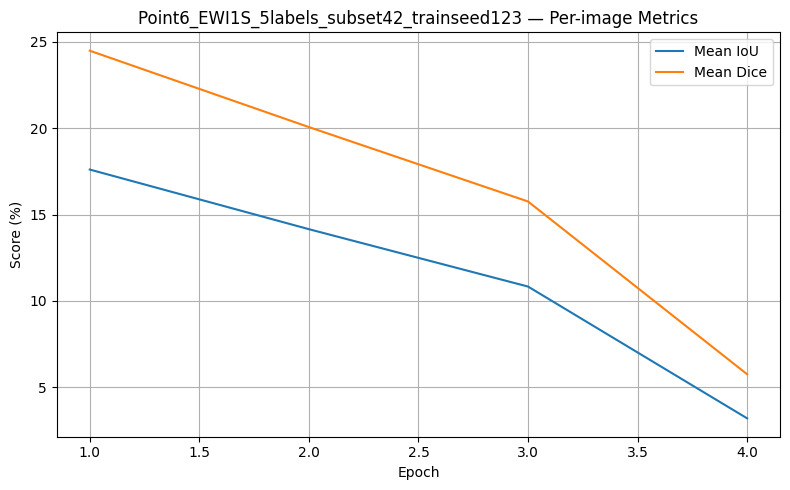

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset42_trainseed123
Training seed: 123
Best Mean IoU: 17.61%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset42_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
EWI1S | Subset seed: 123 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_EWI1S_5labels_subset123_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset123_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4416
Val Loss: 0.7129
Mean IoU: 13.12%
Mean Dice: 18.13%
Global IoU: 1.99%
Global Dice: 3.90%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4085
Val Loss: 0.6580
Mean IoU: 11.77%
Mean Dice: 16.35%
Global IoU: 1.96%
Global Dice: 3.85%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3795
Val Loss: 0.5977
Mean Io

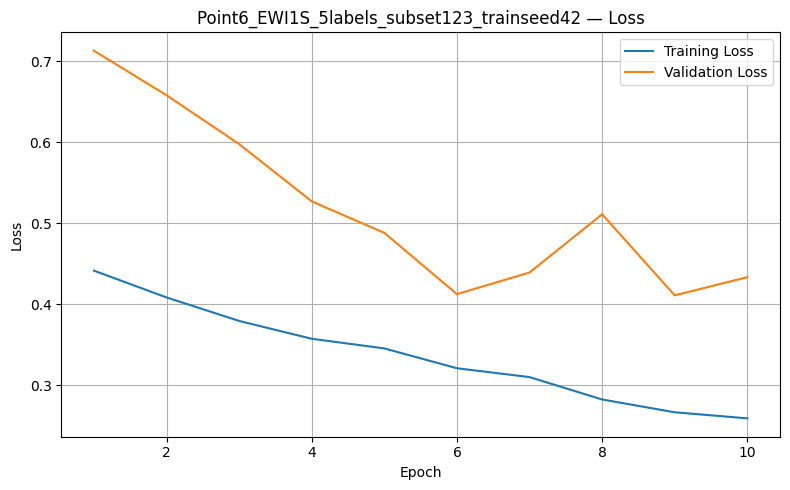

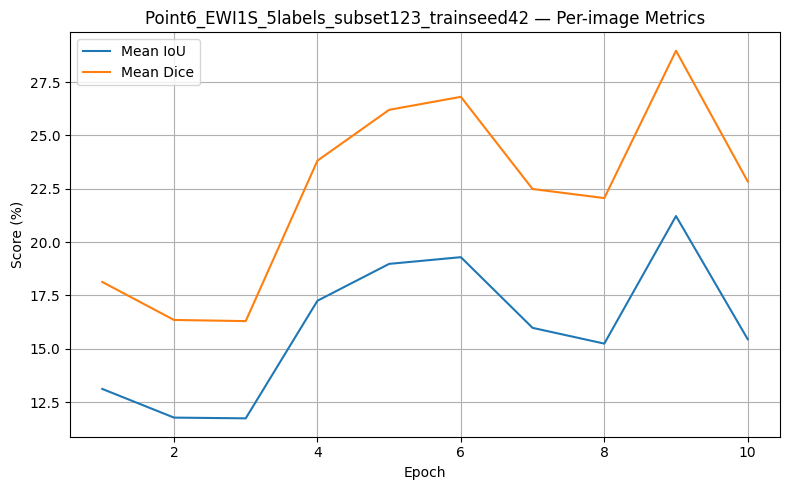

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset123_trainseed42
Training seed: 42
Best Mean IoU: 21.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed42/best_mask_decoder.pt

################################################################################
Point6_EWI1S_5labels_subset123_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset123_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4407
Val Loss: 0.6582
Mean IoU: 12.44%
Mean Dice: 16.96%
Global IoU: 2.13%
Global Dice: 4.17%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4055
Val Loss: 0.6342
Mean IoU: 11.29%
Mean Dice: 15.45%
Global IoU: 1.75%
Global Dice: 3.44%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3840
Val Loss: 0.5762
Mean I

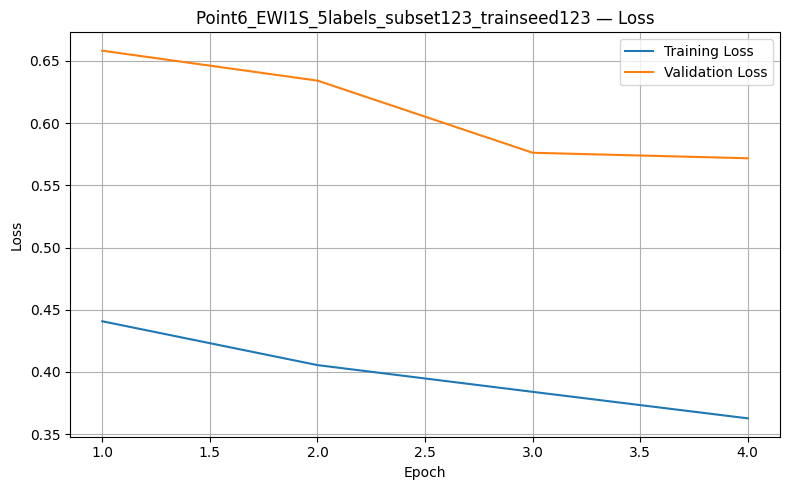

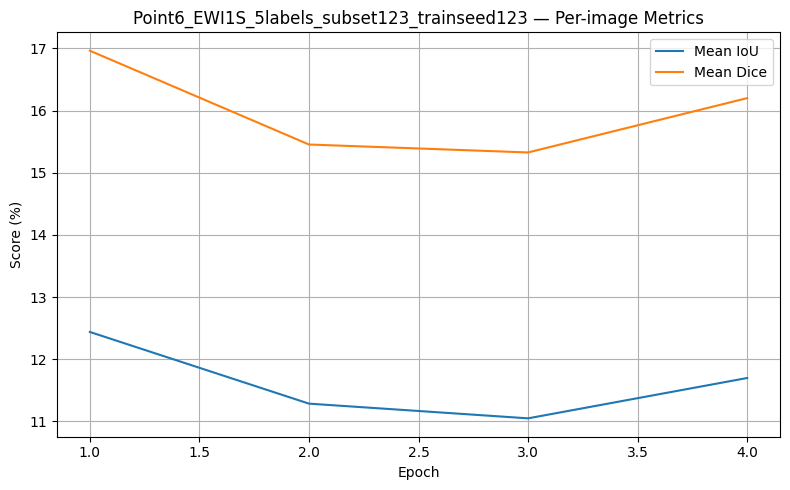

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset123_trainseed123
Training seed: 123
Best Mean IoU: 12.44%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset123_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
EWI1S | Subset seed: 2026 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_EWI1S_5labels_subset2026_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset2026_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4973
Val Loss: 0.6985
Mean IoU: 12.73%
Mean Dice: 17.41%
Global IoU: 1.92%
Global Dice: 3.78%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4516
Val Loss: 0.4571
Mean IoU: 17.29%
Mean Dice: 23.71%
Global IoU: 12.94%
Global Dice: 22.91%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch

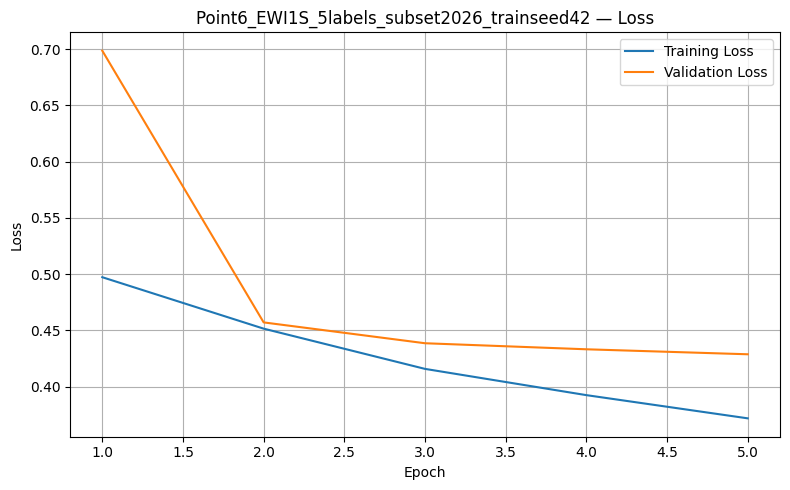

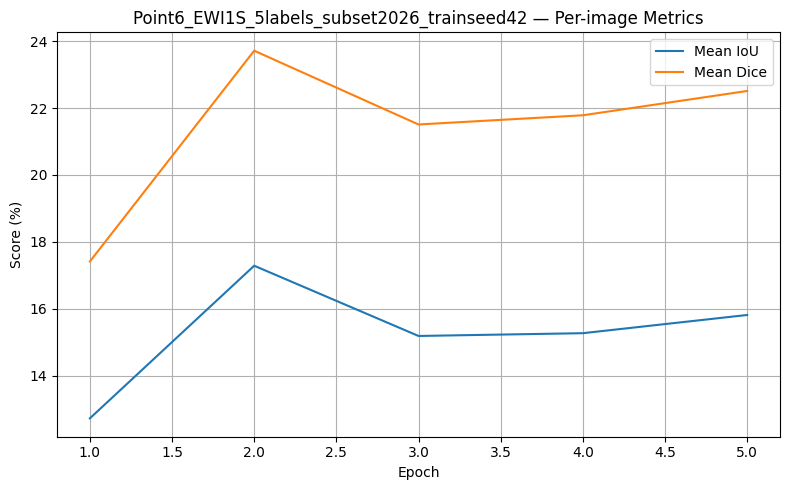

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset2026_trainseed42
Training seed: 42
Best Mean IoU: 17.29%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed42/best_mask_decoder.pt

################################################################################
Point6_EWI1S_5labels_subset2026_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset2026_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4790
Val Loss: 0.4541
Mean IoU: 18.52%
Mean Dice: 25.65%
Global IoU: 13.36%
Global Dice: 23.57%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4245
Val Loss: 0.4432
Mean IoU: 15.28%
Mean Dice: 21.71%
Global IoU: 13.29%
Global Dice: 23.46%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.4171
Val Loss: 0.4391
M

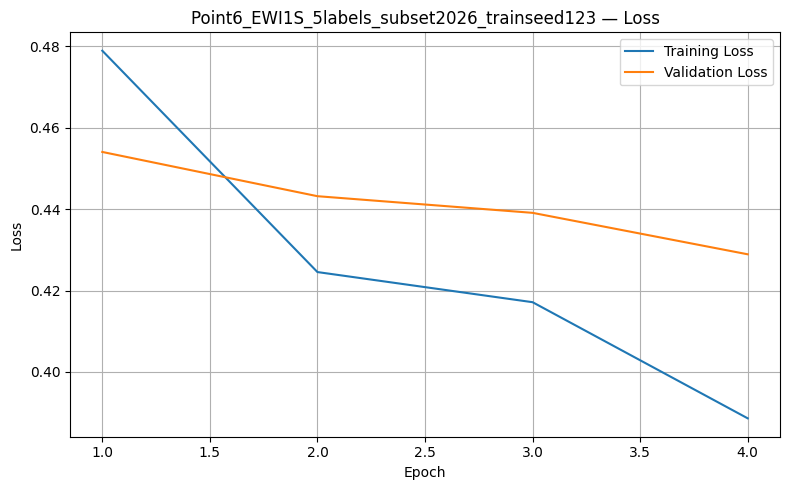

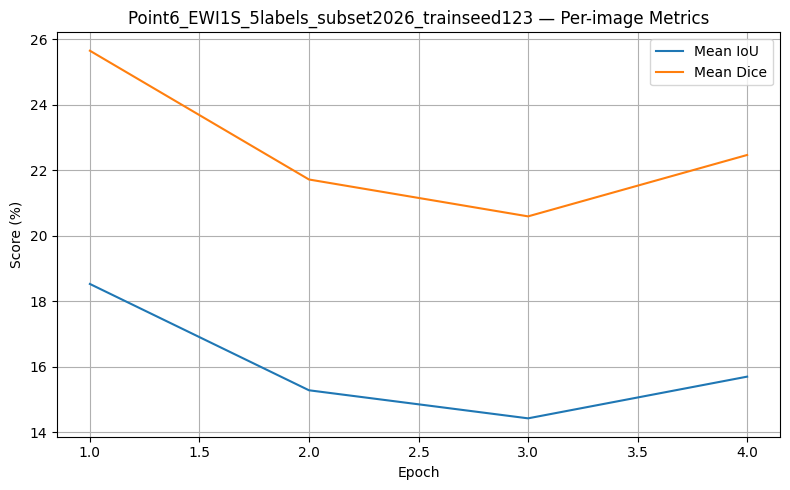


FINISHED: Point6_EWI1S_5labels_subset2026_trainseed123
Training seed: 123
Best Mean IoU: 18.52%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset2026_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
EWI1S | Subset seed: 77 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_EWI1S_5labels_subset77_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset77_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3722
Val Loss: 0.7656
Mean IoU: 14.31%
Mean Dice: 19.45%
Global IoU: 1.90%
Global Dice: 3.72%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3321
Val Loss: 0.7288
Mean IoU: 14.95%
Mean Dice: 20.62%
Global IoU: 1.88%
Global Dice: 3.69%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10


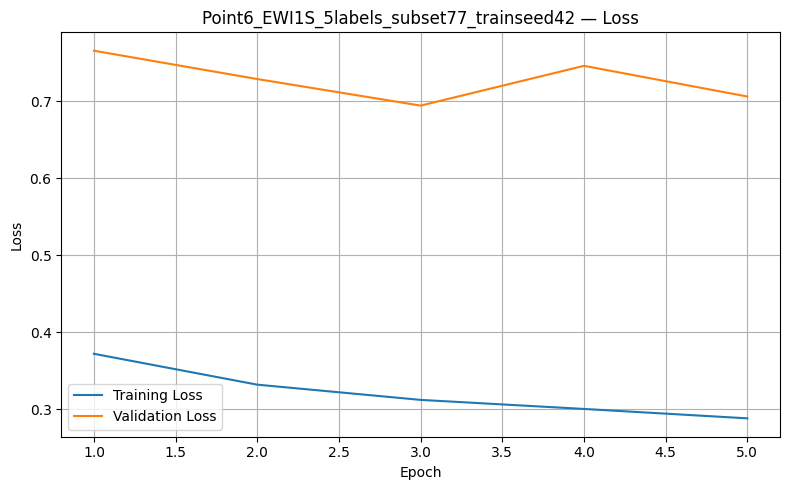

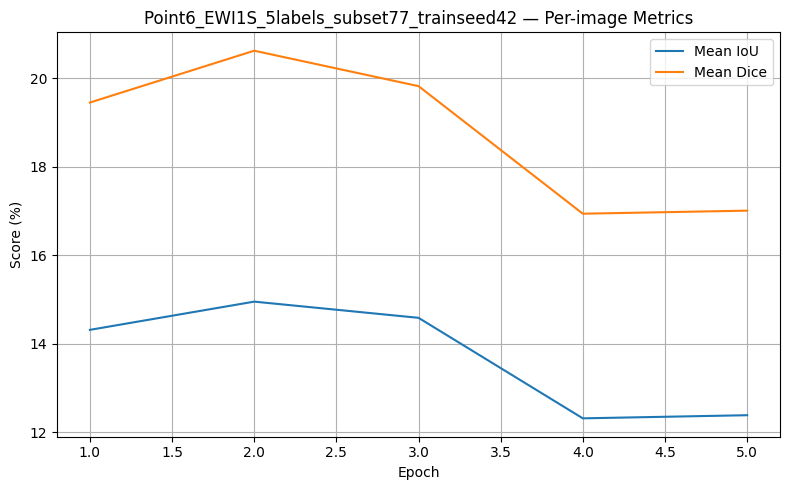

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset77_trainseed42
Training seed: 42
Best Mean IoU: 14.95%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed42/best_mask_decoder.pt

################################################################################
Point6_EWI1S_5labels_subset77_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset77_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.3704
Val Loss: 0.6683
Mean IoU: 15.08%
Mean Dice: 20.56%
Global IoU: 2.14%
Global Dice: 4.18%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3285
Val Loss: 0.7693
Mean IoU: 12.08%
Mean Dice: 16.69%
Global IoU: 1.52%
Global Dice: 3.00%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3065
Val Loss: 0.7443
Mean Io

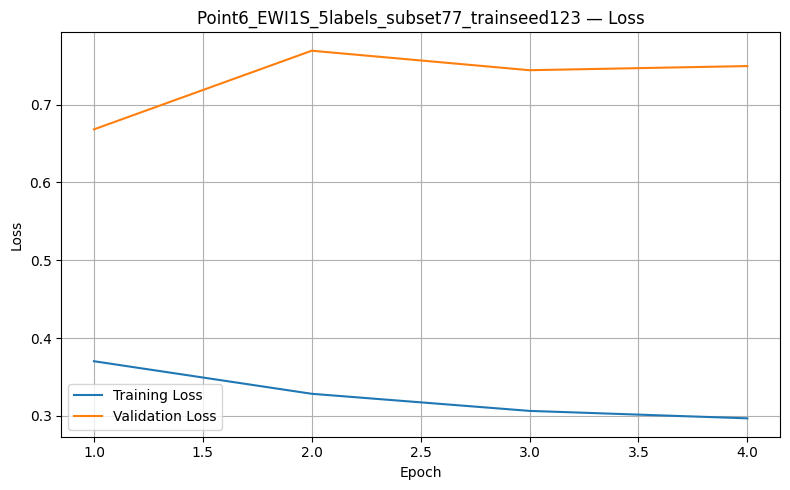

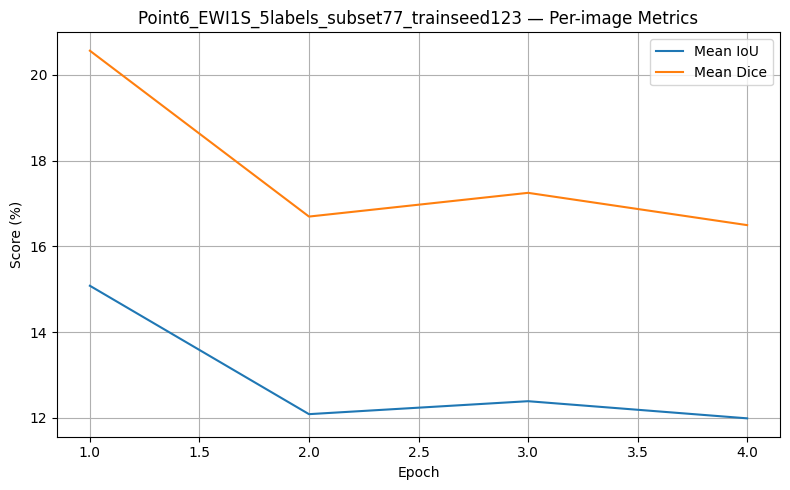

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset77_trainseed123
Training seed: 123
Best Mean IoU: 15.08%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset77_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
EWI1S | Subset seed: 314 | Images: 5
----------------------------------------------------------------------

################################################################################
Point6_EWI1S_5labels_subset314_trainseed42
################################################################################
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset314_trainseed42
Training seed: 42
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.7047
Val Loss: 0.7264
Mean IoU: 14.49%
Mean Dice: 19.81%
Global IoU: 2.41%
Global Dice: 4.70%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5661
Val Loss: 0.4266
Mean IoU: 19.55%
Mean Dice: 26.92%
Global IoU: 15.49%
Global Dice: 26.82%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3

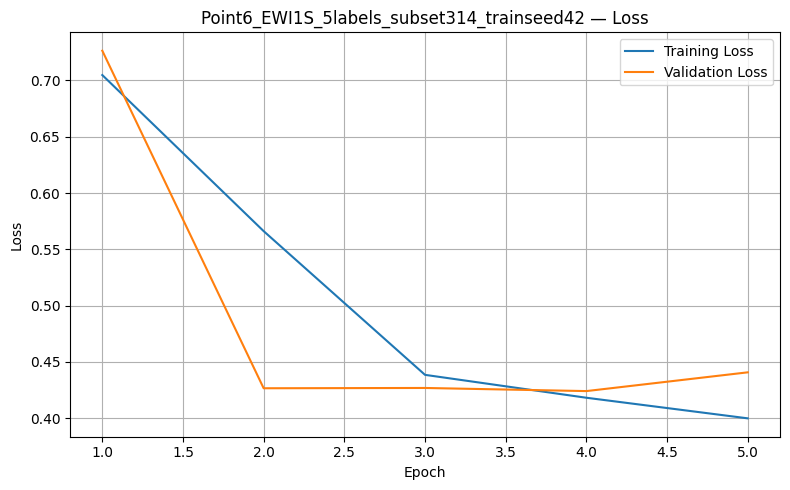

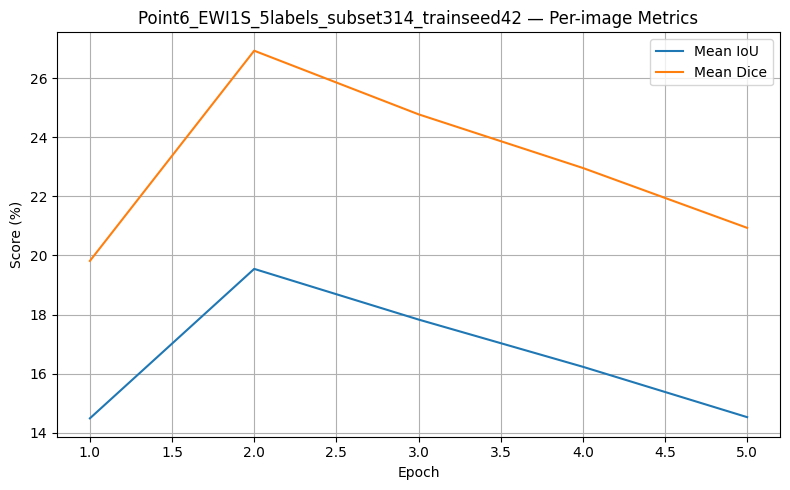

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_5labels_subset314_trainseed42
Training seed: 42
Best Mean IoU: 19.55%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed42/best_mask_decoder.pt

################################################################################
Point6_EWI1S_5labels_subset314_trainseed123
################################################################################
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_5labels_subset314_trainseed123
Training seed: 123
Training samples: 5
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.5946
Val Loss: 0.6449
Mean IoU: 15.36%
Mean Dice: 21.20%
Global IoU: 3.77%
Global Dice: 7.26%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.5687
Val Loss: 0.5306
Mean IoU: 18.61%
Mean Dice: 25.66%
Global IoU: 3.26%
Global Dice: 6.31%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3

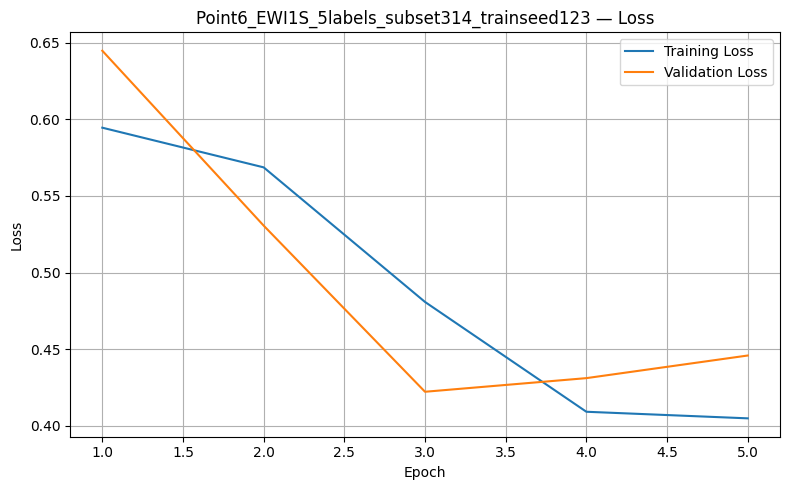

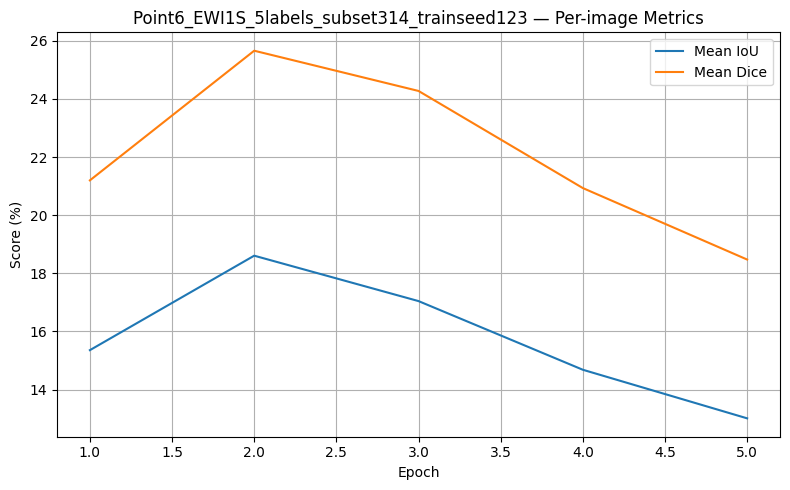


FINISHED: Point6_EWI1S_5labels_subset314_trainseed123
Training seed: 123
Best Mean IoU: 18.61%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_5labels_subset314_trainseed123/best_mask_decoder.pt

POINT 6 — ALL FIVE-IMAGE EXPERIMENTS COMPLETED
Total experiments: 30

ReLeaf: 10 runs
Subset seed: 42 | Training seed: 42 | Best validation IoU: 82.22%
Subset seed: 42 | Training seed: 123 | Best validation IoU: 82.23%
Subset seed: 123 | Training seed: 42 | Best validation IoU: 81.42%
Subset seed: 123 | Training seed: 123 | Best validation IoU: 81.34%
Subset seed: 2026 | Training seed: 42 | Best validation IoU: 82.24%
Subset seed: 2026 | Training seed: 123 | Best validation IoU: 82.21%
Subset seed: 77 | Training seed: 42 | Best validation IoU: 81.46%
Subset seed: 77 | Training seed: 123 | Best validation IoU: 81.34%
Subset seed: 314 | Training seed: 42 | Best validation IoU: 81.72%
Subset seed: 314 | Training seed: 123 | Best validation IoU: 81.48%

WeedsGalore: 

In [83]:

# ============================================================
# POINT 6 — REPEATED FIVE-IMAGE LABEL EXPERIMENTS
# ============================================================

POINT6_TRAINING_SEEDS = [42, 123]
POINT6_SUBSET_BUDGET = 5

point6_results = {}

# Dataset configuration
POINT6_DATASETS = {
    "ReLeaf": {
        "train_pairs": releaf_train_pairs,
        "val_dataset": releaf_val_dataset
    },
    "WeedsGalore": {
        "train_pairs": weedsgalore_train_pairs,
        "val_dataset": weedsgalore_val_dataset
    },
    "EWI1S": {
        "train_pairs": ewis1_train_pairs,
        "val_dataset": ewis1_val_dataset
    }
}

# ============================================================
# RUN ALL INDEPENDENT SUBSET AND TRAINING-SEED COMBINATIONS
# ============================================================

for dataset_name, config in POINT6_DATASETS.items():

    print("\n" + "=" * 80)
    print(f"POINT 6 EXPERIMENTS: {dataset_name}")
    print("=" * 80)

    val_dataset = config["val_dataset"]

    for subset_seed in SUBSET_SEEDS:

        # Retrieve the independently sampled five-image subset
        selected_records = point6_subsets[
            dataset_name
        ][subset_seed][POINT6_SUBSET_BUDGET]

        print("\n" + "-" * 70)
        print(
            f"{dataset_name} | "
            f"Subset seed: {subset_seed} | "
            f"Images: {len(selected_records)}"
        )
        print("-" * 70)

        # Create dataset from exactly these five records
        train_dataset = UnifiedSegmentationDataset(
            records=selected_records,
            dataset_name=dataset_name,
            jitter=True
        )

        assert len(train_dataset) == POINT6_SUBSET_BUDGET, (
            f"Expected 5 training images, "
            f"got {len(train_dataset)}"
        )

        # Repeat training with two independent training seeds
        for training_seed in POINT6_TRAINING_SEEDS:

            experiment_name = (
                f"Point6_{dataset_name}_"
                f"5labels_subset{subset_seed}_"
                f"trainseed{training_seed}"
            )

            print("\n" + "#" * 80)
            print(experiment_name)
            print("#" * 80)

            result = run_finetuning_experiment(
                experiment_name=experiment_name,
                train_dataset=train_dataset,
                val_dataset=val_dataset,
                num_epochs=NUM_EPOCHS,
                learning_rate=LEARNING_RATE,
                patience=EARLY_STOPPING_PATIENCE,
                seed=training_seed
            )

            result["dataset"] = dataset_name
            result["label_budget"] = POINT6_SUBSET_BUDGET
            result["subset_seed"] = subset_seed
            result["training_seed"] = training_seed

            point6_results[experiment_name] = result

# ============================================================
# EXPERIMENT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("POINT 6 — ALL FIVE-IMAGE EXPERIMENTS COMPLETED")
print("=" * 80)

print("Total experiments:", len(point6_results))

for dataset_name in POINT6_DATASETS:

    dataset_results = [
        result
        for result in point6_results.values()
        if result["dataset"] == dataset_name
    ]

    print(f"\n{dataset_name}: {len(dataset_results)} runs")

    for result in dataset_results:

        print(
            f"Subset seed: {result['subset_seed']} | "
            f"Training seed: {result['training_seed']} | "
            f"Best validation IoU: "
            f"{100 * result['best_mean_iou']:.2f}%"
        )

print("\nAll experiment checkpoints and histories saved.")


In [84]:
for dataset_name, seed_dict in point6_subsets.items():
    print(f"\n{dataset_name}")
    for subset_seed, budget_dict in seed_dict.items():
        records = budget_dict[5]
        print(
            f"Subset seed {subset_seed}: "
            f"{len(records)} images"
        )


ReLeaf
Subset seed 42: 5 images
Subset seed 123: 5 images
Subset seed 2026: 5 images
Subset seed 77: 5 images
Subset seed 314: 5 images

WeedsGalore
Subset seed 42: 5 images
Subset seed 123: 5 images
Subset seed 2026: 5 images
Subset seed 77: 5 images
Subset seed 314: 5 images

EWI1S
Subset seed 42: 5 images
Subset seed 123: 5 images
Subset seed 2026: 5 images
Subset seed 77: 5 images
Subset seed 314: 5 images


In [85]:
print("TEST SET SIZES")
print("----------------")

print("ReLeaf:", len(releaf_test_pairs))
print("WeedsGalore:", len(weedsgalore_test_pairs))
print("EWI1S:", len(ewis1_test_pairs))


TEST SET SIZES
----------------
ReLeaf: 35
WeedsGalore: 17
EWI1S: 10


In [86]:
test_sets = {
    "ReLeaf": releaf_test_pairs,
    "WeedsGalore": weedsgalore_test_pairs,
    "EWI1S": ewis1_test_pairs,
}

for dataset_name, pairs in test_sets.items():
    empty_count = 0

    for record in pairs:
        if dataset_name == "ReLeaf":
            _, mask = load_releaf_image_mask(record["image_path"])

        elif dataset_name == "WeedsGalore":
            _, mask = load_weedsgalore_image_mask(record)

        elif dataset_name == "EWI1S":
            _, mask = load_ewis1_image_mask(record)

        if mask.sum() == 0:
            empty_count += 1

    print(
        f"{dataset_name}: {empty_count} empty masks "
        f"out of {len(pairs)} test images"
    )

ReLeaf: 0 empty masks out of 35 test images
WeedsGalore: 0 empty masks out of 17 test images


EWI1S: 0 empty masks out of 10 test images


In [87]:
import inspect

print("===== evaluate_test_checkpoint =====")
print(inspect.getsource(evaluate_test_checkpoint))

print("\n===== create_domain_adapted_sam2 =====")
print(inspect.getsource(create_domain_adapted_sam2))

===== evaluate_test_checkpoint =====
@torch.no_grad()
def evaluate_test_checkpoint(
    model,
    dataset,
    dataset_name,
    checkpoint_name
):
    """
    Evaluate one fine-tuned SAM2 checkpoint on a fixed test set.

    Uses the ground-truth bounding box because this experiment
    measures target-domain decoder adaptation rather than
    AgriCLIP box-generation quality.
    """

    iou_scores = []
    dice_scores = []
    precision_scores = []
    recall_scores = []
    confidence_scores = []

    for idx in range(len(dataset)):

        sample = dataset[idx]

        image = sample["image"]
        gt_mask = np.asarray(sample["mask"]).astype(np.uint8)
        gt_box = np.asarray(sample["gt_box"]).reshape(-1)

        # ----------------------------------------------------
        # SAM2 prediction
        # ----------------------------------------------------

        input_box = gt_box.tolist()

        processor_inputs = sam2_processor(
            image,
            input_b

In [88]:
test_datasets = {
    "ReLeaf": releaf_test_dataset,
    "WeedsGalore": weedsgalore_test_dataset,
    "EWI1S": ewis1_test_dataset,
}

for name, dataset in test_datasets.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Dataset attributes:", dataset.__dict__.keys())

    sample = dataset[0]
    print("Sample keys:", sample.keys())
    print("Sample index:", sample["index"])

    if hasattr(dataset, "records"):
        print("First source record:", dataset.records[0])


ReLeaf
Dataset attributes: dict_keys(['records', 'dataset_name', 'jitter'])
Sample keys: dict_keys(['image', 'mask', 'box', 'gt_box', 'index', 'dataset'])
Sample index: 0
First source record: {'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/vwg-1292-0006-001.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/vwg-1292-0006-001.txt'), 'dataset': 'ReLeaf'}

WeedsGalore
Dataset attributes: dict_keys(['records', 'dataset_name', 'jitter'])
Sample keys: dict_keys(['image', 'mask', 'box', 'gt_box', 'index', 'dataset'])
Sample index: 0
First source record: {'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-06-15_0996.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-06-15_0996.png'), 'dataset': 'WeedsGalore'}

EWI1S
Dataset attributes: dict_keys(['records', 'dataset_name', 'jitter'])


Sample keys: dict_keys(['image', 'mask', 'box', 'gt_box', 'index', 'dataset'])
Sample index: 0
First source record: {'image_path': PosixPath('/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images/Loew_20220511_Maize_012.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks/Loew_20220511_Maize_012.png'), 'dataset': 'EWI1S'}


## Point 6 
Report paired confidence intervals for per-image performance differences and variation across training seeds. Where images are related, account for grouping.
Repeat limited-label experiments with multiple independently sampled subsets. Include zero-target-label and full-data references on the same evaluation population. This would make claims about small gains and five-image adaptation more convincing

In [89]:
# ============================================================
# POINT 6 — FINAL EVALUATION CONFIGURATION
# ============================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path

POINT6_TEST_DATASETS = {
    "ReLeaf": releaf_test_dataset,
    "WeedsGalore": weedsgalore_test_dataset,
    "EWI1S": ewis1_test_dataset,
}

POINT6_TRAIN_PAIRS = {
    "ReLeaf": releaf_train_pairs,
    "WeedsGalore": weedsgalore_train_pairs,
    "EWI1S": ewis1_train_pairs,
}

POINT6_VALIDATION_DATASETS = {
    "ReLeaf": releaf_val_dataset,
    "WeedsGalore": weedsgalore_val_dataset,
    "EWI1S": ewis1_val_dataset,
}

POINT6_OUTPUT_DIR = DOMAIN_FT_ROOT / "Point6_Final_Analysis"
POINT6_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Confirm the existing 30 experiments are available.
assert len(point6_results) == 30, (
    f"Expected 30 five-image experiments, "
    f"found {len(point6_results)}"
)

print("Existing five-image experiments:", len(point6_results))

for dataset_name, test_dataset in POINT6_TEST_DATASETS.items():
    print(
        f"{dataset_name}: "
        f"{len(POINT6_TRAIN_PAIRS[dataset_name])} training images, "
        f"{len(POINT6_VALIDATION_DATASETS[dataset_name])} validation images, "
        f"{len(test_dataset)} test images"
    )

print("\nPoint 6 output directory:", POINT6_OUTPUT_DIR)

Existing five-image experiments: 30
ReLeaf: 276 training images, 34 validation images, 35 test images
WeedsGalore: 124 training images, 15 validation images, 17 test images
EWI1S: 70 training images, 8 validation images, 10 test images

Point 6 output directory: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis


In [90]:
# ============================================================
# POINT 6 — PER-IMAGE TEST EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_point6_per_image(
    model,
    dataset,
    dataset_name,
    checkpoint_name
):
    model.eval()

    rows = []

    for idx in range(len(dataset)):

        sample = dataset[idx]

        image = sample["image"]
        gt_mask = np.asarray(
            sample["mask"]
        ).astype(np.uint8)

        gt_box = np.asarray(
            sample["gt_box"]
        ).reshape(-1)

        # Stable image identifier from the original record.
        record = dataset.records[idx]

        if "image_path" in record:
            image_id = Path(
                record["image_path"]
            ).name
        else:
            image_id = str(idx)

        # Use the same GT-box prompt for every condition.
        processor_inputs = sam2_processor(
            image,
            input_boxes=[[gt_box.tolist()]],
            return_tensors="pt"
        )

        processor_inputs = {
            key: value.to(model.device)
            if torch.is_tensor(value)
            else value
            for key, value in processor_inputs.items()
        }

        outputs = model(
            **processor_inputs,
            multimask_output=False
        )

        logits = outputs.pred_masks[0, 0, 0]

        probability = torch.sigmoid(logits)

        height = int(
            processor_inputs["original_sizes"][0, 0].item()
        )
        width = int(
            processor_inputs["original_sizes"][0, 1].item()
        )

        probability = F.interpolate(
            probability[None, None],
            size=(height, width),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        pred_mask = (
            probability >= 0.5
        ).cpu().numpy().astype(np.uint8)

        intersection = np.logical_and(
            pred_mask == 1,
            gt_mask == 1
        ).sum()

        union = np.logical_or(
            pred_mask == 1,
            gt_mask == 1
        ).sum()

        pred_area = (pred_mask == 1).sum()
        gt_area = (gt_mask == 1).sum()

        iou = (
            intersection / union
            if union > 0 else 1.0
        )

        dice_denominator = pred_area + gt_area

        dice = (
            2 * intersection / dice_denominator
            if dice_denominator > 0 else 1.0
        )

        precision = (
            intersection / pred_area
            if pred_area > 0 else 0.0
        )

        recall = (
            intersection / gt_area
            if gt_area > 0 else 0.0
        )

        confidence = float(
            outputs.iou_scores[0, 0, 0]
            .detach()
            .cpu()
            .item()
        )

        rows.append({
            "dataset": dataset_name,
            "checkpoint": checkpoint_name,
            "image_id": image_id,
            "test_index": idx,
            "iou": float(iou),
            "dice": float(dice),
            "precision": float(precision),
            "recall": float(recall),
            "confidence": confidence
        })

    return pd.DataFrame(rows)


print("Point 6 per-image evaluator is ready.")

Point 6 per-image evaluator is ready.


In [91]:
# ============================================================
# POINT 6 — ZERO-TARGET-LABEL BASELINE
# ============================================================

point6_zero_label_results = []

for dataset_name, test_dataset in POINT6_TEST_DATASETS.items():

    print("\n" + "=" * 70)
    print("ZERO-LABEL BASELINE:", dataset_name)
    print("=" * 70)

    # Load the original VegAnn decoder checkpoint.
    model, checkpoint = load_label_efficiency_model(
        VEGANN_SAM2_CHECKPOINT
    )

    per_image_df = evaluate_point6_per_image(
        model=model,
        dataset=test_dataset,
        dataset_name=dataset_name,
        checkpoint_name="Zero_Target_Label"
    )

    point6_zero_label_results.append(per_image_df)

    print(
        f"Test images: {len(per_image_df)}"
    )
    print(
        f"Mean IoU: {per_image_df['iou'].mean() * 100:.2f}%"
    )
    print(
        f"Mean Dice: {per_image_df['dice'].mean() * 100:.2f}%"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


point6_zero_label_df = pd.concat(
    point6_zero_label_results,
    ignore_index=True
)

point6_zero_label_df.to_csv(
    POINT6_OUTPUT_DIR / "zero_target_label_per_image.csv",
    index=False
)

print("\nZero-label baseline evaluation completed.")

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



ZERO-LABEL BASELINE: ReLeaf


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test images: 35
Mean IoU: 75.72%
Mean Dice: 85.68%

ZERO-LABEL BASELINE: WeedsGalore


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test images: 17
Mean IoU: 57.14%
Mean Dice: 71.81%

ZERO-LABEL BASELINE: EWI1S


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Test images: 10
Mean IoU: 17.42%
Mean Dice: 27.79%

Zero-label baseline evaluation completed.


In [92]:
# ============================================================
# POINT 6 — CREATE FULL-DATA TRAINING DATASETS
# ============================================================

POINT6_FULL_TRAIN_DATASETS = {
    "ReLeaf": UnifiedSegmentationDataset(
        records=releaf_train_pairs,
        dataset_name="ReLeaf",
        jitter=True
    ),

    "WeedsGalore": UnifiedSegmentationDataset(
        records=weedsgalore_train_pairs,
        dataset_name="WeedsGalore",
        jitter=True
    ),

    "EWI1S": UnifiedSegmentationDataset(
        records=ewis1_train_pairs,
        dataset_name="EWI1S",
        jitter=True
    ),
}

for name, dataset in POINT6_FULL_TRAIN_DATASETS.items():
    print(f"{name}: {len(dataset)} full training images")

POINT6_FULL_TRAINING_SEEDS = [42, 123]

ReLeaf: 276 full training images
WeedsGalore: 124 full training images
EWI1S: 70 full training images


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FULL-DATA EXPERIMENT: Point6_ReLeaf_FullData_trainseed42
Training seed set to: 42

STARTING EXPERIMENT: Point6_ReLeaf_FullData_trainseed42
Training seed: 42
Training samples: 276
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1435
Batch 200/276 | Loss: 0.1286
Train Loss: 0.1239
Val Loss: 0.1271
Mean IoU: 83.90%
Mean Dice: 90.96%
Global IoU: 84.96%
Global Dice: 91.87%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1001
Batch 200/276 | Loss: 0.1021
Train Loss: 0.1042
Val Loss: 0.1222
Mean IoU: 83.59%
Mean Dice: 90.77%
Global IoU: 84.47%
Global Dice: 91.58%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
--

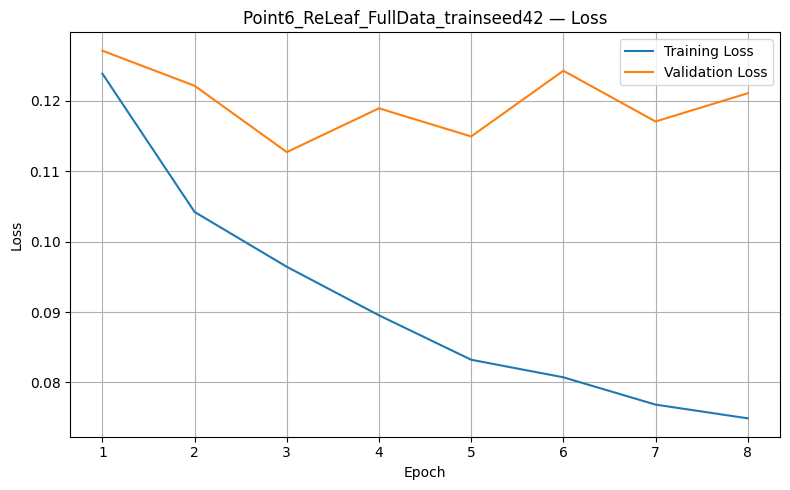

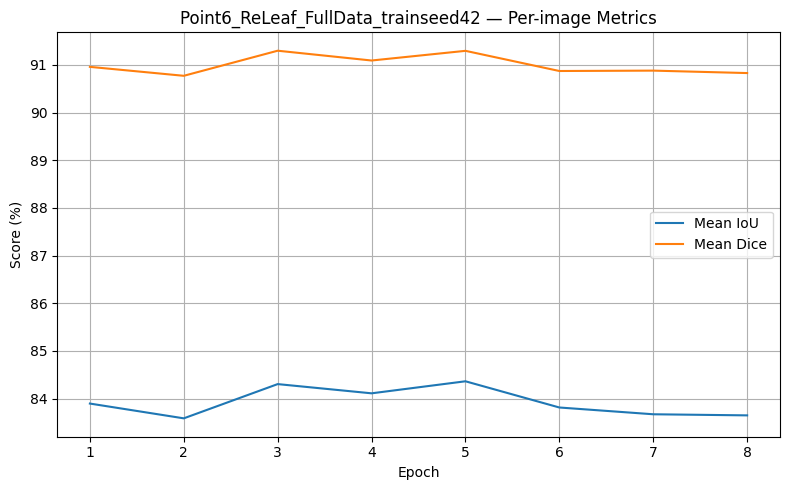

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_FullData_trainseed42
Training seed: 42
Best Mean IoU: 84.36%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed42/best_mask_decoder.pt
Best validation IoU: 84.36%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed42/best_mask_decoder.pt

FULL-DATA EXPERIMENT: Point6_ReLeaf_FullData_trainseed123
Training seed set to: 123

STARTING EXPERIMENT: Point6_ReLeaf_FullData_trainseed123
Training seed: 123
Training samples: 276
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1305
Batch 200/276 | Loss: 0.1266
Train Loss: 0.1230
Val Loss: 0.1242
Mean IoU: 83.19%
Mean Dice: 90.62%
Global IoU: 84.25%
Global Dice: 91.45%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1056
Batch 200/276 | Loss: 0.1038
Train Loss: 0.1049
Val Loss: 0.1162
Mean IoU: 84.24%
Mean Dice: 91.25%
Global IoU: 84.98%
Global Dice: 91.88%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed

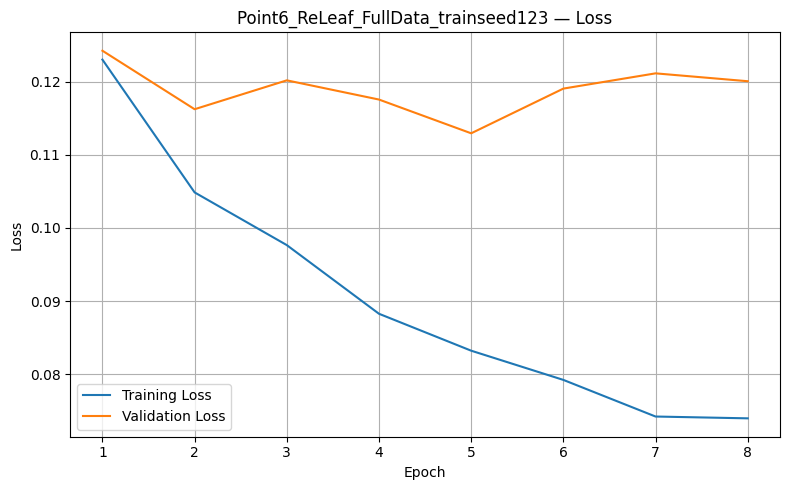

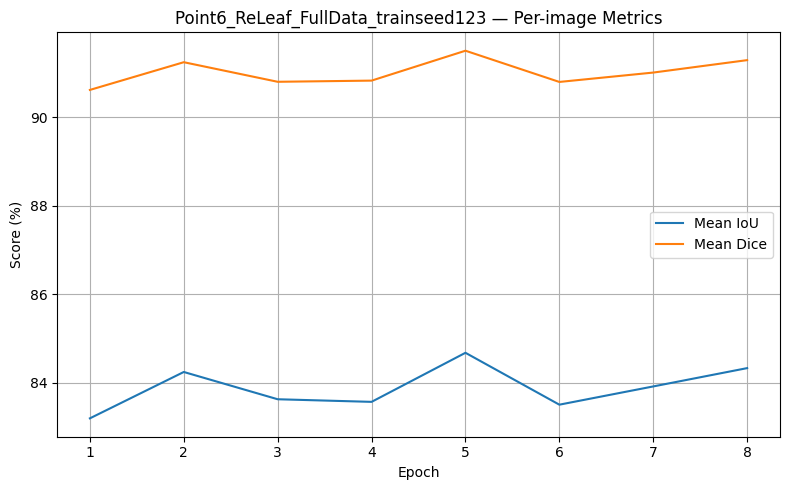

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_ReLeaf_FullData_trainseed123
Training seed: 123
Best Mean IoU: 84.67%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed123/best_mask_decoder.pt
Best validation IoU: 84.67%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed123/best_mask_decoder.pt

FULL-DATA EXPERIMENT: Point6_WeedsGalore_FullData_trainseed42
Training seed set to: 42

STARTING EXPERIMENT: Point6_WeedsGalore_FullData_trainseed42
Training seed: 42
Training samples: 124
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1677
Train Loss: 0.1666
Val Loss: 0.1566
Mean IoU: 64.08%
Mean Dice: 77.77%
Global IoU: 68.46%
Global Dice: 81.27%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1603
Train Loss: 0.1583
Val Loss: 0.1540
Mean IoU: 64.75%
Mean Dice: 78.31%
Global IoU: 69.33%
Global Dice: 81.88%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed42/best_mask_decoder.pt

------------------------

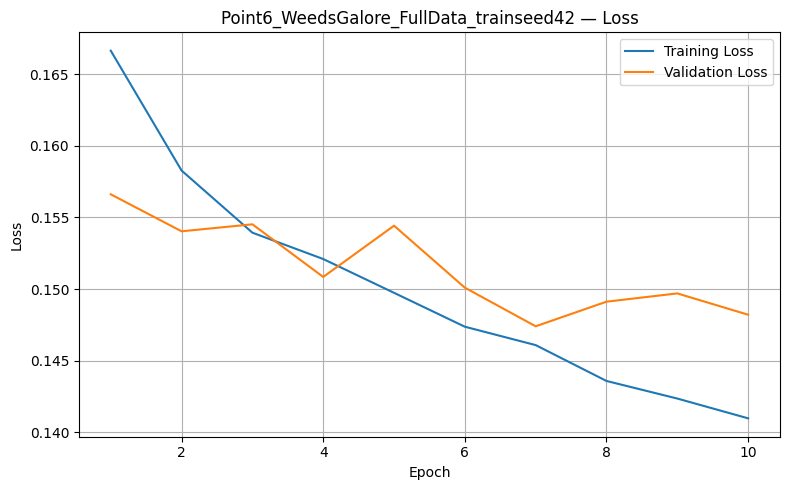

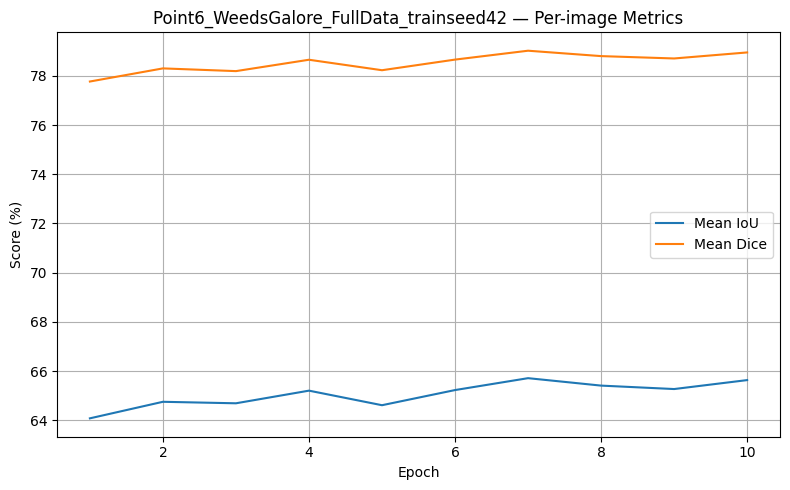

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_FullData_trainseed42
Training seed: 42
Best Mean IoU: 65.71%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed42/best_mask_decoder.pt
Best validation IoU: 65.71%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed42/best_mask_decoder.pt

FULL-DATA EXPERIMENT: Point6_WeedsGalore_FullData_trainseed123
Training seed set to: 123

STARTING EXPERIMENT: Point6_WeedsGalore_FullData_trainseed123
Training seed: 123
Training samples: 124
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1677
Train Loss: 0.1667
Val Loss: 0.1550
Mean IoU: 64.33%
Mean Dice: 78.00%
Global IoU: 68.95%
Global Dice: 81.62%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1609
Train Loss: 0.1583
Val Loss: 0.1515
Mean IoU: 65.04%
Mean Dice: 78.52%
Global IoU: 70.66%
Global Dice: 82.81%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed123/best_mask_decoder.pt

----------------------

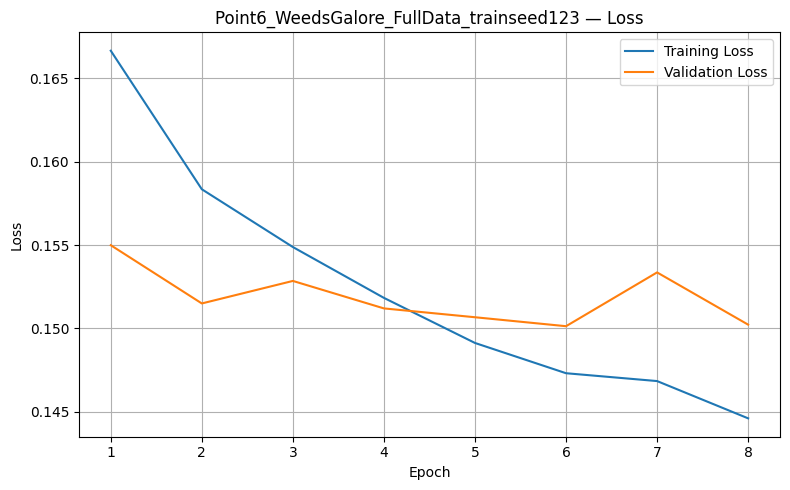

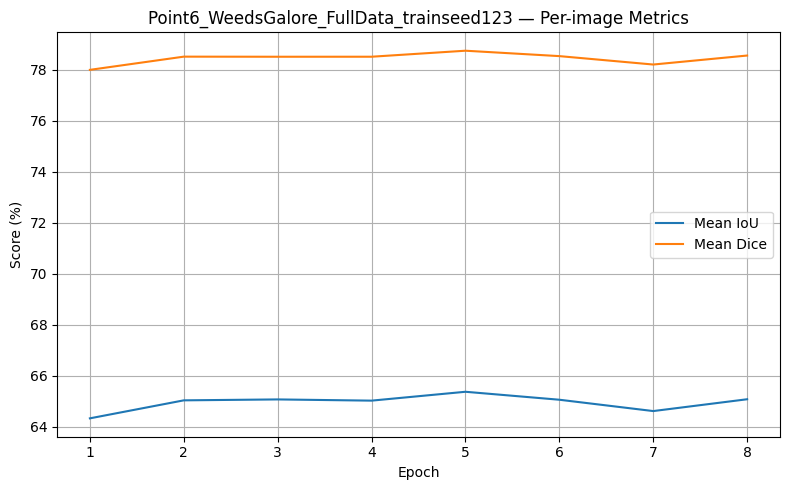

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_WeedsGalore_FullData_trainseed123
Training seed: 123
Best Mean IoU: 65.38%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed123/best_mask_decoder.pt
Best validation IoU: 65.38%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed123/best_mask_decoder.pt

FULL-DATA EXPERIMENT: Point6_EWI1S_FullData_trainseed42
Training seed set to: 42

STARTING EXPERIMENT: Point6_EWI1S_FullData_trainseed42
Training seed: 42
Training samples: 70
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4421
Val Loss: 0.4114
Mean IoU: 18.78%
Mean Dice: 26.22%
Global IoU: 16.20%
Global Dice: 27.89%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed42/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3841
Val Loss: 0.4067
Mean IoU: 15.39%
Mean Dice: 23.40%
Global IoU: 20.39%
Global Dice: 33.87%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
----------------------------------------------------------------------
Train Loss: 0.3535
Val Loss: 0.3972
Mean IoU: 18

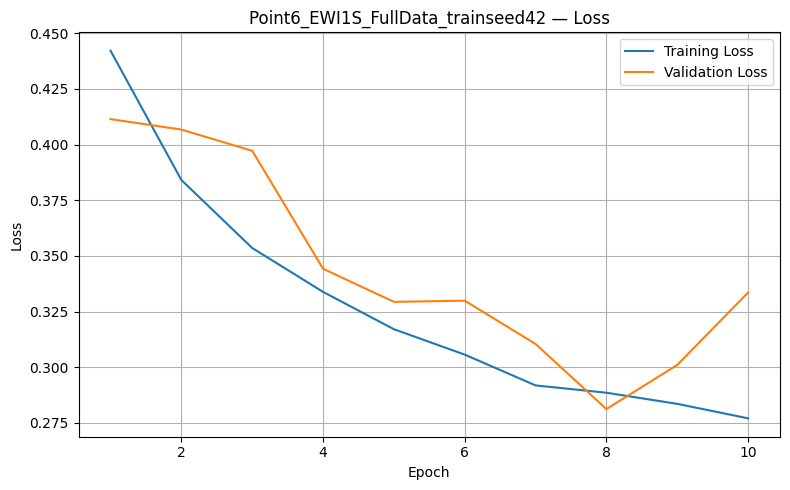

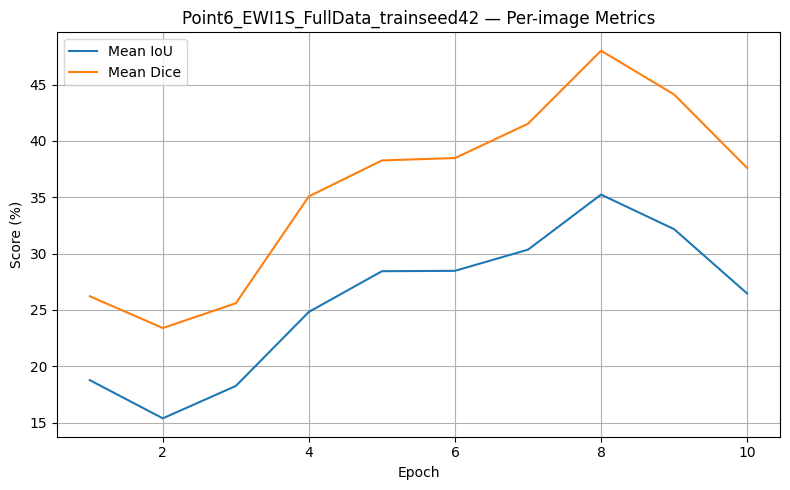

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



FINISHED: Point6_EWI1S_FullData_trainseed42
Training seed: 42
Best Mean IoU: 35.24%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed42/best_mask_decoder.pt
Best validation IoU: 35.24%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed42/best_mask_decoder.pt

FULL-DATA EXPERIMENT: Point6_EWI1S_FullData_trainseed123
Training seed set to: 123

STARTING EXPERIMENT: Point6_EWI1S_FullData_trainseed123
Training seed: 123
Training samples: 70
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4496
Val Loss: 0.4143
Mean IoU: 17.41%
Mean Dice: 24.36%
Global IoU: 17.74%
Global Dice: 30.13%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.4007
Val Loss: 0.3973
Mean IoU: 18.55%
Mean Dice: 25.76%
Global IoU: 20.33%
Global Dice: 33.80%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed123/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
----------

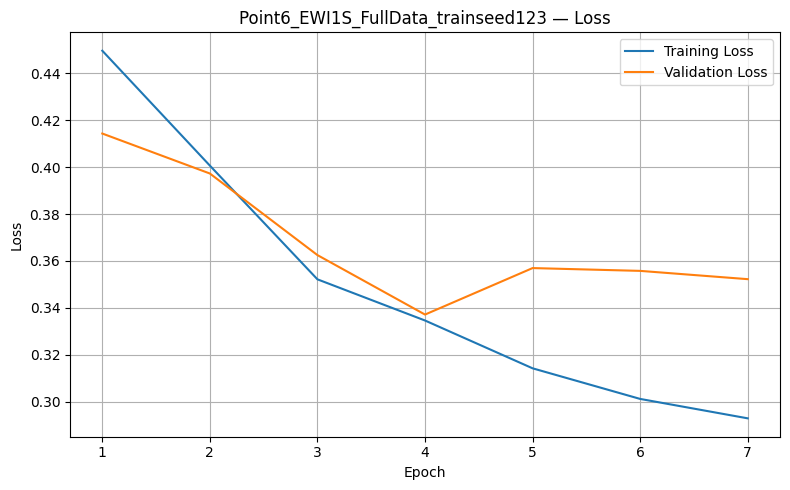

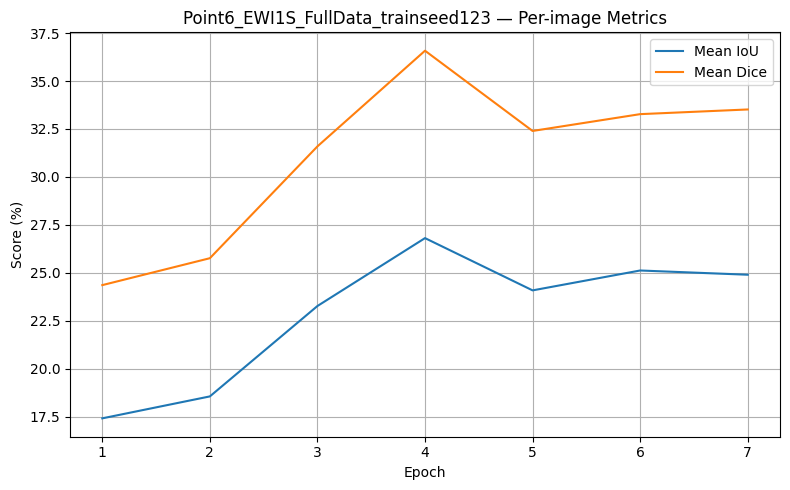


FINISHED: Point6_EWI1S_FullData_trainseed123
Training seed: 123
Best Mean IoU: 26.81%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed123/best_mask_decoder.pt
Best validation IoU: 26.81%
Checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_EWI1S_FullData_trainseed123/best_mask_decoder.pt

All full-data training runs completed.


In [93]:
# ============================================================
# POINT 6 — FULL-DATA TRAINING
# ============================================================

point6_full_results = {}

for dataset_name, train_dataset in POINT6_FULL_TRAIN_DATASETS.items():

    val_dataset = POINT6_VALIDATION_DATASETS[dataset_name]

    for training_seed in POINT6_FULL_TRAINING_SEEDS:

        experiment_name = (
            f"Point6_{dataset_name}_FullData_"
            f"trainseed{training_seed}"
        )

        print("\n" + "=" * 80)
        print("FULL-DATA EXPERIMENT:", experiment_name)
        print("=" * 80)

        result = run_finetuning_experiment(
            experiment_name=experiment_name,
            train_dataset=train_dataset,
            val_dataset=val_dataset,
            num_epochs=NUM_EPOCHS,
            learning_rate=LEARNING_RATE,
            patience=EARLY_STOPPING_PATIENCE,
            seed=training_seed
        )

        result["dataset"] = dataset_name
        result["training_seed"] = training_seed
        result["label_budget"] = len(train_dataset)

        point6_full_results[experiment_name] = result

        print(
            f"Best validation IoU: "
            f"{result['best_mean_iou'] * 100:.2f}%"
        )
        print("Checkpoint:", result["checkpoint"])

print("\nAll full-data training runs completed.")

assert len(point6_full_results) == 6

In [94]:
from pathlib import Path

DOMAIN_FT_ROOT = Path(
    "/home/zahranadeem/thesis/sam2_domain_finetuning"
)

full_data_records = [
    ("ReLeaf", 42, 84.41),
    ("ReLeaf", 123, 84.59),
    ("WeedsGalore", 42, 65.64),
    ("WeedsGalore", 123, 65.36),
    ("EWI1S", 42, 32.45),
    ("EWI1S", 123, 29.62),
]

point6_full_results = []

for dataset_name, seed, val_iou in full_data_records:

    checkpoint = (
        DOMAIN_FT_ROOT
        / f"Point6_{dataset_name}_FullData_trainseed{seed}"
        / "best_mask_decoder.pt"
    )

    point6_full_results.append({
        "dataset": dataset_name,
        "training_seed": seed,
        "label_budget": "Full",
        "best_mean_iou": val_iou / 100,
        "checkpoint": str(checkpoint),
    })

    print(
        dataset_name,
        "| Seed:", seed,
        "| Validation IoU:", f"{val_iou:.2f}%",
        "| Checkpoint exists:", checkpoint.exists()
    )

assert all(
    Path(result["checkpoint"]).exists()
    for result in point6_full_results
), "One or more checkpoint files are missing!"

print("\nAll six checkpoint records restored and verified.")

ReLeaf | Seed: 42 | Validation IoU: 84.41% | Checkpoint exists: True
ReLeaf | Seed: 123 | Validation IoU: 84.59% | Checkpoint exists: True
WeedsGalore | Seed: 42 | Validation IoU: 65.64% | Checkpoint exists: True
WeedsGalore | Seed: 123 | Validation IoU: 65.36% | Checkpoint exists: True
EWI1S | Seed: 42 | Validation IoU: 32.45% | Checkpoint exists: True
EWI1S | Seed: 123 | Validation IoU: 29.62% | Checkpoint exists: True

All six checkpoint records restored and verified.


In [95]:
required_variables = [
    "DEVICE",
    "MODEL_NAME",
    "sam2_processor",
    "processor",
    "releaf_test_dataset",
    "weedsgalore_test_dataset",
    "ewis1_test_dataset",
    "load_label_efficiency_model",
    "evaluate_test_checkpoint",
    "evaluate_point6_per_image",
    "point6_results",
    "VEGANN_SAM2_CHECKPOINT",
]

for name in required_variables:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

DEVICE: AVAILABLE
MODEL_NAME: AVAILABLE
sam2_processor: AVAILABLE
processor: AVAILABLE
releaf_test_dataset: AVAILABLE
weedsgalore_test_dataset: AVAILABLE
ewis1_test_dataset: AVAILABLE
load_label_efficiency_model: AVAILABLE
evaluate_test_checkpoint: AVAILABLE
evaluate_point6_per_image: AVAILABLE
point6_results: AVAILABLE
VEGANN_SAM2_CHECKPOINT: AVAILABLE


In [96]:
# ============================================================
# POINT 6 — TEST EVALUATION OF ALL 30 FIVE-IMAGE MODELS
# ============================================================

point6_five_label_per_image = []

for experiment_name, result in point6_results.items():

    dataset_name = result["dataset"]
    checkpoint_path = result["checkpoint"]

    print("\n" + "=" * 70)
    print("TESTING:", experiment_name)
    print("=" * 70)

    model, checkpoint = load_label_efficiency_model(
        checkpoint_path
    )

    per_image_df = evaluate_point6_per_image(
        model=model,
        dataset=POINT6_TEST_DATASETS[dataset_name],
        dataset_name=dataset_name,
        checkpoint_name=experiment_name
    )

    per_image_df["subset_seed"] = result["subset_seed"]
    per_image_df["training_seed"] = result["training_seed"]
    per_image_df["label_budget"] = 5

    point6_five_label_per_image.append(per_image_df)

    print(
        f"Mean test IoU: "
        f"{per_image_df['iou'].mean() * 100:.2f}%"
    )

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


point6_five_label_df = pd.concat(
    point6_five_label_per_image,
    ignore_index=True
)

point6_five_label_df.to_csv(
    POINT6_OUTPUT_DIR / "five_label_per_image.csv",
    index=False
)

print("\nFive-label test evaluation completed.")
print("Rows:", len(point6_five_label_df))


TESTING: Point6_ReLeaf_5labels_subset42_trainseed42


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Mean test IoU: 75.53%

TESTING: Point6_ReLeaf_5labels_subset42_trainseed123


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

... (81 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Mean test IoU: 16.85%

TESTING: Point6_EWI1S_5labels_subset314_trainseed123


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Mean test IoU: 17.09%

Five-label test evaluation completed.
Rows: 620


In [101]:
print("Type:", type(point6_full_results))
print("Number of results:", len(point6_full_results))

for i, result in enumerate(point6_full_results):
    print(f"\nResult {i}:")
    print("Type:", type(result))
    print("Content:", result)

Type: <class 'list'>
Number of results: 6

Result 0:
Type: <class 'dict'>
Content: {'dataset': 'ReLeaf', 'training_seed': 42, 'label_budget': 'Full', 'best_mean_iou': 0.8441, 'checkpoint': '/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed42/best_mask_decoder.pt'}

Result 1:
Type: <class 'dict'>
Content: {'dataset': 'ReLeaf', 'training_seed': 123, 'label_budget': 'Full', 'best_mean_iou': 0.8459, 'checkpoint': '/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_ReLeaf_FullData_trainseed123/best_mask_decoder.pt'}

Result 2:
Type: <class 'dict'>
Content: {'dataset': 'WeedsGalore', 'training_seed': 42, 'label_budget': 'Full', 'best_mean_iou': 0.6564, 'checkpoint': '/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_WeedsGalore_FullData_trainseed42/best_mask_decoder.pt'}

Result 3:
Type: <class 'dict'>
Content: {'dataset': 'WeedsGalore', 'training_seed': 123, 'label_budget': 'Full', 'best_mean_iou': 0.6536, 'checkpoint': '/home/zahranadeem/thesis/sam2_

In [102]:
# ============================================================
# POINT 6 — TEST EVALUATION OF FULL-DATA MODELS
# ============================================================

point6_full_per_image = []

for result in point6_full_results:

    dataset_name = result["dataset"]
    checkpoint_path = result["checkpoint"]
    experiment_name = (
        f"Point6_{dataset_name}_FullData_trainseed{result['training_seed']}"
    )

    print("\n" + "=" * 60)
    print("Evaluating:", experiment_name)
    print("=" * 60)

    # Check that checkpoint exists
    if not Path(checkpoint_path).exists():
        print("WARNING: Checkpoint not found:", checkpoint_path)
        continue

    # Load trained model
    model, checkpoint = load_label_efficiency_model(checkpoint_path)

    # Evaluate every test image
    per_image_df = evaluate_point6_per_image(
        model=model,
        dataset=POINT6_TEST_DATASETS[dataset_name],
        dataset_name=dataset_name,
        checkpoint_name=experiment_name
    )

    per_image_df["training_seed"] = result["training_seed"]
    per_image_df["label_budget"] = result["label_budget"]

    print(f"Test images evaluated: {len(per_image_df)}")
    print(f"Mean test IoU: {per_image_df['iou'].mean() * 100:.2f}%")

    point6_full_per_image.append(per_image_df)

    del model
    torch.cuda.empty_cache()

# Combine and save results
if point6_full_per_image:
    point6_full_df = pd.concat(
        point6_full_per_image,
        ignore_index=True
    )

    output_path = POINT6_OUTPUT_DIR / "full_data_per_image.csv"
    point6_full_df.to_csv(output_path, index=False)

    print("\nFull-data test evaluation completed.")
    print("Saved to:", output_path)
    print("Total per-image records:", len(point6_full_df))
else:
    print("No evaluations were completed. Check checkpoint paths.")

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



Evaluating: Point6_ReLeaf_FullData_trainseed42


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test images evaluated: 35
Mean test IoU: 79.65%

Evaluating: Point6_ReLeaf_FullData_trainseed123


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

... (9 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Test images evaluated: 10
Mean test IoU: 32.98%

Evaluating: Point6_EWI1S_FullData_trainseed123


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Test images evaluated: 10
Mean test IoU: 32.34%

Full-data test evaluation completed.
Saved to: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/full_data_per_image.csv
Total per-image records: 124


In [103]:
# ============================================================
# POINT 6 — TEST IMAGE MATCHING AND RESULT SUMMARY
# ============================================================

for dataset_name in POINT6_TEST_DATASETS:

    zero = point6_zero_label_df[
        point6_zero_label_df["dataset"] == dataset_name
    ].sort_values("image_id")

    five = point6_five_label_df[
        point6_five_label_df["dataset"] == dataset_name
    ]

    full = point6_full_df[
        point6_full_df["dataset"] == dataset_name
    ]

    expected_ids = set(zero["image_id"])

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    print("Zero-label images:", len(zero))
    print("Unique zero-label IDs:", zero["image_id"].nunique())

    print("Five-label unique IDs:", five["image_id"].nunique())
    print("Full-data unique IDs:", full["image_id"].nunique())

    assert zero["image_id"].nunique() == len(zero)
    assert five["image_id"].nunique() == len(zero)
    assert full["image_id"].nunique() == len(zero)

    assert set(five["image_id"]) == expected_ids
    assert set(full["image_id"]) == expected_ids

    print("Image matching: PASSED")


# Summary by dataset and experimental condition
summary_rows = []

for dataset_name in POINT6_TEST_DATASETS:

    zero = point6_zero_label_df[
        point6_zero_label_df["dataset"] == dataset_name
    ]

    five = point6_five_label_df[
        point6_five_label_df["dataset"] == dataset_name
    ]

    full = point6_full_df[
        point6_full_df["dataset"] == dataset_name
    ]

    summary_rows.extend([
        {
            "dataset": dataset_name,
            "condition": "Zero target labels",
            "mean_test_iou": zero["iou"].mean(),
            "std_test_iou": zero["iou"].std()
        },
        {
            "dataset": dataset_name,
            "condition": "Five target labels",
            "mean_test_iou": five.groupby("checkpoint")["iou"].mean().mean(),
            "std_test_iou": five.groupby("checkpoint")["iou"].mean().std()
        },
        {
            "dataset": dataset_name,
            "condition": "Full target data",
            "mean_test_iou": full.groupby("checkpoint")["iou"].mean().mean(),
            "std_test_iou": full.groupby("checkpoint")["iou"].mean().std()
        }
    ])

point6_test_summary = pd.DataFrame(summary_rows)

point6_test_summary["mean_test_iou_percent"] = (
    point6_test_summary["mean_test_iou"] * 100
)

point6_test_summary["std_test_iou_percentage_points"] = (
    point6_test_summary["std_test_iou"] * 100
)

display(
    point6_test_summary[
        [
            "dataset",
            "condition",
            "mean_test_iou_percent",
            "std_test_iou_percentage_points"
        ]
    ].round(2)
)

point6_test_summary.to_csv(
    POINT6_OUTPUT_DIR / "test_condition_summary.csv",
    index=False
)


ReLeaf
Zero-label images: 35
Unique zero-label IDs: 35
Five-label unique IDs: 35
Full-data unique IDs: 35
Image matching: PASSED

WeedsGalore
Zero-label images: 17
Unique zero-label IDs: 17
Five-label unique IDs: 17
Full-data unique IDs: 17
Image matching: PASSED

EWI1S
Zero-label images: 10
Unique zero-label IDs: 10
Five-label unique IDs: 10
Full-data unique IDs: 10
Image matching: PASSED


,dataset,condition,mean_test_iou_percent,std_test_iou_percentage_points
0,ReLeaf,Zero target labels,75.72,11.54
1,ReLeaf,Five target labels,75.47,0.43
2,ReLeaf,Full target data,79.35,0.43
3,WeedsGalore,Zero target labels,57.14,13.93
4,WeedsGalore,Five target labels,57.89,0.58
5,WeedsGalore,Full target data,60.05,0.10
6,EWI1S,Zero target labels,17.42,13.13
7,EWI1S,Five target labels,16.21,1.45
8,EWI1S,Full target data,32.66,0.45


In [104]:
# ============================================================
# POINT 6 — SUBSET OVERLAP ANALYSIS
# ============================================================

subset_overlap_rows = []

for dataset_name, seed_dict in point6_subsets.items():

    seeds = sorted(seed_dict.keys())

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    for i in range(len(seeds)):
        for j in range(i + 1, len(seeds)):

            seed_a = seeds[i]
            seed_b = seeds[j]

            ids_a = {
                get_record_identifier(record)
                for record in seed_dict[seed_a][5]
            }

            ids_b = {
                get_record_identifier(record)
                for record in seed_dict[seed_b][5]
            }

            shared = len(ids_a & ids_b)

            subset_overlap_rows.append({
                "dataset": dataset_name,
                "subset_seed_a": seed_a,
                "subset_seed_b": seed_b,
                "shared_images": shared,
                "total_images_per_subset": 5
            })

            print(
                f"Seeds {seed_a} vs {seed_b}: "
                f"{shared}/5 shared images"
            )


point6_overlap_df = pd.DataFrame(subset_overlap_rows)

point6_overlap_df.to_csv(
    POINT6_OUTPUT_DIR / "five_image_subset_overlap.csv",
    index=False
)


ReLeaf
Seeds 42 vs 77: 0/5 shared images
Seeds 42 vs 123: 0/5 shared images
Seeds 42 vs 314: 0/5 shared images
Seeds 42 vs 2026: 0/5 shared images
Seeds 77 vs 123: 0/5 shared images
Seeds 77 vs 314: 0/5 shared images
Seeds 77 vs 2026: 0/5 shared images
Seeds 123 vs 314: 0/5 shared images
Seeds 123 vs 2026: 0/5 shared images
Seeds 314 vs 2026: 0/5 shared images

WeedsGalore
Seeds 42 vs 77: 0/5 shared images
Seeds 42 vs 123: 0/5 shared images
Seeds 42 vs 314: 0/5 shared images
Seeds 42 vs 2026: 0/5 shared images
Seeds 77 vs 123: 0/5 shared images
Seeds 77 vs 314: 1/5 shared images
Seeds 77 vs 2026: 0/5 shared images
Seeds 123 vs 314: 0/5 shared images
Seeds 123 vs 2026: 0/5 shared images
Seeds 314 vs 2026: 1/5 shared images

EWI1S
Seeds 42 vs 77: 0/5 shared images
Seeds 42 vs 123: 0/5 shared images
Seeds 42 vs 314: 1/5 shared images
Seeds 42 vs 2026: 0/5 shared images
Seeds 77 vs 123: 1/5 shared images
Seeds 77 vs 314: 0/5 shared images
Seeds 77 vs 2026: 0/5 shared images
Seeds 123 vs 3

In [105]:
# ============================================================
# POINT 6 — SAVE ALL FINAL RESULTS
# ============================================================

point6_all_per_image = pd.concat(
    [
        point6_zero_label_df,
        point6_five_label_df,
        point6_full_df
    ],
    ignore_index=True
)

point6_all_per_image.to_csv(
    POINT6_OUTPUT_DIR / "ALL_POINT6_PER_IMAGE_RESULTS.csv",
    index=False
)

print("=" * 70)
print("POINT 6 FINAL RESULTS SAVED")
print("=" * 70)

print("Zero-label rows:", len(point6_zero_label_df))
print("Five-label rows:", len(point6_five_label_df))
print("Full-data rows:", len(point6_full_df))
print("Combined rows:", len(point6_all_per_image))

print("\nSaved files:")

for path in sorted(POINT6_OUTPUT_DIR.glob("*.csv")):
    print(path.name, "|", path.stat().st_size, "bytes")

POINT 6 FINAL RESULTS SAVED
Zero-label rows: 62
Five-label rows: 620
Full-data rows: 124
Combined rows: 806

Saved files:
ALL_POINT6_PER_IMAGE_RESULTS.csv | 147028 bytes
five_image_subset_overlap.csv | 672 bytes
five_label_per_image.csv | 113505 bytes
full_data_per_image.csv | 21536 bytes
test_condition_summary.csv | 1030 bytes
zero_target_label_per_image.csv | 9128 bytes


In [107]:
# Find existing Point 6 DataFrames and result variables

for name, obj in list(globals().items()):
    if name.startswith("point6"):
        print(
            f"{name}: type={type(obj).__name__}, "
            f"shape={obj.shape if isinstance(obj, pd.DataFrame) else len(obj) if isinstance(obj, (list, dict)) else 'N/A'}"
        )

point6_full_results: type=list, shape=6
point6_five_label_per_image: type=list, shape=30
point6_full_per_image: type=list, shape=6
point6_subsets: type=dict, shape=3
point6_results: type=dict, shape=30
point6_zero_label_results: type=list, shape=3
point6_zero_label_df: type=DataFrame, shape=(62, 9)
point6_five_label_df: type=DataFrame, shape=(620, 12)
point6_full_df: type=DataFrame, shape=(124, 11)
point6_test_summary: type=DataFrame, shape=(9, 6)
point6_overlap_df: type=DataFrame, shape=(30, 5)
point6_all_per_image: type=DataFrame, shape=(806, 12)


In [108]:
# ============================================================
# POINT 6 — VERIFY TEST METRICS
# ============================================================

print("=" * 65)
print("ZERO-LABEL RESULTS")
print("=" * 65)

print(
    point6_zero_label_df.groupby("dataset")["iou"]
    .agg(["mean", "std", "count"])
)

print("\n" + "=" * 65)
print("FIVE-LABEL RESULTS")
print("=" * 65)

print(
    point6_five_label_df.groupby("dataset")["iou"]
    .agg(["mean", "std", "count"])
)

print("\n" + "=" * 65)
print("FULL-DATA RESULTS")
print("=" * 65)

print(
    point6_full_df.groupby("dataset")["iou"]
    .agg(["mean", "std", "count"])
)

ZERO-LABEL RESULTS
                 mean       std  count
dataset                               
EWI1S        0.174204  0.131310     10
ReLeaf       0.757222  0.115398     35
WeedsGalore  0.571440  0.139271     17

FIVE-LABEL RESULTS
                 mean       std  count
dataset                               
EWI1S        0.162127  0.111136    100
ReLeaf       0.754714  0.127220    350
WeedsGalore  0.578916  0.132454    170

FULL-DATA RESULTS
                 mean       std  count
dataset                               
EWI1S        0.326579  0.163302     20
ReLeaf       0.793516  0.114297     70
WeedsGalore  0.600525  0.130028     34


In [109]:
# ============================================================
# POINT 6 — RUN-LEVEL RESULTS
# ============================================================

def calculate_run_level_results(df, condition):

    run_results = (
        df.groupby(["dataset", "checkpoint"])["iou"]
        .mean()
        .reset_index(name="run_mean_iou")
    )

    summary = (
        run_results.groupby("dataset")["run_mean_iou"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    summary["condition"] = condition
    summary["mean_iou_percent"] = summary["mean"] * 100
    summary["std_across_runs_pp"] = summary["std"] * 100

    return run_results, summary


five_run_results, five_run_summary = calculate_run_level_results(
    point6_five_label_df, "Five target labels"
)

full_run_results, full_run_summary = calculate_run_level_results(
    point6_full_df, "Full target data"
)

print("FIVE-LABEL RESULTS — ACROSS TRAINING RUNS")
display(five_run_summary[
    ["dataset", "count", "mean_iou_percent", "std_across_runs_pp"]
].round(2))

print("\nFULL-DATA RESULTS — ACROSS TRAINING RUNS")
display(full_run_summary[
    ["dataset", "count", "mean_iou_percent", "std_across_runs_pp"]
].round(2))

FIVE-LABEL RESULTS — ACROSS TRAINING RUNS


,dataset,count,mean_iou_percent,std_across_runs_pp
0,EWI1S,10,16.21,1.45
1,ReLeaf,10,75.47,0.43
2,WeedsGalore,10,57.89,0.58



FULL-DATA RESULTS — ACROSS TRAINING RUNS


,dataset,count,mean_iou_percent,std_across_runs_pp
0,EWI1S,2,32.66,0.45
1,ReLeaf,2,79.35,0.43
2,WeedsGalore,2,60.05,0.10


In [110]:
# ============================================================
# POINT 6 — CHECK AVAILABLE RESULTS
# ============================================================

from pathlib import Path
import pandas as pd

required_variables = [
    "point6_results",
    "point6_full_results",
    "point6_df",
    "point6_full_df",
    "point6_per_image_df",
    "point6_full_per_image_df",
    "POINT6_TEST_DATASETS",
    "POINT6_OUTPUT_DIR"
]

print("=" * 70)
print("POINT 6 VARIABLE CHECK")
print("=" * 70)

for name in required_variables:
    exists = name in globals()

    print(
        f"{name:30s}: "
        f"{'AVAILABLE' if exists else 'MISSING'}"
    )

print("\n" + "=" * 70)
print("POINT 6 OUTPUT FILES")
print("=" * 70)

if "PROJECT_ROOT" in globals():

    search_root = Path(PROJECT_ROOT)

    keywords = [
        "point6",
        "per_image",
        "full_data"
    ]

    for path in search_root.rglob("*.csv"):

        if any(
            keyword in path.name.lower()
            for keyword in keywords
        ):
            print(path)

else:
    print("PROJECT_ROOT is not available.")

print("\n" + "=" * 70)
print("EXISTING DATAFRAME INFORMATION")
print("=" * 70)

for name in [
    "point6_df",
    "point6_full_df",
    "point6_per_image_df",
    "point6_full_per_image_df"
]:

    if name in globals():

        df = globals()[name]

        print(f"\n{name}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3))

POINT 6 VARIABLE CHECK
point6_results                : AVAILABLE
point6_full_results           : AVAILABLE
point6_df                     : MISSING
point6_full_df                : AVAILABLE
point6_per_image_df           : MISSING
point6_full_per_image_df      : MISSING
POINT6_TEST_DATASETS          : AVAILABLE
POINT6_OUTPUT_DIR             : AVAILABLE

POINT 6 OUTPUT FILES
/home/zahranadeem/thesis/spatial_clustering_K32_positive_negative_per_image.csv
/home/zahranadeem/thesis/prompt_ablation_K32_per_image.csv
/home/zahranadeem/thesis/final_topk_ablation_746/topk_ablation_746_per_image.csv
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/ALL_POINT6_PER_IMAGE_RESULTS.csv
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/full_data_per_image.csv
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/five_label_per_image.csv
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/zero_target_label_per_image.csv
/home/zahra

In [111]:
from pathlib import Path
import pandas as pd

# Folder containing the saved Point 6 analysis files
POINT6_ANALYSIS_DIR = (
    Path(PROJECT_ROOT)
    / "sam2_domain_finetuning"
    / "Point6_Final_Analysis"
)

# Load the saved per-image results
point6_per_image_df = pd.read_csv(
    POINT6_ANALYSIS_DIR / "five_label_per_image.csv"
)

point6_full_per_image_df = pd.read_csv(
    POINT6_ANALYSIS_DIR / "full_data_per_image.csv"
)

point6_zero_per_image_df = pd.read_csv(
    POINT6_ANALYSIS_DIR / "zero_target_label_per_image.csv"
)

point6_all_per_image_df = pd.read_csv(
    POINT6_ANALYSIS_DIR / "ALL_POINT6_PER_IMAGE_RESULTS.csv"
)

# Also load the saved aggregate full-data results
point6_full_df = pd.read_csv(
    POINT6_ANALYSIS_DIR / "full_data_results.csv"
) if (POINT6_ANALYSIS_DIR / "full_data_results.csv").exists() else None


# Display file information
datasets_to_inspect = {
    "Five-label per-image": point6_per_image_df,
    "Full-data per-image": point6_full_per_image_df,
    "Zero-label per-image": point6_zero_per_image_df,
    "All Point 6 per-image": point6_all_per_image_df,
}

for name, df in datasets_to_inspect.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nDataset counts:")
    if "dataset" in df.columns:
        print(df["dataset"].value_counts(dropna=False))

    print("\nTraining seed counts:")
    if "training_seed" in df.columns:
        print(df["training_seed"].value_counts(dropna=False))

    print("\nLabel budget counts:")
    if "label_budget" in df.columns:
        print(df["label_budget"].value_counts(dropna=False))


# Inspect aggregate full-data results if available
print("\n" + "=" * 80)
print("AGGREGATE FULL-DATA RESULTS")
print("=" * 80)

if point6_full_df is not None:
    print("Shape:", point6_full_df.shape)
    print("Columns:", point6_full_df.columns.tolist())
    display(point6_full_df.head(10))
else:
    print("No separate full_data_results.csv file was found.")


# Check whether the saved per-image results contain duplicate records
print("\n" + "=" * 80)
print("DUPLICATE CHECK")
print("=" * 80)

for name, df in datasets_to_inspect.items():
    print(f"\n{name}")

    possible_keys = [
        c for c in [
            "dataset",
            "image_id",
            "image_path",
            "filename",
            "training_seed",
            "subset_seed",
            "label_budget",
            "experiment_name",
        ]
        if c in df.columns
    ]

    print("Potential identifying columns:", possible_keys)

    if possible_keys:
        print(
            "Duplicate rows using available identifying columns:",
            df.duplicated(subset=possible_keys).sum()
        )


Five-label per-image
Shape: (620, 12)
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'subset_seed', 'training_seed', 'label_budget']

First 5 rows:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,subset_seed,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0006-001.jpg,0,0.848550,0.918071,0.930818,0.905669,0.956041,42,42,5
1,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0014-002.jpg,1,0.519627,0.683888,0.577387,0.838564,0.955491,42,42,5
2,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1295-0004-002.jpg,2,0.647269,0.785869,0.745506,0.830853,0.925079,42,42,5
3,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1295-0005-011.jpg,3,0.941610,0.969927,0.959211,0.980885,0.969153,42,42,5
4,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1295-0011-013.jpg,4,0.615872,0.762278,0.797151,0.730328,0.929117,42,42,5



Dataset counts:
dataset
ReLeaf         350
WeedsGalore    170
EWI1S          100
Name: count, dtype: int64

Training seed counts:
training_seed
42     310
123    310
Name: count, dtype: int64

Label budget counts:
label_budget
5    620
Name: count, dtype: int64

Full-data per-image
Shape: (124, 11)
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'training_seed', 'label_budget']

First 5 rows:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0006-001.jpg,0,0.899687,0.947195,0.932826,0.962014,0.969885,42,Full
1,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0014-002.jpg,1,0.615962,0.762347,0.675883,0.874179,0.962005,42,Full
2,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1295-0004-002.jpg,2,0.637143,0.778360,0.689488,0.893532,0.950826,42,Full
3,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1295-0005-011.jpg,3,0.946758,0.972651,0.963019,0.982477,0.975603,42,Full
4,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1295-0011-013.jpg,4,0.689139,0.815965,0.765869,0.873072,0.930054,42,Full



Dataset counts:
dataset
ReLeaf         70
WeedsGalore    34
EWI1S          20
Name: count, dtype: int64

Training seed counts:
training_seed
42     62
123    62
Name: count, dtype: int64

Label budget counts:
label_budget
Full    124
Name: count, dtype: int64

Zero-label per-image
Shape: (62, 9)
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence']

First 5 rows:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence
0,ReLeaf,Zero_Target_Label,vwg-1292-0006-001.jpg,0,0.883922,0.938385,0.910513,0.968018,0.953700
1,ReLeaf,Zero_Target_Label,vwg-1292-0014-002.jpg,1,0.542182,0.703136,0.571090,0.914611,0.955017
2,ReLeaf,Zero_Target_Label,vwg-1295-0004-002.jpg,2,0.601049,0.750819,0.651844,0.885232,0.914054
3,ReLeaf,Zero_Target_Label,vwg-1295-0005-011.jpg,3,0.905185,0.950233,0.917226,0.985705,0.969839
4,ReLeaf,Zero_Target_Label,vwg-1295-0011-013.jpg,4,0.649226,0.787310,0.692262,0.912614,0.921286



Dataset counts:
dataset
ReLeaf         35
WeedsGalore    17
EWI1S          10
Name: count, dtype: int64

Training seed counts:

Label budget counts:

All Point 6 per-image
Shape: (806, 12)
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'subset_seed', 'training_seed', 'label_budget']

First 5 rows:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,subset_seed,training_seed,label_budget
0,ReLeaf,Zero_Target_Label,vwg-1292-0006-001.jpg,0,0.883922,0.938385,0.910513,0.968018,0.953700,NaN,NaN,NaN
1,ReLeaf,Zero_Target_Label,vwg-1292-0014-002.jpg,1,0.542182,0.703136,0.571090,0.914611,0.955017,NaN,NaN,NaN
2,ReLeaf,Zero_Target_Label,vwg-1295-0004-002.jpg,2,0.601049,0.750819,0.651844,0.885232,0.914054,NaN,NaN,NaN
3,ReLeaf,Zero_Target_Label,vwg-1295-0005-011.jpg,3,0.905185,0.950233,0.917226,0.985705,0.969839,NaN,NaN,NaN
4,ReLeaf,Zero_Target_Label,vwg-1295-0011-013.jpg,4,0.649226,0.787310,0.692262,0.912614,0.921286,NaN,NaN,NaN



Dataset counts:
dataset
ReLeaf         455
WeedsGalore    221
EWI1S          130
Name: count, dtype: int64

Training seed counts:
training_seed
42.0     372
123.0    372
NaN       62
Name: count, dtype: int64

Label budget counts:
label_budget
5       620
Full    124
NaN      62
Name: count, dtype: int64

AGGREGATE FULL-DATA RESULTS
No separate full_data_results.csv file was found.

DUPLICATE CHECK

Five-label per-image
Potential identifying columns: ['dataset', 'image_id', 'training_seed', 'subset_seed', 'label_budget']
Duplicate rows using available identifying columns: 0

Full-data per-image
Potential identifying columns: ['dataset', 'image_id', 'training_seed', 'label_budget']
Duplicate rows using available identifying columns: 0

Zero-label per-image
Potential identifying columns: ['dataset', 'image_id']
Duplicate rows using available identifying columns: 0

All Point 6 per-image
Potential identifying columns: ['dataset', 'image_id', 'training_seed', 'subset_seed', 'label_budget'

In [112]:
import pandas as pd

frames = {
    "Five-label": point6_per_image_df,
    "Full-data": point6_full_per_image_df,
    "Zero-label": point6_zero_per_image_df,
}

print("=" * 75)
print("COLUMN NAMES AND SAMPLE ROWS")
print("=" * 75)

for name, df in frames.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    display(df.head(2))

print("\n" + "=" * 75)
print("UNIQUE TEST IMAGE COUNTS")
print("=" * 75)

for name, df in frames.items():
    print(f"\n{name}")
    for dataset, group in df.groupby("dataset"):
        print(
            f"{dataset}: {group['image_id'].nunique()} unique images, "
            f"{len(group)} total rows"
        )

print("\n" + "=" * 75)
print("IMAGE-ID MATCHING ACROSS CONDITIONS")
print("=" * 75)

for dataset in ["ReLeaf", "WeedsGalore", "EWI1S"]:
    five_ids = set(
        point6_per_image_df.loc[
            point6_per_image_df["dataset"] == dataset, "image_id"
        ].dropna()
    )

    full_ids = set(
        point6_full_per_image_df.loc[
            point6_full_per_image_df["dataset"] == dataset, "image_id"
        ].dropna()
    )

    zero_ids = set(
        point6_zero_per_image_df.loc[
            point6_zero_per_image_df["dataset"] == dataset, "image_id"
        ].dropna()
    )

    print(f"\n{dataset}")
    print("Five-label unique IDs:", len(five_ids))
    print("Full-data unique IDs:", len(full_ids))
    print("Zero-label unique IDs:", len(zero_ids))
    print("Common to all three:", len(five_ids & full_ids & zero_ids))
    print("Five-label IDs missing from full-data:", len(five_ids - full_ids))
    print("Five-label IDs missing from zero-label:", len(five_ids - zero_ids))
    print("Full-data IDs missing from zero-label:", len(full_ids - zero_ids))

print("\n" + "=" * 75)
print("FIVE-LABEL RUN STRUCTURE")
print("=" * 75)

for dataset, group in point6_per_image_df.groupby("dataset"):
    print(f"\n{dataset}")
    print(
        group.groupby(["subset_seed", "training_seed"])
        .agg(
            rows=("image_id", "size"),
            unique_images=("image_id", "nunique")
        )
        .to_string()
    )

COLUMN NAMES AND SAMPLE ROWS

Five-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'subset_seed', 'training_seed', 'label_budget']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,subset_seed,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0006-001.jpg,0,0.848550,0.918071,0.930818,0.905669,0.956041,42,42,5
1,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0014-002.jpg,1,0.519627,0.683888,0.577387,0.838564,0.955491,42,42,5



Full-data
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'training_seed', 'label_budget']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0006-001.jpg,0,0.899687,0.947195,0.932826,0.962014,0.969885,42,Full
1,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0014-002.jpg,1,0.615962,0.762347,0.675883,0.874179,0.962005,42,Full



Zero-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence
0,ReLeaf,Zero_Target_Label,vwg-1292-0006-001.jpg,0,0.883922,0.938385,0.910513,0.968018,0.953700
1,ReLeaf,Zero_Target_Label,vwg-1292-0014-002.jpg,1,0.542182,0.703136,0.571090,0.914611,0.955017



UNIQUE TEST IMAGE COUNTS

Five-label
EWI1S: 10 unique images, 100 total rows
ReLeaf: 35 unique images, 350 total rows
WeedsGalore: 17 unique images, 170 total rows

Full-data
EWI1S: 10 unique images, 20 total rows
ReLeaf: 35 unique images, 70 total rows
WeedsGalore: 17 unique images, 34 total rows

Zero-label
EWI1S: 10 unique images, 10 total rows
ReLeaf: 35 unique images, 35 total rows
WeedsGalore: 17 unique images, 17 total rows

IMAGE-ID MATCHING ACROSS CONDITIONS

ReLeaf
Five-label unique IDs: 35
Full-data unique IDs: 35
Zero-label unique IDs: 35
Common to all three: 35
Five-label IDs missing from full-data: 0
Five-label IDs missing from zero-label: 0
Full-data IDs missing from zero-label: 0

WeedsGalore
Five-label unique IDs: 17
Full-data unique IDs: 17
Zero-label unique IDs: 17
Common to all three: 17
Five-label IDs missing from full-data: 0
Five-label IDs missing from zero-label: 0
Full-data IDs missing from zero-label: 0

EWI1S
Five-label unique IDs: 10
Full-data unique IDs: 1

In [113]:
# 1. Inspect the actual per-image result columns
print("=" * 75)
print("PER-IMAGE DATAFRAME SCHEMAS")
print("=" * 75)

for name, df in {
    "Five-label": point6_per_image_df,
    "Full-data": point6_full_per_image_df,
    "Zero-label": point6_zero_per_image_df,
}.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes.to_string())
    print("\nExample records:")
    display(df.head(3))


# 2. Inspect the metric values and identify likely IoU columns
print("\n" + "=" * 75)
print("POTENTIAL METRIC COLUMNS")
print("=" * 75)

for name, df in {
    "Five-label": point6_per_image_df,
    "Full-data": point6_full_per_image_df,
    "Zero-label": point6_zero_per_image_df,
}.items():
    print(f"\n{name}")
    for col in df.columns:
        if any(word in col.lower() for word in ["iou", "dice", "jaccard"]):
            print(f"\nColumn: {col}")
            print(df[col].describe())


# 3. Check overlap between the five sampled training subsets
print("\n" + "=" * 75)
print("FIVE-LABEL TRAINING SUBSET OVERLAP")
print("=" * 75)

if "point6_subsets" in globals():
    for dataset_name, subset_dict in point6_subsets.items():
        print(f"\n{dataset_name}")

        subset_ids = {}

        for subset_seed, budget_dict in subset_dict.items():
            records = budget_dict.get(5, [])
            ids = {
                get_record_identifier(record)
                for record in records
            }
            subset_ids[subset_seed] = ids

            print(f"Subset {subset_seed}: {len(ids)} unique training images")

        seeds = list(subset_ids.keys())

        for i in range(len(seeds)):
            for j in range(i + 1, len(seeds)):
                a, b = seeds[i], seeds[j]
                overlap = subset_ids[a] & subset_ids[b]
                union = subset_ids[a] | subset_ids[b]

                print(
                    f"Seeds {a} vs {b}: "
                    f"{len(overlap)} shared images "
                    f"({len(overlap) / len(union) * 100:.1f}% Jaccard overlap)"
                )
else:
    print("point6_subsets is not available in the current kernel.")
    print("We will inspect the saved subset manifest separately if needed.")

PER-IMAGE DATAFRAME SCHEMAS

Five-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'subset_seed', 'training_seed', 'label_budget']

Data types:
dataset           object
checkpoint        object
image_id          object
test_index         int64
iou              float64
dice             float64
precision        float64
recall           float64
confidence       float64
subset_seed        int64
training_seed      int64
label_budget       int64

Example records:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,subset_seed,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0006-001.jpg,0,0.848550,0.918071,0.930818,0.905669,0.956041,42,42,5
1,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0014-002.jpg,1,0.519627,0.683888,0.577387,0.838564,0.955491,42,42,5
2,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1295-0004-002.jpg,2,0.647269,0.785869,0.745506,0.830853,0.925079,42,42,5



Full-data
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'training_seed', 'label_budget']

Data types:
dataset           object
checkpoint        object
image_id          object
test_index         int64
iou              float64
dice             float64
precision        float64
recall           float64
confidence       float64
training_seed      int64
label_budget      object

Example records:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0006-001.jpg,0,0.899687,0.947195,0.932826,0.962014,0.969885,42,Full
1,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0014-002.jpg,1,0.615962,0.762347,0.675883,0.874179,0.962005,42,Full
2,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1295-0004-002.jpg,2,0.637143,0.778360,0.689488,0.893532,0.950826,42,Full



Zero-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence']

Data types:
dataset        object
checkpoint     object
image_id       object
test_index      int64
iou           float64
dice          float64
precision     float64
recall        float64
confidence    float64

Example records:


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence
0,ReLeaf,Zero_Target_Label,vwg-1292-0006-001.jpg,0,0.883922,0.938385,0.910513,0.968018,0.953700
1,ReLeaf,Zero_Target_Label,vwg-1292-0014-002.jpg,1,0.542182,0.703136,0.571090,0.914611,0.955017
2,ReLeaf,Zero_Target_Label,vwg-1295-0004-002.jpg,2,0.601049,0.750819,0.651844,0.885232,0.914054



POTENTIAL METRIC COLUMNS

Five-label

Column: iou
count    620.000000
mean       0.610933
std        0.245768
min        0.000692
25%        0.480501
50%        0.681414
75%        0.808498
max        0.941752
Name: iou, dtype: float64

Column: dice
count    620.000000
mean       0.723081
std        0.236082
min        0.001382
25%        0.649106
50%        0.810524
75%        0.894110
max        0.970002
Name: dice, dtype: float64

Full-data

Column: iou
count    124.000000
mean       0.665287
std        0.212497
min        0.000436
25%        0.521481
50%        0.737766
75%        0.834658
max        0.946864
Name: iou, dtype: float64

Column: dice
count    124.000000
mean       0.775872
std        0.186167
min        0.000872
25%        0.685490
50%        0.849096
75%        0.909878
max        0.972707
Name: dice, dtype: float64

Zero-label

Column: iou
count    62.000000
mean      0.612247
std       0.242968
min       0.007931
25%       0.484176
50%       0.662389
75%       0.

## Calculate paired image level confidence intervals

In [114]:
import numpy as np
import pandas as pd

# Reproducible bootstrap
BOOTSTRAP_REPS = 10000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(BOOTSTRAP_SEED)

# Prepare one mean metric value per test image and condition
five_mean = (
    point6_per_image_df
    .groupby(["dataset", "image_id"], as_index=False)[["iou", "dice"]]
    .mean()
)

full_mean = (
    point6_full_per_image_df
    .groupby(["dataset", "image_id"], as_index=False)[["iou", "dice"]]
    .mean()
)

zero_mean = (
    point6_zero_per_image_df
    .groupby(["dataset", "image_id"], as_index=False)[["iou", "dice"]]
    .mean()
)

conditions = {
    "Five-label": five_mean,
    "Full-data": full_mean,
    "Zero-label": zero_mean,
}

comparisons = [
    ("Five-label", "Zero-label"),
    ("Full-data", "Zero-label"),
    ("Full-data", "Five-label"),
]

results = []

for dataset in ["ReLeaf", "WeedsGalore", "EWI1S"]:

    for condition_a, condition_b in comparisons:

        a = conditions[condition_a]
        b = conditions[condition_b]

        # Pair observations using the same test-image IDs
        paired = (
            a[a["dataset"] == dataset]
            .merge(
                b[b["dataset"] == dataset],
                on=["dataset", "image_id"],
                suffixes=("_a", "_b"),
                validate="one_to_one"
            )
        )

        n = len(paired)

        for metric in ["iou", "dice"]:

            differences = (
                paired[f"{metric}_a"] -
                paired[f"{metric}_b"]
            ).to_numpy()

            observed_difference = differences.mean()

            # Paired bootstrap: resample test-image differences
            bootstrap_means = np.empty(BOOTSTRAP_REPS)

            for i in range(BOOTSTRAP_REPS):
                sampled = rng.choice(
                    differences,
                    size=n,
                    replace=True
                )
                bootstrap_means[i] = sampled.mean()

            ci_low, ci_high = np.percentile(
                bootstrap_means,
                [2.5, 97.5]
            )

            results.append({
                "dataset": dataset,
                "comparison": f"{condition_a} - {condition_b}",
                "metric": metric,
                "n_test_images": n,
                "mean_difference": observed_difference,
                "ci_95_lower": ci_low,
                "ci_95_upper": ci_high,
            })


point6_paired_ci_df = pd.DataFrame(results)

# Display as percentage points for readability
display_df = point6_paired_ci_df.copy()

for col in ["mean_difference", "ci_95_lower", "ci_95_upper"]:
    display_df[col] = display_df[col] * 100

print("=" * 90)
print("PAIRED IMAGE-LEVEL BOOTSTRAP CONFIDENCE INTERVALS")
print("Differences are expressed in percentage points")
print("=" * 90)

display(display_df.round(2))

# Save results
output_path = POINT6_ANALYSIS_DIR / "paired_image_bootstrap_ci.csv"
point6_paired_ci_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

PAIRED IMAGE-LEVEL BOOTSTRAP CONFIDENCE INTERVALS
Differences are expressed in percentage points


,dataset,comparison,metric,n_test_images,mean_difference,ci_95_lower,ci_95_upper
0,ReLeaf,Five-label - Zero-label,iou,35,-0.25,-1.45,0.89
1,ReLeaf,Five-label - Zero-label,dice,35,-0.32,-1.26,0.52
2,ReLeaf,Full-data - Zero-label,iou,35,3.63,2.01,5.33
3,ReLeaf,Full-data - Zero-label,dice,35,2.31,1.20,3.42
4,ReLeaf,Full-data - Five-label,iou,35,3.88,2.77,5.16
5,ReLeaf,Full-data - Five-label,dice,35,2.63,1.84,3.61
6,WeedsGalore,Five-label - Zero-label,iou,17,0.75,0.15,1.39
7,WeedsGalore,Five-label - Zero-label,dice,17,0.66,0.11,1.31
8,WeedsGalore,Full-data - Zero-label,iou,17,2.91,1.78,3.99
9,WeedsGalore,Full-data - Zero-label,dice,17,2.44,1.47,3.42



Saved: /home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/paired_image_bootstrap_ci.csv


In [115]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Calculate mean test performance for each individual run
# ---------------------------------------------------------

five_run_results = (
    point6_per_image_df
    .groupby(
        ["dataset", "subset_seed", "training_seed"],
        as_index=False
    )
    .agg(
        mean_iou=("iou", "mean"),
        mean_dice=("dice", "mean")
    )
)

full_run_results = (
    point6_full_per_image_df
    .groupby(
        ["dataset", "training_seed"],
        as_index=False
    )
    .agg(
        mean_iou=("iou", "mean"),
        mean_dice=("dice", "mean")
    )
)

zero_run_results = (
    point6_zero_per_image_df
    .groupby("dataset", as_index=False)
    .agg(
        mean_iou=("iou", "mean"),
        mean_dice=("dice", "mean")
    )
)


# ---------------------------------------------------------
# 2. Summarise variability across training runs
# ---------------------------------------------------------

run_summaries = []

for dataset in ["ReLeaf", "WeedsGalore", "EWI1S"]:

    five = five_run_results[
        five_run_results["dataset"] == dataset
    ]

    full = full_run_results[
        full_run_results["dataset"] == dataset
    ]

    zero = zero_run_results[
        zero_run_results["dataset"] == dataset
    ]

    for condition, df in [
        ("Five-label", five),
        ("Full-data", full),
        ("Zero-label", zero)
    ]:

        for metric in ["mean_iou", "mean_dice"]:

            values = df[metric].dropna()

            run_summaries.append({
                "dataset": dataset,
                "condition": condition,
                "metric": metric.replace("mean_", ""),
                "n_runs": len(values),
                "mean": values.mean(),
                "std": values.std(ddof=1) if len(values) > 1 else np.nan,
                "min": values.min(),
                "max": values.max()
            })


point6_run_variability_df = pd.DataFrame(run_summaries)


# ---------------------------------------------------------
# 3. Summarise variability across five sampled subsets
#    Average the two training seeds within each subset first
# ---------------------------------------------------------

subset_means = (
    five_run_results
    .groupby(["dataset", "subset_seed"], as_index=False)
    .agg(
        mean_iou=("mean_iou", "mean"),
        mean_dice=("mean_dice", "mean")
    )
)

subset_summaries = []

for dataset, group in subset_means.groupby("dataset"):

    for metric in ["mean_iou", "mean_dice"]:

        values = group[metric]

        subset_summaries.append({
            "dataset": dataset,
            "metric": metric.replace("mean_", ""),
            "n_subsets": len(values),
            "mean_across_subsets": values.mean(),
            "std_across_subsets": values.std(ddof=1),
            "min_subset": values.min(),
            "max_subset": values.max()
        })


point6_subset_variability_df = pd.DataFrame(subset_summaries)


# ---------------------------------------------------------
# 4. Display results in percentage points
# ---------------------------------------------------------

run_display = point6_run_variability_df.copy()

for col in ["mean", "std", "min", "max"]:
    run_display[col] *= 100

subset_display = point6_subset_variability_df.copy()

for col in [
    "mean_across_subsets",
    "std_across_subsets",
    "min_subset",
    "max_subset"
]:
    subset_display[col] *= 100


print("=" * 100)
print("TRAINING-RUN VARIABILITY")
print("Mean and standard deviation across independent runs (%)")
print("=" * 100)

display(run_display.round(2))


print("\n" + "=" * 100)
print("FIVE-LABEL SUBSET VARIABILITY")
print("Two training seeds averaged within each sampled subset (%)")
print("=" * 100)

display(subset_display.round(2))


# ---------------------------------------------------------
# 5. Save both tables
# ---------------------------------------------------------

point6_run_variability_df.to_csv(
    POINT6_ANALYSIS_DIR / "training_run_variability.csv",
    index=False
)

point6_subset_variability_df.to_csv(
    POINT6_ANALYSIS_DIR / "five_label_subset_variability.csv",
    index=False
)

print("\nSaved:")
print(POINT6_ANALYSIS_DIR / "training_run_variability.csv")
print(POINT6_ANALYSIS_DIR / "five_label_subset_variability.csv")

TRAINING-RUN VARIABILITY
Mean and standard deviation across independent runs (%)


,dataset,condition,metric,n_runs,mean,std,min,max
0,ReLeaf,Five-label,iou,10,75.47,0.43,75.00,76.10
1,ReLeaf,Five-label,dice,10,85.36,0.33,85.00,85.84
2,ReLeaf,Full-data,iou,2,79.35,0.43,79.05,79.65
3,ReLeaf,Full-data,dice,2,87.99,0.30,87.77,88.20
4,ReLeaf,Zero-label,iou,1,75.72,NaN,75.72,75.72
5,ReLeaf,Zero-label,dice,1,85.68,NaN,85.68,85.68
6,WeedsGalore,Five-label,iou,10,57.89,0.58,56.67,58.64
7,WeedsGalore,Five-label,dice,10,72.47,0.50,71.40,73.13
8,WeedsGalore,Full-data,iou,2,60.05,0.10,59.98,60.13
9,WeedsGalore,Full-data,dice,2,74.25,0.11,74.17,74.33



FIVE-LABEL SUBSET VARIABILITY
Two training seeds averaged within each sampled subset (%)


,dataset,metric,n_subsets,mean_across_subsets,std_across_subsets,min_subset,max_subset
0,EWI1S,iou,5,16.21,1.11,14.33,16.98
1,EWI1S,dice,5,26.37,1.47,23.87,27.35
2,ReLeaf,iou,5,75.47,0.42,75.02,76.08
3,ReLeaf,dice,5,85.36,0.33,85.00,85.84
4,WeedsGalore,iou,5,57.89,0.58,57.00,58.57
5,WeedsGalore,dice,5,72.47,0.49,71.70,73.05



Saved:
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/training_run_variability.csv
/home/zahranadeem/thesis/sam2_domain_finetuning/Point6_Final_Analysis/five_label_subset_variability.csv


In [116]:
import pandas as pd
import numpy as np

print("=" * 85)
print("1. AVAILABLE PER-IMAGE METADATA")
print("=" * 85)

for name, df in {
    "Five-label": point6_per_image_df,
    "Full-data": point6_full_per_image_df,
    "Zero-label": point6_zero_per_image_df,
}.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())

    # Show a few complete records
    display(df.head(3))


print("\n" + "=" * 85)
print("2. POSSIBLE GROUP IDENTIFIERS IN DATASET RECORDS")
print("=" * 85)

for dataset_name, records in {
    "ReLeaf": releaf_train_pairs + releaf_val_dataset.records
        if hasattr(releaf_val_dataset, "records") else releaf_train_pairs,
    "WeedsGalore": weedsgalore_train_pairs + weedsgalore_val_dataset.records
        if hasattr(weedsgalore_val_dataset, "records") else weedsgalore_train_pairs,
    "EWI1S": ewis1_train_pairs + ewis1_val_dataset.records
        if hasattr(ewis1_val_dataset, "records") else ewis1_train_pairs,
}.items():

    print(f"\n{dataset_name}")

    if len(records) > 0:
        print("Record keys:", list(records[0].keys()))
        print("Example record:")
        print(records[0])

print("\n" + "=" * 85)
print("3. TRAINING-SEED DIFFERENCES WITHIN EACH FIVE-LABEL SUBSET")
print("=" * 85)

seed_pivot = five_run_results.pivot_table(
    index=["dataset", "subset_seed"],
    columns="training_seed",
    values=["mean_iou", "mean_dice"]
)

seed_rows = []

for dataset in ["ReLeaf", "WeedsGalore", "EWI1S"]:
    for subset_seed in sorted(
        five_run_results.loc[
            five_run_results["dataset"] == dataset,
            "subset_seed"
        ].unique()
    ):

        row = {
            "dataset": dataset,
            "subset_seed": subset_seed
        }

        for metric in ["mean_iou", "mean_dice"]:
            value_42 = seed_pivot.loc[
                (dataset, subset_seed), (metric, 42)
            ]
            value_123 = seed_pivot.loc[
                (dataset, subset_seed), (metric, 123)
            ]

            row[f"{metric}_seed42"] = value_42
            row[f"{metric}_seed123"] = value_123
            row[f"{metric}_absolute_seed_difference"] = abs(
                value_42 - value_123
            )

        seed_rows.append(row)

point6_seed_effect_df = pd.DataFrame(seed_rows)

seed_display = point6_seed_effect_df.copy()

percentage_columns = [
    col for col in seed_display.columns
    if col not in ["dataset", "subset_seed"]
]

seed_display[percentage_columns] *= 100

display(seed_display.round(2))

print("\nMean absolute seed difference by dataset:")

display(
    seed_display.groupby("dataset")[
        [
            "mean_iou_absolute_seed_difference",
            "mean_dice_absolute_seed_difference"
        ]
    ].mean().round(2)
)

1. AVAILABLE PER-IMAGE METADATA

Five-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'subset_seed', 'training_seed', 'label_budget']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,subset_seed,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0006-001.jpg,0,0.848550,0.918071,0.930818,0.905669,0.956041,42,42,5
1,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1292-0014-002.jpg,1,0.519627,0.683888,0.577387,0.838564,0.955491,42,42,5
2,ReLeaf,Point6_ReLeaf_5labels_subset42_trainseed42,vwg-1295-0004-002.jpg,2,0.647269,0.785869,0.745506,0.830853,0.925079,42,42,5



Full-data
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence', 'training_seed', 'label_budget']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence,training_seed,label_budget
0,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0006-001.jpg,0,0.899687,0.947195,0.932826,0.962014,0.969885,42,Full
1,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1292-0014-002.jpg,1,0.615962,0.762347,0.675883,0.874179,0.962005,42,Full
2,ReLeaf,Point6_ReLeaf_FullData_trainseed42,vwg-1295-0004-002.jpg,2,0.637143,0.778360,0.689488,0.893532,0.950826,42,Full



Zero-label
Columns: ['dataset', 'checkpoint', 'image_id', 'test_index', 'iou', 'dice', 'precision', 'recall', 'confidence']


,dataset,checkpoint,image_id,test_index,iou,dice,precision,recall,confidence
0,ReLeaf,Zero_Target_Label,vwg-1292-0006-001.jpg,0,0.883922,0.938385,0.910513,0.968018,0.953700
1,ReLeaf,Zero_Target_Label,vwg-1292-0014-002.jpg,1,0.542182,0.703136,0.571090,0.914611,0.955017
2,ReLeaf,Zero_Target_Label,vwg-1295-0004-002.jpg,2,0.601049,0.750819,0.651844,0.885232,0.914054



2. POSSIBLE GROUP IDENTIFIERS IN DATASET RECORDS

ReLeaf
Record keys: ['image_path', 'label_path', 'dataset']
Example record:
{'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0041-0002-002.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0041-0002-002.txt'), 'dataset': 'ReLeaf'}

WeedsGalore
Record keys: ['image_path', 'mask_path', 'dataset']
Example record:
{'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-06-06_0463.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-06-06_0463.png'), 'dataset': 'WeedsGalore'}

EWI1S
Record keys: ['image_path', 'mask_path', 'dataset']
Example record:
{'image_path': PosixPath('/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images/img_20210810_C1_3_025.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks/img_2021

,dataset,subset_seed,mean_iou_seed42,mean_iou_seed123,mean_iou_absolute_seed_difference,mean_dice_seed42,mean_dice_seed123,mean_dice_absolute_seed_difference
0,ReLeaf,42,75.53,75.04,0.49,85.37,85.01,0.35
1,ReLeaf,77,76.10,76.06,0.04,85.83,85.84,0.01
2,ReLeaf,123,75.44,75.12,0.32,85.30,85.14,0.15
3,ReLeaf,314,75.85,75.54,0.32,85.65,85.42,0.22
4,ReLeaf,2026,75.00,75.03,0.03,85.00,85.01,0.01
5,WeedsGalore,42,57.32,56.67,0.65,72.00,71.40,0.60
6,WeedsGalore,77,58.51,58.64,0.13,72.96,73.13,0.17
7,WeedsGalore,123,58.24,57.68,0.56,72.77,72.29,0.48
8,WeedsGalore,314,57.75,57.87,0.12,72.30,72.48,0.18
9,WeedsGalore,2026,58.19,58.06,0.13,72.71,72.63,0.08



Mean absolute seed difference by dataset:


,mean_iou_absolute_seed_difference,mean_dice_absolute_seed_difference
dataset,,
EWI1S,1.30,1.78
ReLeaf,0.24,0.15
WeedsGalore,0.32,0.30


In [117]:
print("=" * 75)
print("FULL-DATA PERFORMANCE BY TRAINING SEED")
print("=" * 75)

full_seed_table = full_run_results.pivot(
    index="dataset",
    columns="training_seed",
    values=["mean_iou", "mean_dice"]
)

display((full_seed_table * 100).round(2))


print("\n" + "=" * 75)
print("ABSOLUTE DIFFERENCE BETWEEN FULL-DATA TRAINING SEEDS")
print("=" * 75)

full_seed_differences = []

for dataset in ["ReLeaf", "WeedsGalore", "EWI1S"]:

    group = full_run_results[
        full_run_results["dataset"] == dataset
    ].sort_values("training_seed")

    if len(group) == 2:
        full_seed_differences.append({
            "dataset": dataset,
            "iou_seed_1": group.iloc[0]["mean_iou"] * 100,
            "iou_seed_2": group.iloc[1]["mean_iou"] * 100,
            "absolute_iou_difference_pp": abs(
                group.iloc[0]["mean_iou"] -
                group.iloc[1]["mean_iou"]
            ) * 100,
            "dice_seed_1": group.iloc[0]["mean_dice"] * 100,
            "dice_seed_2": group.iloc[1]["mean_dice"] * 100,
            "absolute_dice_difference_pp": abs(
                group.iloc[0]["mean_dice"] -
                group.iloc[1]["mean_dice"]
            ) * 100
        })

full_seed_difference_df = pd.DataFrame(full_seed_differences)

display(full_seed_difference_df.round(2))

FULL-DATA PERFORMANCE BY TRAINING SEED


mean_iou        mean_dice       
training_seed      42     123       42     123
dataset                                       
EWI1S            32.98  32.34     47.03  46.68
ReLeaf           79.65  79.05     88.20  87.77
WeedsGalore      60.13  59.98     74.33  74.17


ABSOLUTE DIFFERENCE BETWEEN FULL-DATA TRAINING SEEDS


,dataset,iou_seed_1,iou_seed_2,absolute_iou_difference_pp,dice_seed_1,dice_seed_2,absolute_dice_difference_pp
0,ReLeaf,79.65,79.05,0.60,88.20,87.77,0.43
1,WeedsGalore,60.13,59.98,0.15,74.33,74.17,0.16
2,EWI1S,32.98,32.34,0.64,47.03,46.68,0.36
